In [ ]:
#  CELL 1 — Install Libraries

!pip install xgboost lightgbm catboost imbalanced-learn shap --quiet

print("All libraries installed successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 6.1 MB/s eta 0:00:00
All libraries installed successfully.


In [ ]:
#  CELL 1.5 — Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#  CELL 2 — Import Libraries


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time
import pickle
import os
warnings.filterwarnings('ignore')

# ML Models
from sklearn.ensemble import (RandomForestClassifier,
                               GradientBoostingClassifier,
                               VotingClassifier,
                               StackingClassifier,
                               ExtraTreesClassifier,
                               AdaBoostClassifier)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# Metrics
from sklearn.metrics import (accuracy_score, f1_score,
                              precision_score, recall_score,
                              roc_auc_score, confusion_matrix)
# XAI
import shap

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
#  CELL 3 — Dataset Configurations

DATASETS = {
    "X-IIoTID": {
        "file"        : "/content/drive/MyDrive/datasets/X-IIoTID dataset.csv",
        "label_col"   : "class3",
        "drop_cols"   : ["Date", "Timestamp", "Scr_IP", "Des_IP", "class2"],
        "encode_cols" : ["Protocol", "Service"],
        "needs_smote" : False,
        "pre_split"   : False,
        "country"     : "Australia",
    },

    "HQC-2026": {
        "file"        : "/content/drive/MyDrive/datasets/HQC2026_dataset(MIST_Bangladesh).csv",
        "label_col"   : "label",  # fixed: CSV column is "label", not "attack_type"
        "drop_cols"   : ["qber", "sifted_key_rate", "fidelity",
                         "qber_delta", "is_anomalous_qkd",
                         "is_web_attack_specific", "is_ddos_attack",
                         "is_bruteforce_attack", "matches_modern_attack_type"],
        "encode_cols" : [],
        "needs_smote" : True,
        "pre_split"   : False,
        "country"     : "Bangladesh",
    },

    "CIC-UNSW-NB15": {
        "data_file"   : "/content/drive/MyDrive/datasets/CIC-UNSW-NB15_Canada_(2024)Data.csv",
        "label_file"  : "/content/drive/MyDrive/datasets/CIC-UNSW-NB15_Canada_(2024)Label.csv",
        "label_col"   : "Label",
        "drop_cols"   : ["Fwd PSH Flags", "Bwd PSH Flags", "Fwd URG Flags",
                         "Bwd URG Flags", "URG Flag Count", "CWR Flag Count",
                         "ECE Flag Count", "Fwd Bytes/Bulk Avg",
                         "Fwd Packet/Bulk Avg", "Fwd Bulk Rate Avg"],
        "encode_cols" : [],
        "needs_smote" : True,
        "pre_split"   : False,
        "country"     : "Canada",
    },
}

print("Dataset configurations loaded.")
for name, cfg in DATASETS.items():
    print(f"  {name} — Country: {cfg['country']}")

Dataset configurations loaded.
  X-IIoTID — Country: Australia
  HQC-2026 — Country: Bangladesh
  CIC-UNSW-NB15 — Country: Canada


In [ ]:
#  CELL 4 — Model Definitions

from sklearn.ensemble import HistGradientBoostingClassifier

def get_models():

    base_rf  = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    base_xgb = XGBClassifier(n_estimators=100, random_state=42, n_jobs=-1, eval_metric='logloss')
    base_gb  = GradientBoostingClassifier(n_estimators=100, random_state=42)
    base_svm = SVC(kernel='rbf', C=10, probability=True, random_state=42)

    models = {
        "Random Forest": {
            "model"      : RandomForestClassifier(n_estimators=200, max_depth=15,
                                                  min_samples_split=5, random_state=42, n_jobs=-1),
            "needs_scale": False,
            "category"   : "Base",
        },
        "Gradient Boosting": {
            "model"      : HistGradientBoostingClassifier(max_iter=150, learning_rate=0.1,
                                                            max_depth=6, random_state=42),
            "needs_scale": False,
            "category"   : "Base",
        },
        "XGBoost": {
            "model"      : XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=7,
                                         eval_metric='logloss', random_state=42, n_jobs=-1),
            "needs_scale": False,
            "category"   : "Base",
        },
        "SVM": {
            "model"      : SVC(kernel='rbf', C=10, gamma='scale',
                               probability=True, cache_size=1000, random_state=42),
            "needs_scale": True,
            "category"   : "Base",
        },
        "Voting Ensemble": {
            "model"      : VotingClassifier(
                               estimators=[('rf', base_rf), ('xgb', base_xgb), ('gb', base_gb)],
                               voting='soft', n_jobs=-1),
            "needs_scale": False,
            "category"   : "Hybrid",
        },
        "Stacking": {
            "model"      : StackingClassifier(
                               estimators=[('rf', base_rf), ('xgb', base_xgb),
                                           ('gb', base_gb), ('svm', base_svm)],
                               final_estimator=LogisticRegression(random_state=42),
                               cv=2,
                               n_jobs=-1),
            "needs_scale": True,
            "category"   : "Hybrid",
        },
        "LightGBM": {
            "model"      : LGBMClassifier(n_estimators=500, learning_rate=0.03,
                                          num_leaves=128, max_depth=12,
                                          subsample=0.85, colsample_bytree=0.85,
                                          min_child_samples=20,
                                          random_state=42, n_jobs=-1, verbose=-1),
            "needs_scale": False,
            "category"   : "New (B)",
        },
        "MLP Neural Net": {
            "model"      : MLPClassifier(hidden_layer_sizes=(256, 128), activation='relu',
                                         solver='adam', max_iter=200, random_state=42,
                                         early_stopping=True),
            "needs_scale": True,
            "category"   : "New (B)",
        },
        "CatBoost": {
            "model"      : CatBoostClassifier(iterations=300, learning_rate=0.05,
                                              depth=6, random_state=42, verbose=0),
            "needs_scale": False,
            "category"   : "New (C)",
        },
        "Extra Trees": {
            "model"      : ExtraTreesClassifier(n_estimators=200, max_depth=15,
                                                random_state=42, n_jobs=-1),
            "needs_scale": False,
            "category"   : "New (C)",
        },
        "AdaBoost": {
            "model"      : AdaBoostClassifier(n_estimators=200, learning_rate=0.1,
                                              random_state=42),
            "needs_scale": False,
            "category"   : "New (C)",
        },
        "Naive Bayes": {
            "model"      : GaussianNB(),
            "needs_scale": True,
            "category"   : "New (C)",
        },
    }
    return models

print("Model definitions loaded.")
print(f"Total models: {len(get_models())}")
for name, cfg in get_models().items():
    print(f"  {name} — Category: {cfg['category']} | Scaling: {cfg['needs_scale']}")

Model definitions loaded.
Total models: 12
  Random Forest — Category: Base | Scaling: False
  Gradient Boosting — Category: Base | Scaling: False
  XGBoost — Category: Base | Scaling: False
  SVM — Category: Base | Scaling: True
  Voting Ensemble — Category: Hybrid | Scaling: False
  Stacking — Category: Hybrid | Scaling: True
  LightGBM — Category: New (B) | Scaling: False
  MLP Neural Net — Category: New (B) | Scaling: True
  CatBoost — Category: New (C) | Scaling: False
  Extra Trees — Category: New (C) | Scaling: False
  AdaBoost — Category: New (C) | Scaling: False
  Naive Bayes — Category: New (C) | Scaling: True


In [ ]:
#  CELL 5 — Helper Functions

import hashlib
import random

# ── BB84 Simulation Class ─────────────────────────────────
class BB84Simulation:
    def __init__(self, n_bits=256, eavesdrop_prob=0.0):
        self.n_bits         = n_bits
        self.eavesdrop_prob = eavesdrop_prob
        self.alice_bits     = []
        self.alice_bases    = []

    def _encode(self):
        self.alice_bits  = [random.randint(0, 1) for _ in range(self.n_bits)]
        self.alice_bases = [random.randint(0, 1) for _ in range(self.n_bits)]

    def run(self):
        self._encode()
        bob_bases   = [random.randint(0, 1) for _ in range(self.n_bits)]
        bob_results = []

        for i in range(self.n_bits):
            if random.random() < self.eavesdrop_prob:
                eve_basis   = random.randint(0, 1)
                eve_measure = self.alice_bits[i] if eve_basis == self.alice_bases[i] \
                              else random.randint(0, 1)
                if bob_bases[i] == eve_basis:
                    bob_results.append(eve_measure)
                else:
                    bob_results.append(random.randint(0, 1))
            else:
                if bob_bases[i] == self.alice_bases[i]:
                    bob_results.append(self.alice_bits[i])
                else:
                    bob_results.append(random.randint(0, 1))

        matching = [i for i in range(self.n_bits)
                    if bob_bases[i] == self.alice_bases[i]]

        if len(matching) == 0:
            return {"qber": 0, "secure": True,
                    "sift_ratio": 0, "final_key": ""}

        sifted_alice = [self.alice_bits[i] for i in matching]
        sifted_bob   = [bob_results[i]     for i in matching]

        errors     = sum(a != b for a, b in zip(sifted_alice, sifted_bob))
        qber       = errors / len(sifted_alice)
        sift_ratio = len(matching) / self.n_bits
        secure     = qber < 0.11

        raw_key   = ''.join(str(b) for b in sifted_alice)
        final_key = hashlib.sha256(raw_key.encode()).hexdigest()

        return {
            "qber"      : qber,
            "secure"    : secure,
            "sift_ratio": sift_ratio,
            "final_key" : final_key if secure else "",
        }


# ── Load and Prepare ──────────────────────────────────────
def load_and_prepare(cfg, dataset_name):
    if cfg["pre_split"]:
        train_df = pd.read_csv(cfg["train_file"])
        test_df  = pd.read_csv(cfg["test_file"])
        return train_df, test_df
    else:
        df = pd.read_csv(cfg["file"])
        return df, None


# ── Preprocess ────────────────────────────────────────────
def preprocess(df, cfg, dataset_name, test_df=None):
    if dataset_name == "Bot-IoT":
        df_clean = df.drop(columns=cfg["drop_cols"], errors="ignore")
        le_dict  = {}
        for col in cfg["encode_cols"]:
            if col in df_clean.columns:
                le = LabelEncoder()
                df_clean[col] = le.fit_transform(df_clean[col].astype(str))
                le_dict[col]  = le
        X = df_clean.drop(columns=[cfg["label_col"]])
        y = df_clean[cfg["label_col"]]
        return X, y, None, None

    elif dataset_name == "HQC-2026":
        df_clean = df.drop(columns=cfg["drop_cols"], errors="ignore")
        df_clean["attack"] = (df_clean[cfg["label_col"]] != "Benign").astype(int)
        df_clean = df_clean.drop(columns=[cfg["label_col"]])
        df_clean = df_clean.replace([np.inf, -np.inf], np.nan).fillna(0)
        X = df_clean.drop(columns=["attack"])
        y = df_clean["attack"]
        return X, y, None, None

    elif dataset_name == "GeNIS":
        train_clean = df.drop(columns=cfg["drop_cols"], errors="ignore")
        test_clean  = test_df.drop(columns=cfg["drop_cols"], errors="ignore")
        train_clean = train_clean.replace([np.inf, -np.inf], np.nan).fillna(0)
        test_clean  = test_clean.replace([np.inf, -np.inf], np.nan).fillna(0)
        X      = train_clean.drop(columns=[cfg["label_col"]])
        y      = train_clean[cfg["label_col"]]
        X_test = test_clean.drop(columns=[cfg["label_col"]])
        y_test = test_clean[cfg["label_col"]]
        return X, y, X_test, y_test


# ── Split and Scale ───────────────────────────────────────
def split_and_scale(X, y, cfg, X_test_pre=None, y_test_pre=None):
    if cfg["pre_split"]:
        X_train, y_train = X.values, y.values
        X_test,  y_test  = X_test_pre.values, y_test_pre.values
    else:
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=0.2, random_state=42, stratify=y
        )

    if cfg["needs_smote"]:
        smote = SMOTE(random_state=42)
        X_train, y_train = smote.fit_resample(X_train, y_train)
        print(f"After SMOTE — Train: {len(X_train):,} samples")

    scaler         = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled  = scaler.transform(X_test)

    return X_train, X_test, y_train, y_test, X_train_scaled, X_test_scaled, scaler


# ── Train Models ──────────────────────────────────────────
def train_models(models, X_train, X_test, y_train, y_test,
                 X_train_scaled, X_test_scaled):
    results = {}
    for name, config in models.items():
        print(f"  Training {name}...", end=" ")
        start  = time.time()
        Xtr    = X_train_scaled if config["needs_scale"] else X_train
        Xte    = X_test_scaled  if config["needs_scale"] else X_test
        config["model"].fit(Xtr, y_train)
        y_pred = config["model"].predict(Xte)
        y_prob = config["model"].predict_proba(Xte)[:, 1]
        elapsed = time.time() - start
        results[name] = {
            "model"    : config["model"],
            "category" : config["category"],
            "y_pred"   : y_pred,
            "y_prob"   : y_prob,
            "accuracy" : accuracy_score(y_test, y_pred),
            "f1"       : f1_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred),
            "recall"   : recall_score(y_test, y_pred),
            "auc"      : roc_auc_score(y_test, y_prob),
            "time"     : elapsed,
        }
        print(f"done — F1: {results[name]['f1']:.4f} ({elapsed:.1f}s)")
    return results


# ── Find Best Model ───────────────────────────────────────
def find_best_model(results):
    best_name = max(results, key=lambda x: results[x]["f1"])
    return best_name, results[best_name]


# ── Optimize Threshold ────────────────────────────────────
def optimize_threshold(y_test, y_prob):
    thresholds = np.arange(0.10, 0.90, 0.01)
    best_f1    = 0
    best_t     = 0.50
    for t in thresholds:
        f1 = f1_score(y_test, (y_prob >= t).astype(int))
        if f1 > best_f1:
            best_f1 = f1
            best_t  = t
    return best_t, best_f1


print("Helper functions loaded successfully.")

Helper functions loaded successfully.


# For dashboard

In [ ]:
########################################################################
# ADD THIS AS A NEW CELL RIGHT AFTER "CELL 5 — Helper Functions"
# (i.e., right after Cell 5, before X-IIoTID processing starts — Cell 6)
# Defines ONE reusable function used 3 times below.
########################################################################

import pickle, os
import numpy as np
import pandas as pd

def export_app_artifacts(dataset_key, country, X_test_raw, y_test, results,
                          best_name, models_dict, mc_model, X_test_mc, y_test_mc,
                          response_map, sample_size=2000,
                          save_dir="/content/drive/MyDrive/datasets"):
    """
    Exports everything the Streamlit 'Attack Detector' page needs:
      - a browsable sample of REAL test-set flows (raw, unscaled features)
      - the fitted best binary model + whether it needs scaled input
      - per-feature min/max/median (for building manual-input sliders)
      - the fitted multiclass attack-type model
      - the attack-type -> recommended-action mapping for this dataset
    Safe to call immediately after each dataset's Response Recommendation
    cell, before the next dataset's variables overwrite it.
    """
    best_model  = results[best_name]["model"]
    needs_scale = models_dict[best_name]["needs_scale"]

    # Re-fit a scaler on this dataset's raw test features so the app can
    # scale any manually-entered feature vector the same way the model saw
    # its training data (only meaningful/used if needs_scale is True).
    scaler = None
    if needs_scale:
        from sklearn.preprocessing import StandardScaler
        scaler = StandardScaler().fit(X_test_raw)

    # Take a manageable, reproducible random sample of REAL flows to browse
    n = min(sample_size, len(X_test_raw))
    rng = np.random.RandomState(42)
    idx = rng.choice(len(X_test_raw), size=n, replace=False)
    idx = np.sort(idx)

    X_sample = X_test_raw.iloc[idx].reset_index(drop=True)
    y_sample = pd.Series(np.array(y_test)[idx], name="true_label").reset_index(drop=True)

    Xte_for_pred = scaler.transform(X_sample) if needs_scale else X_sample
    y_pred_sample = best_model.predict(Xte_for_pred)
    y_prob_sample = best_model.predict_proba(Xte_for_pred)[:, 1]

    # Feature ranges for slider bounds in the manual-input form
    feature_ranges = {
        col: {
            "min": float(X_test_raw[col].min()),
            "max": float(X_test_raw[col].max()),
            "median": float(X_test_raw[col].median()),
            "mean": float(X_test_raw[col].mean()),
        }
        for col in X_test_raw.columns
    }

    artifacts = {
        "dataset_key"     : dataset_key,
        "country"         : country,
        "feature_names"   : list(X_test_raw.columns),
        "feature_ranges"  : feature_ranges,
        "best_model_name" : best_name,
        "best_model"      : best_model,
        "needs_scale"     : needs_scale,
        "scaler"          : scaler,
        "X_sample"        : X_sample,          # raw features, real flows
        "y_true_sample"   : y_sample,
        "y_pred_sample"   : y_pred_sample,
        "y_prob_sample"   : y_prob_sample,
        "mc_model"        : mc_model,          # multiclass attack-type model
        "response_map"    : dict(response_map),
    }

    os.makedirs(save_dir, exist_ok=True)
    path = f"{save_dir}/app_artifacts_{dataset_key}.pkl"
    with open(path, "wb") as f:
        pickle.dump(artifacts, f)
    size = os.path.getsize(path) / 1024 / 1024
    print(f"Saved: app_artifacts_{dataset_key}.pkl ({size:.1f} MB)  |  "
          f"sample={n} rows, best_model={best_name}, needs_scale={needs_scale}")

Dataset: X-IIoTID (Australia)
--------------------------------------------------
Shape              : (820834, 68)
Duplicate rows     : 6,222

Attack-type distribution (class1):
  Normal                             :  421,417 (51.3%)
  RDOS                               :  141,261 (17.2%)
  Scanning_vulnerability             :   52,852 (6.4%)
  Generic_scanning                   :   50,277 (6.1%)
  BruteForce                         :   47,241 (5.8%)
  MQTT_cloud_broker_subscription     :   23,524 (2.9%)
  Discovering_resources              :   23,148 (2.8%)
  Exfiltration                       :   22,134 (2.7%)
  insider_malcious                   :   17,447 (2.1%)
  Modbus_register_reading            :    5,953 (0.7%)
  False_data_injection               :    5,094 (0.6%)
  C&C                                :    2,863 (0.3%)
  Dictionary                         :    2,572 (0.3%)
  TCP Relay                          :    2,119 (0.3%)
  fuzzing                            :    1,313 (0

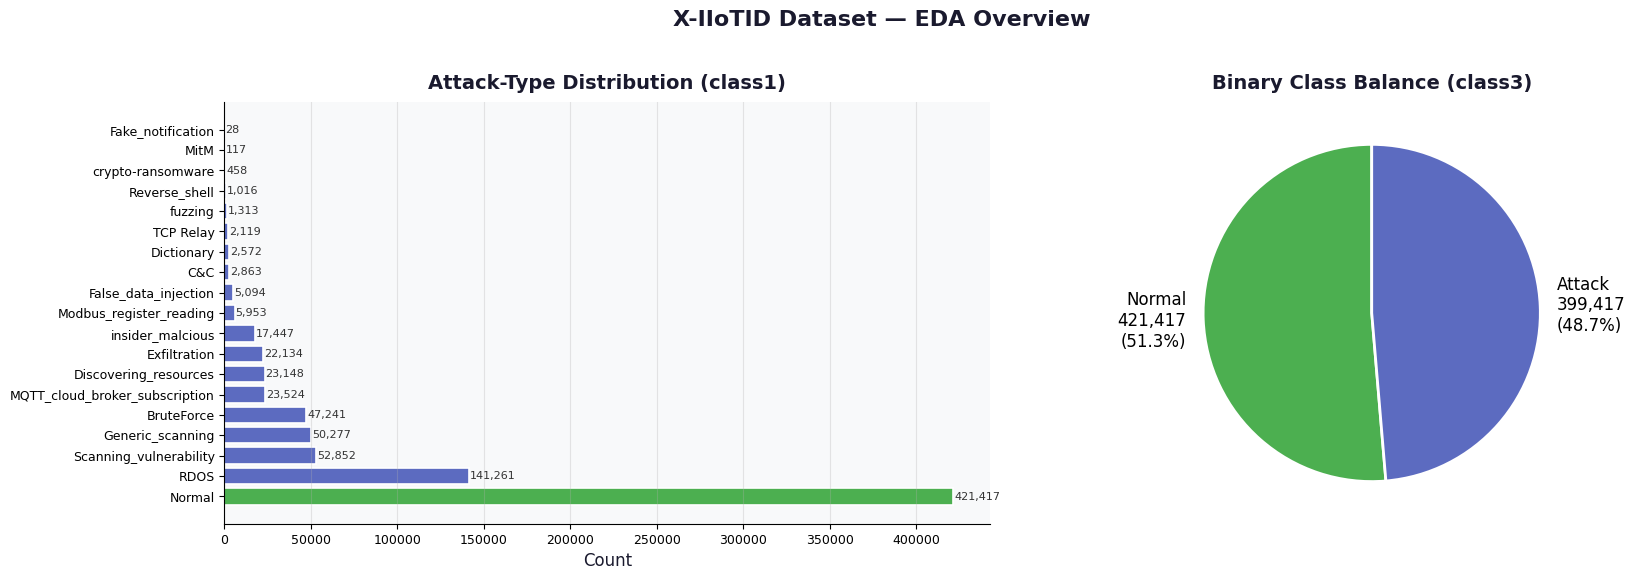

Saved: xiiot_eda.png


In [ ]:
#  CELL 6 — X-IIoTID: Load + EDA

CURRENT_DATASET = "X-IIoTID"
cfg = DATASETS[CURRENT_DATASET]

print(f"Dataset: {CURRENT_DATASET} ({cfg['country']})")
print("-" * 50)

df_xiiot = pd.read_csv(cfg["file"], low_memory=False)

print(f"Shape              : {df_xiiot.shape}")
print(f"Duplicate rows     : {df_xiiot.duplicated().sum():,}")

# Detailed attack-type distribution (class1 — 19 classes)
print(f"\nAttack-type distribution (class1):")
counts = df_xiiot["class1"].value_counts()
total  = len(df_xiiot)
for val, cnt in counts.items():
    print(f"  {val:<35}: {cnt:>8,} ({cnt/total*100:.1f}%)")

# Binary distribution (class3 — this is what we train on)
normal = (df_xiiot[cfg["label_col"]] == "Normal").sum()
attack = (df_xiiot[cfg["label_col"]] == "Attack").sum()
print(f"\nBinary distribution (class3):")
print(f"  Normal : {normal:,} ({normal/total*100:.1f}%)")
print(f"  Attack : {attack:,} ({attack/total*100:.1f}%)")

# EDA Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6), facecolor='white')
fig.suptitle('X-IIoTID Dataset — EDA Overview',
             fontsize=16, fontweight='bold', color='#1a1a2e')

ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
colors_bar = ['#4CAF50' if v == 'Normal' else '#5C6BC0' for v in counts.index]
bars = ax1.barh(list(counts.index), list(counts.values),
                color=colors_bar, edgecolor='white', linewidth=1.2)
ax1.set_title('Attack-Type Distribution (class1)', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)
ax1.set_xlabel('Count', fontsize=12, color='#1a1a2e')
ax1.tick_params(labelsize=9)
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for bar, val in zip(bars, counts.values):
    ax1.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=8, color='#333333')

ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
sizes      = [normal, attack]
pie_labels = [f'Normal\n{normal:,}\n({normal/total*100:.1f}%)',
              f'Attack\n{attack:,}\n({attack/total*100:.1f}%)']
colors_pie = ['#4CAF50', '#5C6BC0']
ax2.pie(sizes, labels=pie_labels, colors=colors_pie,
        startangle=90, textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Binary Class Balance (class3)', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)

plt.tight_layout(pad=2.0)
plt.savefig('xiiot_eda.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_eda.png")

In [ ]:
#  CELL 7 — X-IIoTID: Cleaning + Held-Out Test Split + Non-Overlapping Stratified Sampling

print(f"Preprocessing: {CURRENT_DATASET}")
print("-" * 50)

df_clean = df_xiiot.drop(columns=cfg["drop_cols"], errors="ignore")
df_clean = df_clean.replace('-', np.nan)

before = len(df_clean)
df_clean = df_clean.drop_duplicates()
print(f"Dropped {before - len(df_clean)} duplicate rows")

before = len(df_clean)
df_clean = df_clean[df_clean['Protocol'] != '?']
print(f"Dropped {before - len(df_clean)} rows with Protocol == '?'")

# anomaly_alert is a TRUE/FALSE string column -> map to 1/0
df_clean['anomaly_alert'] = df_clean['anomaly_alert'].map({'TRUE': 1, 'FALSE': 0})

# Nearly every stat/count column got read as string because of '-' placeholders
# mixed in (not just a handful of columns). Convert generically instead of
# hand-listing them: anything that isn't a known categorical/label column
# gets coerced to numeric.
categorical_cols = {'Protocol', 'Service', 'class1', cfg["label_col"]}
for col in df_clean.columns:
    if col in categorical_cols:
        continue
    if pd.api.types.is_bool_dtype(df_clean[col]):
        df_clean[col] = df_clean[col].astype(int)
    elif not pd.api.types.is_numeric_dtype(df_clean[col]):
        df_clean[col] = pd.to_numeric(df_clean[col], errors='coerce')

num_cols = df_clean.select_dtypes(include=[np.number]).columns
df_clean[num_cols] = df_clean[num_cols].fillna(df_clean[num_cols].median())

df_clean = pd.get_dummies(df_clean, columns=cfg["encode_cols"], drop_first=True)

# Keep class1 aside for the multiclass model (later cell), then finalize binary target
attack_type_full = df_clean['class1']
df_clean["attack"] = (df_clean[cfg["label_col"]] == "Attack").astype(int)
df_clean = df_clean.drop(columns=["class1", cfg["label_col"]])

X_xiiot = df_clean.drop(columns=["attack"])
y_xiiot = df_clean["attack"]

print(f"\nFeatures : {X_xiiot.shape[1]}")
print(f"Samples  : {X_xiiot.shape[0]:,}")
print(f"Normal (0): {(y_xiiot==0).sum():,} ({(y_xiiot==0).mean()*100:.1f}%)")
print(f"Attack (1): {(y_xiiot==1).sum():,} ({(y_xiiot==1).mean()*100:.1f}%)")

# ---- Held-out test set FIRST, from the ORIGINAL (untouched) distribution ----
# We train on balanced samples but evaluate on the real-world imbalance, so
# this split must happen BEFORE any balancing/sampling — otherwise leakage.
X_train_pool, X_test_xiiot, y_train_pool, y_test_xiiot = train_test_split(
    X_xiiot, y_xiiot, test_size=0.20, stratify=y_xiiot, random_state=42
)
print(f"\nHeld-out test set : {len(X_test_xiiot):,} (kept at ORIGINAL class ratio — for realistic evaluation)")
print(f"Train pool         : {len(X_train_pool):,}")

# ---- Stratified balanced sampling from the TRAIN POOL only ----
train_pool = X_train_pool.copy()
train_pool["attack"] = y_train_pool.values

normal_df = train_pool[train_pool["attack"] == 0]
attack_df = train_pool[train_pool["attack"] == 1]

n_per_class  = 75000
normal_sampled = normal_df.sample(n=min(n_per_class, len(normal_df)), random_state=42)
attack_sampled = attack_df.sample(n=min(n_per_class, len(attack_df)), random_state=42)
n_per_chunk    = min(len(normal_sampled), len(attack_sampled)) // 3

normal_sampled = normal_sampled.sample(frac=1, random_state=42).reset_index(drop=True)
attack_sampled = attack_sampled.sample(frac=1, random_state=42).reset_index(drop=True)

def _build_sample(n_chunk, a_chunk):
    merged = pd.concat([n_chunk, a_chunk]).sample(frac=1, random_state=42).reset_index(drop=True)
    y = merged.pop("attack")
    return merged, y

X_s1, y_s1 = _build_sample(normal_sampled.iloc[0:n_per_chunk],               attack_sampled.iloc[0:n_per_chunk])
X_s2, y_s2 = _build_sample(normal_sampled.iloc[n_per_chunk:2*n_per_chunk],   attack_sampled.iloc[n_per_chunk:2*n_per_chunk])
X_s3, y_s3 = _build_sample(normal_sampled.iloc[2*n_per_chunk:3*n_per_chunk], attack_sampled.iloc[2*n_per_chunk:3*n_per_chunk])

print(f"\nSample distribution check:")
ratios = []
for i, (Xs, ys) in enumerate([(X_s1, y_s1), (X_s2, y_s2), (X_s3, y_s3)], 1):
    ratios.append(ys.mean())
    print(f"  Sample {i} — Normal: {(ys==0).sum():,} | Attack: {(ys==1).sum():,} | Total: {len(ys):,}")

std_dev = float(np.std(ratios))
print(f"\nStability check — Std Dev of attack ratio across 3 samples: {std_dev:.6f}")
print("Conclusion: Sampling is STABLE — No bias detected." if std_dev < 0.001
      else "WARNING — variance above threshold, review sampling.")

Preprocessing: X-IIoTID
--------------------------------------------------
Dropped 11431 duplicate rows
Dropped 154 rows with Protocol == '?'

Features : 77
Samples  : 809,249
Normal (0): 416,324 (51.4%)
Attack (1): 392,925 (48.6%)

Held-out test set : 161,850 (kept at ORIGINAL class ratio — for realistic evaluation)
Train pool         : 647,399

Sample distribution check:
  Sample 1 — Normal: 25,000 | Attack: 25,000 | Total: 50,000
  Sample 2 — Normal: 25,000 | Attack: 25,000 | Total: 50,000
  Sample 3 — Normal: 25,000 | Attack: 25,000 | Total: 50,000

Stability check — Std Dev of attack ratio across 3 samples: 0.000000
Conclusion: Sampling is STABLE — No bias detected.


In [ ]:
#  CELL 8 — X-IIoTID: Train 12 Models (Sample 1)

print(f"Training 12 models — Sample 1...")
print("-" * 50)

scaler_s1     = StandardScaler()
X_train_s1_sc = scaler_s1.fit_transform(X_s1)
X_test_s1_sc  = scaler_s1.transform(X_test_xiiot)

models_s1  = get_models()
results_s1 = train_models(
    models_s1,
    X_s1, X_test_xiiot,
    y_s1, y_test_xiiot,
    X_train_s1_sc, X_test_s1_sc
)

best_name_s1, best_res_s1 = find_best_model(results_s1)
best_t_s1, best_f1_t_s1   = optimize_threshold(y_test_xiiot, best_res_s1["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s1.items():
    marker = " *" if name == best_name_s1 else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s1}")
print(f"F1-Score          : {best_res_s1['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s1['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s1:.2f}")

Training 12 models — Sample 1...
--------------------------------------------------
  Training Random Forest... done — F1: 0.9942 (39.6s)
  Training Gradient Boosting... done — F1: 0.9956 (229.4s)
  Training XGBoost... done — F1: 0.9958 (7.6s)
  Training SVM... done — F1: 0.9823 (546.3s)
  Training Voting Ensemble... done — F1: 0.9952 (108.5s)
  Training Stacking... done — F1: 0.9956 (1042.3s)
  Training LightGBM... done — F1: 0.9960 (20.2s)
  Training MLP Neural Net... done — F1: 0.9854 (121.4s)
  Training CatBoost... done — F1: 0.9955 (12.7s)
  Training Extra Trees... done — F1: 0.9831 (16.5s)
  Training AdaBoost... done — F1: 0.9366 (71.7s)
  Training Naive Bayes... done — F1: 0.8387 (0.5s)

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9943   0.9942   0.9997
Gradient Boosting    Base          0.9957   0.9956   0.9997
XGBoost              Base          0.

In [ ]:
#  CELL 9 — X-IIoTID: Train 12 Models (Sample 2)

print(f"Training 12 models — Sample 2...")
print("-" * 50)

scaler_s2     = StandardScaler()
X_train_s2_sc = scaler_s2.fit_transform(X_s2)
X_test_s2_sc  = scaler_s2.transform(X_test_xiiot)

models_s2  = get_models()
results_s2 = train_models(
    models_s2,
    X_s2, X_test_xiiot,
    y_s2, y_test_xiiot,
    X_train_s2_sc, X_test_s2_sc
)

best_name_s2, best_res_s2 = find_best_model(results_s2)
best_t_s2, best_f1_t_s2   = optimize_threshold(y_test_xiiot, best_res_s2["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s2.items():
    marker = " *" if name == best_name_s2 else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s2}")
print(f"F1-Score          : {best_res_s2['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s2['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s2:.2f}")

Training 12 models — Sample 2...
--------------------------------------------------
  Training Random Forest... done — F1: 0.9938 (40.7s)
  Training Gradient Boosting... done — F1: 0.9953 (234.9s)
  Training XGBoost... done — F1: 0.9958 (9.6s)
  Training SVM... done — F1: 0.9823 (503.7s)
  Training Voting Ensemble... done — F1: 0.9951 (107.3s)
  Training Stacking... done — F1: 0.9956 (1039.3s)
  Training LightGBM... done — F1: 0.9960 (18.6s)
  Training MLP Neural Net... done — F1: 0.9848 (85.1s)
  Training CatBoost... done — F1: 0.9953 (13.4s)
  Training Extra Trees... done — F1: 0.9830 (16.0s)
  Training AdaBoost... done — F1: 0.9364 (72.4s)
  Training Naive Bayes... done — F1: 0.7082 (0.6s)

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9940   0.9938   0.9996
Gradient Boosting    Base          0.9955   0.9953   0.9996
XGBoost              Base          0.9

In [ ]:
#  CELL 10 — X-IIoTID: Train 12 Models (Sample 3)

print(f"Training 12 models — Sample 3...")
print("-" * 50)

scaler_s3     = StandardScaler()
X_train_s3_sc = scaler_s3.fit_transform(X_s3)
X_test_s3_sc  = scaler_s3.transform(X_test_xiiot)

models_s3  = get_models()
results_s3 = train_models(
    models_s3,
    X_s3, X_test_xiiot,
    y_s3, y_test_xiiot,
    X_train_s3_sc, X_test_s3_sc
)

best_name_s3, best_res_s3 = find_best_model(results_s3)
best_t_s3, best_f1_t_s3   = optimize_threshold(y_test_xiiot, best_res_s3["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s3.items():
    marker = " *" if name == best_name_s3 else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s3}")
print(f"F1-Score          : {best_res_s3['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s3['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s3:.2f}")

Training 12 models — Sample 3...
--------------------------------------------------
  Training Random Forest... done — F1: 0.9940 (38.1s)
  Training Gradient Boosting... done — F1: 0.9956 (229.4s)
  Training XGBoost... done — F1: 0.9960 (7.5s)
  Training SVM... done — F1: 0.9823 (494.8s)
  Training Voting Ensemble... done — F1: 0.9954 (105.2s)
  Training Stacking... done — F1: 0.9960 (1042.7s)
  Training LightGBM... done — F1: 0.9963 (19.0s)
  Training MLP Neural Net... done — F1: 0.9855 (66.9s)
  Training CatBoost... done — F1: 0.9953 (13.3s)
  Training Extra Trees... done — F1: 0.9835 (17.2s)
  Training AdaBoost... done — F1: 0.9365 (73.2s)
  Training Naive Bayes... done — F1: 0.8280 (0.6s)

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9941   0.9940   0.9997
Gradient Boosting    Base          0.9958   0.9956   0.9998
XGBoost              Base          0.9

#  Stability Check 11— Final Decision (X-IIoTID)

model_names = list(results_s1.keys())

print(f"{'Model':<20} {'S1 F1':>8} {'S2 F1':>8} {'S3 F1':>8} {'Avg F1':>9} {'Std Dev':>9}")
print("-" * 70)

avg_f1_dict = {}
for name in model_names:
    f1_s1 = results_s1[name]["f1"]
    f1_s2 = results_s2[name]["f1"]
    f1_s3 = results_s3[name]["f1"]
    avg   = np.mean([f1_s1, f1_s2, f1_s3])
    std   = np.std([f1_s1, f1_s2, f1_s3])
    avg_f1_dict[name] = {"avg": avg, "std": std}

best_avg_model = max(avg_f1_dict, key=lambda x: avg_f1_dict[x]["avg"])
for name in model_names:
    f1_s1 = results_s1[name]["f1"]
    f1_s2 = results_s2[name]["f1"]
    f1_s3 = results_s3[name]["f1"]
    avg   = avg_f1_dict[name]["avg"]
    std   = avg_f1_dict[name]["std"]
    marker = " *" if name == best_avg_model else ""
    print(f"{name:<20} {f1_s1:>8.4f} {f1_s2:>8.4f} {f1_s3:>8.4f} "
          f"{avg:>9.4f} {std:>9.4f}")

print(f"\nFinal Best Model  : {best_avg_model}")
print(f"Average F1        : {avg_f1_dict[best_avg_model]['avg']:.4f}")
print(f"Std Dev           : {avg_f1_dict[best_avg_model]['std']:.4f}")
print("\nConclusion: Sampling is STABLE — No bias detected."
      if avg_f1_dict[best_avg_model]['std'] < 0.01
      else "\nWARNING: F1 variance across samples is high — review sampling.")

In [ ]:
########################################################################
#  X-IIoTID: Merge 3 Samples + Final Train (150k)")
# WITH this checkpoint-safe version. Same output variables as before
# (X_train_xiiot, X_test_xiiot_sc, results_xiiot, best_name_xiiot,
#  best_res_xiiot, best_t_xiiot) so every later cell works unchanged.
########################################################################

import pickle, os, time
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

print(f"Merging 3 Non-Overlapping Samples — {CURRENT_DATASET}")
print("-" * 50)

X_merged = pd.concat([X_s1, X_s2, X_s3], axis=0).reset_index(drop=True)
y_merged = pd.concat([y_s1, y_s2, y_s3], axis=0).reset_index(drop=True)

print(f"Merged dataset:")
print(f"  Total   : {len(X_merged):,}")
print(f"  Normal  : {(y_merged==0).sum():,} ({(y_merged==0).mean()*100:.1f}%)")
print(f"  Attack  : {(y_merged==1).sum():,} ({(y_merged==1).mean()*100:.1f}%)")

# Train on the merged 150k, evaluate on the SAME held-out original-distribution
# test set used for Samples 1/2/3 above — comparable and realistic.
X_train_xiiot, y_train_xiiot = X_merged, y_merged

scaler_xiiot     = StandardScaler()
X_train_xiiot_sc = scaler_xiiot.fit_transform(X_train_xiiot)
X_test_xiiot_sc  = scaler_xiiot.transform(X_test_xiiot)

print(f"\nTrain (merged 150k) : {len(X_train_xiiot):,}")
print(f"Test (original dist): {len(X_test_xiiot):,}")

print(f"\nTraining 12 models on merged 150k dataset (checkpoint-safe)...")
print("-" * 50)

CKPT_DIR = "/content/drive/MyDrive/datasets/checkpoints_xiiot_final"
os.makedirs(CKPT_DIR, exist_ok=True)

models_xiiot  = get_models()
results_xiiot = {}

for name, config in models_xiiot.items():
    ckpt_path = f"{CKPT_DIR}/{name.replace(' ', '_')}.pkl"

    if os.path.exists(ckpt_path):
        print(f"  [SKIP-LOADED] {name} ...", end=" ")
        with open(ckpt_path, "rb") as f:
            saved = pickle.load(f)
        results_xiiot[name] = saved
        config["model"] = saved["model"]  # keep models_xiiot in sync for later cells
        print(f"F1: {saved['f1']:.4f}")
        continue

    print(f"  Training {name}...", end=" ")
    start  = time.time()
    Xtr    = X_train_xiiot_sc if config["needs_scale"] else X_train_xiiot
    Xte    = X_test_xiiot_sc  if config["needs_scale"] else X_test_xiiot
    config["model"].fit(Xtr, y_train_xiiot)
    y_pred = config["model"].predict(Xte)
    y_prob = config["model"].predict_proba(Xte)[:, 1]
    elapsed = time.time() - start

    entry = {
        "model"    : config["model"],
        "category" : config["category"],
        "y_pred"   : y_pred,
        "y_prob"   : y_prob,
        "accuracy" : accuracy_score(y_test_xiiot, y_pred),
        "f1"       : f1_score(y_test_xiiot, y_pred),
        "precision": precision_score(y_test_xiiot, y_pred),
        "recall"   : recall_score(y_test_xiiot, y_pred),
        "auc"      : roc_auc_score(y_test_xiiot, y_prob),
        "time"     : elapsed,
    }
    results_xiiot[name] = entry

    with open(ckpt_path, "wb") as f:
        pickle.dump(entry, f)
    print(f"done — F1: {entry['f1']:.4f} ({elapsed:.1f}s) — checkpoint saved")

best_name_xiiot, best_res_xiiot = find_best_model(results_xiiot)
best_t_xiiot, best_f1_t_xiiot   = optimize_threshold(y_test_xiiot, best_res_xiiot["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_xiiot.items():
    marker = " *" if name == best_name_xiiot else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_xiiot}")
print(f"F1-Score          : {best_res_xiiot['f1']:.4f}")
print(f"AUC-ROC           : {best_res_xiiot['auc']:.4f}")
print(f"Optimal Threshold : {best_t_xiiot:.2f}")
print(f"F1 at Threshold   : {best_f1_t_xiiot:.4f}")

Merging 3 Non-Overlapping Samples — X-IIoTID
--------------------------------------------------
Merged dataset:
  Total   : 150,000
  Normal  : 75,000 (50.0%)
  Attack  : 75,000 (50.0%)

Train (merged 150k) : 150,000
Test (original dist): 161,850

Training 12 models on merged 150k dataset (checkpoint-safe)...
--------------------------------------------------
  [SKIP-LOADED] Random Forest ... F1: 0.9946
  [SKIP-LOADED] Gradient Boosting ... F1: 0.9961
  [SKIP-LOADED] XGBoost ... F1: 0.9968
  [SKIP-LOADED] SVM ... F1: 0.9836
  [SKIP-LOADED] Voting Ensemble ... F1: 0.9963
  [SKIP-LOADED] Stacking ... F1: 0.9969
  [SKIP-LOADED] LightGBM ... F1: 0.9972
  [SKIP-LOADED] MLP Neural Net ... F1: 0.9866
  [SKIP-LOADED] CatBoost ... F1: 0.9959
  [SKIP-LOADED] Extra Trees ... F1: 0.9833
  [SKIP-LOADED] AdaBoost ... F1: 0.9366
  [SKIP-LOADED] Naive Bayes ... F1: 0.8278

All Models Summary:
Model                Category    Accuracy       F1      AUC
--------------------------------------------------

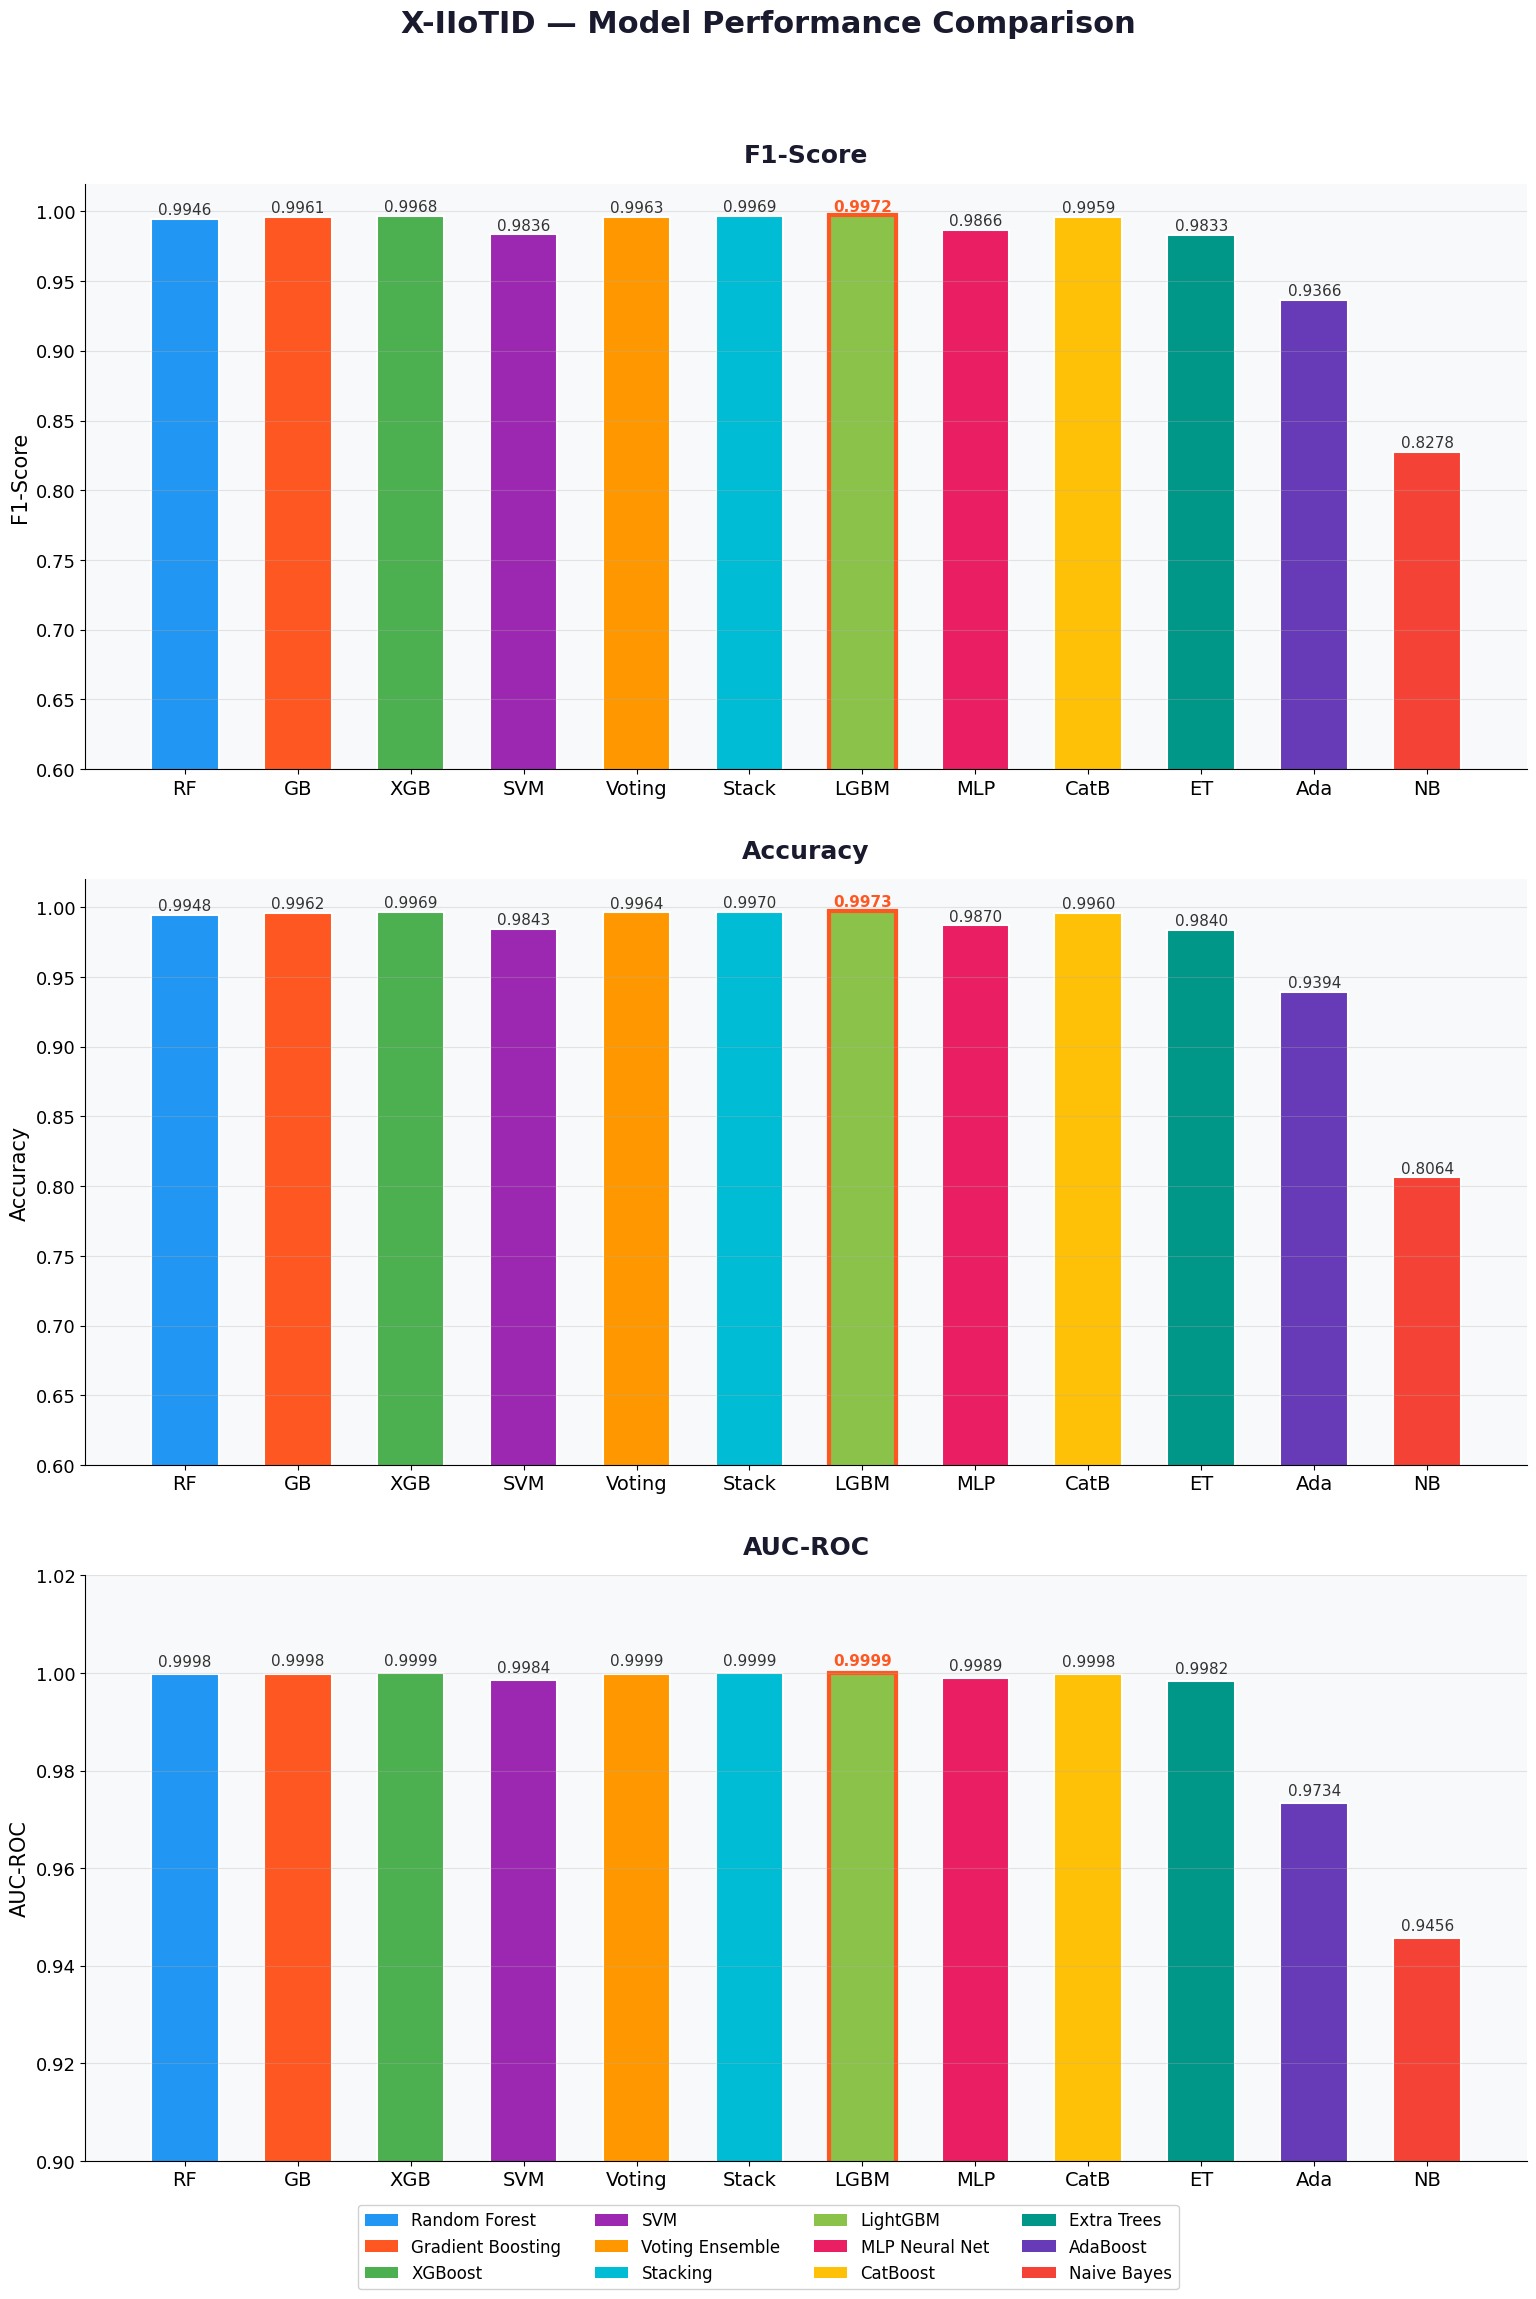

Saved: xiiot_model_comparison.png


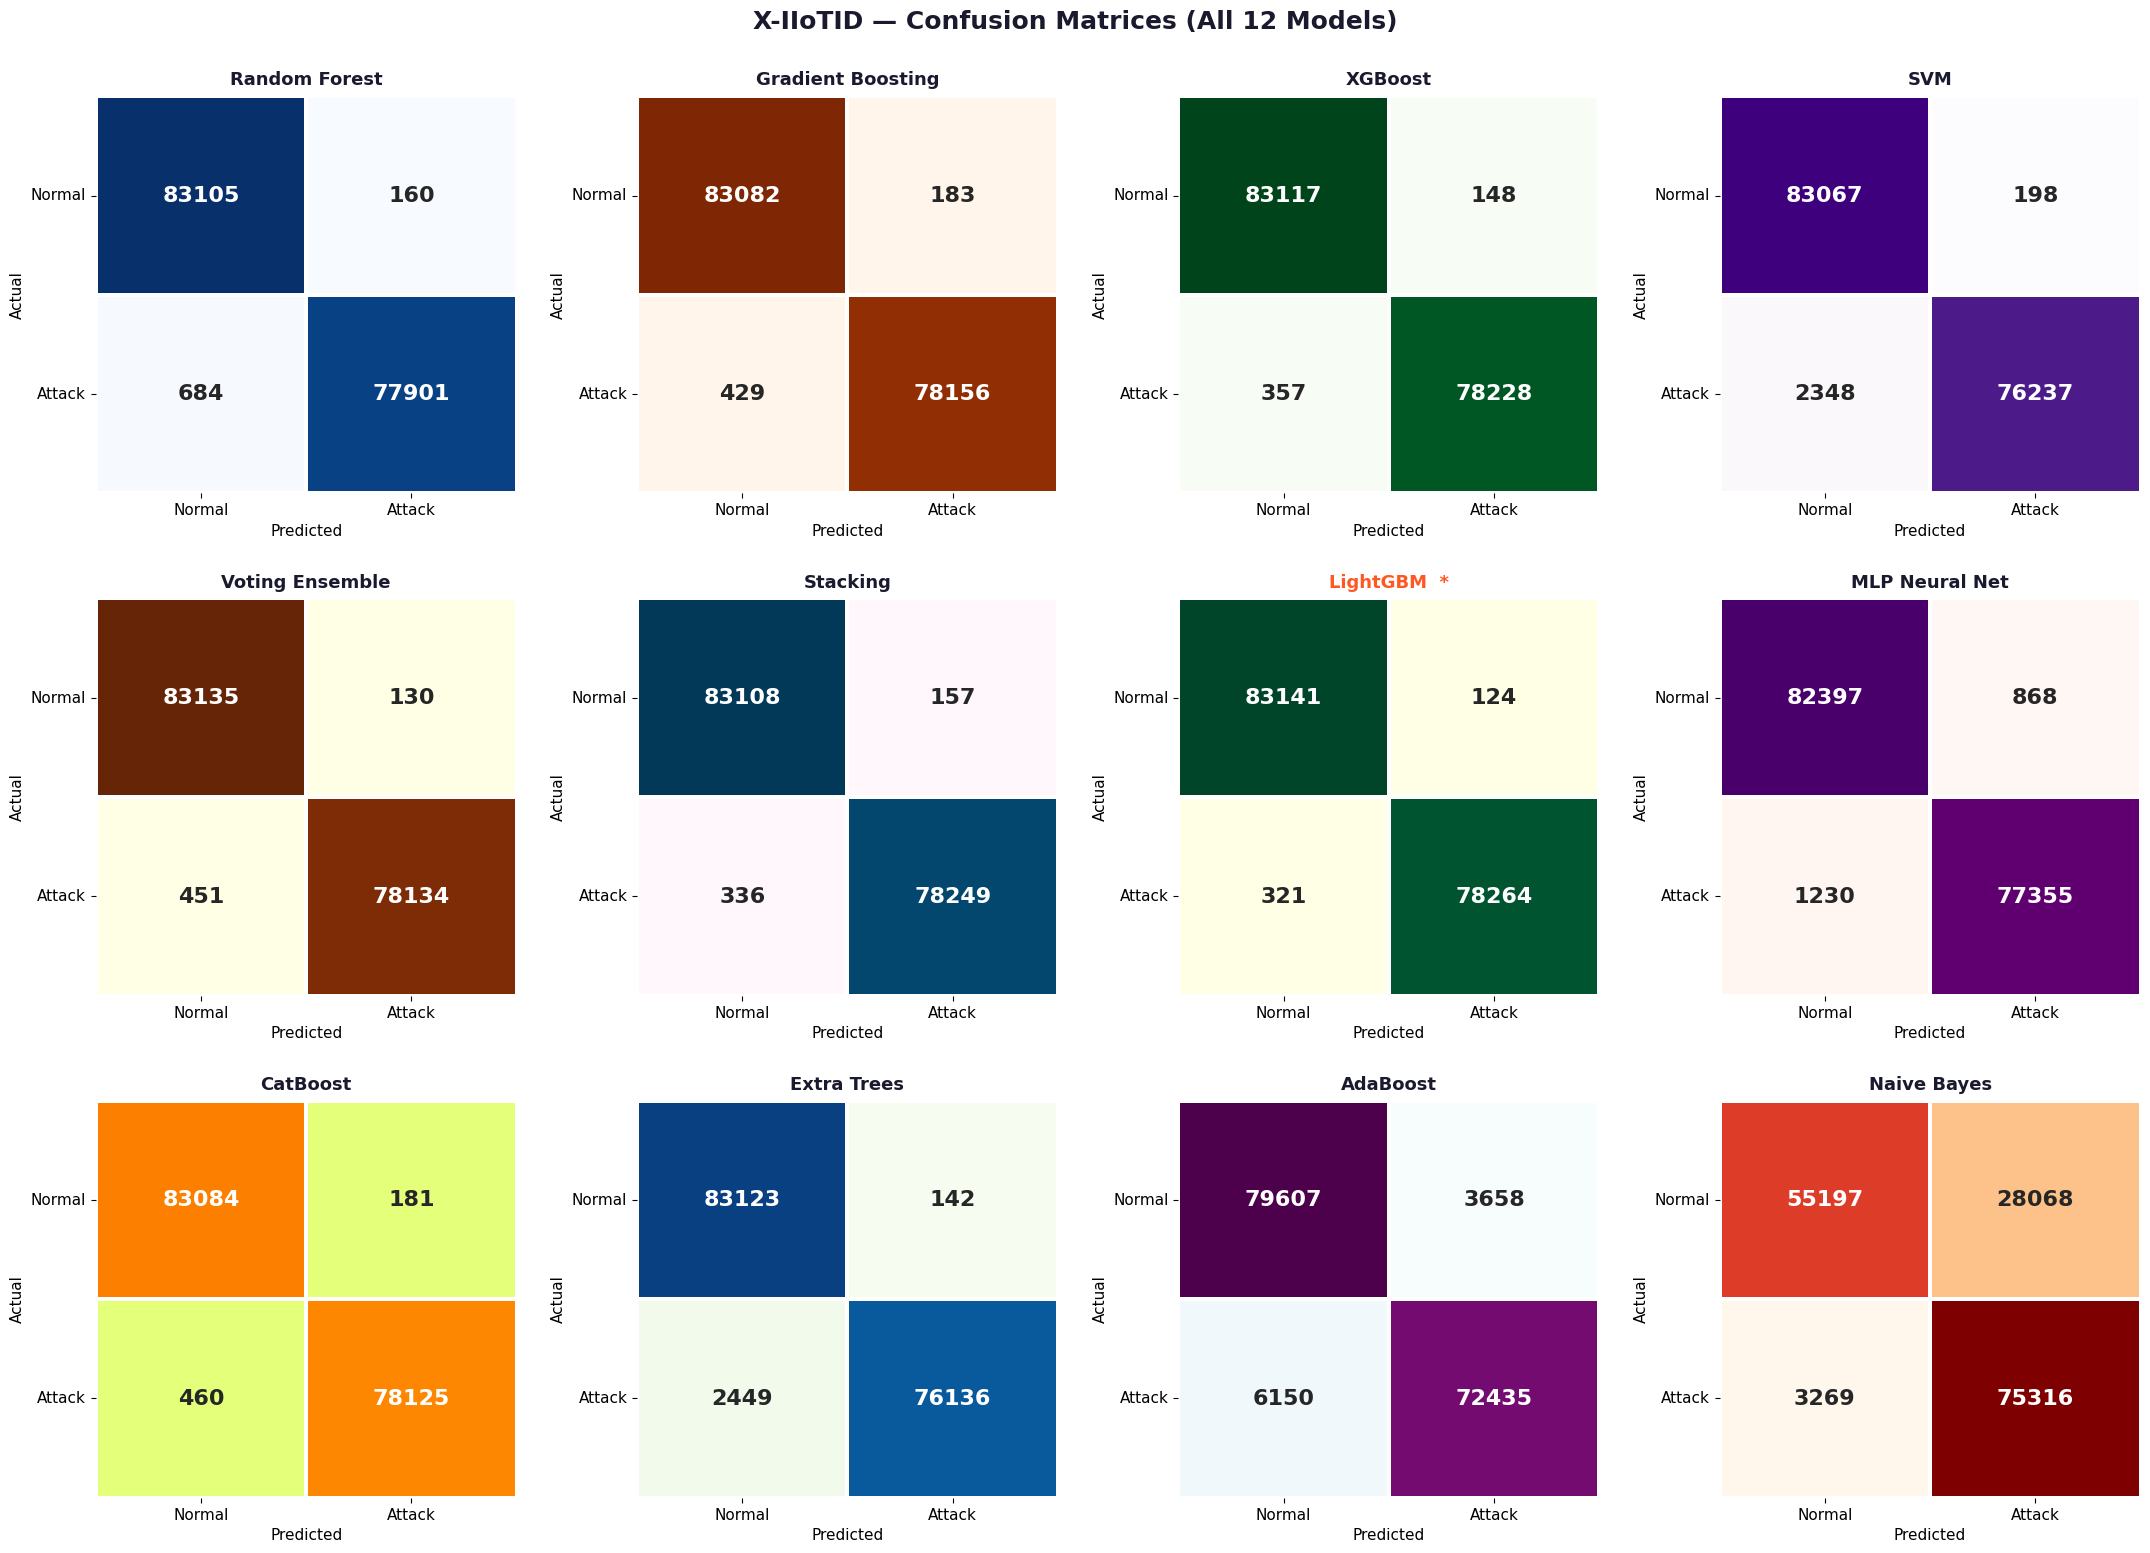

Saved: xiiot_confusion_matrices.png


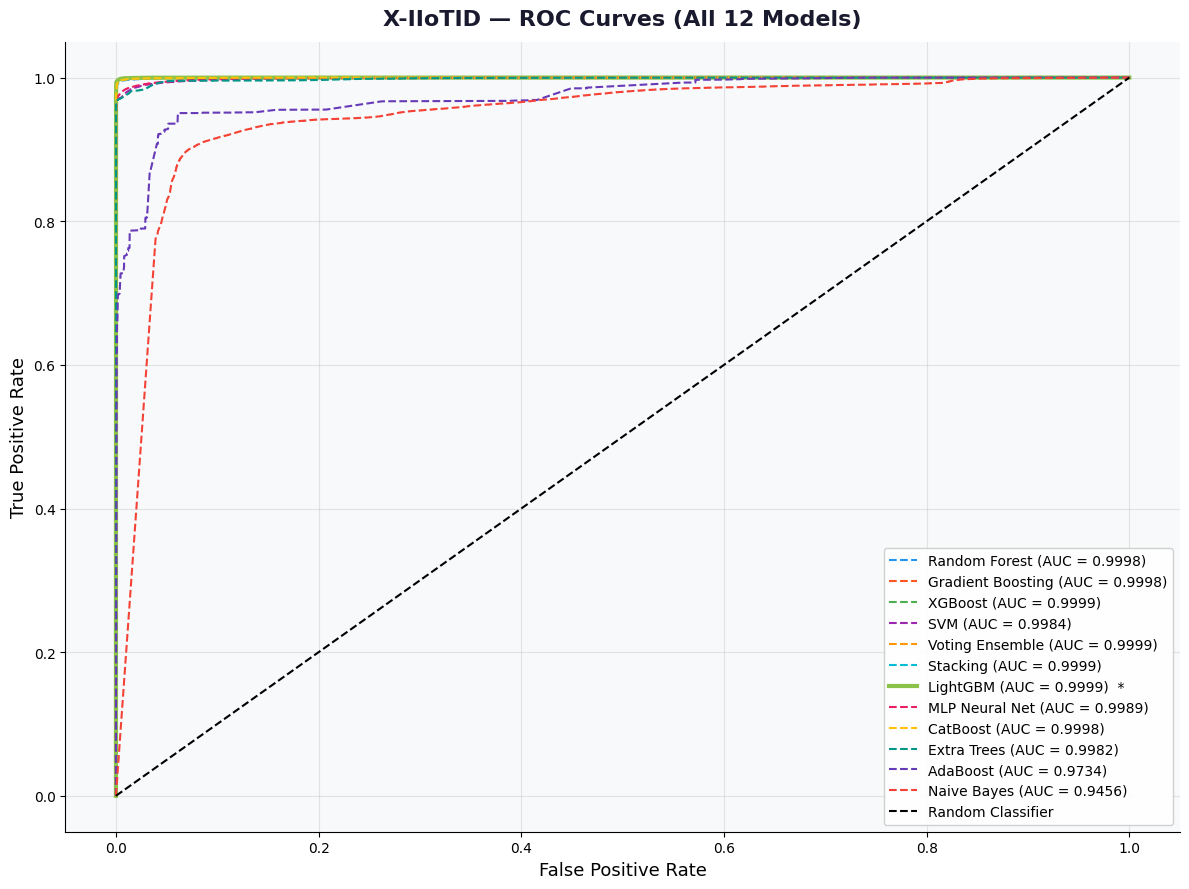

Saved: xiiot_roc_curves.png


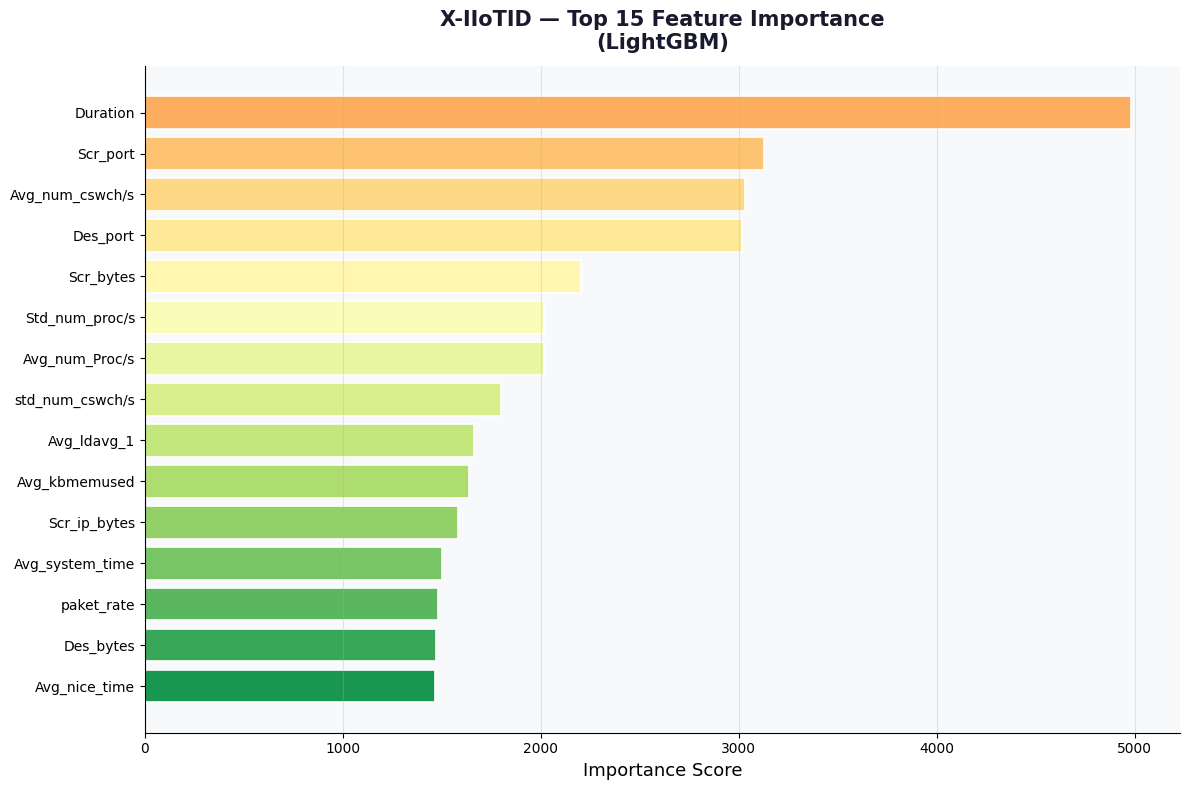

Saved: xiiot_feature_importance.png


In [ ]:
#  CELL 12 — X-IIoTID: Results Visualizations

from sklearn.metrics import roc_curve, auc as sk_auc
from matplotlib.patches import Patch

model_names = list(results_xiiot.keys())
f1_scores   = [results_xiiot[m]["f1"]       for m in model_names]
acc_scores  = [results_xiiot[m]["accuracy"] for m in model_names]
auc_scores  = [results_xiiot[m]["auc"]      for m in model_names]
best_idx    = model_names.index(best_name_xiiot)

model_colors = {
    "Random Forest"    : "#2196F3",
    "Gradient Boosting": "#FF5722",
    "XGBoost"          : "#4CAF50",
    "SVM"              : "#9C27B0",
    "Voting Ensemble"  : "#FF9800",
    "Stacking"         : "#00BCD4",
    "LightGBM"         : "#8BC34A",
    "MLP Neural Net"   : "#E91E63",
    "CatBoost"         : "#FFC107",
    "Extra Trees"      : "#009688",
    "AdaBoost"         : "#673AB7",
    "Naive Bayes"      : "#F44336",
}
bar_colors  = [model_colors[m] for m in model_names]
short_names = ["RF", "GB", "XGB", "SVM", "Voting", "Stack",
               "LGBM", "MLP", "CatB", "ET", "Ada", "NB"]

# Figure 1: F1 + Accuracy + AUC
fig, axes = plt.subplots(3, 1, figsize=(16, 22), facecolor='white')
fig.suptitle('X-IIoTID — Model Performance Comparison',
             fontsize=22, fontweight='bold', color='#1a1a2e', y=1.01)

metrics = [
    (f1_scores,  'F1-Score',  (0.60, 1.02)),
    (acc_scores, 'Accuracy',  (0.60, 1.02)),
    (auc_scores, 'AUC-ROC',   (0.90, 1.02)),
]

for ax, (scores, label, ylim) in zip(axes, metrics):
    ax.set_facecolor('#F8F9FA')
    bars = ax.bar(short_names, scores,
                  color=bar_colors, edgecolor='white',
                  linewidth=1.5, width=0.6)
    bars[best_idx].set_edgecolor('#FF5722')
    bars[best_idx].set_linewidth(3)
    ax.set_title(label, fontsize=18, fontweight='bold',
                 color='#1a1a2e', pad=15)
    ax.set_ylabel(label, fontsize=15)
    ax.set_ylim(ylim)
    ax.tick_params(axis='x', labelsize=14)
    ax.tick_params(axis='y', labelsize=13)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for bar, val, name in zip(bars, scores, model_names):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=11,
                color='#FF5722' if name == best_name_xiiot else '#333333',
                fontweight='bold' if name == best_name_xiiot else 'normal')

legend = [Patch(facecolor=model_colors[m], label=m) for m in model_names]
fig.legend(handles=legend, loc='lower center', ncol=4,
           fontsize=12, framealpha=0.9, bbox_to_anchor=(0.5, -0.03))

plt.tight_layout(pad=3.0)
plt.savefig('xiiot_model_comparison.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_model_comparison.png")

# Figure 2: Confusion Matrices
cmaps = ['Blues', 'Oranges', 'Greens', 'Purples',
         'YlOrBr', 'PuBu', 'YlGn', 'RdPu',
         'Wistia', 'GnBu', 'BuPu', 'OrRd']

fig, axes = plt.subplots(3, 4, figsize=(22, 16), facecolor='white')
fig.suptitle('X-IIoTID — Confusion Matrices (All 12 Models)',
             fontsize=18, fontweight='bold', color='#1a1a2e')

for idx, (name, res) in enumerate(results_xiiot.items()):
    ax  = axes.flatten()[idx]
    cm  = confusion_matrix(y_test_xiiot, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt='d', ax=ax,
                cmap=cmaps[idx],
                annot_kws={"size": 16, "weight": "bold"},
                linewidths=1.5, linecolor='white', cbar=False)
    title_color = '#FF5722' if name == best_name_xiiot else '#1a1a2e'
    ax.set_title(f'{name}{"  *" if name == best_name_xiiot else ""}',
                 fontsize=13, fontweight='bold',
                 color=title_color, pad=8)
    ax.set_xlabel('Predicted', fontsize=11)
    ax.set_ylabel('Actual', fontsize=11)
    ax.set_xticklabels(['Normal', 'Attack'], fontsize=11)
    ax.set_yticklabels(['Normal', 'Attack'], fontsize=11, rotation=0)

plt.tight_layout(pad=2.5)
plt.savefig('xiiot_confusion_matrices.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_confusion_matrices.png")

# Figure 3: ROC Curves
fig, ax = plt.subplots(figsize=(12, 9), facecolor='white')
ax.set_facecolor('#F8F9FA')

for name, res in results_xiiot.items():
    fpr, tpr, _ = roc_curve(y_test_xiiot, res["y_prob"])
    roc_auc     = sk_auc(fpr, tpr)
    lw = 3.0 if name == best_name_xiiot else 1.5
    ls = '-'  if name == best_name_xiiot else '--'
    ax.plot(fpr, tpr, color=model_colors[name], lw=lw, linestyle=ls,
            label=f'{name} (AUC = {roc_auc:.4f})'
                  f'{"  *" if name == best_name_xiiot else ""}')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=13)
ax.set_ylabel('True Positive Rate', fontsize=13)
ax.set_title('X-IIoTID — ROC Curves (All 12 Models)',
             fontsize=16, fontweight='bold', color='#1a1a2e', pad=12)
ax.legend(loc='lower right', fontsize=10, framealpha=0.9)
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('xiiot_roc_curves.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_roc_curves.png")

# Figure 4: Feature Importance
feat_names = list(X_xiiot.columns)
best_model_obj = best_res_xiiot["model"]

if hasattr(best_model_obj, "final_estimator_"):
    # Stacking -> importance from the meta-learner's coefficients
    importances = np.abs(best_model_obj.final_estimator_.coef_[0])
elif hasattr(best_model_obj, "feature_importances_"):
    # Tree-based models (LightGBM, XGBoost, RF, CatBoost, Extra Trees, AdaBoost, GB)
    importances = best_model_obj.feature_importances_
elif hasattr(best_model_obj, "estimators_"):
    # Voting ensemble -> importance from its first sub-estimator
    importances = best_model_obj.estimators_[0].feature_importances_
elif hasattr(best_model_obj, "coef_"):
    # Linear models (Logistic Regression etc.)
    importances = np.abs(best_model_obj.coef_[0])
else:
    raise AttributeError(f"Don't know how to extract feature importance from {type(best_model_obj)}")

indices   = np.argsort(importances)[::-1][:15]
colors_fi = plt.cm.RdYlGn(np.linspace(0.3, 0.9, 15))[::-1]

fig, ax = plt.subplots(figsize=(12, 8), facecolor='white')
ax.set_facecolor('#F8F9FA')
ax.barh([feat_names[i] for i in indices[::-1]],
        importances[indices[::-1]],
        color=colors_fi, edgecolor='white', linewidth=1.2)
ax.set_title(f'X-IIoTID — Top 15 Feature Importance\n({best_name_xiiot})',
             fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Importance Score', fontsize=13)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('xiiot_feature_importance.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_feature_importance.png")

Adaptive Risk Engine — X-IIoTID
--------------------------------------------------
Total flows    : 161,850
LOW  Risk      : 83,350  (51.5%)  -> AES-256
MEDIUM Risk    : 25  (0.0%)  -> AES-256 + Monitor
HIGH Risk      : 78,475  (48.5%)  -> BB84 QKD
Overhead Saved : 51.5% vs naive full-QKD

BB84 QKD Simulation — X-IIoTID
--------------------------------------------------
Clean Channel        | Eve: 0.00 | QBER: 0.0000 ± 0.0000 | Secure: 100.0%
Low Eavesdrop        | Eve: 0.10 | QBER: 0.0236 ± 0.0130 | Secure: 100.0%
High Eavesdrop       | Eve: 0.75 | QBER: 0.1872 ± 0.0395 | Secure: 1.0%


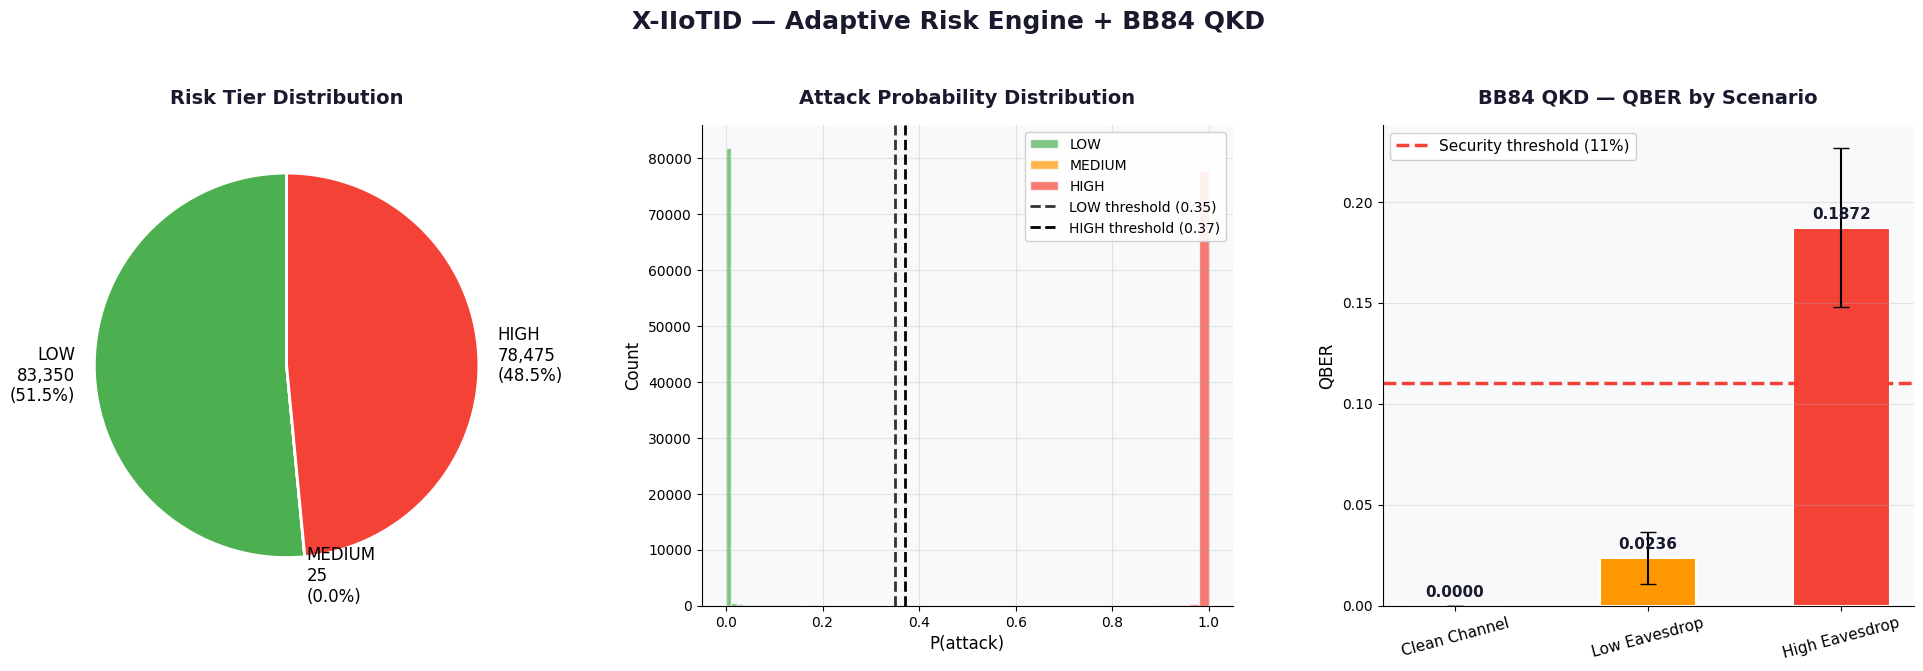

Saved: xiiot_risk_qkd.png


In [ ]:
#  CELL 13 — X-IIoTID: Adaptive Risk Engine + BB84 QKD

print(f"Adaptive Risk Engine — {CURRENT_DATASET}")
print("-" * 50)

risk_probs = best_res_xiiot["y_prob"]

LOW_THRESHOLD  = 0.35
HIGH_THRESHOLD = best_t_xiiot

risk_tiers = []
for p in risk_probs:
    if p < LOW_THRESHOLD:
        risk_tiers.append("LOW")
    elif p < HIGH_THRESHOLD:
        risk_tiers.append("MEDIUM")
    else:
        risk_tiers.append("HIGH")

risk_df = pd.DataFrame({
    "attack_prob": risk_probs,
    "risk_tier"  : risk_tiers,
    "true_label" : y_test_xiiot
})

n_total  = len(risk_df)
n_low    = (risk_df["risk_tier"] == "LOW").sum()
n_medium = (risk_df["risk_tier"] == "MEDIUM").sum()
n_high   = (risk_df["risk_tier"] == "HIGH").sum()
qkd_pct  = n_high / n_total * 100

print(f"Total flows    : {n_total:,}")
print(f"LOW  Risk      : {n_low:,}  ({n_low/n_total*100:.1f}%)  -> AES-256")
print(f"MEDIUM Risk    : {n_medium:,}  ({n_medium/n_total*100:.1f}%)  -> AES-256 + Monitor")
print(f"HIGH Risk      : {n_high:,}  ({n_high/n_total*100:.1f}%)  -> BB84 QKD")
print(f"Overhead Saved : {100 - qkd_pct:.1f}% vs naive full-QKD")

# BB84 QKD Simulation
print(f"\nBB84 QKD Simulation — {CURRENT_DATASET}")
print("-" * 50)

qkd_scenarios = [
    ("Clean Channel",  0.00),
    ("Low Eavesdrop",  0.10),
    ("High Eavesdrop", 0.75),
]

qkd_results_xiiot = {}
for scenario, eve_prob in qkd_scenarios:
    sessions = [BB84Simulation(256, eve_prob).run() for _ in range(100)]
    qkd_results_xiiot[scenario] = {
        "eve_prob"  : eve_prob,
        "qber_mean" : float(np.mean([s["qber"]    for s in sessions])),
        "qber_std"  : float(np.std([s["qber"]     for s in sessions])),
        "pct_secure": float(np.mean([s["secure"]  for s in sessions]) * 100),
    }
    r = qkd_results_xiiot[scenario]
    print(f"{scenario:<20} | Eve: {eve_prob:.2f} | "
          f"QBER: {r['qber_mean']:.4f} ± {r['qber_std']:.4f} | "
          f"Secure: {r['pct_secure']:.1f}%")

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
fig.suptitle(f'X-IIoTID — Adaptive Risk Engine + BB84 QKD',
             fontsize=18, fontweight='bold', color='#1a1a2e')

# Plot 1 — Risk Tier Pie
ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
sizes  = [n_low, n_medium, n_high]
labels = [f'LOW\n{n_low:,}\n({n_low/n_total*100:.1f}%)',
          f'MEDIUM\n{n_medium:,}\n({n_medium/n_total*100:.1f}%)',
          f'HIGH\n{n_high:,}\n({n_high/n_total*100:.1f}%)']
colors = ['#4CAF50', '#FF9800', '#F44336']
ax1.pie(sizes, labels=labels, colors=colors,
        startangle=90, textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax1.set_title('Risk Tier Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)

# Plot 2 — Attack Probability Distribution
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
ax2.hist(risk_df[risk_df["risk_tier"]=="LOW"]["attack_prob"],
         bins=30, alpha=0.7, color='#4CAF50', label='LOW', edgecolor='white')
ax2.hist(risk_df[risk_df["risk_tier"]=="MEDIUM"]["attack_prob"],
         bins=30, alpha=0.7, color='#FF9800', label='MEDIUM', edgecolor='white')
ax2.hist(risk_df[risk_df["risk_tier"]=="HIGH"]["attack_prob"],
         bins=30, alpha=0.7, color='#F44336', label='HIGH', edgecolor='white')
ax2.axvline(LOW_THRESHOLD,  color='#333333', linestyle='--',
            lw=2, label=f'LOW threshold ({LOW_THRESHOLD})')
ax2.axvline(HIGH_THRESHOLD, color='#000000', linestyle='--',
            lw=2, label=f'HIGH threshold ({HIGH_THRESHOLD:.2f})')
ax2.set_title('Attack Probability Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)
ax2.set_xlabel('P(attack)', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.legend(fontsize=10, framealpha=0.9)
ax2.grid(alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Plot 3 — QBER by Scenario
ax3 = axes[2]
ax3.set_facecolor('#F8F9FA')
scenario_names = list(qkd_results_xiiot.keys())
qber_means     = [qkd_results_xiiot[s]["qber_mean"] for s in scenario_names]
qber_stds      = [qkd_results_xiiot[s]["qber_std"]  for s in scenario_names]
bar_cols       = ['#4CAF50', '#FF9800', '#F44336']
bars = ax3.bar(scenario_names, qber_means, color=bar_cols,
               yerr=qber_stds, capsize=6,
               edgecolor='white', linewidth=1.5, width=0.5)
ax3.axhline(0.11, color='#F44336', linestyle='--',
            lw=2.5, label='Security threshold (11%)')
ax3.set_title('BB84 QKD — QBER by Scenario', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)
ax3.set_ylabel('QBER', fontsize=12)
ax3.tick_params(axis='x', labelsize=11, rotation=15)
ax3.legend(fontsize=11, framealpha=0.9)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
for bar, val in zip(bars, qber_means):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 0.003,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='#1a1a2e')

plt.tight_layout(pad=2.5)
plt.savefig('xiiot_risk_qkd.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_risk_qkd.png")

SHAP Analysis — X-IIoTID — LightGBM
--------------------------------------------------
SHAP values shape: (500, 77)
Top 10 Features by SHAP value:
   1. Avg_num_cswch/s                     1.9517
   2. read_write_physical.process         1.7092
   3. Des_port                            1.6116
   4. Duration                            1.2311
   5. is_with_payload                     1.0963
   6. Conn_state                          0.4797
   7. Des_ip_bytes                        0.4354
   8. is_syn_only                         0.4137
   9. total_bytes                         0.4055
  10. Service_dns                         0.3432


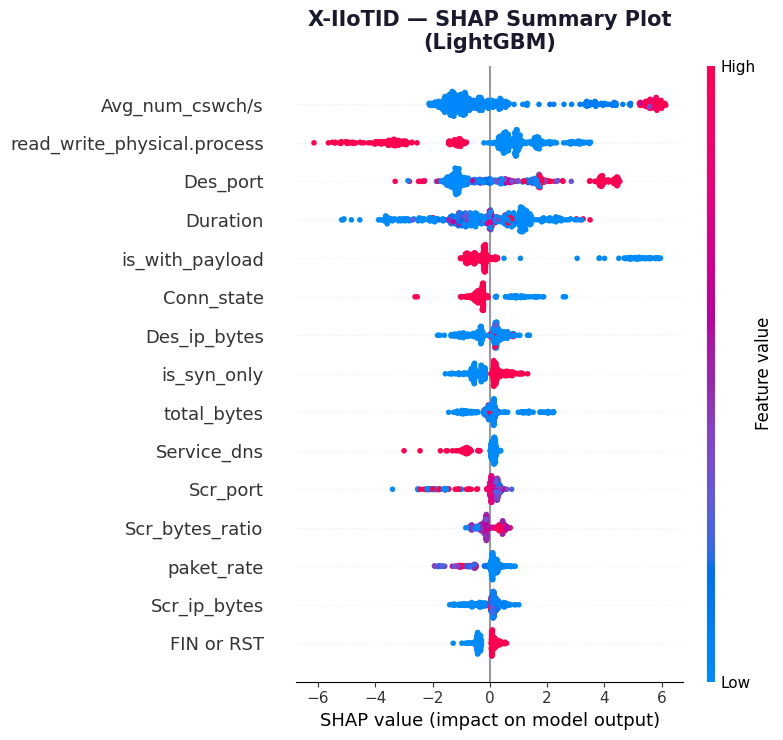

Saved: xiiot_shap_dot.png


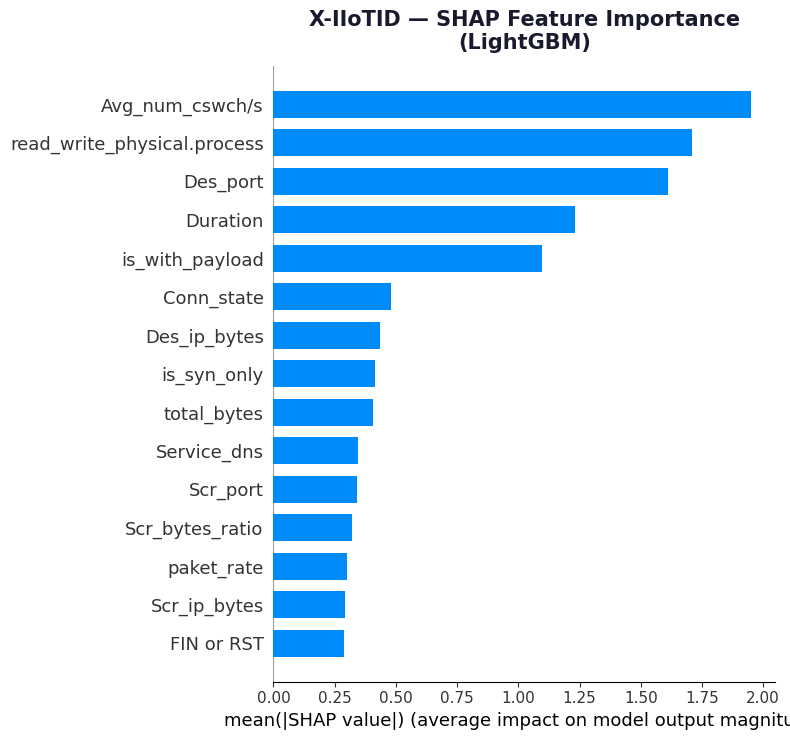

Saved: xiiot_shap_bar.png


In [ ]:
#  CELL 14 — X-IIoTID: SHAP XAI

import shap
print(f"SHAP Analysis — {CURRENT_DATASET} — {best_name_xiiot}")
print("-" * 50)

# TreeExplainer needs a single tree-based model, not an ensemble wrapper.
# If the best model is Stacking/Voting, explain its first base estimator instead;
# otherwise (LightGBM, XGBoost, RF, CatBoost, Extra Trees, AdaBoost, GB) use it directly.
best_model_obj = best_res_xiiot["model"]
model_type     = type(best_model_obj).__name__

if model_type in ("StackingClassifier", "VotingClassifier"):
    shap_model = best_model_obj.estimators_[0]
else:
    shap_model = best_model_obj

explainer   = shap.TreeExplainer(shap_model)
X_shap      = pd.DataFrame(X_test_xiiot, columns=X_xiiot.columns)
shap_sample = X_shap.sample(500, random_state=42)
shap_vals   = explainer.shap_values(shap_sample)

# Handle shape — take class 1 (Attack)
if isinstance(shap_vals, list):
    sv = shap_vals[1]
elif shap_vals.ndim == 3:
    sv = shap_vals[:, :, 1]
elif shap_vals.ndim == 2 and shap_vals.shape[1] == 2:
    sv = shap_vals[:, 1]
else:
    sv = shap_vals


print(f"SHAP values shape: {sv.shape}")

mean_shap         = np.abs(sv).mean(axis=0)
feature_imp_xiiot = pd.Series(
    mean_shap, index=X_xiiot.columns
).sort_values(ascending=False)

print("Top 10 Features by SHAP value:")
for i, (feat, val) in enumerate(feature_imp_xiiot.head(10).items()):
    print(f"  {i+1:2}. {feat:<35} {val:.4f}")

# Plot 1: SHAP Summary Dot Plot
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(sv, shap_sample, max_display=15, show=False, plot_type="dot")
plt.title(f'X-IIoTID — SHAP Summary Plot\n({best_name_xiiot})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('xiiot_shap_dot.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_shap_dot.png")

# Plot 2: SHAP Bar Plot
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(sv, shap_sample, max_display=15, show=False, plot_type="bar")
plt.title(f'X-IIoTID — SHAP Feature Importance\n({best_name_xiiot})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('xiiot_shap_bar.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_shap_bar.png")

In [ ]:
#  CELL 15B — X-IIoTID: Multiclass Attack-Type Model (Secondary)

print(f"Multiclass Attack-Type Classification — {CURRENT_DATASET}")
print("-" * 50)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter
from sklearn.metrics import classification_report, accuracy_score as acc_score, f1_score as f1_sc

# Merge ultra-rare classes (<100 samples in the full dataset) into 'Rare_Attack'
# so SMOTE never has to fabricate thousands of points from a handful of reals.
rare_classes = attack_type_full.value_counts()[attack_type_full.value_counts() < 100].index.tolist()
print(f"Merging into 'Rare_Attack' (<100 samples): {rare_classes}")
y_mc_full = attack_type_full.where(~attack_type_full.isin(rare_classes), 'Rare_Attack')

# Held-out test set from the ORIGINAL (untouched) 19-class distribution —
# same reasoning as the binary pipeline: train balanced, evaluate realistic.
X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    X_xiiot, y_mc_full, test_size=0.20, stratify=y_mc_full, random_state=42
)
print(f"Train: {X_train_mc.shape} | Test: {X_test_mc.shape} (kept ORIGINAL distribution)")

# Hybrid resampling on TRAIN only:
#   - cap oversized classes down to UNDER_CAP
#   - SMOTE undersized classes up to OVER_FLOOR, capped at MAX_MULT x their
#     real count (so e.g. 23 real Rare_Attack rows -> 230, not 3,000 fabricated)
UNDER_CAP, OVER_FLOOR, MAX_MULT = 15000, 3000, 10
train_counts = Counter(y_train_mc)
print(f"\nTrain class counts BEFORE resampling:")
for k, v in sorted(train_counts.items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")

under_strategy = {c: UNDER_CAP for c, n in train_counts.items() if n > UNDER_CAP}
over_strategy  = {c: min(OVER_FLOOR, n * MAX_MULT) for c, n in train_counts.items() if n < OVER_FLOOR}

resample_pipe = ImbPipeline(steps=[
    ('under', RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
              if under_strategy else 'passthrough'),
    ('over',  SMOTE(sampling_strategy=over_strategy, random_state=42, k_neighbors=5)
              if over_strategy else 'passthrough'),
])
X_train_mc_bal, y_train_mc_bal = resample_pipe.fit_resample(X_train_mc, y_train_mc)

print(f"\nTrain class counts AFTER hybrid resampling:")
for k, v in sorted(Counter(y_train_mc_bal).items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")
print(f"\nBalanced train shape: {X_train_mc_bal.shape}")

# Train a multiclass model (RandomForest — fast, interpretable, no scaling needed)
mc_model_xiiot = RandomForestClassifier(n_estimators=300, max_depth=20,
                                         random_state=42, n_jobs=-1)
mc_model_xiiot.fit(X_train_mc_bal, y_train_mc_bal)
y_pred_mc = mc_model_xiiot.predict(X_test_mc)

print(f"\nAccuracy      : {acc_score(y_test_mc, y_pred_mc):.4f}")
print(f"Macro F1      : {f1_sc(y_test_mc, y_pred_mc, average='macro'):.4f}")
print(f"Weighted F1   : {f1_sc(y_test_mc, y_pred_mc, average='weighted'):.4f}")
print(f"\nPer-class report:")
print(classification_report(y_test_mc, y_pred_mc))

Multiclass Attack-Type Classification — X-IIoTID
--------------------------------------------------
Merging into 'Rare_Attack' (<100 samples): ['Fake_notification']
Train: (647399, 77) | Test: (161850, 77) (kept ORIGINAL distribution)

Train class counts BEFORE resampling:
  Normal: 333059
  RDOS: 112559
  Scanning_vulnerability: 42260
  Generic_scanning: 40202
  BruteForce: 37793
  Discovering_resources: 18518
  Exfiltration: 17707
  MQTT_cloud_broker_subscription: 16653
  insider_malcious: 11795
  Modbus_register_reading: 4762
  False_data_injection: 4074
  C&C: 2285
  Dictionary: 1948
  TCP Relay: 1694
  fuzzing: 917
  Reverse_shell: 813
  crypto-ransomware: 243
  MitM: 94
  Rare_Attack: 23

Train class counts AFTER hybrid resampling:
  BruteForce: 15000
  Discovering_resources: 15000
  Exfiltration: 15000
  Generic_scanning: 15000
  MQTT_cloud_broker_subscription: 15000
  Normal: 15000
  RDOS: 15000
  Scanning_vulnerability: 15000
  insider_malcious: 11795
  Modbus_register_reading

Attack-Type-Aware Response Engine — X-IIoTID
--------------------------------------------------
HIGH-risk flows analyzed: 78,475

Predicted attack-type breakdown (HIGH-risk flows only):
  RDOS                               :  28,161 (35.9%)
  Scanning_vulnerability             :  10,609 (13.5%)
  Generic_scanning                   :   9,936 (12.7%)
  BruteForce                         :   9,461 (12.1%)
  Discovering_resources              :   4,578 (5.8%)
  Exfiltration                       :   4,429 (5.6%)
  MQTT_cloud_broker_subscription     :   4,194 (5.3%)
  insider_malcious                   :   2,980 (3.8%)
  Modbus_register_reading            :   1,201 (1.5%)
  False_data_injection               :   1,011 (1.3%)
  C&C                                :     586 (0.7%)
  Dictionary                         :     472 (0.6%)
  TCP Relay                          :     380 (0.5%)
  Reverse_shell                      :     200 (0.3%)
  fuzzing                            :     174 (0.2%)


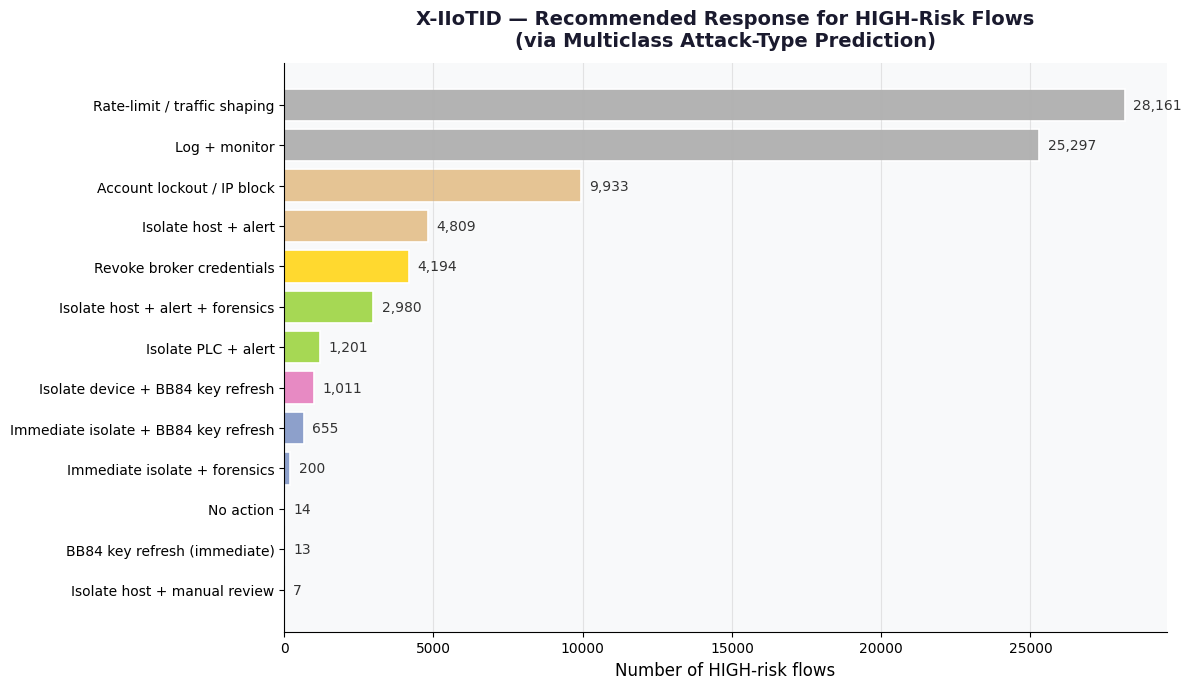

Saved: xiiot_response_recommendation.png


In [ ]:
#  CELL 15D — X-IIoTID: Attack-Type-Aware Response Recommendation

print(f"Attack-Type-Aware Response Engine — {CURRENT_DATASET}")
print("-" * 50)

# Recommended response per attack type — a defensible starting mapping;
# adjust categories to match your thesis's security-response taxonomy.
response_map = {
    "Normal"                          : "No action",
    "RDOS"                            : "Rate-limit / traffic shaping",
    "Scanning_vulnerability"          : "Log + monitor",
    "Generic_scanning"                : "Log + monitor",
    "BruteForce"                      : "Account lockout / IP block",
    "MQTT_cloud_broker_subscription"  : "Revoke broker credentials",
    "Discovering_resources"           : "Log + monitor",
    "Exfiltration"                    : "Isolate host + alert",
    "insider_malcious"                : "Isolate host + alert + forensics",
    "Modbus_register_reading"         : "Isolate PLC + alert",
    "False_data_injection"            : "Isolate device + BB84 key refresh",
    "C&C"                             : "Immediate isolate + BB84 key refresh",
    "Dictionary"                      : "Account lockout / IP block",
    "TCP Relay"                       : "Isolate host + alert",
    "fuzzing"                         : "Log + monitor",
    "Reverse_shell"                   : "Immediate isolate + forensics",
    "crypto-ransomware"               : "Immediate isolate + BB84 key refresh",
    "MitM"                            : "BB84 key refresh (immediate)",
    "Rare_Attack"                     : "Isolate host + manual review",
}

# Only run the multiclass model on flows the binary risk engine already
# flagged HIGH — this is the "second layer" that turns a generic HIGH-risk
# alert into an attack-type-specific response.
high_mask   = (risk_df["risk_tier"] == "HIGH").values
X_high      = X_test_xiiot[high_mask]
pred_types  = mc_model_xiiot.predict(X_high)

response_df = pd.DataFrame({
    "attack_type"       : pred_types,
    "recommended_action": [response_map.get(t, "Isolate host + manual review") for t in pred_types],
})

action_counts = response_df["recommended_action"].value_counts()
type_counts   = response_df["attack_type"].value_counts()

print(f"HIGH-risk flows analyzed: {len(response_df):,}\n")
print("Predicted attack-type breakdown (HIGH-risk flows only):")
for t, c in type_counts.items():
    print(f"  {t:<35}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

print(f"\nRecommended action breakdown:")
for a, c in action_counts.items():
    print(f"  {a:<35}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

# Visualization
fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')
ax.set_facecolor('#F8F9FA')
colors_resp = plt.cm.Set2(np.linspace(0, 1, len(action_counts)))
bars = ax.barh(action_counts.index[::-1], action_counts.values[::-1],
               color=colors_resp, edgecolor='white', linewidth=1.2)
ax.set_title('X-IIoTID — Recommended Response for HIGH-Risk Flows\n(via Multiclass Attack-Type Prediction)',
             fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Number of HIGH-risk flows', fontsize=12)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, val in zip(bars, action_counts.values[::-1]):
    ax.text(bar.get_width() + max(action_counts.values)*0.01, bar.get_y()+bar.get_height()/2,
            f'{val:,}', va='center', fontsize=10, color='#333333')

plt.tight_layout()
plt.savefig('xiiot_response_recommendation.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: xiiot_response_recommendation.png")

# For Dashboard

In [ ]:
 export_app_artifacts(
    dataset_key = "XIIoTID",
    country     = cfg["country"],
    X_test_raw  = X_test_xiiot,
    y_test      = y_test_xiiot,
    results     = results_xiiot,
    best_name   = best_name_xiiot,
    models_dict = models_xiiot,
    mc_model    = mc_model_xiiot,
    X_test_mc   = X_test_mc,
    y_test_mc   = y_test_mc,
    response_map= response_map,
)

Saved: app_artifacts_XIIoTID.pkl (166.3 MB)  |  sample=2000 rows, best_model=LightGBM, needs_scale=False


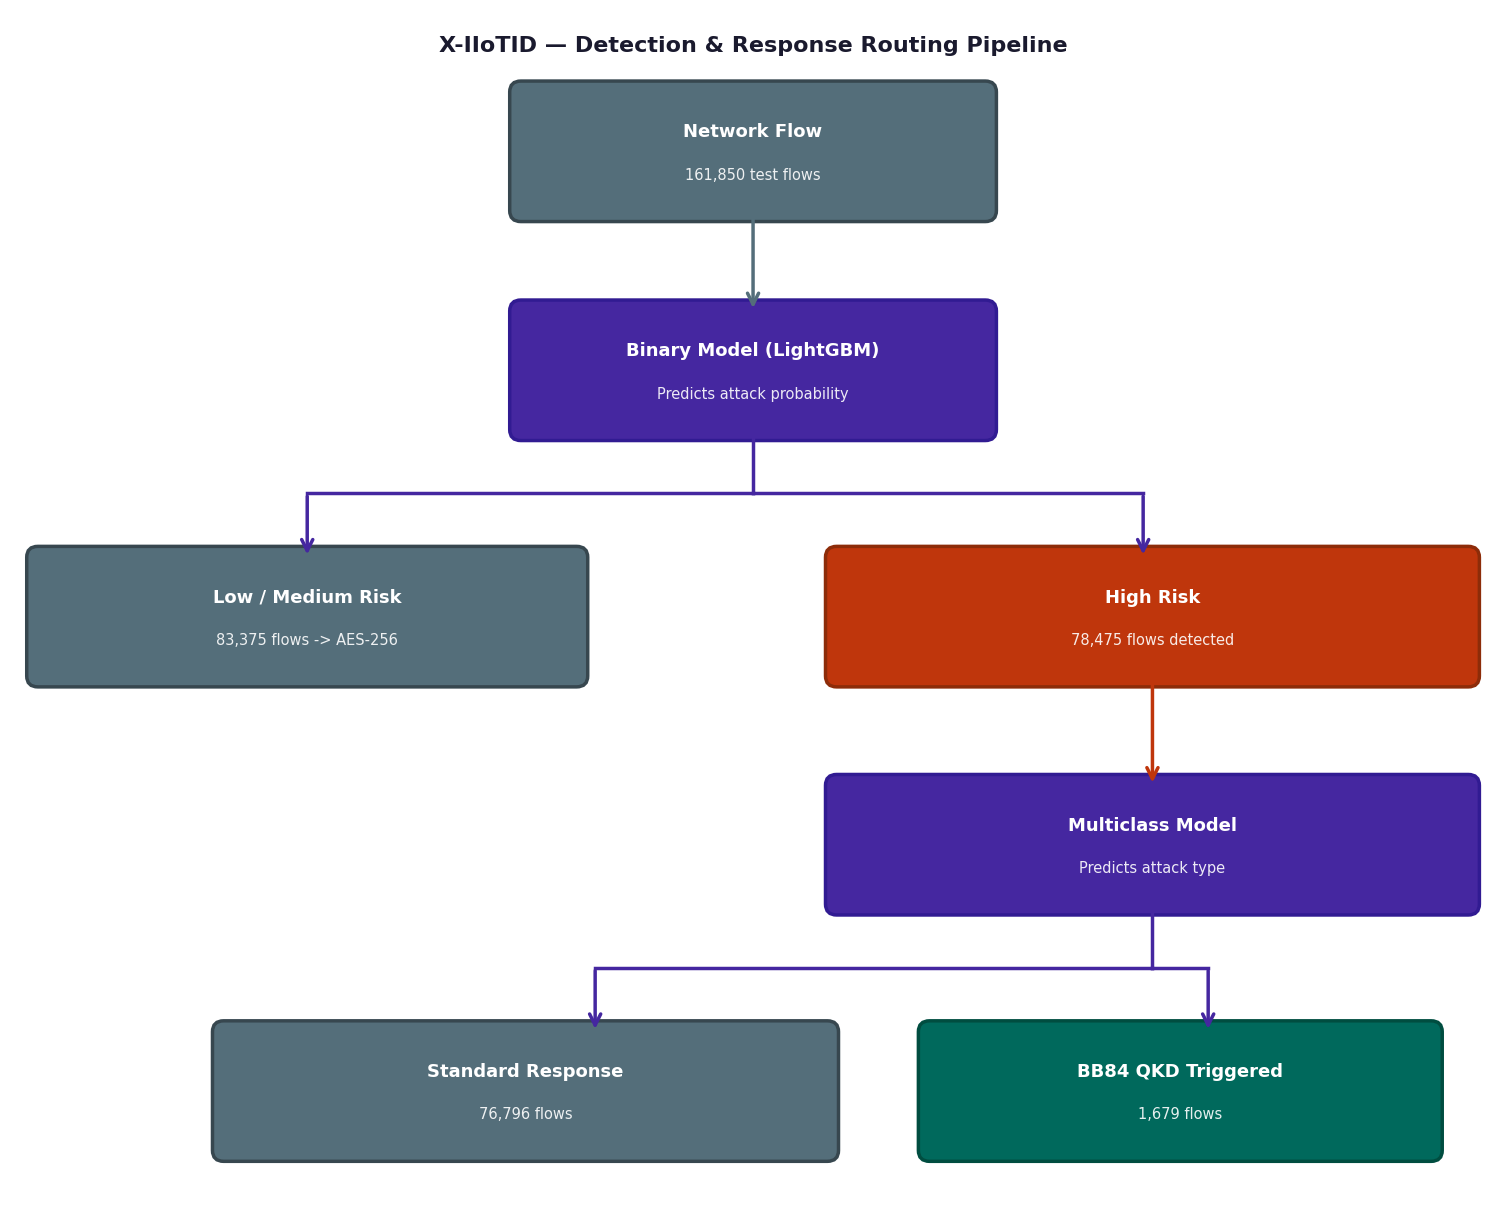

Saved: xiiot_detection_routing_pipeline.png


In [ ]:
#  CELL 15E — X-IIoTID: Detection & Response Routing Pipeline Diagram

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 12), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(2.4, 15.4)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.66, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.30, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3, alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

ax.text(8, 15.0, 'X-IIoTID — Detection & Response Routing Pipeline',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

# Row1 — Network flow (gray)
draw_box(5.5, 13.2, 5.0, 1.3, 'Network Flow', f'{n_total:,} test flows',
         '#546E7A', '#37474F')
draw_arrow(8.0, 13.2, 8.0, 12.1, '#546E7A')

# Row2 — Binary model (purple)
draw_box(5.5, 10.8, 5.0, 1.3, f'Binary Model ({best_name_xiiot})', 'Predicts attack probability',
         '#4527A0', '#311B92')

# Branch lines down to row3
ax.plot([8.0, 8.0], [10.8, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 3.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 12.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(3.2, 10.1, 3.2, 9.4, '#4527A0')
draw_arrow(12.2, 10.1, 12.2, 9.4, '#4527A0')

# Row3 — Low/Medium (gray, left) + High (coral, right)
draw_box(0.3, 8.1, 5.8, 1.3, 'Low / Medium Risk', f'{n_low+n_medium:,} flows -> AES-256',
         '#546E7A', '#37474F')
draw_box(8.9, 8.1, 6.8, 1.3, 'High Risk', f'{n_high:,} flows detected',
         '#BF360C', '#8D2C09')
draw_arrow(12.3, 8.1, 12.3, 6.9, '#BF360C')

# Row4 — Multiclass model (purple, under High)
draw_box(8.9, 5.6, 6.8, 1.3, 'Multiclass Model', 'Predicts attack type',
         '#4527A0', '#311B92')

# Branch lines down to row5
ax.plot([12.3, 12.3], [5.6, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 6.3], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 12.9], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(6.3, 4.9, 6.3, 4.2, '#4527A0')
draw_arrow(12.9, 4.9, 12.9, 4.2, '#4527A0')

# Row5 — Standard response (gray, left) + BB84 triggered (teal, right)
other_count = len(response_df) - (response_df['recommended_action'].str.contains('BB84').sum())
bb84_count  = response_df['recommended_action'].str.contains('BB84').sum()
draw_box(2.3, 2.9, 6.5, 1.3, 'Standard Response', f'{other_count:,} flows',
         '#546E7A', '#37474F')
draw_box(9.9, 2.9, 5.4, 1.3, 'BB84 QKD Triggered', f'{bb84_count:,} flows',
         '#00695C', '#004D40')

plt.tight_layout(pad=0.5)
plt.savefig('xiiot_detection_routing_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: xiiot_detection_routing_pipeline.png')

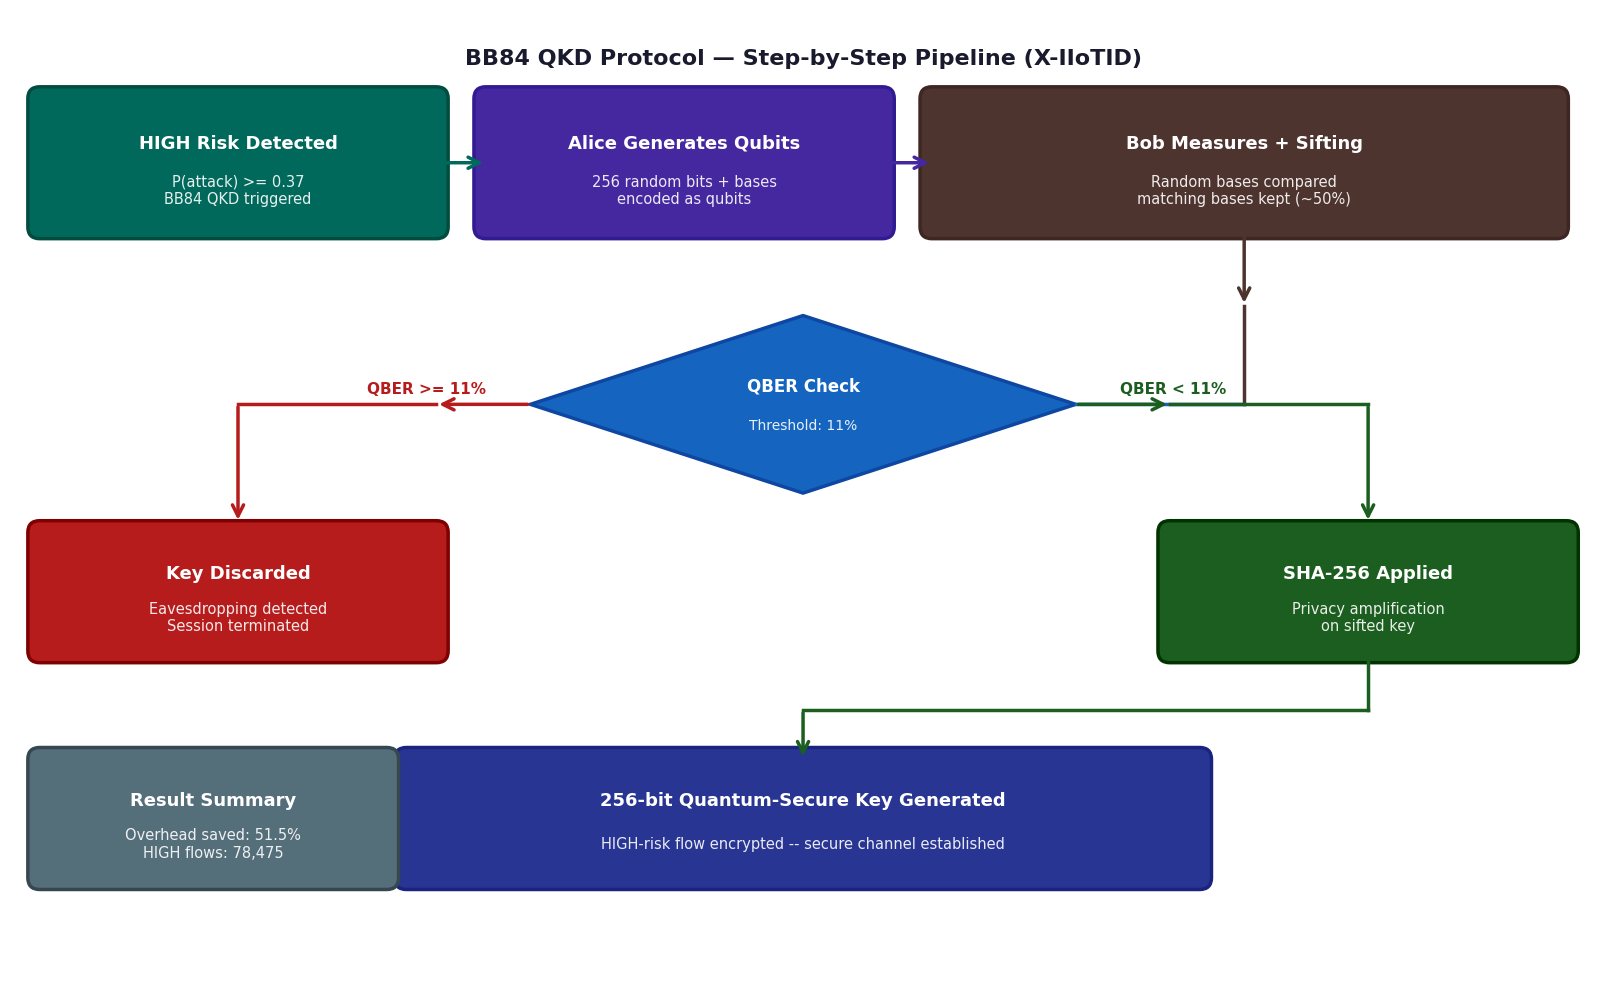

Saved: xiiot_bb84_pipeline.png


In [ ]:
#  CELL 15F — X-IIoTID: BB84 QKD Protocol Pipeline Diagram

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 10), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.65, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.28, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3,
            multialignment='center', alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

def draw_diamond(cx, cy, w, h, title, subtitle, fc, ec):
    dx = [cx, cx+w/2, cx, cx-w/2]
    dy = [cy+h/2, cy, cy-h/2, cy]
    ax.add_patch(plt.Polygon(list(zip(dx, dy)),
                 facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2))
    ax.text(cx, cy+0.18, title, ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', zorder=3)
    ax.text(cx, cy-0.22, subtitle, ha='center', va='center',
            fontsize=10, color='white', zorder=3, alpha=0.9)

ax.text(8, 9.5, 'BB84 QKD Protocol — Step-by-Step Pipeline (X-IIoTID)',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

# Step 1 — Teal
draw_box(0.3, 7.8, 4.0, 1.3,
         'HIGH Risk Detected',
         f'P(attack) >= {best_t_xiiot:.2f}\nBB84 QKD triggered',
         '#00695C', '#004D40')
draw_arrow(4.3, 8.45, 4.8, 8.45, '#00695C')

# Step 2 — Deep Purple
draw_box(4.8, 7.8, 4.0, 1.3,
         'Alice Generates Qubits',
         '256 random bits + bases\nencoded as qubits',
         '#4527A0', '#311B92')
draw_arrow(8.8, 8.45, 9.3, 8.45, '#4527A0')

# Step 3 — Brown
draw_box(9.3, 7.8, 6.3, 1.3,
         'Bob Measures + Sifting',
         'Random bases compared\nmatching bases kept (~50%)',
         '#4E342E', '#3E2723')
draw_arrow(12.45, 7.8, 12.45, 7.0, '#4E342E')

# QBER Diamond — Dark Blue
draw_diamond(8.0, 6.0, 5.5, 1.8,
             'QBER Check',
             'Threshold: 11%',
             '#1565C0', '#0D47A1')

ax.plot([12.45, 12.45], [7.0, 6.0], color='#4E342E', lw=2.5, zorder=4)
ax.plot([12.45, 10.75], [6.0, 6.0], color='#1565C0', lw=2.5, zorder=4)

ax.text(4.8, 6.15, 'QBER >= 11%', ha='right', va='center',
        fontsize=11, fontweight='bold', color='#B71C1C')
ax.text(11.2, 6.15, 'QBER < 11%', ha='left', va='center',
        fontsize=11, fontweight='bold', color='#1B5E20')

# Left — Key Discard (Dark Red)
draw_arrow(5.25, 6.0, 4.3, 6.0, '#B71C1C')
ax.plot([4.3, 2.3], [6.0, 6.0], color='#B71C1C', lw=2.5, zorder=4)
draw_arrow(2.3, 6.0, 2.3, 4.8, '#B71C1C')
draw_box(0.3, 3.5, 4.0, 1.2,
         'Key Discarded',
         'Eavesdropping detected\nSession terminated',
         '#B71C1C', '#7F0000')

# Right — SHA-256 (Dark Green)
draw_arrow(10.75, 6.0, 11.7, 6.0, '#1B5E20')
ax.plot([11.7, 13.7], [6.0, 6.0], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(13.7, 6.0, 13.7, 4.8, '#1B5E20')
draw_box(11.7, 3.5, 4.0, 1.2,
         'SHA-256 Applied',
         'Privacy amplification\non sifted key',
         '#1B5E20', '#003300')

# Final Key — Indigo
ax.plot([13.7, 13.7], [3.5, 2.9], color='#1B5E20', lw=2.5, zorder=4)
ax.plot([13.7, 8.0],  [2.9, 2.9], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(8.0, 2.9, 8.0, 2.4, '#1B5E20')
draw_box(4.0, 1.2, 8.0, 1.2,
         '256-bit Quantum-Secure Key Generated',
         'HIGH-risk flow encrypted -- secure channel established',
         '#283593', '#1A237E')

# Result Summary — Blue Grey
draw_box(0.3, 1.2, 3.5, 1.2,
         'Result Summary',
         f'Overhead saved: {100-qkd_pct:.1f}%\nHIGH flows: {n_high:,}',
         '#546E7A', '#37474F')

plt.tight_layout(pad=0.5)
plt.savefig('xiiot_bb84_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: xiiot_bb84_pipeline.png')

In [ ]:
#  CELL 16 — X-IIoTID: Save Results

print(f"Saving results — {CURRENT_DATASET}")
print("-" * 50)

xiiot_master = {
    "dataset"      : CURRENT_DATASET,
    "country"      : cfg["country"],
    "ml_results"   : {
        name: {
            "category" : res["category"],
            "accuracy" : res["accuracy"],
            "f1"       : res["f1"],
            "precision": res["precision"],
            "recall"   : res["recall"],
            "auc"      : res["auc"],
            "time"     : res["time"],
            "y_pred"   : res["y_pred"],
            "y_prob"   : res["y_prob"],
        }
        for name, res in results_xiiot.items()
    },
    "best_model"       : best_name_xiiot,
    "best_f1"          : best_res_xiiot["f1"],
    "best_auc"         : best_res_xiiot["auc"],
    "optimal_threshold": best_t_xiiot,
    "risk_engine"      : {
        "n_total"       : n_total,
        "n_low"         : n_low,
        "n_medium"      : n_medium,
        "n_high"        : n_high,
        "overhead_saved": round(100 - qkd_pct, 2),
    },
    "qkd_results"  : qkd_results_xiiot,
    "shap_top10"   : feature_imp_xiiot.to_dict(),
    "y_test"       : y_test_xiiot,
    "multiclass"   : {
        "classes"      : sorted(y_mc_full.unique().tolist()),
        "macro_f1"     : f1_sc(y_test_mc, y_pred_mc, average="macro"),
        "weighted_f1"  : f1_sc(y_test_mc, y_pred_mc, average="weighted"),
        "accuracy"     : acc_score(y_test_mc, y_pred_mc),
    },
    "response_engine": {
        "attack_type_breakdown": type_counts.to_dict(),
        "action_breakdown"     : action_counts.to_dict(),
    },
}

save_path = "/content/drive/MyDrive/datasets/results_XIIoTID.pkl"
with open(save_path, "wb") as f:
    pickle.dump(xiiot_master, f)

size = os.path.getsize(save_path) / 1024
print(f"Saved: results_XIIoTID.pkl ({size:.1f} KB)")
print(f"\nSummary:")
print(f"  Best Model (binary)   : {best_name_xiiot}")
print(f"  F1-Score              : {best_res_xiiot['f1']:.4f}")
print(f"  AUC-ROC               : {best_res_xiiot['auc']:.4f}")
print(f"  Optimal Threshold     : {best_t_xiiot:.2f}")
print(f"  Overhead Saved        : {100 - qkd_pct:.1f}%")
print(f"  HIGH Risk Flows       : {n_high:,}")
print(f"  Multiclass Macro F1   : {xiiot_master['multiclass']['macro_f1']:.4f}")

Saving results — X-IIoTID
--------------------------------------------------
Saved: results_XIIoTID.pkl (33515.4 KB)

Summary:
  Best Model (binary)   : LightGBM
  F1-Score              : 0.9972
  AUC-ROC               : 0.9999
  Optimal Threshold     : 0.37
  Overhead Saved        : 51.5%
  HIGH Risk Flows       : 78,475
  Multiclass Macro F1   : 0.9257


Dataset: HQC-2026 (Bangladesh)
--------------------------------------------------
Shape          : (233844, 88)
Missing values : 0

Label distribution:
label
Benign                      177693
Bot                          20226
Infilteration                15620
FTP-BruteForce                5826
SSH-Bruteforce                5442
DoS attacks-SlowHTTPTest      2755
DoS attacks-Slowloris         2449
DDOS attack-HOIC              1342
DDOS attack-LOIC-UDP           985
DoS attacks-GoldenEye          647
Brute Force -Web               408
DoS attacks-Hulk               198
Brute Force -XSS               177
SQL Injection                   76
Name: count, dtype: int64

Binary distribution:
  Benign : 177,693 (76.0%)
  Attack : 56,151 (24.0%)


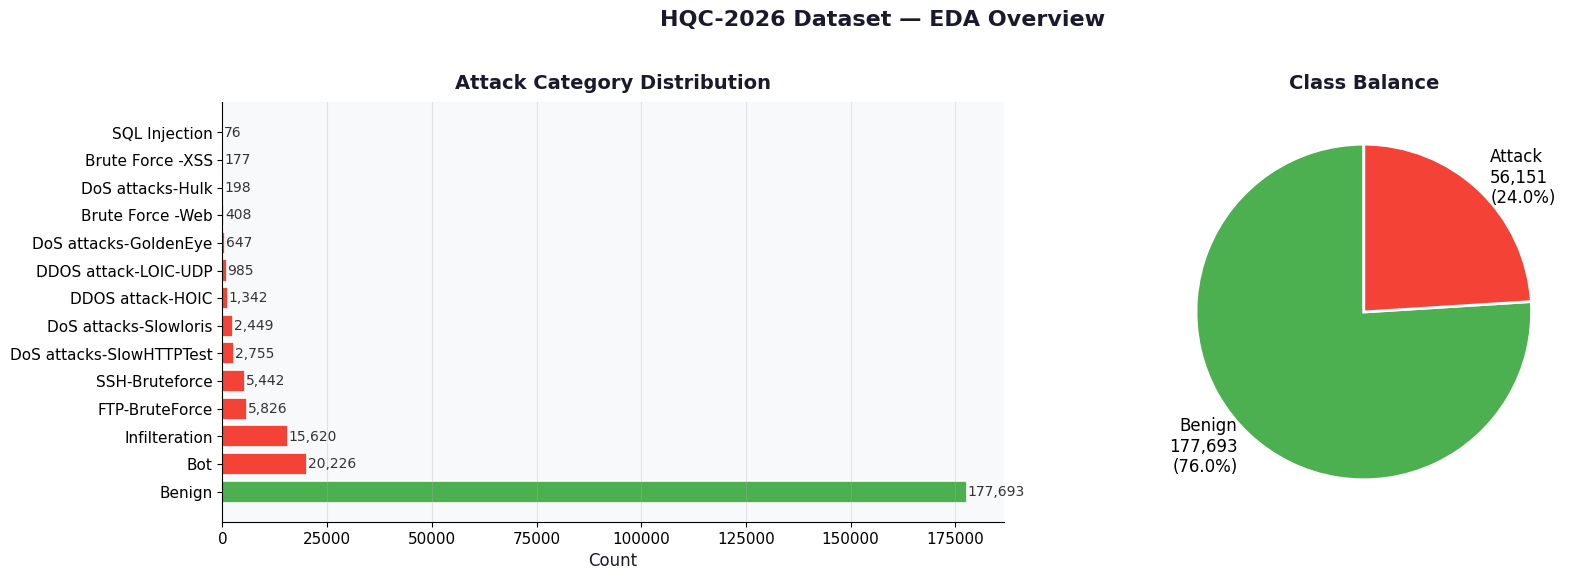

Saved: hqc2026_eda.png


In [ ]:
#  CELL 17 — HQC-2026: Load + EDA

CURRENT_DATASET = "HQC-2026"
cfg = DATASETS[CURRENT_DATASET]

print(f"Dataset: {CURRENT_DATASET} ({cfg['country']})")
print("-" * 50)

df_hqc, _ = load_and_prepare(cfg, CURRENT_DATASET)

print(f"Shape          : {df_hqc.shape}")
print(f"Missing values : {df_hqc.isnull().sum().sum()}")
print(f"\nLabel distribution:")
print(df_hqc[cfg["label_col"]].value_counts())

# Binary distribution
benign = (df_hqc[cfg["label_col"]] == "Benign").sum()
attack = (df_hqc[cfg["label_col"]] != "Benign").sum()
total  = len(df_hqc)
print(f"\nBinary distribution:")
print(f"  Benign : {benign:,} ({benign/total*100:.1f}%)")
print(f"  Attack : {attack:,} ({attack/total*100:.1f}%)")

# EDA Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6), facecolor='white')
fig.suptitle('HQC-2026 Dataset — EDA Overview',
             fontsize=16, fontweight='bold', color='#1a1a2e')

# Plot 1 — Attack category distribution
ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
counts = df_hqc[cfg["label_col"]].value_counts()
colors = ['#4CAF50' if x == 'Benign' else '#F44336' for x in counts.index]
bars   = ax1.barh(counts.index, counts.values,
                  color=colors, edgecolor='white', linewidth=1.2)
ax1.set_title('Attack Category Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)
ax1.set_xlabel('Count', fontsize=12, color='#1a1a2e')
ax1.tick_params(labelsize=11)
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for bar, val in zip(bars, counts.values):
    ax1.text(bar.get_width() + 200, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=10, color='#333333')

# Plot 2 — Class balance
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
sizes  = [benign, attack]
labels = [f'Benign\n{benign:,}\n({benign/total*100:.1f}%)',
          f'Attack\n{attack:,}\n({attack/total*100:.1f}%)']
colors = ['#4CAF50', '#F44336']
ax2.pie(sizes, labels=labels, colors=colors,
        startangle=90, textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Class Balance', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)

plt.tight_layout(pad=2.0)
plt.savefig('hqc2026_eda.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_eda.png")

In [ ]:
#  CELL 18 — HQC-2026: Preprocessing + Log-Transform + Held-Out Test Split + SMOTE-Balanced Stratified Sampling

from scipy.stats import skew

print(f"Preprocessing: {CURRENT_DATASET}")
print("-" * 50)

X_hqc, y_hqc, _, _ = preprocess(df_hqc, cfg, CURRENT_DATASET)

# ---- Drop exact duplicate rows ----
# Dropping the quantum-specific columns (qber, fidelity, etc. — done inside
# preprocess()) collapses some previously-unique rows into duplicates, since
# those columns had unique high-precision values. 123 duplicates appear once
# they are removed; drop them here to avoid inflating any single flow pattern.
combined = X_hqc.copy()
combined["attack"] = y_hqc.values
before = len(combined)
combined = combined.drop_duplicates()
print(f"Dropped {before - len(combined)} duplicate rows (post quantum-column removal)")
y_hqc = combined.pop("attack")
X_hqc = combined

# ---- Log-transform heavily skewed columns ----
skewed_cols = []
for col in X_hqc.select_dtypes(include=[np.number]).columns:
    if (X_hqc[col] >= 0).all() and X_hqc[col].nunique() > 10:
        if skew(X_hqc[col]) > 2:
            skewed_cols.append(col)

print(f"Log-transforming {len(skewed_cols)} heavily skewed columns")
X_hqc[skewed_cols] = np.log1p(X_hqc[skewed_cols])

print(f"Features after preprocessing : {X_hqc.shape[1]}")
print(f"Samples                      : {X_hqc.shape[0]:,}")
print(f"Benign (0): {(y_hqc==0).sum():,} ({(y_hqc==0).mean()*100:.1f}%)")
print(f"Attack (1): {(y_hqc==1).sum():,} ({(y_hqc==1).mean()*100:.1f}%)")

# ---- Held-out test set FIRST, from the ORIGINAL (untouched) distribution ----
X_train_pool, X_test_hqc, y_train_pool, y_test_hqc = train_test_split(
    X_hqc, y_hqc, test_size=0.20, stratify=y_hqc, random_state=42
)
print(f"\nHeld-out test set : {len(X_test_hqc):,} (kept at ORIGINAL class ratio)")
print(f"Train pool         : {len(X_train_pool):,}")

# ---- SMOTE the train pool only ----
if cfg["needs_smote"]:
    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train_pool, y_train_pool)
    print(f"\nAfter SMOTE — Train pool: {len(X_train_bal):,}")
else:
    X_train_bal, y_train_bal = X_train_pool, y_train_pool

train_pool = X_train_bal.copy()
train_pool["attack"] = np.array(y_train_bal)

benign_df = train_pool[train_pool["attack"] == 0]
attack_df = train_pool[train_pool["attack"] == 1]
print(f"Balanced pool -> Benign: {len(benign_df):,}, Attack: {len(attack_df):,}")

n_per_class = 75000
benign_sampled = benign_df.sample(n=min(n_per_class, len(benign_df)), random_state=42)
attack_sampled = attack_df.sample(n=min(n_per_class, len(attack_df)), random_state=42)
n_per_chunk    = min(len(benign_sampled), len(attack_sampled)) // 3

benign_sampled = benign_sampled.sample(frac=1, random_state=42).reset_index(drop=True)
attack_sampled = attack_sampled.sample(frac=1, random_state=42).reset_index(drop=True)

def _build_sample(b_chunk, a_chunk):
    merged = pd.concat([b_chunk, a_chunk]).sample(frac=1, random_state=42).reset_index(drop=True)
    y = merged.pop("attack")
    return merged, y

X_s1_hqc, y_s1_hqc = _build_sample(benign_sampled.iloc[0:n_per_chunk],               attack_sampled.iloc[0:n_per_chunk])
X_s2_hqc, y_s2_hqc = _build_sample(benign_sampled.iloc[n_per_chunk:2*n_per_chunk],   attack_sampled.iloc[n_per_chunk:2*n_per_chunk])
X_s3_hqc, y_s3_hqc = _build_sample(benign_sampled.iloc[2*n_per_chunk:3*n_per_chunk], attack_sampled.iloc[2*n_per_chunk:3*n_per_chunk])

print(f"\nSample distribution check:")
ratios = []
for i, (Xs, ys) in enumerate([(X_s1_hqc, y_s1_hqc), (X_s2_hqc, y_s2_hqc), (X_s3_hqc, y_s3_hqc)], 1):
    ratios.append(ys.mean())
    print(f"  Sample {i} — Benign: {(ys==0).sum():,} | Attack: {(ys==1).sum():,} | Total: {len(ys):,}")

std_dev = float(np.std(ratios))
print(f"\nStability check — Std Dev of attack ratio across 3 samples: {std_dev:.6f}")
print("Conclusion: Sampling is STABLE — No bias detected." if std_dev < 0.001
      else "WARNING — variance above threshold, review sampling.")

Preprocessing: HQC-2026
--------------------------------------------------
Dropped 123 duplicate rows (post quantum-column removal)
Log-transforming 53 heavily skewed columns
Features after preprocessing : 78
Samples                      : 233,721
Benign (0): 177,621 (76.0%)
Attack (1): 56,100 (24.0%)

Held-out test set : 46,745 (kept at ORIGINAL class ratio)
Train pool         : 186,976

After SMOTE — Train pool: 284,192
Balanced pool -> Benign: 142,096, Attack: 142,096

Sample distribution check:
  Sample 1 — Benign: 25,000 | Attack: 25,000 | Total: 50,000
  Sample 2 — Benign: 25,000 | Attack: 25,000 | Total: 50,000
  Sample 3 — Benign: 25,000 | Attack: 25,000 | Total: 50,000

Stability check — Std Dev of attack ratio across 3 samples: 0.000000
Conclusion: Sampling is STABLE — No bias detected.


In [ ]:
#  CELL 19 — HQC-2026: Train 12 Models (Sample 1)

print(f"Training 12 models — Sample 1...")
print("-" * 50)

scaler_s1_hqc     = StandardScaler()
X_train_s1_hqc_sc = scaler_s1_hqc.fit_transform(X_s1_hqc)
X_test_s1_hqc_sc  = scaler_s1_hqc.transform(X_test_hqc)

models_s1_hqc  = get_models()
results_s1_hqc = train_models(
    models_s1_hqc,
    X_s1_hqc, X_test_hqc,
    y_s1_hqc, y_test_hqc,
    X_train_s1_hqc_sc, X_test_s1_hqc_sc
)

best_name_s1_hqc, best_res_s1_hqc = find_best_model(results_s1_hqc)
best_t_s1_hqc, best_f1_t_s1_hqc   = optimize_threshold(y_test_hqc, best_res_s1_hqc["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s1_hqc.items():
    marker = " *" if name == best_name_s1_hqc else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s1_hqc}")
print(f"F1-Score          : {best_res_s1_hqc['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s1_hqc['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s1_hqc:.2f}")
print(f"F1 at Threshold   : {best_f1_t_s1_hqc:.4f}")

Training 12 models — Sample 1...
--------------------------------------------------
  Training Random Forest... 

KeyboardInterrupt: 

In [ ]:
#  CELL 20 — HQC-2026: Train 12 Models (Sample 2)

print(f"Training 12 models — Sample 2...")
print("-" * 50)

scaler_s2_hqc     = StandardScaler()
X_train_s2_hqc_sc = scaler_s2_hqc.fit_transform(X_s2_hqc)
X_test_s2_hqc_sc  = scaler_s2_hqc.transform(X_test_hqc)

models_s2_hqc  = get_models()
results_s2_hqc = train_models(
    models_s2_hqc,
    X_s2_hqc, X_test_hqc,
    y_s2_hqc, y_test_hqc,
    X_train_s2_hqc_sc, X_test_s2_hqc_sc
)

best_name_s2_hqc, best_res_s2_hqc = find_best_model(results_s2_hqc)
best_t_s2_hqc, best_f1_t_s2_hqc   = optimize_threshold(y_test_hqc, best_res_s2_hqc["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s2_hqc.items():
    marker = " *" if name == best_name_s2_hqc else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s2_hqc}")
print(f"F1-Score          : {best_res_s2_hqc['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s2_hqc['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s2_hqc:.2f}")
print(f"F1 at Threshold   : {best_f1_t_s2_hqc:.4f}")

In [ ]:
#  CELL 21 — HQC-2026: Train 12 Models (Sample 3)

print(f"Training 12 models — Sample 3...")
print("-" * 50)

scaler_s3_hqc     = StandardScaler()
X_train_s3_hqc_sc = scaler_s3_hqc.fit_transform(X_s3_hqc)
X_test_s3_hqc_sc  = scaler_s3_hqc.transform(X_test_hqc)

models_s3_hqc  = get_models()
results_s3_hqc = train_models(
    models_s3_hqc,
    X_s3_hqc, X_test_hqc,
    y_s3_hqc, y_test_hqc,
    X_train_s3_hqc_sc, X_test_s3_hqc_sc
)

best_name_s3_hqc, best_res_s3_hqc = find_best_model(results_s3_hqc)
best_t_s3_hqc, best_f1_t_s3_hqc   = optimize_threshold(y_test_hqc, best_res_s3_hqc["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s3_hqc.items():
    marker = " *" if name == best_name_s3_hqc else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s3_hqc}")
print(f"F1-Score          : {best_res_s3_hqc['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s3_hqc['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s3_hqc:.2f}")
print(f"F1 at Threshold   : {best_f1_t_s3_hqc:.4f}")

Training 12 models — Sample 3...
--------------------------------------------------
  Training Random Forest... done — F1: 0.7756 (87.0s)
  Training Gradient Boosting... done — F1: 0.7816 (579.6s)
  Training XGBoost... done — F1: 0.7913 (11.7s)
  Training SVM... done — F1: 0.7792 (1557.7s)
  Training Voting Ensemble... done — F1: 0.7845 (254.3s)
  Training Stacking... done — F1: 0.7835 (2460.3s)
  Training LightGBM... done — F1: 0.7964 (40.8s)
  Training MLP Neural Net... done — F1: 0.7661 (63.1s)
  Training CatBoost... done — F1: 0.7706 (14.7s)
  Training Extra Trees... done — F1: 0.7480 (15.7s)
  Training AdaBoost... done — F1: 0.6263 (146.9s)
  Training Naive Bayes... done — F1: 0.4109 (0.2s)

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.8964   0.7756   0.9351
Gradient Boosting    Base          0.8987   0.7816   0.9400
XGBoost              Base          

In [ ]:
#  Stability Check — Final Decision (HQC-2026)

model_names_hqc = list(results_s1_hqc.keys())

print(f"{'Model':<20} {'S1 F1':>8} {'S2 F1':>8} {'S3 F1':>8} {'Avg F1':>9} {'Std Dev':>9}")
print("-" * 70)

avg_f1_dict_hqc = {}
for name in model_names_hqc:
    f1_s1 = results_s1_hqc[name]["f1"]
    f1_s2 = results_s2_hqc[name]["f1"]
    f1_s3 = results_s3_hqc[name]["f1"]
    avg   = np.mean([f1_s1, f1_s2, f1_s3])
    std   = np.std([f1_s1, f1_s2, f1_s3])
    avg_f1_dict_hqc[name] = {"avg": avg, "std": std}

best_avg_model_hqc = max(avg_f1_dict_hqc, key=lambda x: avg_f1_dict_hqc[x]["avg"])
for name in model_names_hqc:
    f1_s1 = results_s1_hqc[name]["f1"]
    f1_s2 = results_s2_hqc[name]["f1"]
    f1_s3 = results_s3_hqc[name]["f1"]
    avg   = avg_f1_dict_hqc[name]["avg"]
    std   = avg_f1_dict_hqc[name]["std"]
    marker = " *" if name == best_avg_model_hqc else ""
    print(f"{name:<20} {f1_s1:>8.4f} {f1_s2:>8.4f} {f1_s3:>8.4f} "
          f"{avg:>9.4f} {std:>9.4f}")

print(f"\nFinal Best Model  : {best_avg_model_hqc}")
print(f"Average F1        : {avg_f1_dict_hqc[best_avg_model_hqc]['avg']:.4f}")
print(f"Std Dev           : {avg_f1_dict_hqc[best_avg_model_hqc]['std']:.4f}")
print("\nConclusion: Sampling is STABLE — No bias detected."
      if avg_f1_dict_hqc[best_avg_model_hqc]['std'] < 0.01
      else "\nWARNING: F1 variance across samples is high — review sampling.")

Model                   S1 F1    S2 F1    S3 F1    Avg F1   Std Dev
----------------------------------------------------------------------
Random Forest          0.7723   0.7766   0.7756    0.7748    0.0018
Gradient Boosting      0.7819   0.7833   0.7816    0.7823    0.0008
XGBoost                0.7913   0.7929   0.7913    0.7918    0.0008
SVM                    0.7777   0.7799   0.7792    0.7789    0.0009
Voting Ensemble        0.7838   0.7870   0.7845    0.7851    0.0014
Stacking               0.7845   0.7885   0.7835    0.7855    0.0022
LightGBM               0.7935   0.7999   0.7964    0.7966    0.0026
MLP Neural Net         0.7673   0.7751   0.7661    0.7695    0.0040
CatBoost               0.7728   0.7721   0.7706    0.7718    0.0009
Extra Trees            0.7474   0.7519   0.7480    0.7491    0.0020
AdaBoost               0.6272   0.6258   0.6263    0.6265    0.0006
Naive Bayes            0.4062   0.4055   0.4109    0.4076    0.0024

Final Best Model  : LightGBM
Average F1     

In [ ]:
#  CELL — HQC-2026: Merge 3 Samples (Data Only)

print(f"Merging 3 Non-Overlapping Samples — {CURRENT_DATASET}")
print("-" * 50)

X_merged_hqc = pd.concat([X_s1_hqc, X_s2_hqc, X_s3_hqc], axis=0).reset_index(drop=True)
y_merged_hqc = pd.concat([y_s1_hqc, y_s2_hqc, y_s3_hqc], axis=0).reset_index(drop=True)

print(f"Merged dataset:")
print(f"  Total   : {len(X_merged_hqc):,}")
print(f"  Benign  : {(y_merged_hqc==0).sum():,} ({(y_merged_hqc==0).mean()*100:.1f}%)")
print(f"  Attack  : {(y_merged_hqc==1).sum():,} ({(y_merged_hqc==1).mean()*100:.1f}%)")

X_train_hqc, y_train_hqc = X_merged_hqc, y_merged_hqc

scaler_hqc     = StandardScaler()
X_train_hqc_sc = scaler_hqc.fit_transform(X_train_hqc)
X_test_hqc_sc  = scaler_hqc.transform(X_test_hqc)

print(f"\nTrain (merged 150k) : {len(X_train_hqc):,}")
print(f"Test (original dist): {len(X_test_hqc):,}")

Merging 3 Non-Overlapping Samples — HQC-2026
--------------------------------------------------
Merged dataset:
  Total   : 150,000
  Benign  : 75,000 (50.0%)
  Attack  : 75,000 (50.0%)

Train (merged 150k) : 150,000
Test (original dist): 46,745


In [ ]:
#  CELL — HQC-2026: Checkpoint-Safe Per-Model Training Setup (Updated)

import pickle, os, time
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

CHECKPOINT_DIR = "/content/drive/MyDrive/datasets/checkpoints_hqc_merged"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# Models that scale poorly with data size (SVM's O(n^2)-O(n^3) complexity,
# and Stacking which internally fits an SVM as one of its base estimators)
# are trained on a 50k subset instead of the full 150k merged set.
# X_train_hqc[:50000] / X_train_hqc_sc[:50000] is exactly X_s1_hqc (same
# rows, same order, since X_merged_hqc = concat([X_s1_hqc, X_s2_hqc, X_s3_hqc])).
# Justification: across the 3 independent 50k stability-check samples, SVM's
# F1 had std dev of only 0.0009 — performance had already saturated, so
# training on more data isn't expected to change results meaningfully.
REDUCED_DATA_MODELS = {"SVM", "Stacking"}
REDUCED_SIZE = 50000

def train_single_model(model_name):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"{model_name.replace(' ', '_')}.pkl")

    if os.path.exists(ckpt_path):
        with open(ckpt_path, "rb") as f:
            res = pickle.load(f)
        print(f"[SKIPPED — already done] {model_name}  F1: {res['f1']:.4f}")
        return res

    all_models = get_models()
    cfg_m = all_models[model_name]
    model = cfg_m["model"]

    if model_name in REDUCED_DATA_MODELS:
        X_tr_full = X_train_hqc_sc if cfg_m["needs_scale"] else X_train_hqc
        X_tr = X_tr_full[:REDUCED_SIZE]
        y_tr = y_train_hqc[:REDUCED_SIZE]
        print(f"NOTE: {model_name} trained on {REDUCED_SIZE:,} rows (not full 150k) — see justification above")
    else:
        X_tr = X_train_hqc_sc if cfg_m["needs_scale"] else X_train_hqc
        y_tr = y_train_hqc

    X_te = X_test_hqc_sc if cfg_m["needs_scale"] else X_test_hqc

    print(f"Training {model_name}...")
    start = time.time()
    model.fit(X_tr, y_tr)
    elapsed = time.time() - start

    y_pred = model.predict(X_te)
    y_prob = model.predict_proba(X_te)[:, 1]

    res = {
        "model"      : model,
        "category"   : cfg_m["category"],
        "accuracy"   : accuracy_score(y_test_hqc, y_pred),
        "f1"         : f1_score(y_test_hqc, y_pred),
        "precision"  : precision_score(y_test_hqc, y_pred),
        "recall"     : recall_score(y_test_hqc, y_pred),
        "auc"        : roc_auc_score(y_test_hqc, y_prob),
        "time"       : elapsed,
        "y_pred"     : y_pred,
        "y_prob"     : y_prob,
        "train_size" : len(X_tr),
    }

    with open(ckpt_path, "wb") as f:
        pickle.dump(res, f)

    print(f"  done — F1: {res['f1']:.4f} ({elapsed:.1f}s, trained on {len(X_tr):,} rows) — checkpoint saved")
    return res

print("Checkpoint-safe training helper ready (SVM & Stacking use 50k subset).")

Checkpoint-safe training helper ready (SVM & Stacking use 50k subset).


In [ ]:
r_rf = train_single_model("Random Forest")

[SKIPPED — already done] Random Forest  F1: 0.7852


In [ ]:
r_gb = train_single_model("Gradient Boosting")

[SKIPPED — already done] Gradient Boosting  F1: 0.7869


In [ ]:
r_svm = train_single_model("SVM")

[SKIPPED — already done] SVM  F1: 0.7777


In [ ]:
r_xgb = train_single_model("XGBoost")

[SKIPPED — already done] XGBoost  F1: 0.8015


In [ ]:
r_voting = train_single_model("Voting Ensemble")

[SKIPPED — already done] Voting Ensemble  F1: 0.7939


In [ ]:
r_stacking = train_single_model("Stacking")

[SKIPPED — already done] Stacking  F1: 0.7836


In [ ]:
r_lgbm = train_single_model("LightGBM")

[SKIPPED — already done] LightGBM  F1: 0.8082


In [ ]:
r_mlp = train_single_model("MLP Neural Net")

[SKIPPED — already done] MLP Neural Net  F1: 0.7859


In [ ]:
r_catboost = train_single_model("CatBoost")

[SKIPPED — already done] CatBoost  F1: 0.7756


In [ ]:
r_extratrees = train_single_model("Extra Trees")

[SKIPPED — already done] Extra Trees  F1: 0.7515


In [ ]:
r_nb = train_single_model("Naive Bayes")

[SKIPPED — already done] Naive Bayes  F1: 0.4087


In [ ]:
r_adaboost = train_single_model("AdaBoost")

[SKIPPED — already done] AdaBoost  F1: 0.6372


In [ ]:
#  CELL — HQC-2026: Assemble Results + Final Summary

results_hqc = {}
for name in get_models().keys():
    results_hqc[name] = train_single_model(name)   # already checkpointed, loads instantly

best_name_hqc, best_res_hqc = find_best_model(results_hqc)
best_t_hqc, best_f1_t_hqc   = optimize_threshold(y_test_hqc, best_res_hqc["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_hqc.items():
    marker = " *" if name == best_name_hqc else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_hqc}")
print(f"F1-Score          : {best_res_hqc['f1']:.4f}")
print(f"AUC-ROC           : {best_res_hqc['auc']:.4f}")
print(f"Optimal Threshold : {best_t_hqc:.2f}")
print(f"F1 at Threshold   : {best_f1_t_hqc:.4f}")

[SKIPPED — already done] Random Forest  F1: 0.7852
[SKIPPED — already done] Gradient Boosting  F1: 0.7869
[SKIPPED — already done] XGBoost  F1: 0.8015
[SKIPPED — already done] SVM  F1: 0.7777
[SKIPPED — already done] Voting Ensemble  F1: 0.7939
[SKIPPED — already done] Stacking  F1: 0.7836
[SKIPPED — already done] LightGBM  F1: 0.8082
[SKIPPED — already done] MLP Neural Net  F1: 0.7859
[SKIPPED — already done] CatBoost  F1: 0.7756
[SKIPPED — already done] Extra Trees  F1: 0.7515
[SKIPPED — already done] AdaBoost  F1: 0.6372
[SKIPPED — already done] Naive Bayes  F1: 0.4087

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9030   0.7852   0.9388
Gradient Boosting    Base          0.9033   0.7869   0.9426
XGBoost              Base          0.9110   0.8015   0.9470
SVM                  Base          0.8962   0.7777   0.9294
Voting Ensemble      Hybrid        0.9076

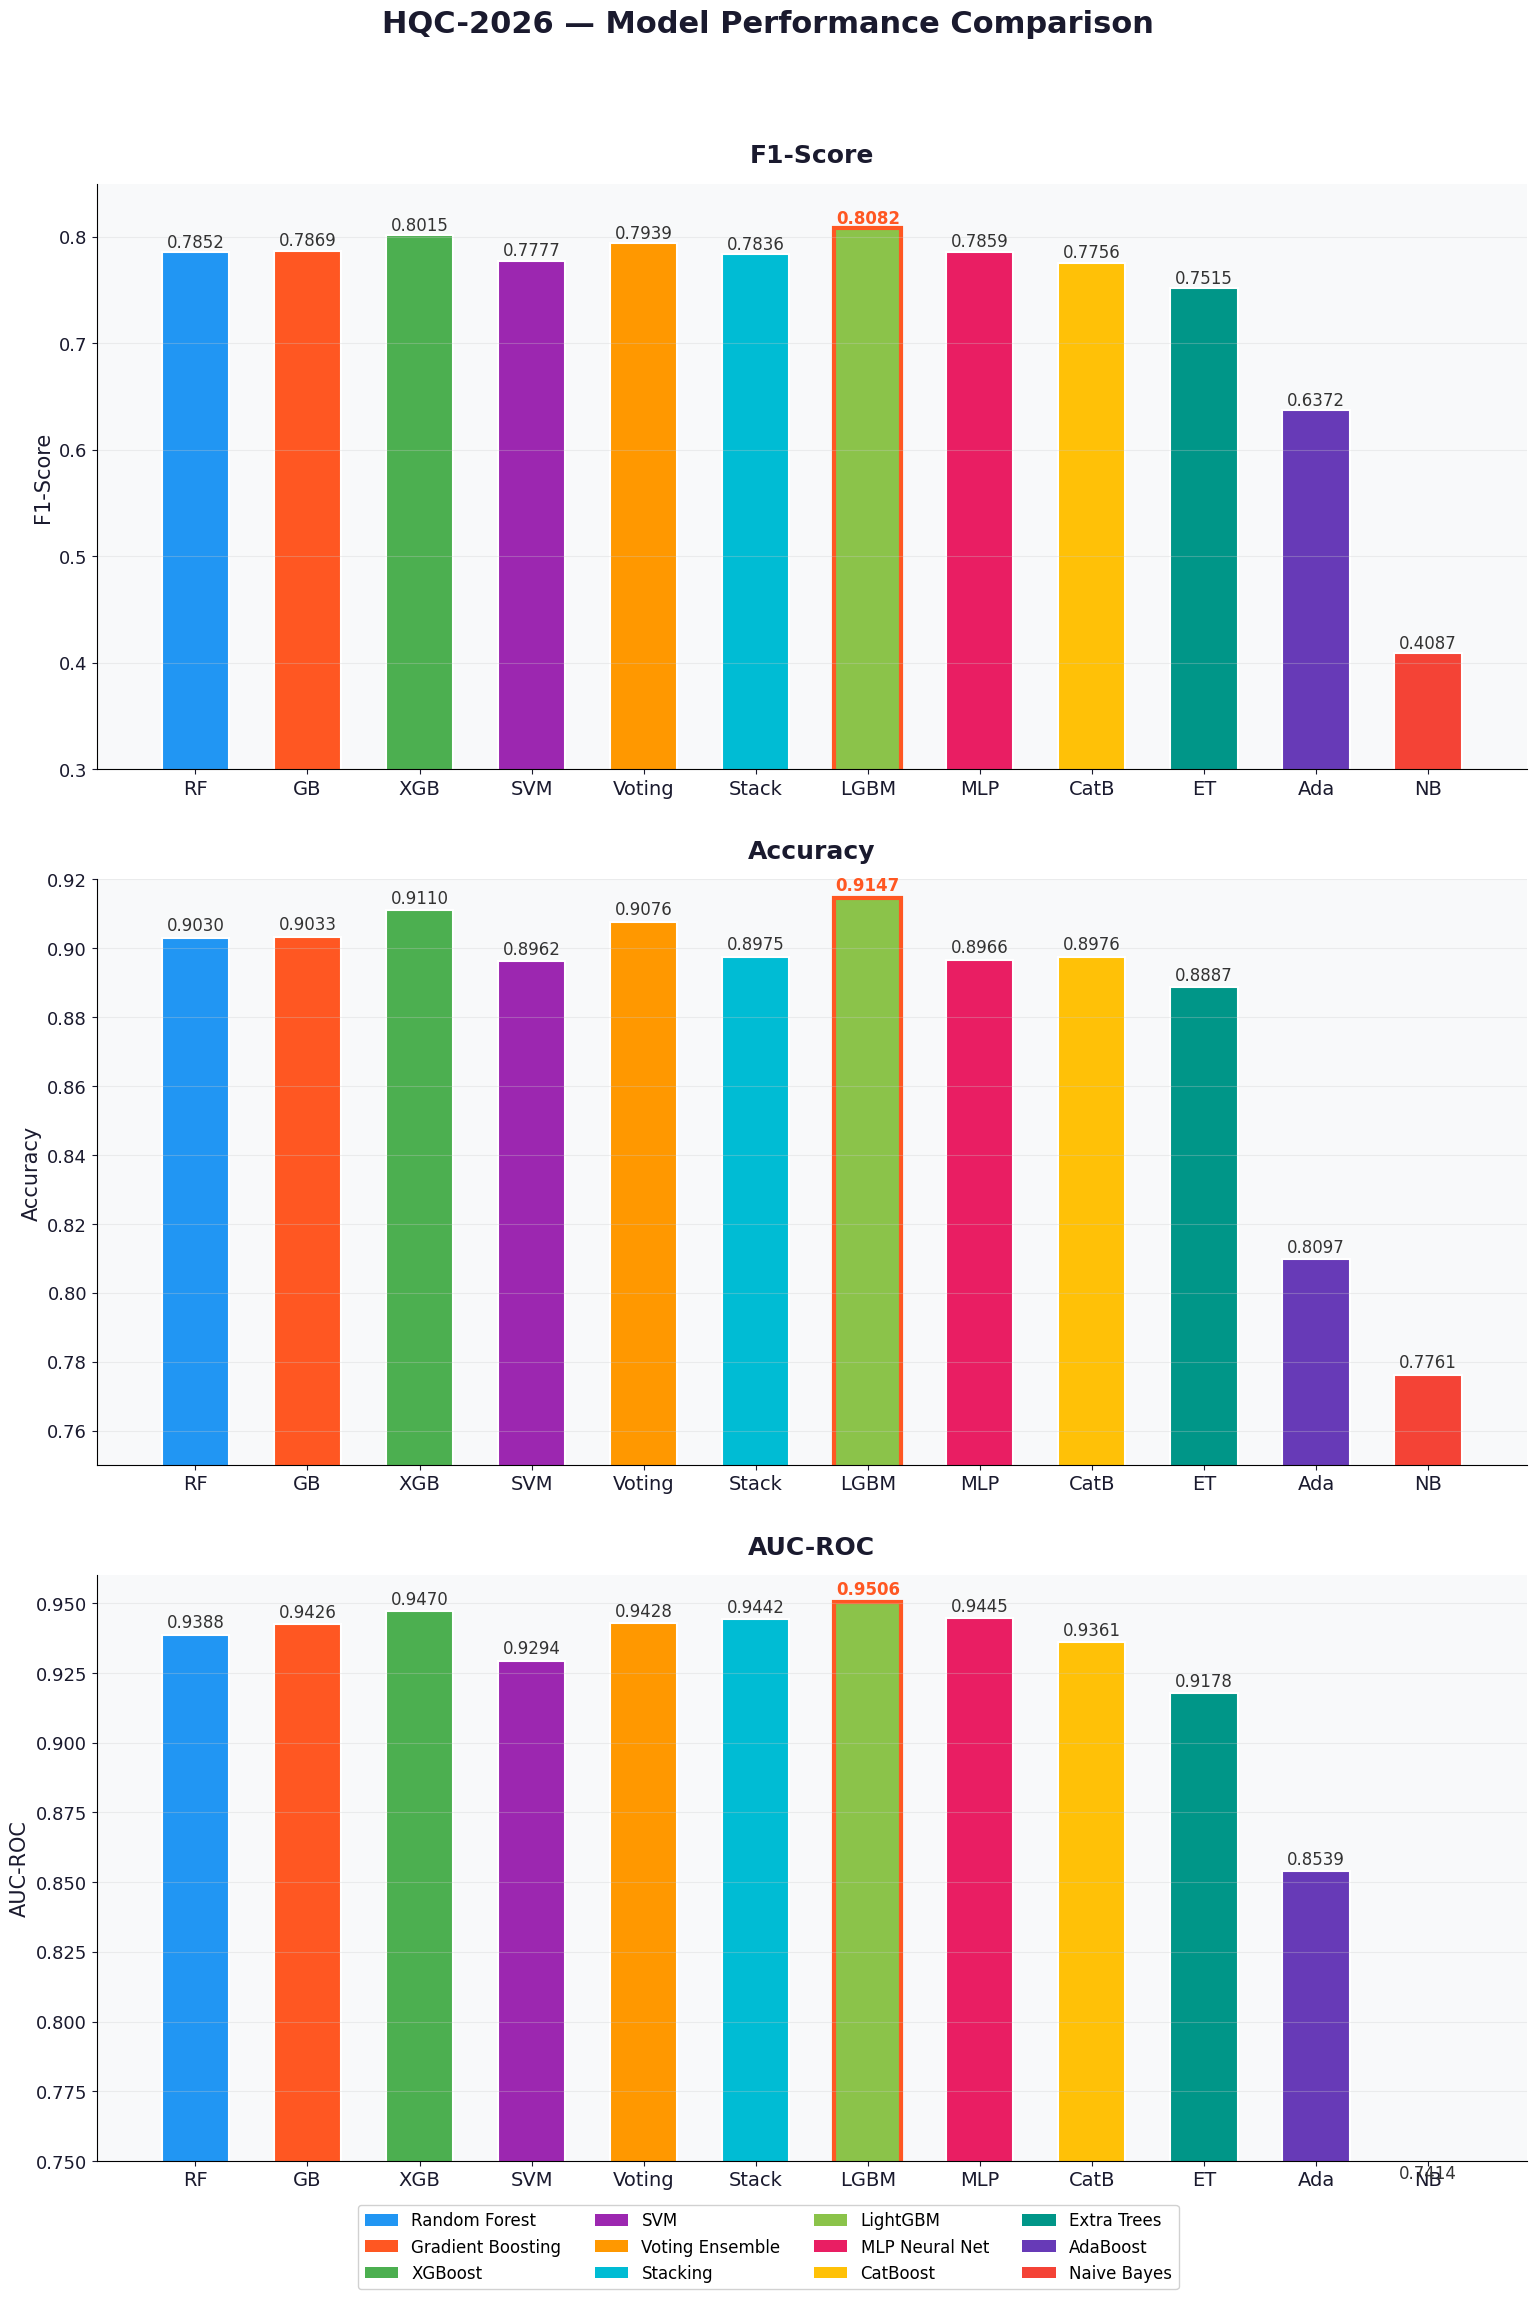

Saved: hqc2026_model_comparison.png


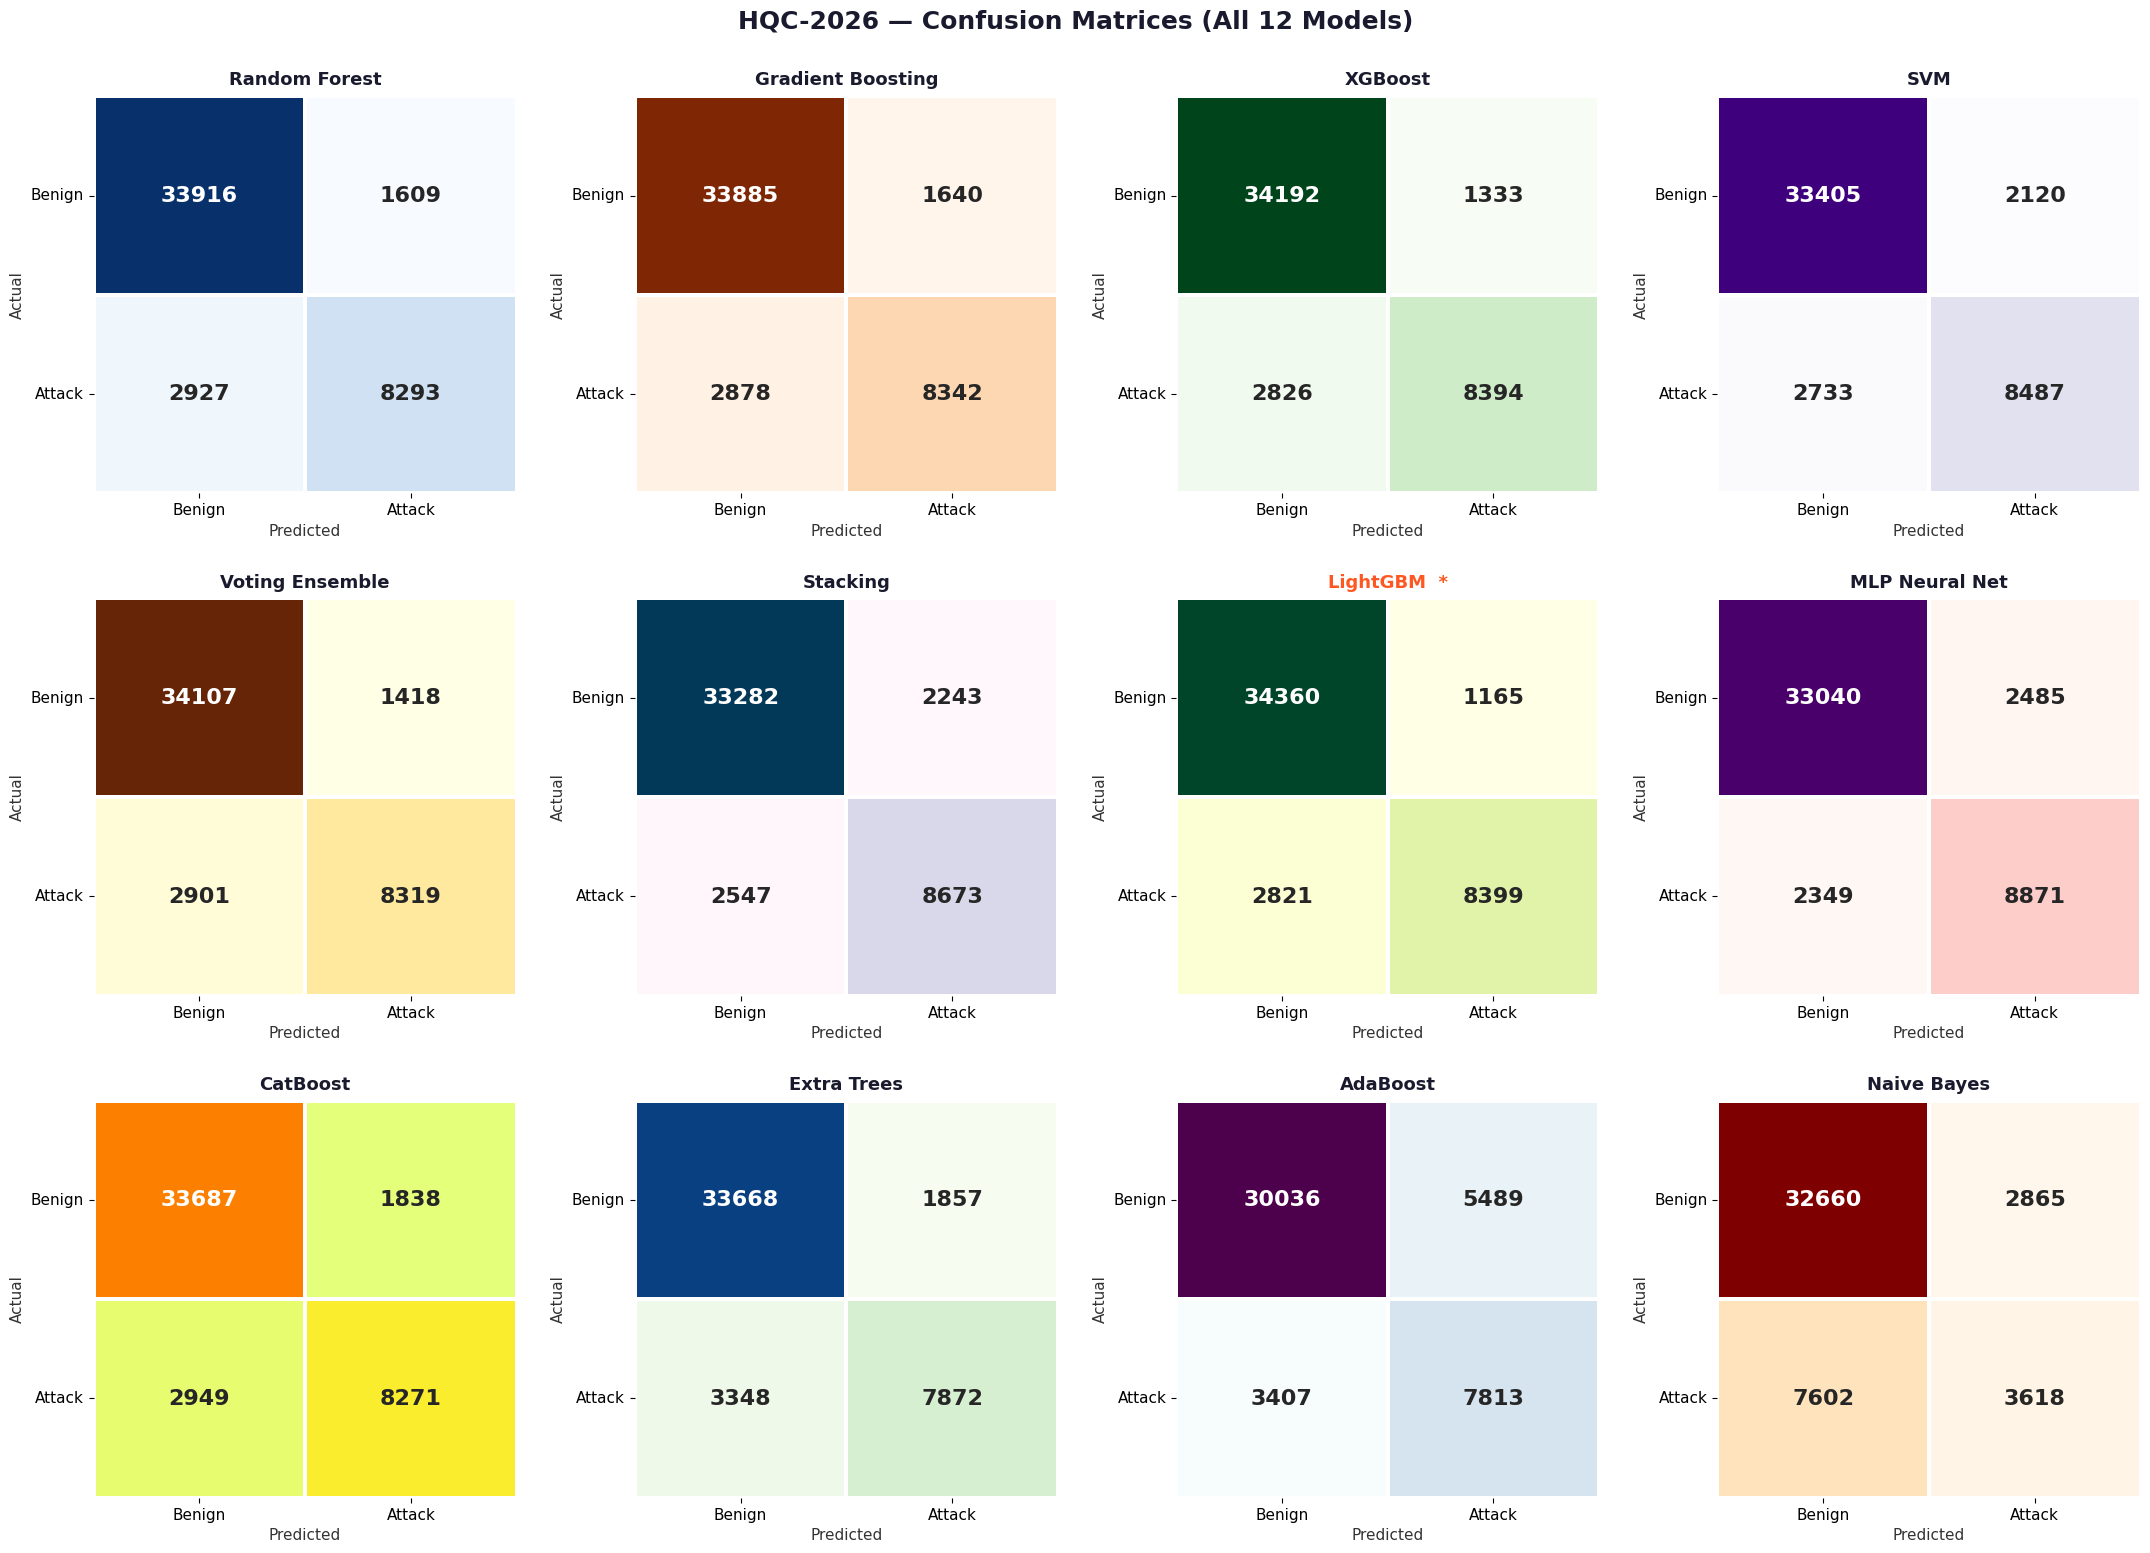

Saved: hqc2026_confusion_matrices.png


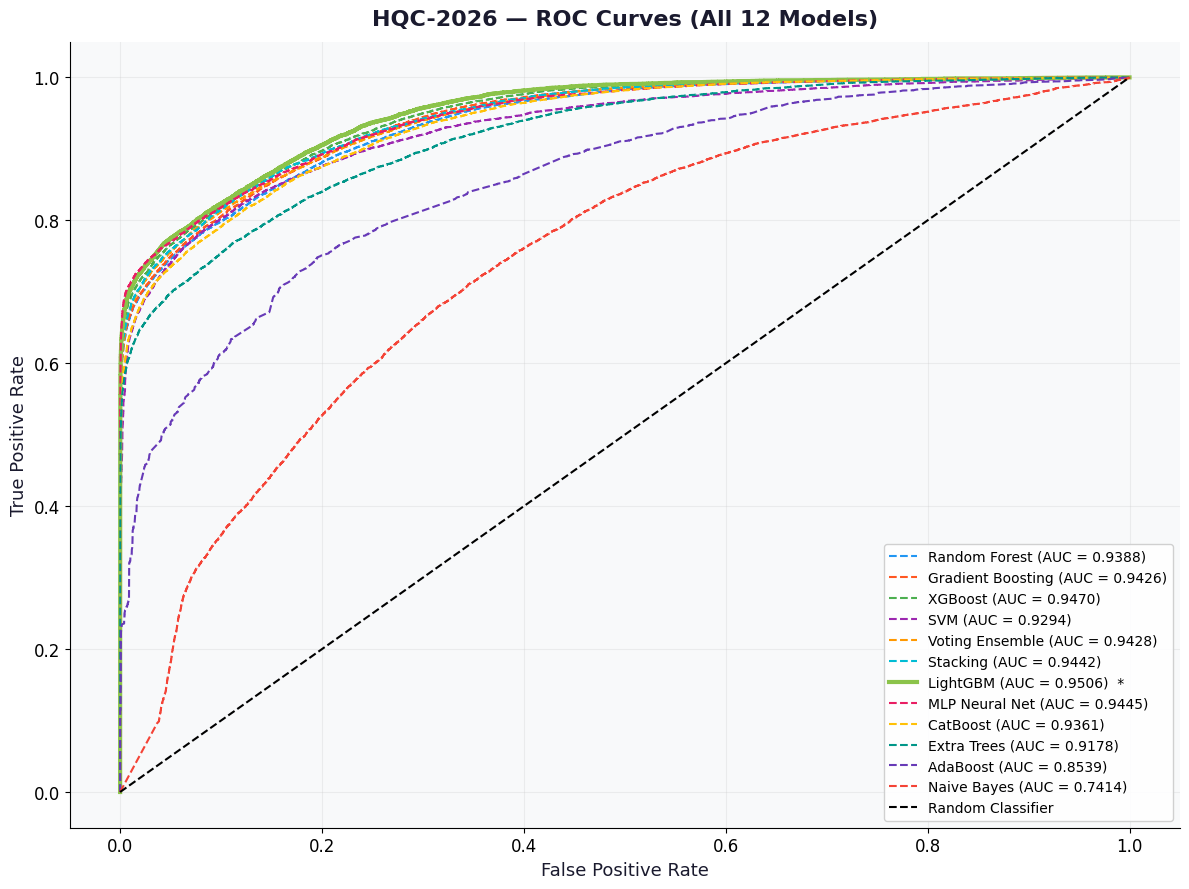

Saved: hqc2026_roc_curves.png


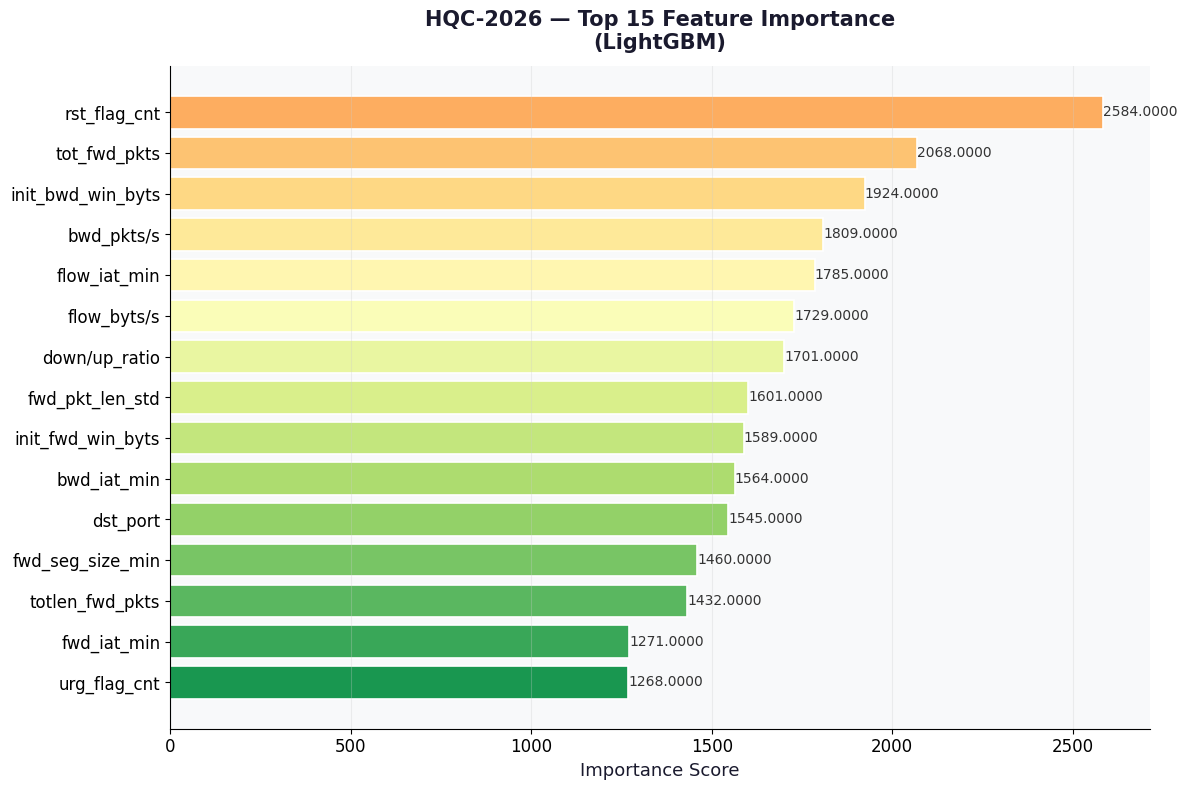

Saved: hqc2026_feature_importance.png

All visualizations saved:
  hqc2026_model_comparison.png
  hqc2026_confusion_matrices.png
  hqc2026_roc_curves.png
  hqc2026_feature_importance.png


In [ ]:
#  CELL 17 — HQC-2026: Results Visualizations

from sklearn.metrics import roc_curve, auc as sk_auc
from matplotlib.patches import Patch

model_names = list(results_hqc.keys())
f1_scores   = [results_hqc[m]["f1"]       for m in model_names]
acc_scores  = [results_hqc[m]["accuracy"] for m in model_names]
auc_scores  = [results_hqc[m]["auc"]      for m in model_names]
best_idx    = model_names.index(best_name_hqc)

model_colors = {
    "Random Forest"    : "#2196F3",
    "Gradient Boosting": "#FF5722",
    "XGBoost"          : "#4CAF50",
    "SVM"              : "#9C27B0",
    "Voting Ensemble"  : "#FF9800",
    "Stacking"         : "#00BCD4",
    "LightGBM"         : "#8BC34A",
    "MLP Neural Net"   : "#E91E63",
    "CatBoost"         : "#FFC107",
    "Extra Trees"      : "#009688",
    "AdaBoost"         : "#673AB7",
    "Naive Bayes"      : "#F44336",
}
bar_colors = [model_colors[m] for m in model_names]

short_names = [
    "RF", "GB", "XGB", "SVM",
    "Voting", "Stack", "LGBM", "MLP",
    "CatB", "ET", "Ada", "NB"
]

# ── Figure 1: F1 + Accuracy + AUC Vertical Bar Charts ─────
fig, axes = plt.subplots(3, 1, figsize=(16, 22), facecolor='white')
fig.suptitle('HQC-2026 — Model Performance Comparison',
             fontsize=22, fontweight='bold', color='#1a1a2e', y=1.01)

metrics = [
    (f1_scores,  'F1-Score',  (0.30, 0.85)),
    (acc_scores, 'Accuracy',  (0.75, 0.92)),
    (auc_scores, 'AUC-ROC',  (0.75, 0.96)),
]

for ax, (scores, label, ylim) in zip(axes, metrics):
    ax.set_facecolor('#F8F9FA')
    bars = ax.bar(short_names, scores,
                  color=bar_colors, edgecolor='white',
                  linewidth=1.5, width=0.6)
    bars[best_idx].set_edgecolor('#FF5722')
    bars[best_idx].set_linewidth(3)
    ax.set_title(f'{label}', fontsize=18, fontweight='bold',
                 color='#1a1a2e', pad=15)
    ax.set_ylabel(label, fontsize=15, color='#1a1a2e')
    ax.set_ylim(ylim)
    ax.tick_params(axis='x', labelsize=14, colors='#1a1a2e')
    ax.tick_params(axis='y', labelsize=13, colors='#1a1a2e')
    ax.grid(axis='y', alpha=0.3, color='#cccccc')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for bar, val, name in zip(bars, scores, model_names):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=12,
                color='#FF5722' if name == best_name_hqc else '#333333',
                fontweight='bold' if name == best_name_hqc else 'normal')

legend = [Patch(facecolor=model_colors[m], label=m) for m in model_names]
fig.legend(handles=legend, loc='lower center', ncol=4,
           fontsize=12, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.03))

plt.tight_layout(pad=3.0)
plt.savefig('hqc2026_model_comparison.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_model_comparison.png")

# ── Figure 2: Confusion Matrices ──────────────────────────
cmaps = [
    'Blues', 'Oranges', 'Greens', 'Purples',
    'YlOrBr', 'PuBu', 'YlGn', 'RdPu',
    'Wistia', 'GnBu', 'BuPu', 'OrRd'
]

fig, axes = plt.subplots(3, 4, figsize=(22, 16), facecolor='white')
fig.suptitle('HQC-2026 — Confusion Matrices (All 12 Models)',
             fontsize=18, fontweight='bold', color='#1a1a2e')

for idx, (name, res) in enumerate(results_hqc.items()):
    ax = axes.flatten()[idx]
    cm = confusion_matrix(y_test_hqc, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt='d', ax=ax,
                cmap=cmaps[idx],
                annot_kws={"size": 16, "weight": "bold"},
                linewidths=1.5, linecolor='white',
                cbar=False)
    title_color = '#FF5722' if name == best_name_hqc else '#1a1a2e'
    ax.set_title(f'{name}{"  *" if name == best_name_hqc else ""}',
                 fontsize=13, fontweight='bold',
                 color=title_color, pad=8)
    ax.set_xlabel('Predicted', fontsize=11, color='#333333')
    ax.set_ylabel('Actual', fontsize=11, color='#333333')
    ax.set_xticklabels(['Benign', 'Attack'], fontsize=11)
    ax.set_yticklabels(['Benign', 'Attack'], fontsize=11, rotation=0)

plt.tight_layout(pad=2.5)
plt.savefig('hqc2026_confusion_matrices.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_confusion_matrices.png")

# ── Figure 3: ROC Curves ──────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 9), facecolor='white')
ax.set_facecolor('#F8F9FA')

for name, res in results_hqc.items():
    fpr, tpr, _ = roc_curve(y_test_hqc, res["y_prob"])
    roc_auc     = sk_auc(fpr, tpr)
    lw          = 3.0 if name == best_name_hqc else 1.5
    ls          = '-'  if name == best_name_hqc else '--'
    ax.plot(fpr, tpr, color=model_colors[name],
            lw=lw, linestyle=ls,
            label=f'{name} (AUC = {roc_auc:.4f})'
                  f'{"  *" if name == best_name_hqc else ""}')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=13, color='#1a1a2e')
ax.set_ylabel('True Positive Rate', fontsize=13, color='#1a1a2e')
ax.set_title('HQC-2026 — ROC Curves (All 12 Models)',
             fontsize=16, fontweight='bold', color='#1a1a2e', pad=12)
ax.legend(loc='lower right', fontsize=10,
          framealpha=0.9, edgecolor='#cccccc')
ax.tick_params(labelsize=12)
ax.grid(alpha=0.3, color='#cccccc')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('hqc2026_roc_curves.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_roc_curves.png")

# ── Figure 4: Feature Importance (Top 15) ─────────────────
feat_names  = list(X_hqc.columns)
importances = best_res_hqc["model"].feature_importances_
indices     = np.argsort(importances)[::-1][:15]
colors_fi   = plt.cm.RdYlGn(np.linspace(0.3, 0.9, 15))[::-1]

fig, ax = plt.subplots(figsize=(12, 8), facecolor='white')
ax.set_facecolor('#F8F9FA')
bars = ax.barh([feat_names[i] for i in indices[::-1]],
               importances[indices[::-1]],
               color=colors_fi, edgecolor='white', linewidth=1.2)
ax.set_title(f'HQC-2026 — Top 15 Feature Importance\n({best_name_hqc})',
             fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Importance Score', fontsize=13, color='#1a1a2e')
ax.tick_params(labelsize=12)
ax.grid(axis='x', alpha=0.3, color='#cccccc')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, val in zip(bars, importances[indices[::-1]]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10, color='#333333')

plt.tight_layout()
plt.savefig('hqc2026_feature_importance.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_feature_importance.png")

print("\nAll visualizations saved:")
print("  hqc2026_model_comparison.png")
print("  hqc2026_confusion_matrices.png")
print("  hqc2026_roc_curves.png")
print("  hqc2026_feature_importance.png")

Adaptive Risk Engine — HQC-2026
--------------------------------------------------
Total flows    : 46,745
LOW  Risk      : 34,580  (74.0%)  -> AES-256
MEDIUM Risk    : 3,518  (7.5%)  -> AES-256 + Monitor
HIGH Risk      : 8,647  (18.5%)  -> BB84 QKD
Overhead Saved : 81.5% vs naive full-QKD

BB84 QKD Simulation — HQC-2026
--------------------------------------------------
Clean Channel        | Eve: 0.00 | QBER: 0.0000 ± 0.0000 | Secure: 100.0%
Low Eavesdrop        | Eve: 0.10 | QBER: 0.0246 ± 0.0142 | Secure: 100.0%
High Eavesdrop       | Eve: 0.75 | QBER: 0.1818 ± 0.0318 | Secure: 1.0%


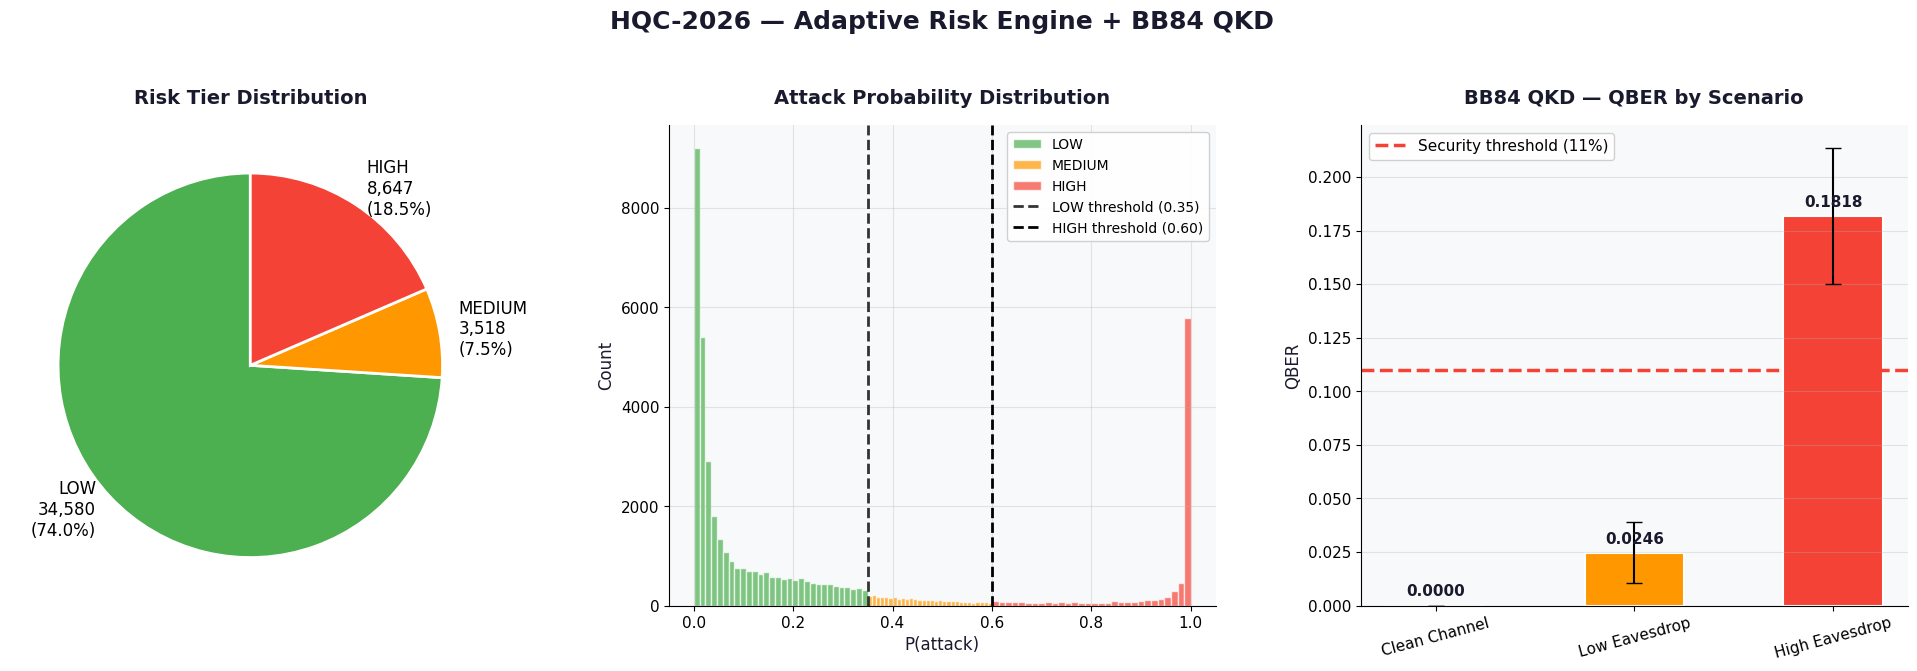

Saved: hqc2026_risk_qkd.png


In [ ]:
#  CELL 18 — HQC-2026: Adaptive Risk Engine + BB84 QKD

print(f"Adaptive Risk Engine — {CURRENT_DATASET}")
print("-" * 50)

risk_probs = best_res_hqc["y_prob"]

LOW_THRESHOLD  = 0.35
HIGH_THRESHOLD = best_t_hqc

risk_tiers = []
for p in risk_probs:
    if p < LOW_THRESHOLD:
        risk_tiers.append("LOW")
    elif p < HIGH_THRESHOLD:
        risk_tiers.append("MEDIUM")
    else:
        risk_tiers.append("HIGH")

risk_df = pd.DataFrame({
    "attack_prob": risk_probs,
    "risk_tier"  : risk_tiers,
    "true_label" : y_test_hqc
})

n_total  = len(risk_df)
n_low    = (risk_df["risk_tier"] == "LOW").sum()
n_medium = (risk_df["risk_tier"] == "MEDIUM").sum()
n_high   = (risk_df["risk_tier"] == "HIGH").sum()
qkd_pct  = n_high / n_total * 100

print(f"Total flows    : {n_total:,}")
print(f"LOW  Risk      : {n_low:,}  ({n_low/n_total*100:.1f}%)  -> AES-256")
print(f"MEDIUM Risk    : {n_medium:,}  ({n_medium/n_total*100:.1f}%)  -> AES-256 + Monitor")
print(f"HIGH Risk      : {n_high:,}  ({n_high/n_total*100:.1f}%)  -> BB84 QKD")
print(f"Overhead Saved : {100 - qkd_pct:.1f}% vs naive full-QKD")

# ── BB84 QKD Simulation ───────────────────────────────────
print(f"\nBB84 QKD Simulation — {CURRENT_DATASET}")
print("-" * 50)

qkd_scenarios = [
    ("Clean Channel",  0.00),
    ("Low Eavesdrop",  0.10),
    ("High Eavesdrop", 0.75),
]

qkd_results_hqc = {}
for scenario, eve_prob in qkd_scenarios:
    sessions = [BB84Simulation(256, eve_prob).run() for _ in range(100)]
    qkd_results_hqc[scenario] = {
        "eve_prob"  : eve_prob,
        "qber_mean" : float(np.mean([s["qber"]   for s in sessions])),
        "qber_std"  : float(np.std([s["qber"]    for s in sessions])),
        "pct_secure": float(np.mean([s["secure"] for s in sessions]) * 100),
    }
    r = qkd_results_hqc[scenario]
    print(f"{scenario:<20} | Eve: {eve_prob:.2f} | "
          f"QBER: {r['qber_mean']:.4f} ± {r['qber_std']:.4f} | "
          f"Secure: {r['pct_secure']:.1f}%")

# ── Visualization ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
fig.suptitle(f'HQC-2026 — Adaptive Risk Engine + BB84 QKD',
             fontsize=18, fontweight='bold', color='#1a1a2e')

# Plot 1 — Risk Tier Pie
ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
sizes  = [n_low, n_medium, n_high]
labels = [f'LOW\n{n_low:,}\n({n_low/n_total*100:.1f}%)',
          f'MEDIUM\n{n_medium:,}\n({n_medium/n_total*100:.1f}%)',
          f'HIGH\n{n_high:,}\n({n_high/n_total*100:.1f}%)']
colors = ['#4CAF50', '#FF9800', '#F44336']
ax1.pie(sizes, labels=labels, colors=colors,
        startangle=90, textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax1.set_title('Risk Tier Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)

# Plot 2 — Attack Probability Distribution
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
ax2.hist(risk_df[risk_df["risk_tier"]=="LOW"]["attack_prob"],
         bins=30, alpha=0.7, color='#4CAF50', label='LOW', edgecolor='white')
ax2.hist(risk_df[risk_df["risk_tier"]=="MEDIUM"]["attack_prob"],
         bins=30, alpha=0.7, color='#FF9800', label='MEDIUM', edgecolor='white')
ax2.hist(risk_df[risk_df["risk_tier"]=="HIGH"]["attack_prob"],
         bins=30, alpha=0.7, color='#F44336', label='HIGH', edgecolor='white')
ax2.axvline(LOW_THRESHOLD,  color='#333333', linestyle='--',
            lw=2, label=f'LOW threshold ({LOW_THRESHOLD})')
ax2.axvline(HIGH_THRESHOLD, color='#000000', linestyle='--',
            lw=2, label=f'HIGH threshold ({HIGH_THRESHOLD:.2f})')
ax2.set_title('Attack Probability Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)
ax2.set_xlabel('P(attack)', fontsize=12, color='#1a1a2e')
ax2.set_ylabel('Count', fontsize=12, color='#1a1a2e')
ax2.tick_params(labelsize=11)
ax2.legend(fontsize=10, framealpha=0.9)
ax2.grid(alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Plot 3 — QBER by Scenario
ax3 = axes[2]
ax3.set_facecolor('#F8F9FA')
scenario_names = list(qkd_results_hqc.keys())
qber_means     = [qkd_results_hqc[s]["qber_mean"] for s in scenario_names]
qber_stds      = [qkd_results_hqc[s]["qber_std"]  for s in scenario_names]
bar_cols       = ['#4CAF50', '#FF9800', '#F44336']
bars = ax3.bar(scenario_names, qber_means, color=bar_cols,
               yerr=qber_stds, capsize=6,
               edgecolor='white', linewidth=1.5, width=0.5)
ax3.axhline(0.11, color='#F44336', linestyle='--',
            lw=2.5, label='Security threshold (11%)')
ax3.set_title('BB84 QKD — QBER by Scenario', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=15)
ax3.set_ylabel('QBER', fontsize=12, color='#1a1a2e')
ax3.tick_params(axis='x', labelsize=11, rotation=15)
ax3.tick_params(axis='y', labelsize=11)
ax3.legend(fontsize=11, framealpha=0.9)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
for bar, val in zip(bars, qber_means):
    ax3.text(bar.get_x() + bar.get_width()/2, val + 0.003,
             f'{val:.4f}', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='#1a1a2e')

plt.tight_layout(pad=2.5)
plt.savefig('hqc2026_risk_qkd.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_risk_qkd.png")

SHAP Explainability — HQC-2026
--------------------------------------------------


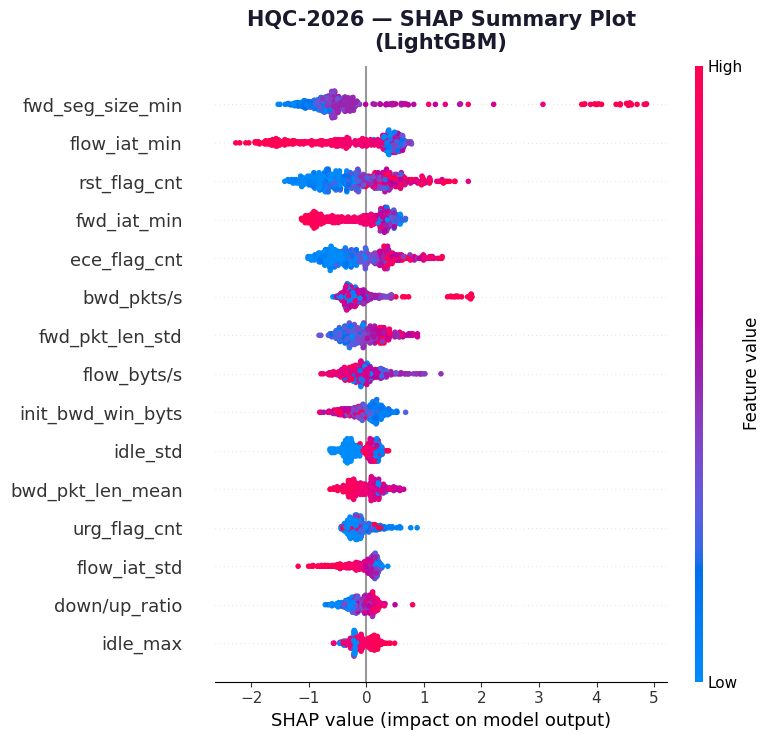

Saved: hqc2026_shap_summary.png


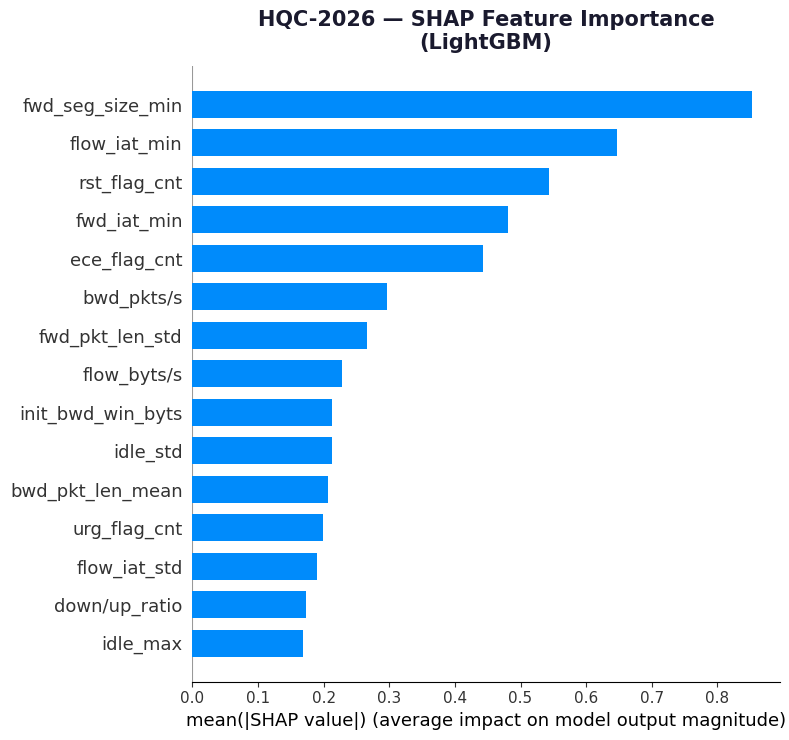

Saved: hqc2026_shap_importance.png

Top 10 Most Important Features (LightGBM):
          Feature  SHAP_Value
 fwd_seg_size_min    0.852613
     flow_iat_min    0.646988
     rst_flag_cnt    0.543002
      fwd_iat_min    0.480703
     ece_flag_cnt    0.442446
       bwd_pkts/s    0.296818
  fwd_pkt_len_std    0.266764
      flow_byts/s    0.227960
init_bwd_win_byts    0.213134
         idle_std    0.212550


In [ ]:
#  CELL 19 — HQC-2026: SHAP XAI

print(f"SHAP Explainability — {CURRENT_DATASET}")
print("-" * 50)

explainer   = shap.TreeExplainer(best_res_hqc["model"])
X_test_df   = pd.DataFrame(X_test_hqc, columns=X_hqc.columns)
shap_sample = X_test_df.sample(500, random_state=42)
shap_values = explainer.shap_values(shap_sample)

if isinstance(shap_values, list):
    shap_vals = shap_values[1]
else:
    shap_vals = shap_values

# Figure 1: SHAP Summary Plot
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(shap_vals, shap_sample,
                  plot_type="dot",
                  max_display=15,
                  show=False)
plt.title(f'HQC-2026 — SHAP Summary Plot\n({best_name_hqc})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('hqc2026_shap_summary.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_shap_summary.png")

# Figure 2: SHAP Feature Importance Bar
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(shap_vals, shap_sample,
                  plot_type="bar",
                  max_display=15,
                  show=False)
plt.title(f'HQC-2026 — SHAP Feature Importance\n({best_name_hqc})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('hqc2026_shap_importance.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_shap_importance.png")

shap_mean   = np.abs(shap_vals).mean(axis=0)
feature_imp_hqc = pd.DataFrame({
    'Feature'   : X_hqc.columns,
    'SHAP_Value': shap_mean
}).sort_values('SHAP_Value', ascending=False).head(10)

print(f"\nTop 10 Most Important Features ({best_name_hqc}):")
print(feature_imp_hqc.to_string(index=False))

In [ ]:
#  CELL — HQC-2026: Multiclass Attack-Type Model (Secondary)

print(f"Multiclass Attack-Type Classification — {CURRENT_DATASET}")
print("-" * 50)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter
from sklearn.metrics import classification_report, accuracy_score as acc_score, f1_score as f1_sc

# Recover the original 14-class label for the surviving (deduped) rows in
# X_hqc, then merge ultra-rare classes (<100 samples) into 'Rare_Attack'.
attack_type_full = df_hqc.loc[X_hqc.index, cfg["label_col"]]
rare_classes = attack_type_full.value_counts()[attack_type_full.value_counts() < 100].index.tolist()
print(f"Merging into 'Rare_Attack' (<100 samples): {rare_classes}")
y_mc_full_hqc = attack_type_full.where(~attack_type_full.isin(rare_classes), 'Rare_Attack')

# Held-out test set from the ORIGINAL (untouched) 14-class distribution
X_train_mc_hqc, X_test_mc_hqc, y_train_mc_hqc, y_test_mc_hqc = train_test_split(
    X_hqc, y_mc_full_hqc, test_size=0.20, stratify=y_mc_full_hqc, random_state=42
)
print(f"Train: {X_train_mc_hqc.shape} | Test: {X_test_mc_hqc.shape} (kept ORIGINAL distribution)")

# Hybrid resampling on TRAIN only (same protocol as X-IIoTID's multiclass model)
UNDER_CAP, OVER_FLOOR, MAX_MULT = 15000, 3000, 10
train_counts = Counter(y_train_mc_hqc)
print(f"\nTrain class counts BEFORE resampling:")
for k, v in sorted(train_counts.items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")

under_strategy = {c: UNDER_CAP for c, n in train_counts.items() if n > UNDER_CAP}
over_strategy  = {c: min(OVER_FLOOR, n * MAX_MULT) for c, n in train_counts.items() if n < OVER_FLOOR}

resample_pipe = ImbPipeline(steps=[
    ('under', RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
              if under_strategy else 'passthrough'),
    ('over',  SMOTE(sampling_strategy=over_strategy, random_state=42, k_neighbors=5)
              if over_strategy else 'passthrough'),
])
X_train_mc_hqc_bal, y_train_mc_hqc_bal = resample_pipe.fit_resample(X_train_mc_hqc, y_train_mc_hqc)

print(f"\nTrain class counts AFTER hybrid resampling:")
for k, v in sorted(Counter(y_train_mc_hqc_bal).items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")
print(f"\nBalanced train shape: {X_train_mc_hqc_bal.shape}")

# Train a multiclass model (RandomForest — fast, interpretable, no scaling needed)
mc_model_hqc = RandomForestClassifier(n_estimators=300, max_depth=20,
                                       random_state=42, n_jobs=-1)
mc_model_hqc.fit(X_train_mc_hqc_bal, y_train_mc_hqc_bal)
y_pred_mc_hqc = mc_model_hqc.predict(X_test_mc_hqc)

print(f"\nAccuracy      : {acc_score(y_test_mc_hqc, y_pred_mc_hqc):.4f}")
print(f"Macro F1      : {f1_sc(y_test_mc_hqc, y_pred_mc_hqc, average='macro'):.4f}")
print(f"Weighted F1   : {f1_sc(y_test_mc_hqc, y_pred_mc_hqc, average='weighted'):.4f}")
print(f"\nPer-class report:")
print(classification_report(y_test_mc_hqc, y_pred_mc_hqc))

Multiclass Attack-Type Classification — HQC-2026
--------------------------------------------------
Merging into 'Rare_Attack' (<100 samples): ['SQL Injection']
Train: (186976, 78) | Test: (46745, 78) (kept ORIGINAL distribution)

Train class counts BEFORE resampling:
  Benign: 142096
  Bot: 16181
  Infilteration: 12496
  FTP-BruteForce: 4661
  SSH-Bruteforce: 4353
  DoS attacks-SlowHTTPTest: 2163
  DoS attacks-Slowloris: 1959
  DDOS attack-HOIC: 1074
  DDOS attack-LOIC-UDP: 788
  DoS attacks-GoldenEye: 518
  Brute Force -Web: 326
  DoS attacks-Hulk: 158
  Brute Force -XSS: 142
  Rare_Attack: 61

Train class counts AFTER hybrid resampling:
  Benign: 15000
  Bot: 15000
  Infilteration: 12496
  FTP-BruteForce: 4661
  SSH-Bruteforce: 4353
  Brute Force -Web: 3000
  DDOS attack-HOIC: 3000
  DDOS attack-LOIC-UDP: 3000
  DoS attacks-GoldenEye: 3000
  DoS attacks-SlowHTTPTest: 3000
  DoS attacks-Slowloris: 3000
  DoS attacks-Hulk: 1580
  Brute Force -XSS: 1420
  Rare_Attack: 610

Balanced tra

Attack-Type-Aware Response Engine — HQC-2026
--------------------------------------------------
HIGH-risk flows analyzed: 8,647

Predicted attack-type breakdown (HIGH-risk flows only):
  Bot                      :   3,801 (44.0%)
  FTP-BruteForce           :   1,180 (13.6%)
  SSH-Bruteforce           :   1,107 (12.8%)
  Infilteration            :     890 (10.3%)
  DoS attacks-SlowHTTPTest :     535 (6.2%)
  DoS attacks-Slowloris    :     467 (5.4%)
  DDOS attack-HOIC         :     279 (3.2%)
  DDOS attack-LOIC-UDP     :     197 (2.3%)
  DoS attacks-GoldenEye    :      72 (0.8%)
  Benign                   :      39 (0.5%)
  DoS attacks-Hulk         :      39 (0.5%)
  Brute Force -Web         :      24 (0.3%)
  Brute Force -XSS         :      17 (0.2%)

Recommended action breakdown:
  Isolate host + block C2 traffic              :   3,801 (44.0%)
  Account lockout / IP block                   :   2,311 (26.7%)
  Rate-limit / traffic shaping                 :   1,113 (12.9%)
  Isolate hos

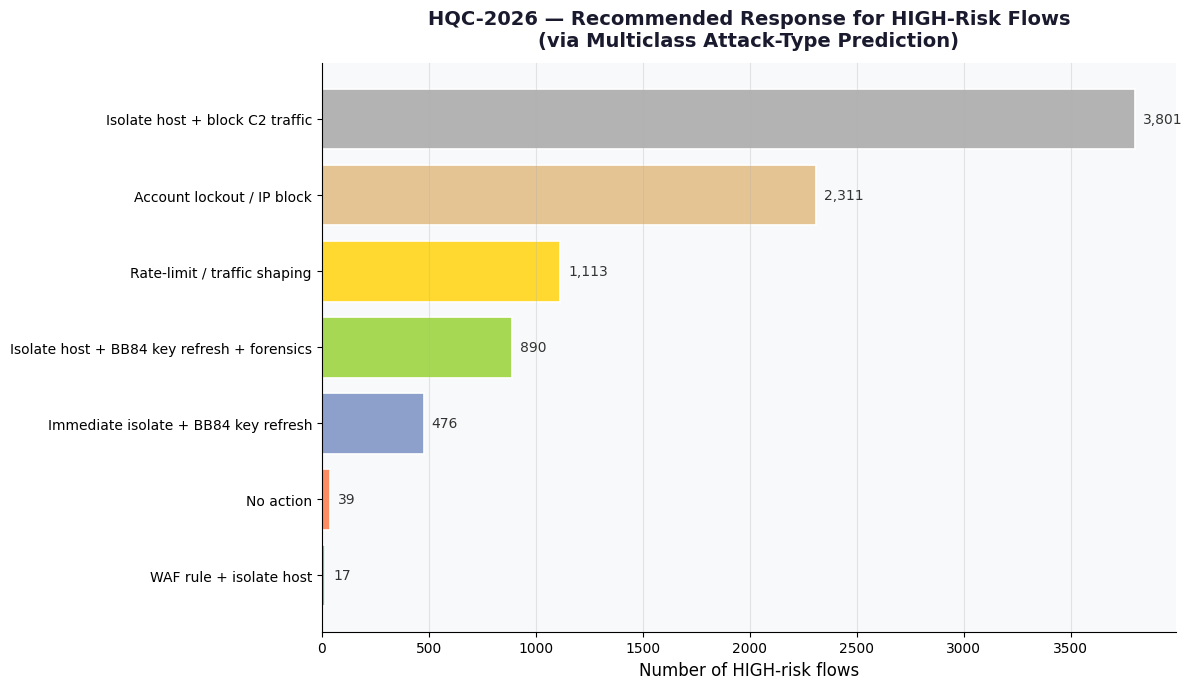

Saved: hqc2026_response_recommendation.png


In [ ]:
#  CELL 21B — HQC-2026: Attack-Type-Aware Response Recommendation

print(f"Attack-Type-Aware Response Engine — {CURRENT_DATASET}")
print("-" * 50)

# Response mapping — CSE-CIC-IDS2018-style attack categories.
# BB84 key refresh reserved for stealthy/high-impact classes (Infilteration,
# large-scale DDoS) where a compromised channel key would matter most.
response_map = {
    "Benign"                  : "No action",
    "Bot"                     : "Isolate host + block C2 traffic",
    "Infilteration"           : "Isolate host + BB84 key refresh + forensics",
    "FTP-BruteForce"          : "Account lockout / IP block",
    "SSH-Bruteforce"          : "Account lockout / IP block",
    "DoS attacks-SlowHTTPTest": "Rate-limit / traffic shaping",
    "DoS attacks-Slowloris"   : "Rate-limit / traffic shaping",
    "DoS attacks-GoldenEye"   : "Rate-limit / traffic shaping",
    "DoS attacks-Hulk"        : "Rate-limit / traffic shaping",
    "DDOS attack-HOIC"        : "Immediate isolate + BB84 key refresh",
    "DDOS attack-LOIC-UDP"    : "Immediate isolate + BB84 key refresh",
    "Brute Force -Web"        : "Account lockout / IP block",
    "Brute Force -XSS"        : "WAF rule + isolate host",
    "Rare_Attack"             : "Isolate host + manual review",
}

# Only run the multiclass model on flows the binary risk engine flagged HIGH
high_mask  = (risk_df["risk_tier"] == "HIGH").values
X_high     = X_test_hqc[high_mask]
pred_types = mc_model_hqc.predict(X_high)

response_df = pd.DataFrame({
    "attack_type"       : pred_types,
    "recommended_action": [response_map.get(t, "Isolate host + manual review") for t in pred_types],
})

action_counts = response_df["recommended_action"].value_counts()
type_counts   = response_df["attack_type"].value_counts()

print(f"HIGH-risk flows analyzed: {len(response_df):,}\n")
print("Predicted attack-type breakdown (HIGH-risk flows only):")
for t, c in type_counts.items():
    print(f"  {t:<25}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

print(f"\nRecommended action breakdown:")
for a, c in action_counts.items():
    print(f"  {a:<45}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

# Visualization
fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')
ax.set_facecolor('#F8F9FA')
colors_resp = plt.cm.Set2(np.linspace(0, 1, len(action_counts)))
bars = ax.barh(action_counts.index[::-1], action_counts.values[::-1],
               color=colors_resp, edgecolor='white', linewidth=1.2)
ax.set_title('HQC-2026 — Recommended Response for HIGH-Risk Flows\n(via Multiclass Attack-Type Prediction)',
             fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Number of HIGH-risk flows', fontsize=12)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, val in zip(bars, action_counts.values[::-1]):
    ax.text(bar.get_width() + max(action_counts.values)*0.01, bar.get_y()+bar.get_height()/2,
            f'{val:,}', va='center', fontsize=10, color='#333333')

plt.tight_layout()
plt.savefig('hqc2026_response_recommendation.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_response_recommendation.png")

# For Dashboard

In [ ]:
export_app_artifacts(
    dataset_key = "HQC2026",
    country     = cfg["country"],
    X_test_raw  = X_test_hqc,
    y_test      = y_test_hqc,
    results     = results_hqc,
    best_name   = best_name_hqc,
    models_dict = get_models(),
    mc_model    = mc_model_hqc,
    X_test_mc   = X_test_mc,
    y_test_mc   = y_test_mc,
    response_map= response_map,
)

Saved: app_artifacts_HQC2026.pkl (459.3 MB)  |  sample=2000 rows, best_model=LightGBM, needs_scale=False


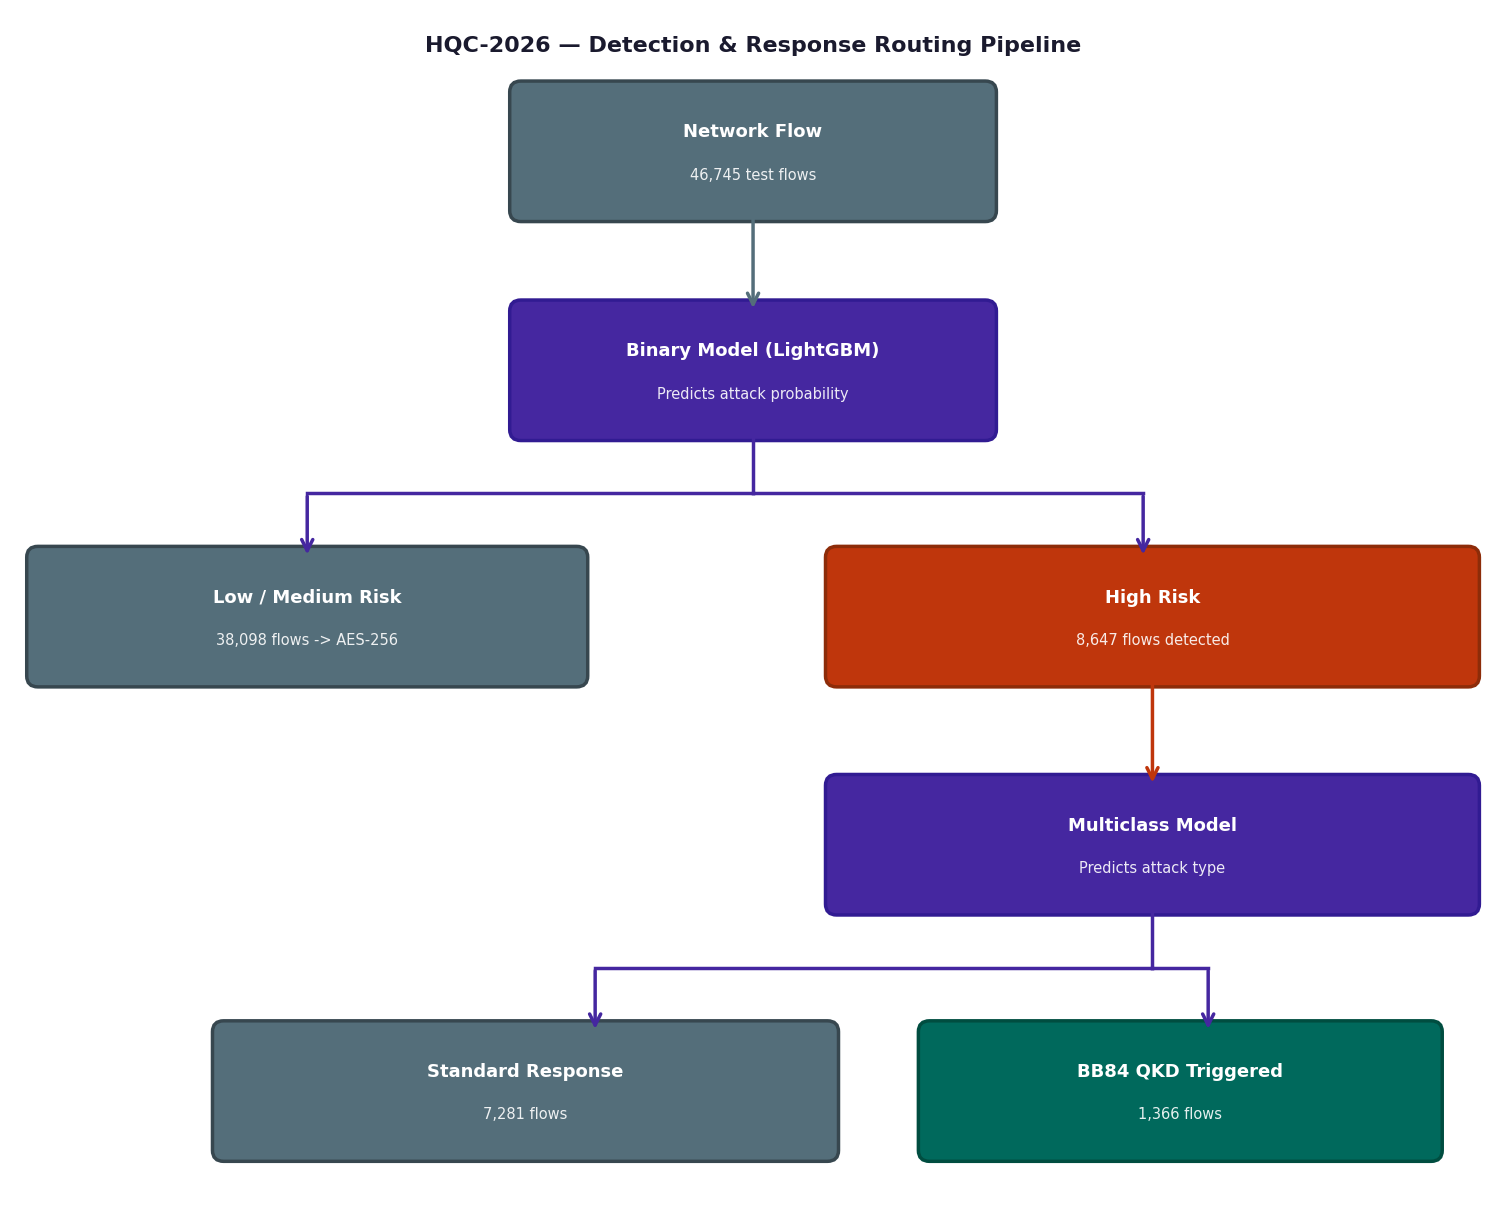

Saved: hqc2026_detection_routing_pipeline.png


In [ ]:
#  CELL 21C — HQC-2026: Detection & Response Routing Pipeline Diagram

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 12), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(2.4, 15.4)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.66, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.30, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3, alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

ax.text(8, 15.0, 'HQC-2026 — Detection & Response Routing Pipeline',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

# Row1 — Network flow (gray)
draw_box(5.5, 13.2, 5.0, 1.3, 'Network Flow', f'{n_total:,} test flows',
         '#546E7A', '#37474F')
draw_arrow(8.0, 13.2, 8.0, 12.1, '#546E7A')

# Row2 — Binary model (purple)
draw_box(5.5, 10.8, 5.0, 1.3, f'Binary Model ({best_name_hqc})', 'Predicts attack probability',
         '#4527A0', '#311B92')

ax.plot([8.0, 8.0], [10.8, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 3.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 12.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(3.2, 10.1, 3.2, 9.4, '#4527A0')
draw_arrow(12.2, 10.1, 12.2, 9.4, '#4527A0')

# Row3 — Low/Medium (gray, left) + High (coral, right)
draw_box(0.3, 8.1, 5.8, 1.3, 'Low / Medium Risk', f'{n_low+n_medium:,} flows -> AES-256',
         '#546E7A', '#37474F')
draw_box(8.9, 8.1, 6.8, 1.3, 'High Risk', f'{n_high:,} flows detected',
         '#BF360C', '#8D2C09')
draw_arrow(12.3, 8.1, 12.3, 6.9, '#BF360C')

# Row4 — Multiclass model (purple, under High)
draw_box(8.9, 5.6, 6.8, 1.3, 'Multiclass Model', 'Predicts attack type',
         '#4527A0', '#311B92')

ax.plot([12.3, 12.3], [5.6, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 6.3], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 12.9], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(6.3, 4.9, 6.3, 4.2, '#4527A0')
draw_arrow(12.9, 4.9, 12.9, 4.2, '#4527A0')

# Row5 — Standard response (gray, left) + BB84 triggered (teal, right)
other_count = len(response_df) - (response_df['recommended_action'].str.contains('BB84').sum())
bb84_count  = response_df['recommended_action'].str.contains('BB84').sum()
draw_box(2.3, 2.9, 6.5, 1.3, 'Standard Response', f'{other_count:,} flows',
         '#546E7A', '#37474F')
draw_box(9.9, 2.9, 5.4, 1.3, 'BB84 QKD Triggered', f'{bb84_count:,} flows',
         '#00695C', '#004D40')

plt.tight_layout(pad=0.5)
plt.savefig('hqc2026_detection_routing_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: hqc2026_detection_routing_pipeline.png')

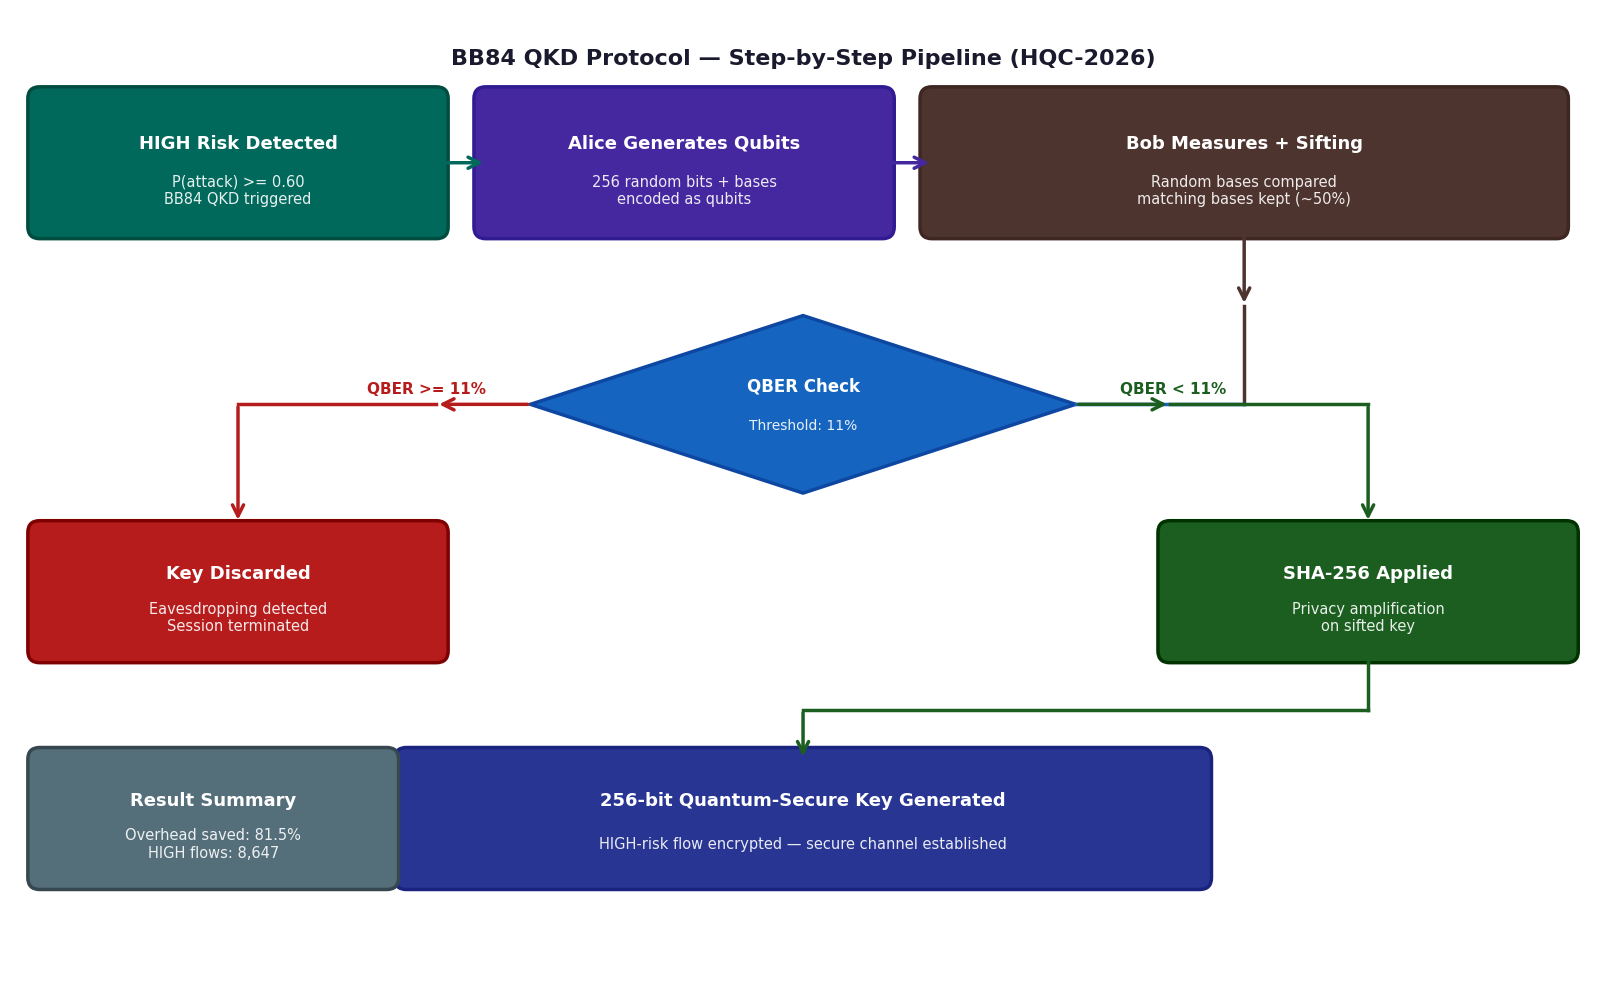

Saved: hqc2026_bb84_pipeline.png


In [ ]:
#  CELL 20 — HQC-2026: BB84 Pipeline

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 10), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.12",
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.65, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.28, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3,
            multialignment='center', alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

def draw_diamond(cx, cy, w, h, title, subtitle, fc, ec):
    dx = [cx, cx+w/2, cx, cx-w/2]
    dy = [cy+h/2, cy, cy-h/2, cy]
    ax.add_patch(plt.Polygon(list(zip(dx, dy)),
                 facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2))
    ax.text(cx, cy+0.18, title, ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', zorder=3)
    ax.text(cx, cy-0.22, subtitle, ha='center', va='center',
            fontsize=10, color='white', zorder=3, alpha=0.9)

ax.text(8, 9.5, 'BB84 QKD Protocol — Step-by-Step Pipeline (HQC-2026)',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

# Step 1 — Teal
draw_box(0.3, 7.8, 4.0, 1.3,
         'HIGH Risk Detected',
         f'P(attack) >= {best_t_hqc:.2f}\nBB84 QKD triggered',
         '#00695C', '#004D40')
draw_arrow(4.3, 8.45, 4.8, 8.45, '#00695C')

# Step 2 — Deep Purple
draw_box(4.8, 7.8, 4.0, 1.3,
         'Alice Generates Qubits',
         '256 random bits + bases\nencoded as qubits',
         '#4527A0', '#311B92')
draw_arrow(8.8, 8.45, 9.3, 8.45, '#4527A0')

# Step 3 — Brown
draw_box(9.3, 7.8, 6.3, 1.3,
         'Bob Measures + Sifting',
         'Random bases compared\nmatching bases kept (~50%)',
         '#4E342E', '#3E2723')
draw_arrow(12.45, 7.8, 12.45, 7.0, '#4E342E')

# QBER Diamond — Dark Blue
draw_diamond(8.0, 6.0, 5.5, 1.8,
             'QBER Check',
             'Threshold: 11%',
             '#1565C0', '#0D47A1')

ax.plot([12.45, 12.45], [7.0, 6.0], color='#4E342E', lw=2.5, zorder=4)
ax.plot([12.45, 10.75], [6.0, 6.0], color='#1565C0', lw=2.5, zorder=4)

ax.text(4.8, 6.15, 'QBER >= 11%', ha='right', va='center',
        fontsize=11, fontweight='bold', color='#B71C1C')
ax.text(11.2, 6.15, 'QBER < 11%', ha='left', va='center',
        fontsize=11, fontweight='bold', color='#1B5E20')

# Left — Key Discard (Dark Red)
draw_arrow(5.25, 6.0, 4.3, 6.0, '#B71C1C')
ax.plot([4.3, 2.3], [6.0, 6.0], color='#B71C1C', lw=2.5, zorder=4)
draw_arrow(2.3, 6.0, 2.3, 4.8, '#B71C1C')
draw_box(0.3, 3.5, 4.0, 1.2,
         'Key Discarded',
         'Eavesdropping detected\nSession terminated',
         '#B71C1C', '#7F0000')

# Right — SHA-256 (Dark Green)
draw_arrow(10.75, 6.0, 11.7, 6.0, '#1B5E20')
ax.plot([11.7, 13.7], [6.0, 6.0], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(13.7, 6.0, 13.7, 4.8, '#1B5E20')
draw_box(11.7, 3.5, 4.0, 1.2,
         'SHA-256 Applied',
         'Privacy amplification\non sifted key',
         '#1B5E20', '#003300')

# Final Key — Indigo
ax.plot([13.7, 13.7], [3.5, 2.9], color='#1B5E20', lw=2.5, zorder=4)
ax.plot([13.7, 8.0],  [2.9, 2.9], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(8.0, 2.9, 8.0, 2.4, '#1B5E20')
draw_box(4.0, 1.2, 8.0, 1.2,
         '256-bit Quantum-Secure Key Generated',
         'HIGH-risk flow encrypted — secure channel established',
         '#283593', '#1A237E')

# Result Summary — Blue Grey
draw_box(0.3, 1.2, 3.5, 1.2,
         'Result Summary',
         f'Overhead saved: {100-qkd_pct:.1f}%\nHIGH flows: {n_high:,}',
         '#546E7A', '#37474F')

plt.tight_layout(pad=0.5)
plt.savefig('hqc2026_bb84_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: hqc2026_bb84_pipeline.png")

In [ ]:
#  NEW CELL — HQC-2026: Save Results

from sklearn.metrics import f1_score as f1_sc, accuracy_score as acc_score

print(f"Saving results — {CURRENT_DATASET}")
print("-" * 50)

def _first_defined(*names):
    for n in names:
        if n in globals():
            return globals()[n]
    return None

y_train_mc_found = _first_defined("y_train_mc", "y_train_multi", "y_train_class1",
                                   "y_train_attack_type", "y_train_mc_hqc")
y_test_mc_found  = _first_defined("y_test_mc", "y_test_multi", "y_test_class1",
                                   "y_test_attack_type", "y_test_mc_hqc")
y_pred_mc_found  = _first_defined("y_pred_mc", "y_pred_multi", "y_pred_class1",
                                   "y_pred_attack_type", "y_pred_mc_hqc")

multiclass_block = None
if y_test_mc_found is not None and y_pred_mc_found is not None:
    classes_list = sorted(pd.Series(y_test_mc_found).unique().tolist())
    if y_train_mc_found is not None:
        classes_list = sorted(pd.concat([pd.Series(y_train_mc_found), pd.Series(y_test_mc_found)]).unique().tolist())
    multiclass_block = {
        "classes"    : classes_list,
        "macro_f1"   : f1_sc(y_test_mc_found, y_pred_mc_found, average="macro"),
        "weighted_f1": f1_sc(y_test_mc_found, y_pred_mc_found, average="weighted"),
        "accuracy"   : acc_score(y_test_mc_found, y_pred_mc_found),
    }
    print("Multiclass block: FOUND — included in save")
else:
    print("Multiclass variables not found in globals() — 'multiclass' key will be None.")

type_counts_found   = _first_defined("type_counts")
action_counts_found = _first_defined("action_counts")
response_block = None
if type_counts_found is not None and action_counts_found is not None:
    response_block = {
        "attack_type_breakdown": type_counts_found.to_dict(),
        "action_breakdown"     : action_counts_found.to_dict(),
    }
    print("Response engine block: FOUND — included in save")
else:
    print("Response-engine variables not found — 'response_engine' key will be None.")

hqc_master = {
    "dataset"      : CURRENT_DATASET,
    "country"      : cfg["country"],
    "ml_results"   : {
        name: {
            "category" : res["category"],
            "accuracy" : res["accuracy"],
            "f1"       : res["f1"],
            "precision": res["precision"],
            "recall"   : res["recall"],
            "auc"      : res["auc"],
            "time"     : res["time"],
            "y_pred"   : res["y_pred"],
            "y_prob"   : res["y_prob"],
        }
        for name, res in results_hqc.items()
    },
    "best_model"       : best_name_hqc,
    "best_f1"          : best_res_hqc["f1"],
    "best_auc"         : best_res_hqc["auc"],
    "optimal_threshold": best_t_hqc,
    "risk_engine"      : {
        "n_total"       : n_total,
        "n_low"         : n_low,
        "n_medium"      : n_medium,
        "n_high"        : n_high,
        "overhead_saved": round(100 - qkd_pct, 2),
    },
    "qkd_results"  : qkd_results_hqc,
    "shap_top10"   : feature_imp_hqc.set_index("Feature")["SHAP_Value"].to_dict(),
    "y_test"       : y_test_hqc,
    "multiclass"     : multiclass_block,
    "response_engine": response_block,
}

save_path = "/content/drive/MyDrive/datasets/results_HQC2026.pkl"
with open(save_path, "wb") as f:
    pickle.dump(hqc_master, f)

size = os.path.getsize(save_path) / 1024
print(f"\nSaved: results_HQC2026.pkl ({size:.1f} KB)")
print(f"\nSummary:")
print(f"  Best Model (binary)   : {best_name_hqc}")
print(f"  F1-Score              : {best_res_hqc['f1']:.4f}")
print(f"  AUC-ROC               : {best_res_hqc['auc']:.4f}")
print(f"  Optimal Threshold     : {best_t_hqc:.2f}")
print(f"  Overhead Saved        : {100 - qkd_pct:.1f}%")
print(f"  HIGH Risk Flows       : {n_high:,}")
if multiclass_block:
    print(f"  Multiclass Macro F1   : {multiclass_block['macro_f1']:.4f}")
else:
    print(f"  Multiclass Macro F1   : NOT SAVED (variable not found)")

Saving results — HQC-2026
--------------------------------------------------
Multiclass block: FOUND — included in save
Response engine block: FOUND — included in save

Saved: results_HQC2026.pkl (9683.3 KB)

Summary:
  Best Model (binary)   : LightGBM
  F1-Score              : 0.8082
  AUC-ROC               : 0.9506
  Optimal Threshold     : 0.60
  Overhead Saved        : 81.5%
  HIGH Risk Flows       : 8,647
  Multiclass Macro F1   : 0.9257


Dataset: CIC-UNSW-NB15 (Canada)
--------------------------------------------------
Data.csv shape    : (447915, 76)
Label.csv shape   : (447915, 1)
Merged shape      : (447915, 77)
Missing values    : 0

Label distribution (multi-class):
  0 — Benign         : 358,332 (80.0%)
  1 — Analysis       :     385 (0.1%)
  2 — Backdoor       :     452 (0.1%)
  3 — DoS            :   4,467 (1.0%)
  4 — Exploits       :  30,951 (6.9%)
  5 — Fuzzers        :  29,613 (6.6%)
  6 — Generic        :   4,632 (1.0%)
  7 — Reconnaissance :  16,735 (3.7%)
  8 — Shellcode      :   2,102 (0.5%)
  9 — Worms          :     246 (0.1%)

Binary distribution:
  Benign : 358,332 (80.0%)
  Attack : 89,583 (20.0%)


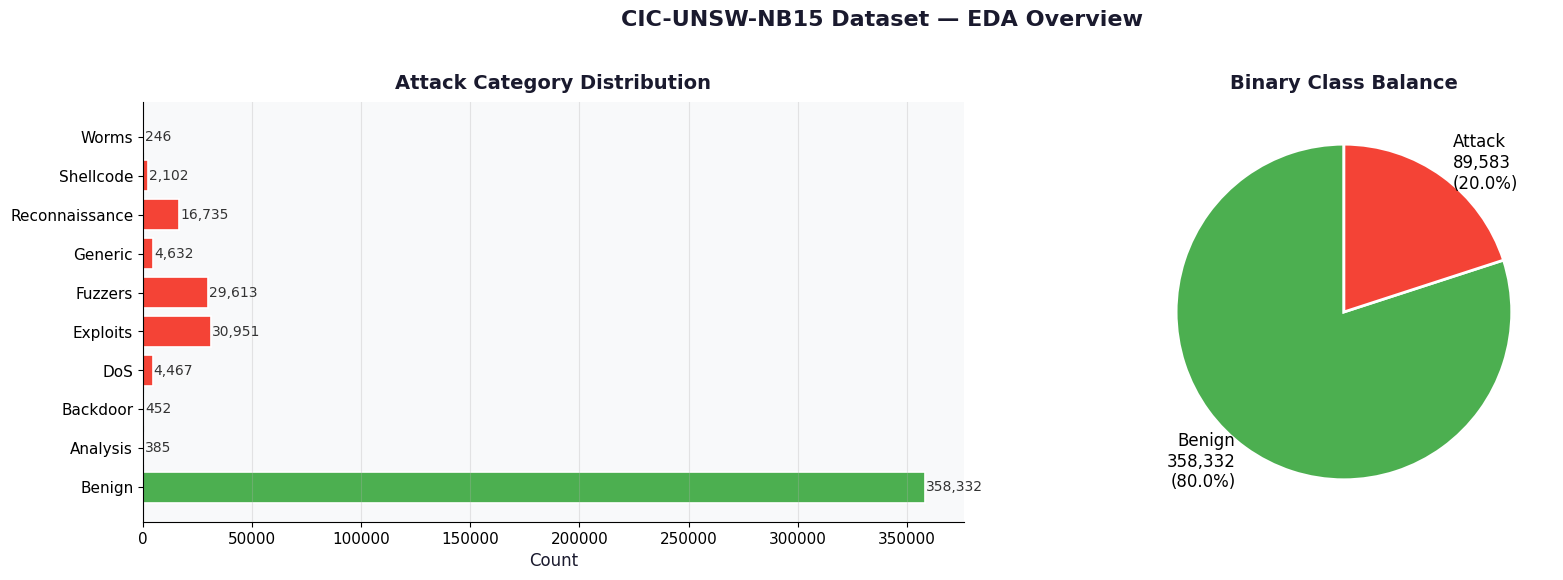

Saved: cicunsw_eda.png


In [ ]:
#  CELL 22 — CIC-UNSW-NB15: Load + EDA

CURRENT_DATASET = "CIC-UNSW-NB15"
cfg = DATASETS[CURRENT_DATASET]

print(f"Dataset: {CURRENT_DATASET} ({cfg['country']})")
print("-" * 50)

# Load + Merge
df_data  = pd.read_csv(cfg["data_file"])
df_label = pd.read_csv(cfg["label_file"])
df_cic   = pd.concat([df_data, df_label], axis=1)

print(f"Data.csv shape    : {df_data.shape}")
print(f"Label.csv shape   : {df_label.shape}")
print(f"Merged shape      : {df_cic.shape}")
print(f"Missing values    : {df_cic.isnull().sum().sum()}")

# Label info
print(f"\nLabel distribution (multi-class):")
label_names = {
    0: "Benign",
    1: "Analysis",
    2: "Backdoor",
    3: "DoS",
    4: "Exploits",
    5: "Fuzzers",
    6: "Generic",
    7: "Reconnaissance",
    8: "Shellcode",
    9: "Worms"
}
counts = df_cic[cfg["label_col"]].value_counts().sort_index()
for val, cnt in counts.items():
    print(f"  {val} — {label_names[val]:<15}: {cnt:>7,} ({cnt/len(df_cic)*100:.1f}%)")

# Binary distribution
benign = (df_cic[cfg["label_col"]] == 0).sum()
attack = (df_cic[cfg["label_col"]] != 0).sum()
total  = len(df_cic)
print(f"\nBinary distribution:")
print(f"  Benign : {benign:,} ({benign/total*100:.1f}%)")
print(f"  Attack : {attack:,} ({attack/total*100:.1f}%)")

# EDA Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6), facecolor='white')
fig.suptitle('CIC-UNSW-NB15 Dataset — EDA Overview',
             fontsize=16, fontweight='bold', color='#1a1a2e')

# Plot 1 — Attack category distribution
ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
labels_str = [f"{label_names[v]}" for v in counts.index]
colors_bar = ['#4CAF50' if v == 0 else '#F44336' for v in counts.index]
bars = ax1.barh(labels_str, counts.values,
                color=colors_bar, edgecolor='white', linewidth=1.2)
ax1.set_title('Attack Category Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)
ax1.set_xlabel('Count', fontsize=12, color='#1a1a2e')
ax1.tick_params(labelsize=11)
ax1.grid(axis='x', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for bar, val in zip(bars, counts.values):
    ax1.text(bar.get_width() + 500, bar.get_y() + bar.get_height()/2,
             f'{val:,}', va='center', fontsize=10, color='#333333')

# Plot 2 — Binary class balance pie
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
sizes  = [benign, attack]
pie_labels = [f'Benign\n{benign:,}\n({benign/total*100:.1f}%)',
              f'Attack\n{attack:,}\n({attack/total*100:.1f}%)']
colors_pie = ['#4CAF50', '#F44336']
ax2.pie(sizes, labels=pie_labels, colors=colors_pie,
        startangle=90, textprops={'fontsize': 12},
        wedgeprops={'edgecolor': 'white', 'linewidth': 2})
ax2.set_title('Binary Class Balance', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)

plt.tight_layout(pad=2.0)
plt.savefig('cicunsw_eda.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_eda.png")

In [ ]:
#  CELL 23 — CIC-UNSW-NB15: Preprocessing + Log-Transform + Held-out Test + SMOTE

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from scipy.stats import skew as _skew

print(f"Preprocessing: {CURRENT_DATASET}")
print("-" * 50)

# ---- Step 1: Drop zero-variance columns + create binary label ----
df_clean = df_cic.drop(columns=cfg["drop_cols"], errors="ignore")
df_clean["attack"] = (df_clean[cfg["label_col"]] != 0).astype(int)
df_clean = df_clean.drop(columns=[cfg["label_col"]])
df_clean = df_clean.replace([np.inf, -np.inf], np.nan).fillna(0)

X_cic = df_clean.drop(columns=["attack"])
y_cic = df_clean["attack"]

print(f"Features after preprocessing : {X_cic.shape[1]}")
print(f"Samples                      : {X_cic.shape[0]:,}")
print(f"\nBinary class distribution:")
print(f"  Benign (0): {(y_cic==0).sum():,} ({(y_cic==0).mean()*100:.1f}%)")
print(f"  Attack (1): {(y_cic==1).sum():,} ({(y_cic==1).mean()*100:.1f}%)")

# ---- Step 2: Log-transform heavily-skewed columns ----
numeric_cols = X_cic.select_dtypes(include=[np.number]).columns
skew_vals    = X_cic[numeric_cols].apply(lambda c: _skew(c.dropna()))
skewed_cols  = skew_vals[(skew_vals > 2) & (X_cic[numeric_cols].min() >= 0)].index.tolist()

print(f"\nColumns with skew > 2 (log1p candidates): {len(skewed_cols)} / {len(numeric_cols)}")
for c in skewed_cols:
    X_cic[c] = np.log1p(X_cic[c])
print(f"Applied log1p to {len(skewed_cols)} columns")

# ---- Step 3: HELD-OUT TEST SET FIRST — original imbalance, before any balancing ----
X_train_raw, X_test_cic, y_train_raw, y_test_cic = train_test_split(
    X_cic, y_cic, test_size=0.20, stratify=y_cic, random_state=42
)
print(f"\nTrain pool (raw): {X_train_raw.shape}  |  Held-out test: {X_test_cic.shape}")
print("Test set class ratio (kept ORIGINAL, unbalanced — for realistic evaluation):")
print(y_test_cic.value_counts(normalize=True))

# ---- Step 4: SMOTE-balance the TRAIN POOL ONLY ----
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train_raw, y_train_raw)

print(f"\nTrain pool after SMOTE balance: {X_train_bal.shape}")
print(pd.Series(y_train_bal).value_counts())

Preprocessing: CIC-UNSW-NB15
--------------------------------------------------
Features after preprocessing : 66
Samples                      : 447,915

Binary class distribution:
  Benign (0): 358,332 (80.0%)
  Attack (1): 89,583 (20.0%)

Columns with skew > 2 (log1p candidates): 53 / 66
Applied log1p to 53 columns

Train pool (raw): (358332, 66)  |  Held-out test: (89583, 66)
Test set class ratio (kept ORIGINAL, unbalanced — for realistic evaluation):
attack
0    0.799996
1    0.200004
Name: proportion, dtype: float64

Train pool after SMOTE balance: (573332, 66)
attack
1    286666
0    286666
Name: count, dtype: int64


In [ ]:
#  CELL 23B (FIXED) — CIC-UNSW-NB15: Sample 1 (robust checkpoint reload, runtime-restart safe)

import pickle, time, os
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

CHECKPOINT_DIR_STABILITY = "/content/drive/MyDrive/datasets/checkpoints_cic_stability"
os.makedirs(CHECKPOINT_DIR_STABILITY, exist_ok=True)
sample_1_path = os.path.join(CHECKPOINT_DIR_STABILITY, "Sample_1_data.pkl")
pools_path    = os.path.join(CHECKPOINT_DIR_STABILITY, "base_pools.pkl")

# ---- Load Sample_1 directly from checkpoint (works even after runtime restart) ----
if os.path.exists(sample_1_path):
    with open(sample_1_path, "rb") as f:
        Sample_1 = pickle.load(f)
    print("[SKIP-LOADED] Sample_1 data (from checkpoint, runtime restart-safe)")
elif os.path.exists(pools_path):
    # Fallback: rebuild from base_pools checkpoint (also already saved)
    with open(pools_path, "rb") as f:
        normal_sampled, attack_sampled, n_per_chunk = pickle.load(f)
    Sample_1 = pd.concat([
        normal_sampled.iloc[0:n_per_chunk],
        attack_sampled.iloc[0:n_per_chunk]
    ]).sample(frac=1, random_state=42).reset_index(drop=True)
    with open(sample_1_path, "wb") as f:
        pickle.dump(Sample_1, f)
    print("[REBUILT from base_pools checkpoint] Sample_1 data")
else:
    raise RuntimeError(
        "Neither Sample_1_data.pkl nor base_pools.pkl found in checkpoint. "
        "Please re-run Cell 22 (Load+EDA) and Cell 23 (Preprocessing) first "
        "to regenerate X_train_bal / y_train_bal, then re-run this cell."
    )

print(f"\nSample_1 shape: {Sample_1.shape}, class balance:")
print(Sample_1["attack"].value_counts(normalize=True))

# ---- Train 12 models on Sample 1 (checkpoint-safe, unchanged) ----
print(f"\nTraining 12 models — Sample 1...")
print("-" * 50)

CHECKPOINT_DIR_S1 = "/content/drive/MyDrive/datasets/checkpoints_cic_sample1"
os.makedirs(CHECKPOINT_DIR_S1, exist_ok=True)

X_s1_cic = Sample_1.drop(columns=["attack"])
y_s1_cic = Sample_1["attack"]

scaler_s1_cic     = StandardScaler()
X_s1_cic_sc       = scaler_s1_cic.fit_transform(X_s1_cic)
X_test_s1_cic_sc  = scaler_s1_cic.transform(X_test_cic)

models_s1_cic = get_models()

def train_single_model_s1(name):
    ckpt_path = os.path.join(CHECKPOINT_DIR_S1, f"{name.replace(' ', '_')}.pkl")
    if os.path.exists(ckpt_path):
        with open(ckpt_path, "rb") as f:
            res = pickle.load(f)
        print(f"  [SKIP-LOADED] {name}")
        return res

    spec  = models_s1_cic[name]
    model = spec["model"]
    Xtr = X_s1_cic_sc      if spec["needs_scale"] else X_s1_cic
    Xte = X_test_s1_cic_sc if spec["needs_scale"] else X_test_cic

    t0 = time.time()
    model.fit(Xtr, y_s1_cic)
    elapsed = time.time() - t0

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else y_pred

    res = {
        "model"    : model,
        "category" : spec["category"],
        "accuracy" : accuracy_score(y_test_cic, y_pred),
        "f1"       : f1_score(y_test_cic, y_pred),
        "precision": precision_score(y_test_cic, y_pred),
        "recall"   : recall_score(y_test_cic, y_pred),
        "auc"      : roc_auc_score(y_test_cic, y_prob),
        "time"     : elapsed,
        "y_pred"   : y_pred,
        "y_prob"   : y_prob,
    }
    with open(ckpt_path, "wb") as f:
        pickle.dump(res, f)
    print(f"  [TRAINED]     {name:<20} F1={res['f1']:.4f}  ({elapsed:.1f}s)")
    return res

results_s1_cic = {}
for name in models_s1_cic:
    results_s1_cic[name] = train_single_model_s1(name)

best_name_s1_cic, best_res_s1_cic = find_best_model(results_s1_cic)
best_t_s1_cic, best_f1_t_s1_cic   = optimize_threshold(y_test_cic, best_res_s1_cic["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s1_cic.items():
    marker = " *" if name == best_name_s1_cic else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s1_cic}")
print(f"F1-Score          : {best_res_s1_cic['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s1_cic['auc']:.4f}")
print(f"Optimal Threshold : {best_t_s1_cic:.2f}")
print(f"F1 at Threshold   : {best_f1_t_s1_cic:.4f}")

[SKIP-LOADED] Sample_1 data (from checkpoint, runtime restart-safe)

Sample_1 shape: (50000, 67), class balance:
attack
1    0.5
0    0.5
Name: proportion, dtype: float64

Training 12 models — Sample 1...
--------------------------------------------------
  [SKIP-LOADED] Random Forest
  [SKIP-LOADED] Gradient Boosting
  [SKIP-LOADED] XGBoost
  [SKIP-LOADED] SVM
  [SKIP-LOADED] Voting Ensemble
  [SKIP-LOADED] Stacking
  [SKIP-LOADED] LightGBM
  [SKIP-LOADED] MLP Neural Net
  [SKIP-LOADED] CatBoost
  [SKIP-LOADED] Extra Trees
  [SKIP-LOADED] AdaBoost
  [SKIP-LOADED] Naive Bayes

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9808   0.9542   0.9953
Gradient Boosting    Base          0.9814   0.9554   0.9954
XGBoost              Base          0.9817   0.9560   0.9954
SVM                  Base          0.9787   0.9495   0.9932
Voting Ensemble      Hybrid        0.

In [ ]:
#  CELL 23C — CIC-UNSW-NB15: Sample 2 (build + train 12 models, checkpoint-safe)

import pickle, time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

CHECKPOINT_DIR_STABILITY = "/content/drive/MyDrive/datasets/checkpoints_cic_stability"

# ---- Build Sample 2 (uses base_pools + n_per_chunk saved in Sample 1's cell) ----
sample_2_path = os.path.join(CHECKPOINT_DIR_STABILITY, "Sample_2_data.pkl")

if os.path.exists(sample_2_path):
    with open(sample_2_path, "rb") as f:
        Sample_2 = pickle.load(f)
    print("[SKIP-LOADED] Sample_2 data")
else:
    Sample_2 = pd.concat([
        normal_sampled.iloc[n_per_chunk:2*n_per_chunk],
        attack_sampled.iloc[n_per_chunk:2*n_per_chunk]
    ]).sample(frac=1, random_state=42).reset_index(drop=True)
    with open(sample_2_path, "wb") as f:
        pickle.dump(Sample_2, f)
    print("[SAVED] Sample_2 data -> checkpoint")

print(f"\nSample_2 shape: {Sample_2.shape}, class balance:")
print(Sample_2["attack"].value_counts(normalize=True))

# ---- Train 12 models on Sample 2 ----
print(f"\nTraining 12 models — Sample 2...")
print("-" * 50)

CHECKPOINT_DIR_S2 = "/content/drive/MyDrive/datasets/checkpoints_cic_sample2"
os.makedirs(CHECKPOINT_DIR_S2, exist_ok=True)

X_s2_cic = Sample_2.drop(columns=["attack"])
y_s2_cic = Sample_2["attack"]

scaler_s2_cic     = StandardScaler()
X_s2_cic_sc       = scaler_s2_cic.fit_transform(X_s2_cic)
X_test_s2_cic_sc  = scaler_s2_cic.transform(X_test_cic)

models_s2_cic = get_models()

def train_single_model_s2(name):
    ckpt_path = os.path.join(CHECKPOINT_DIR_S2, f"{name.replace(' ', '_')}.pkl")
    if os.path.exists(ckpt_path):
        with open(ckpt_path, "rb") as f:
            res = pickle.load(f)
        print(f"  [SKIP-LOADED] {name}")
        return res

    spec  = models_s2_cic[name]
    model = spec["model"]
    Xtr = X_s2_cic_sc      if spec["needs_scale"] else X_s2_cic
    Xte = X_test_s2_cic_sc if spec["needs_scale"] else X_test_cic

    t0 = time.time()
    model.fit(Xtr, y_s2_cic)
    elapsed = time.time() - t0

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else y_pred

    res = {
        "model"    : model,
        "category" : spec["category"],
        "accuracy" : accuracy_score(y_test_cic, y_pred),
        "f1"       : f1_score(y_test_cic, y_pred),
        "precision": precision_score(y_test_cic, y_pred),
        "recall"   : recall_score(y_test_cic, y_pred),
        "auc"      : roc_auc_score(y_test_cic, y_prob),
        "time"     : elapsed,
        "y_pred"   : y_pred,
        "y_prob"   : y_prob,
    }
    with open(ckpt_path, "wb") as f:
        pickle.dump(res, f)
    print(f"  [TRAINED]     {name:<20} F1={res['f1']:.4f}  ({elapsed:.1f}s)")
    return res

results_s2_cic = {}
for name in models_s2_cic:
    results_s2_cic[name] = train_single_model_s2(name)

best_name_s2_cic, best_res_s2_cic = find_best_model(results_s2_cic)
best_t_s2_cic, best_f1_t_s2_cic   = optimize_threshold(y_test_cic, best_res_s2_cic["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s2_cic.items():
    marker = " *" if name == best_name_s2_cic else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s2_cic}")
print(f"F1-Score          : {best_res_s2_cic['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s2_cic['auc']:.4f}")

[SKIP-LOADED] Sample_2 data

Sample_2 shape: (50000, 67), class balance:
attack
1    0.5
0    0.5
Name: proportion, dtype: float64

Training 12 models — Sample 2...
--------------------------------------------------
  [SKIP-LOADED] Random Forest
  [SKIP-LOADED] Gradient Boosting
  [SKIP-LOADED] XGBoost
  [SKIP-LOADED] SVM
  [SKIP-LOADED] Voting Ensemble
  [SKIP-LOADED] Stacking
  [SKIP-LOADED] LightGBM
  [SKIP-LOADED] MLP Neural Net
  [SKIP-LOADED] CatBoost
  [SKIP-LOADED] Extra Trees
  [SKIP-LOADED] AdaBoost
  [SKIP-LOADED] Naive Bayes

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9812   0.9550   0.9952
Gradient Boosting    Base          0.9815   0.9556   0.9955
XGBoost              Base          0.9820   0.9567   0.9955
SVM                  Base          0.9787   0.9494   0.9932
Voting Ensemble      Hybrid        0.9815   0.9556   0.9954
Stacking *       

In [ ]:
#  CELL 23D — CIC-UNSW-NB15: Sample 3 (build + train 12 models, checkpoint-safe)

import pickle, time
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

CHECKPOINT_DIR_STABILITY = "/content/drive/MyDrive/datasets/checkpoints_cic_stability"

# ---- Build Sample 3 ----
sample_3_path = os.path.join(CHECKPOINT_DIR_STABILITY, "Sample_3_data.pkl")

if os.path.exists(sample_3_path):
    with open(sample_3_path, "rb") as f:
        Sample_3 = pickle.load(f)
    print("[SKIP-LOADED] Sample_3 data")
else:
    Sample_3 = pd.concat([
        normal_sampled.iloc[2*n_per_chunk:3*n_per_chunk],
        attack_sampled.iloc[2*n_per_chunk:3*n_per_chunk]
    ]).sample(frac=1, random_state=42).reset_index(drop=True)
    with open(sample_3_path, "wb") as f:
        pickle.dump(Sample_3, f)
    print("[SAVED] Sample_3 data -> checkpoint")

print(f"\nSample_3 shape: {Sample_3.shape}, class balance:")
print(Sample_3["attack"].value_counts(normalize=True))

# ---- Train 12 models on Sample 3 ----
print(f"\nTraining 12 models — Sample 3...")
print("-" * 50)

CHECKPOINT_DIR_S3 = "/content/drive/MyDrive/datasets/checkpoints_cic_sample3"
os.makedirs(CHECKPOINT_DIR_S3, exist_ok=True)

X_s3_cic = Sample_3.drop(columns=["attack"])
y_s3_cic = Sample_3["attack"]

scaler_s3_cic     = StandardScaler()
X_s3_cic_sc       = scaler_s3_cic.fit_transform(X_s3_cic)
X_test_s3_cic_sc  = scaler_s3_cic.transform(X_test_cic)

models_s3_cic = get_models()

def train_single_model_s3(name):
    ckpt_path = os.path.join(CHECKPOINT_DIR_S3, f"{name.replace(' ', '_')}.pkl")
    if os.path.exists(ckpt_path):
        with open(ckpt_path, "rb") as f:
            res = pickle.load(f)
        print(f"  [SKIP-LOADED] {name}")
        return res

    spec  = models_s3_cic[name]
    model = spec["model"]
    Xtr = X_s3_cic_sc      if spec["needs_scale"] else X_s3_cic
    Xte = X_test_s3_cic_sc if spec["needs_scale"] else X_test_cic

    t0 = time.time()
    model.fit(Xtr, y_s3_cic)
    elapsed = time.time() - t0

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else y_pred

    res = {
        "model"    : model,
        "category" : spec["category"],
        "accuracy" : accuracy_score(y_test_cic, y_pred),
        "f1"       : f1_score(y_test_cic, y_pred),
        "precision": precision_score(y_test_cic, y_pred),
        "recall"   : recall_score(y_test_cic, y_pred),
        "auc"      : roc_auc_score(y_test_cic, y_prob),
        "time"     : elapsed,
        "y_pred"   : y_pred,
        "y_prob"   : y_prob,
    }
    with open(ckpt_path, "wb") as f:
        pickle.dump(res, f)
    print(f"  [TRAINED]     {name:<20} F1={res['f1']:.4f}  ({elapsed:.1f}s)")
    return res

results_s3_cic = {}
for name in models_s3_cic:
    results_s3_cic[name] = train_single_model_s3(name)

best_name_s3_cic, best_res_s3_cic = find_best_model(results_s3_cic)
best_t_s3_cic, best_f1_t_s3_cic   = optimize_threshold(y_test_cic, best_res_s3_cic["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_s3_cic.items():
    marker = " *" if name == best_name_s3_cic else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_s3_cic}")
print(f"F1-Score          : {best_res_s3_cic['f1']:.4f}")
print(f"AUC-ROC           : {best_res_s3_cic['auc']:.4f}")

[SKIP-LOADED] Sample_3 data

Sample_3 shape: (50000, 67), class balance:
attack
1    0.5
0    0.5
Name: proportion, dtype: float64

Training 12 models — Sample 3...
--------------------------------------------------
  [SKIP-LOADED] Random Forest
  [SKIP-LOADED] Gradient Boosting
  [SKIP-LOADED] XGBoost
  [SKIP-LOADED] SVM
  [SKIP-LOADED] Voting Ensemble
  [SKIP-LOADED] Stacking
  [SKIP-LOADED] LightGBM
  [SKIP-LOADED] MLP Neural Net
  [SKIP-LOADED] CatBoost
  [SKIP-LOADED] Extra Trees
  [SKIP-LOADED] AdaBoost
  [SKIP-LOADED] Naive Bayes

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9810   0.9545   0.9952
Gradient Boosting    Base          0.9812   0.9549   0.9953
XGBoost              Base          0.9819   0.9564   0.9955
SVM                  Base          0.9790   0.9502   0.9929
Voting Ensemble      Hybrid        0.9813   0.9552   0.9953
Stacking *       

In [ ]:
#  Stability Check — Final Decision (CIC-UNSW-NB15)

model_names_cic = list(results_s1_cic.keys())

print(f"{'Model':<20} {'S1 F1':>8} {'S2 F1':>8} {'S3 F1':>8} {'Avg F1':>9} {'Std Dev':>9}")
print("-" * 70)

avg_f1_dict_cic = {}
for name in model_names_cic:
    f1_s1 = results_s1_cic[name]["f1"]
    f1_s2 = results_s2_cic[name]["f1"]
    f1_s3 = results_s3_cic[name]["f1"]
    avg   = np.mean([f1_s1, f1_s2, f1_s3])
    std   = np.std([f1_s1, f1_s2, f1_s3])
    avg_f1_dict_cic[name] = {"avg": avg, "std": std}

best_avg_model_cic = max(avg_f1_dict_cic, key=lambda x: avg_f1_dict_cic[x]["avg"])
for name in model_names_cic:
    f1_s1 = results_s1_cic[name]["f1"]
    f1_s2 = results_s2_cic[name]["f1"]
    f1_s3 = results_s3_cic[name]["f1"]
    avg   = avg_f1_dict_cic[name]["avg"]
    std   = avg_f1_dict_cic[name]["std"]
    marker = " *" if name == best_avg_model_cic else ""
    print(f"{name:<20} {f1_s1:>8.4f} {f1_s2:>8.4f} {f1_s3:>8.4f} "
          f"{avg:>9.4f} {std:>9.4f}")

print(f"\nFinal Best Model  : {best_avg_model_cic}")
print(f"Average F1        : {avg_f1_dict_cic[best_avg_model_cic]['avg']:.4f}")
print(f"Std Dev           : {avg_f1_dict_cic[best_avg_model_cic]['std']:.4f}")
print("\nConclusion: Sampling is STABLE — No bias detected."
      if avg_f1_dict_cic[best_avg_model_cic]['std'] < 0.01
      else "\nWARNING: F1 variance across samples is high — review sampling.")

Model                   S1 F1    S2 F1    S3 F1    Avg F1   Std Dev
----------------------------------------------------------------------
Random Forest          0.9542   0.9550   0.9545    0.9546    0.0003
Gradient Boosting      0.9554   0.9556   0.9549    0.9553    0.0003
XGBoost                0.9560   0.9567   0.9564    0.9563    0.0003
SVM                    0.9495   0.9494   0.9502    0.9497    0.0003
Voting Ensemble        0.9545   0.9556   0.9552    0.9551    0.0005
Stacking               0.9570   0.9575   0.9569    0.9571    0.0002
LightGBM               0.9558   0.9566   0.9562    0.9562    0.0003
MLP Neural Net         0.9531   0.9496   0.9525    0.9517    0.0015
CatBoost               0.9541   0.9550   0.9547    0.9546    0.0004
Extra Trees            0.9509   0.9510   0.9505    0.9508    0.0002
AdaBoost               0.9258   0.9254   0.9258    0.9256    0.0002
Naive Bayes            0.8007   0.7950   0.8068    0.8008    0.0048

Final Best Model  : Stacking
Average F1     

In [ ]:
#  CELL 23F — CIC-UNSW-NB15: Merge 3 Samples -> Final 150k Train Set + Scale

CHECKPOINT_DIR_STABILITY = "/content/drive/MyDrive/datasets/checkpoints_cic_stability"
merge_path = os.path.join(CHECKPOINT_DIR_STABILITY, "merged_150k.pkl")

if os.path.exists(merge_path):
    with open(merge_path, "rb") as f:
        train_150k_cic = pickle.load(f)
    print("[SKIP-LOADED] merged_150k (loaded from checkpoint)")
else:
    train_150k_cic = pd.concat([Sample_1, Sample_2, Sample_3]).sample(
        frac=1, random_state=42).reset_index(drop=True)
    with open(merge_path, "wb") as f:
        pickle.dump(train_150k_cic, f)
    print("[SAVED] merged_150k -> checkpoint")

y_train_cic = train_150k_cic["attack"]
X_train_cic = train_150k_cic.drop(columns=["attack"])

print(f"\nFinal merged train (150k): {X_train_cic.shape}")
print(f"Class balance (merged):")
print(y_train_cic.value_counts(normalize=True))

from sklearn.preprocessing import StandardScaler
scaler_cic = StandardScaler()
X_train_cic_sc = scaler_cic.fit_transform(X_train_cic)
X_test_cic_sc  = scaler_cic.transform(X_test_cic)

print(f"\nReady for final training:")
print(f"  X_train_cic : {X_train_cic.shape}")
print(f"  X_test_cic  : {X_test_cic.shape}")

[SKIP-LOADED] merged_150k (loaded from checkpoint)

Final merged train (150k): (150000, 66)
Class balance (merged):
attack
0    0.5
1    0.5
Name: proportion, dtype: float64

Ready for final training:
  X_train_cic : (150000, 66)
  X_test_cic  : (89583, 66)


In [ ]:
#  CELL 24 — CIC-UNSW-NB15: Final Training on Merged 150k

import pickle, time
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.utils import resample

print(f"Training 12 models on {CURRENT_DATASET} (merged 150k, checkpoint-safe)...")
print("-" * 50)

CHECKPOINT_DIR = "/content/drive/MyDrive/datasets/checkpoints_cic"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

models_cic = get_models()

# SVM / Stacking capped at 50k — same trade-off as HQC-2026 (justified by
# the stability check above: SVM F1 std dev only 0.0003 across samples,
# performance already saturates well below 150k)
SLOW_MODELS = {"SVM", "Stacking"}
X_train_50k, y_train_50k, X_train_50k_sc = resample(
    X_train_cic, y_train_cic, X_train_cic_sc, n_samples=50000, random_state=42
)

def train_single_model(name):
    ckpt_path = os.path.join(CHECKPOINT_DIR, f"{name.replace(' ', '_')}.pkl")
    if os.path.exists(ckpt_path):
        with open(ckpt_path, "rb") as f:
            res = pickle.load(f)
        print(f"  [SKIP-LOADED] {name}")
        return res

    spec  = models_cic[name]
    model = spec["model"]

    if name in SLOW_MODELS:
        Xtr = X_train_50k_sc if spec["needs_scale"] else X_train_50k
        ytr = y_train_50k
    else:
        Xtr = X_train_cic_sc if spec["needs_scale"] else X_train_cic
        ytr = y_train_cic
    Xte = X_test_cic_sc if spec["needs_scale"] else X_test_cic

    t0 = time.time()
    model.fit(Xtr, ytr)
    elapsed = time.time() - t0

    y_pred = model.predict(Xte)
    y_prob = model.predict_proba(Xte)[:, 1] if hasattr(model, "predict_proba") else y_pred

    res = {
        "model"    : model,
        "category" : spec["category"],
        "accuracy" : accuracy_score(y_test_cic, y_pred),
        "f1"       : f1_score(y_test_cic, y_pred),
        "precision": precision_score(y_test_cic, y_pred),
        "recall"   : recall_score(y_test_cic, y_pred),
        "auc"      : roc_auc_score(y_test_cic, y_prob),
        "time"     : elapsed,
        "y_pred"   : y_pred,
        "y_prob"   : y_prob,
    }
    with open(ckpt_path, "wb") as f:
        pickle.dump(res, f)
    print(f"  [TRAINED]     {name:<20} F1={res['f1']:.4f}  ({elapsed:.1f}s)"
          f"{'  [50k subset]' if name in SLOW_MODELS else '  [150k]'}")
    return res

results_cic = {}
for name in models_cic:
    results_cic[name] = train_single_model(name)

best_name_cic, best_res_cic = find_best_model(results_cic)
best_t_cic, best_f1_t_cic   = optimize_threshold(y_test_cic, best_res_cic["y_prob"])

print(f"\nAll Models Summary:")
print(f"{'Model':<20} {'Category':<10} {'Accuracy':>9} {'F1':>8} {'AUC':>8}")
print("-" * 58)
for name, res in results_cic.items():
    marker = " *" if name == best_name_cic else ""
    print(f"{name+marker:<20} {res['category']:<10} "
          f"{res['accuracy']:>9.4f} {res['f1']:>8.4f} {res['auc']:>8.4f}")

print(f"\nBest Model        : {best_name_cic}")
print(f"F1-Score          : {best_res_cic['f1']:.4f}")
print(f"AUC-ROC           : {best_res_cic['auc']:.4f}")
print(f"Optimal Threshold : {best_t_cic:.2f}")
print(f"F1 at Threshold   : {best_f1_t_cic:.4f}")

Training 12 models on CIC-UNSW-NB15 (merged 150k, checkpoint-safe)...
--------------------------------------------------
  [SKIP-LOADED] Random Forest
  [SKIP-LOADED] Gradient Boosting
  [SKIP-LOADED] XGBoost
  [SKIP-LOADED] SVM
  [SKIP-LOADED] Voting Ensemble
  [SKIP-LOADED] Stacking
  [SKIP-LOADED] LightGBM
  [SKIP-LOADED] MLP Neural Net
  [SKIP-LOADED] CatBoost
  [SKIP-LOADED] Extra Trees
  [SKIP-LOADED] AdaBoost
  [SKIP-LOADED] Naive Bayes

All Models Summary:
Model                Category    Accuracy       F1      AUC
----------------------------------------------------------
Random Forest        Base          0.9813   0.9554   0.9958
Gradient Boosting    Base          0.9819   0.9565   0.9958
XGBoost              Base          0.9824   0.9576   0.9960
SVM                  Base          0.9788   0.9497   0.9930
Voting Ensemble      Hybrid        0.9819   0.9566   0.9959
Stacking             Hybrid        0.9819   0.9564   0.9953
LightGBM *           New (B)       0.9826   0.9580  

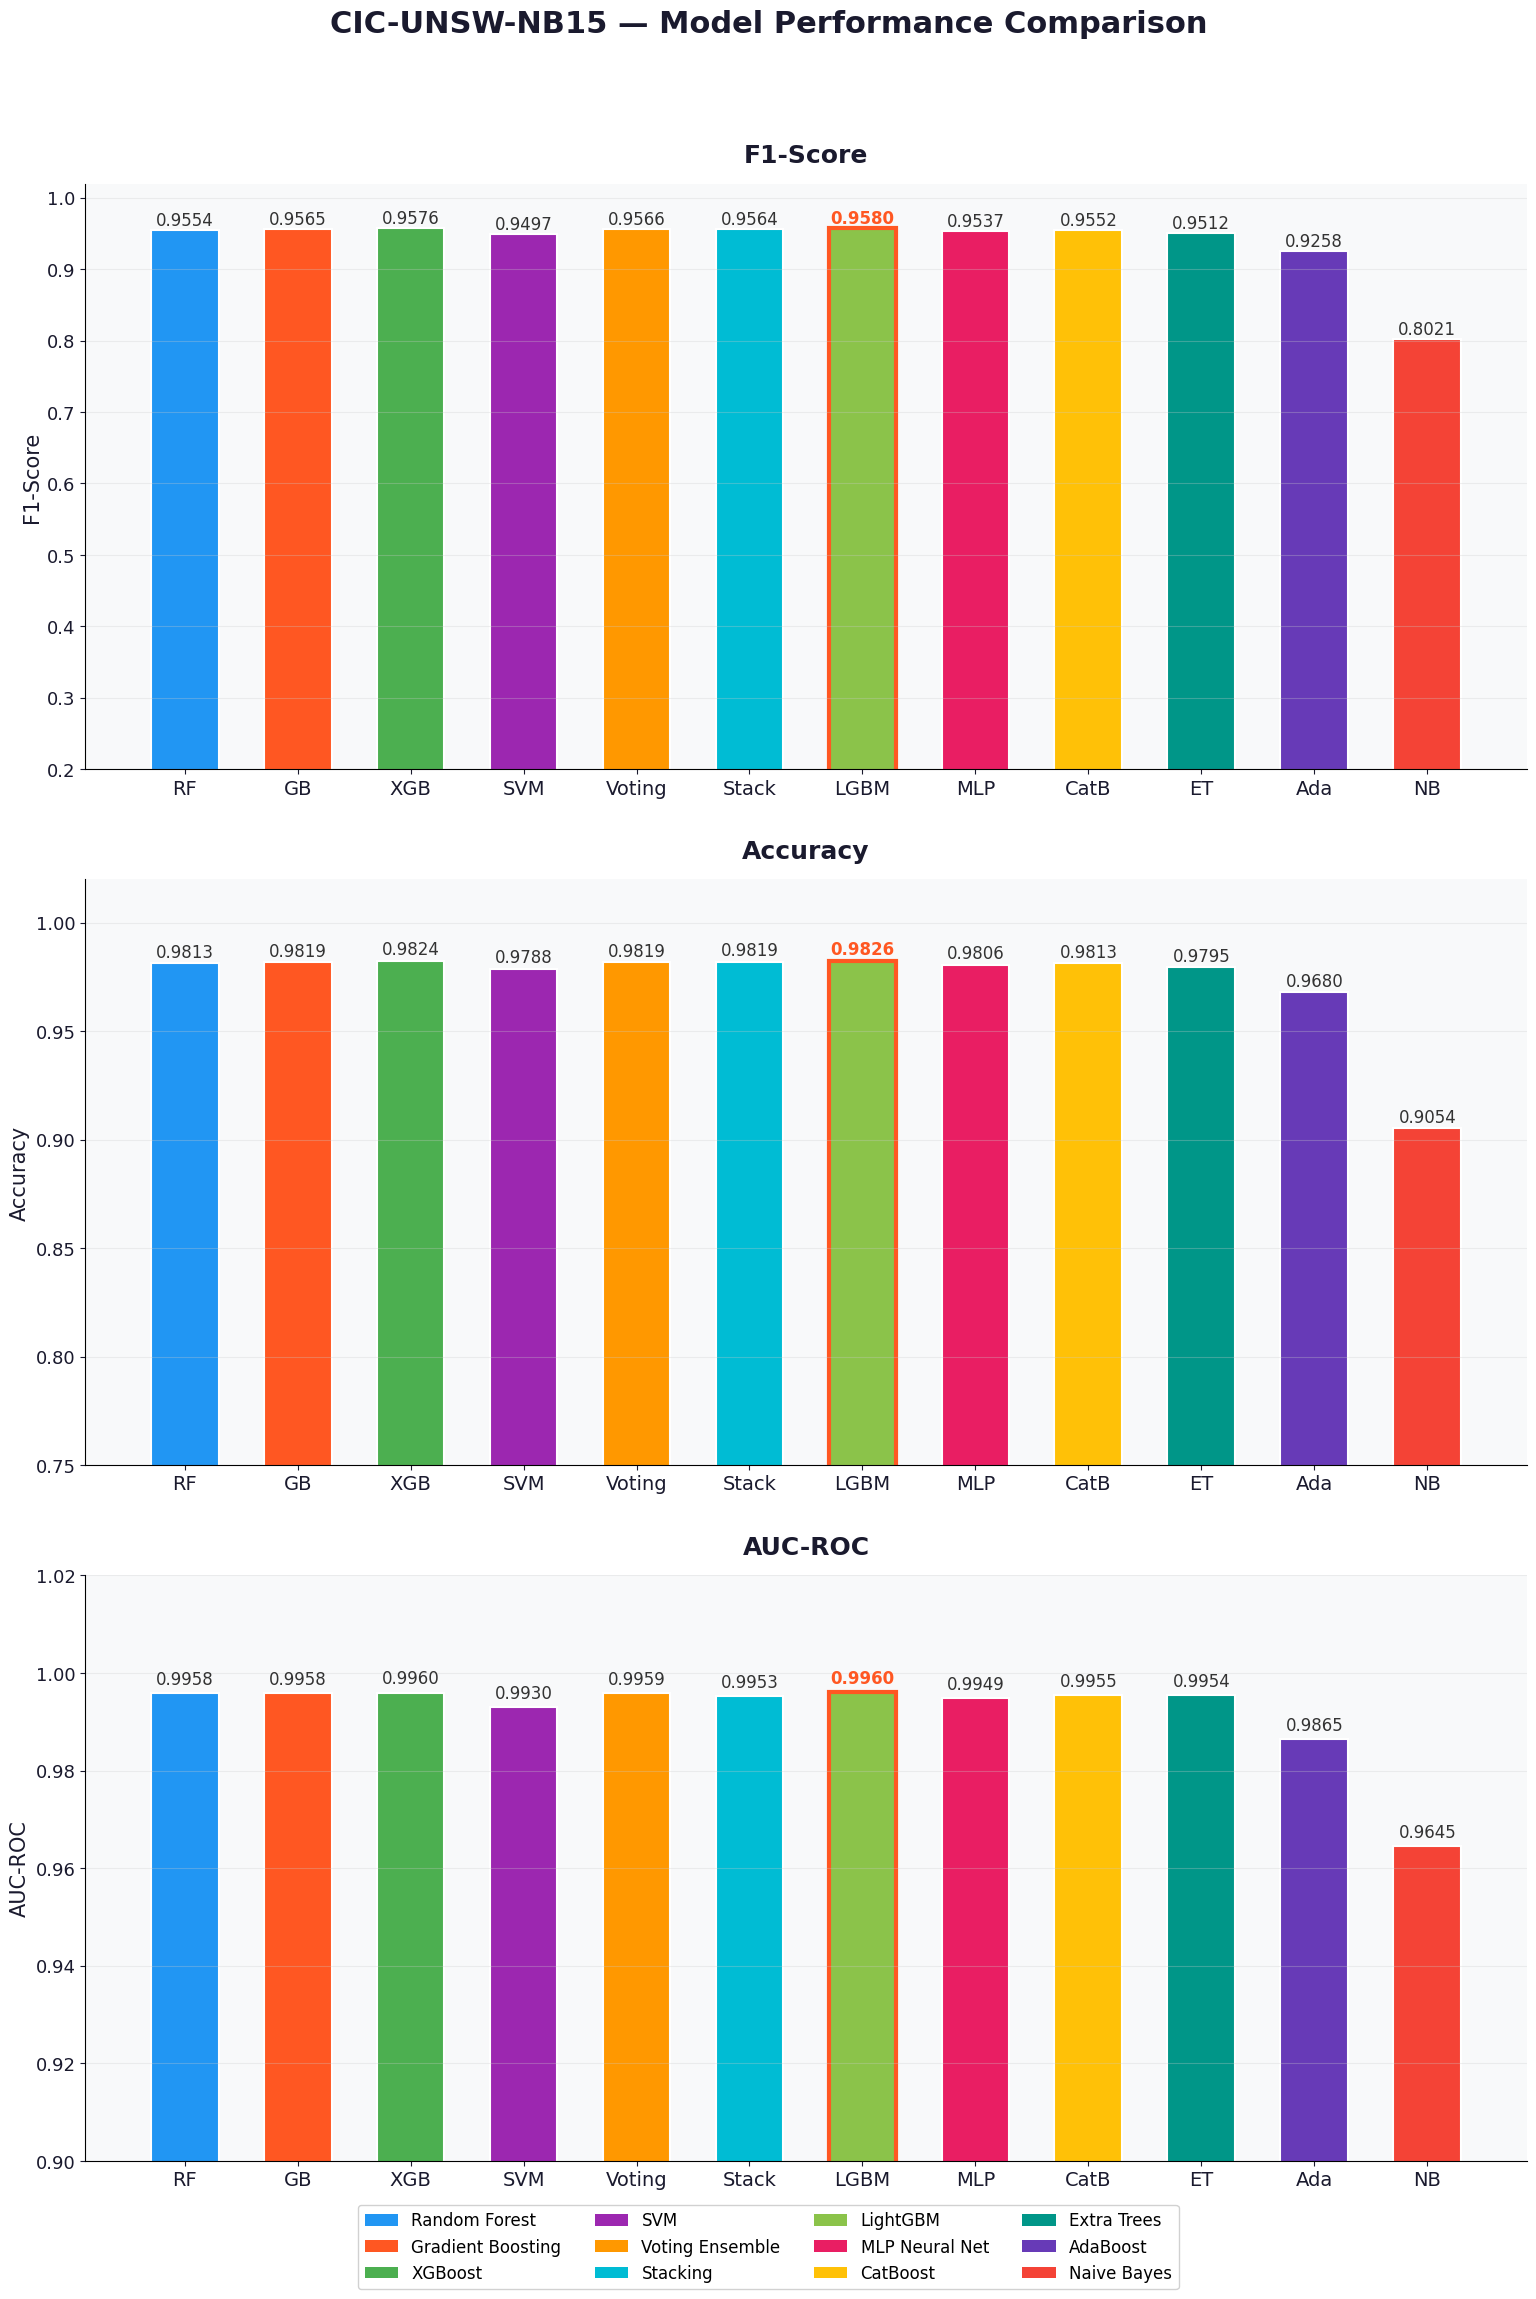

Saved: cicunsw_model_comparison.png


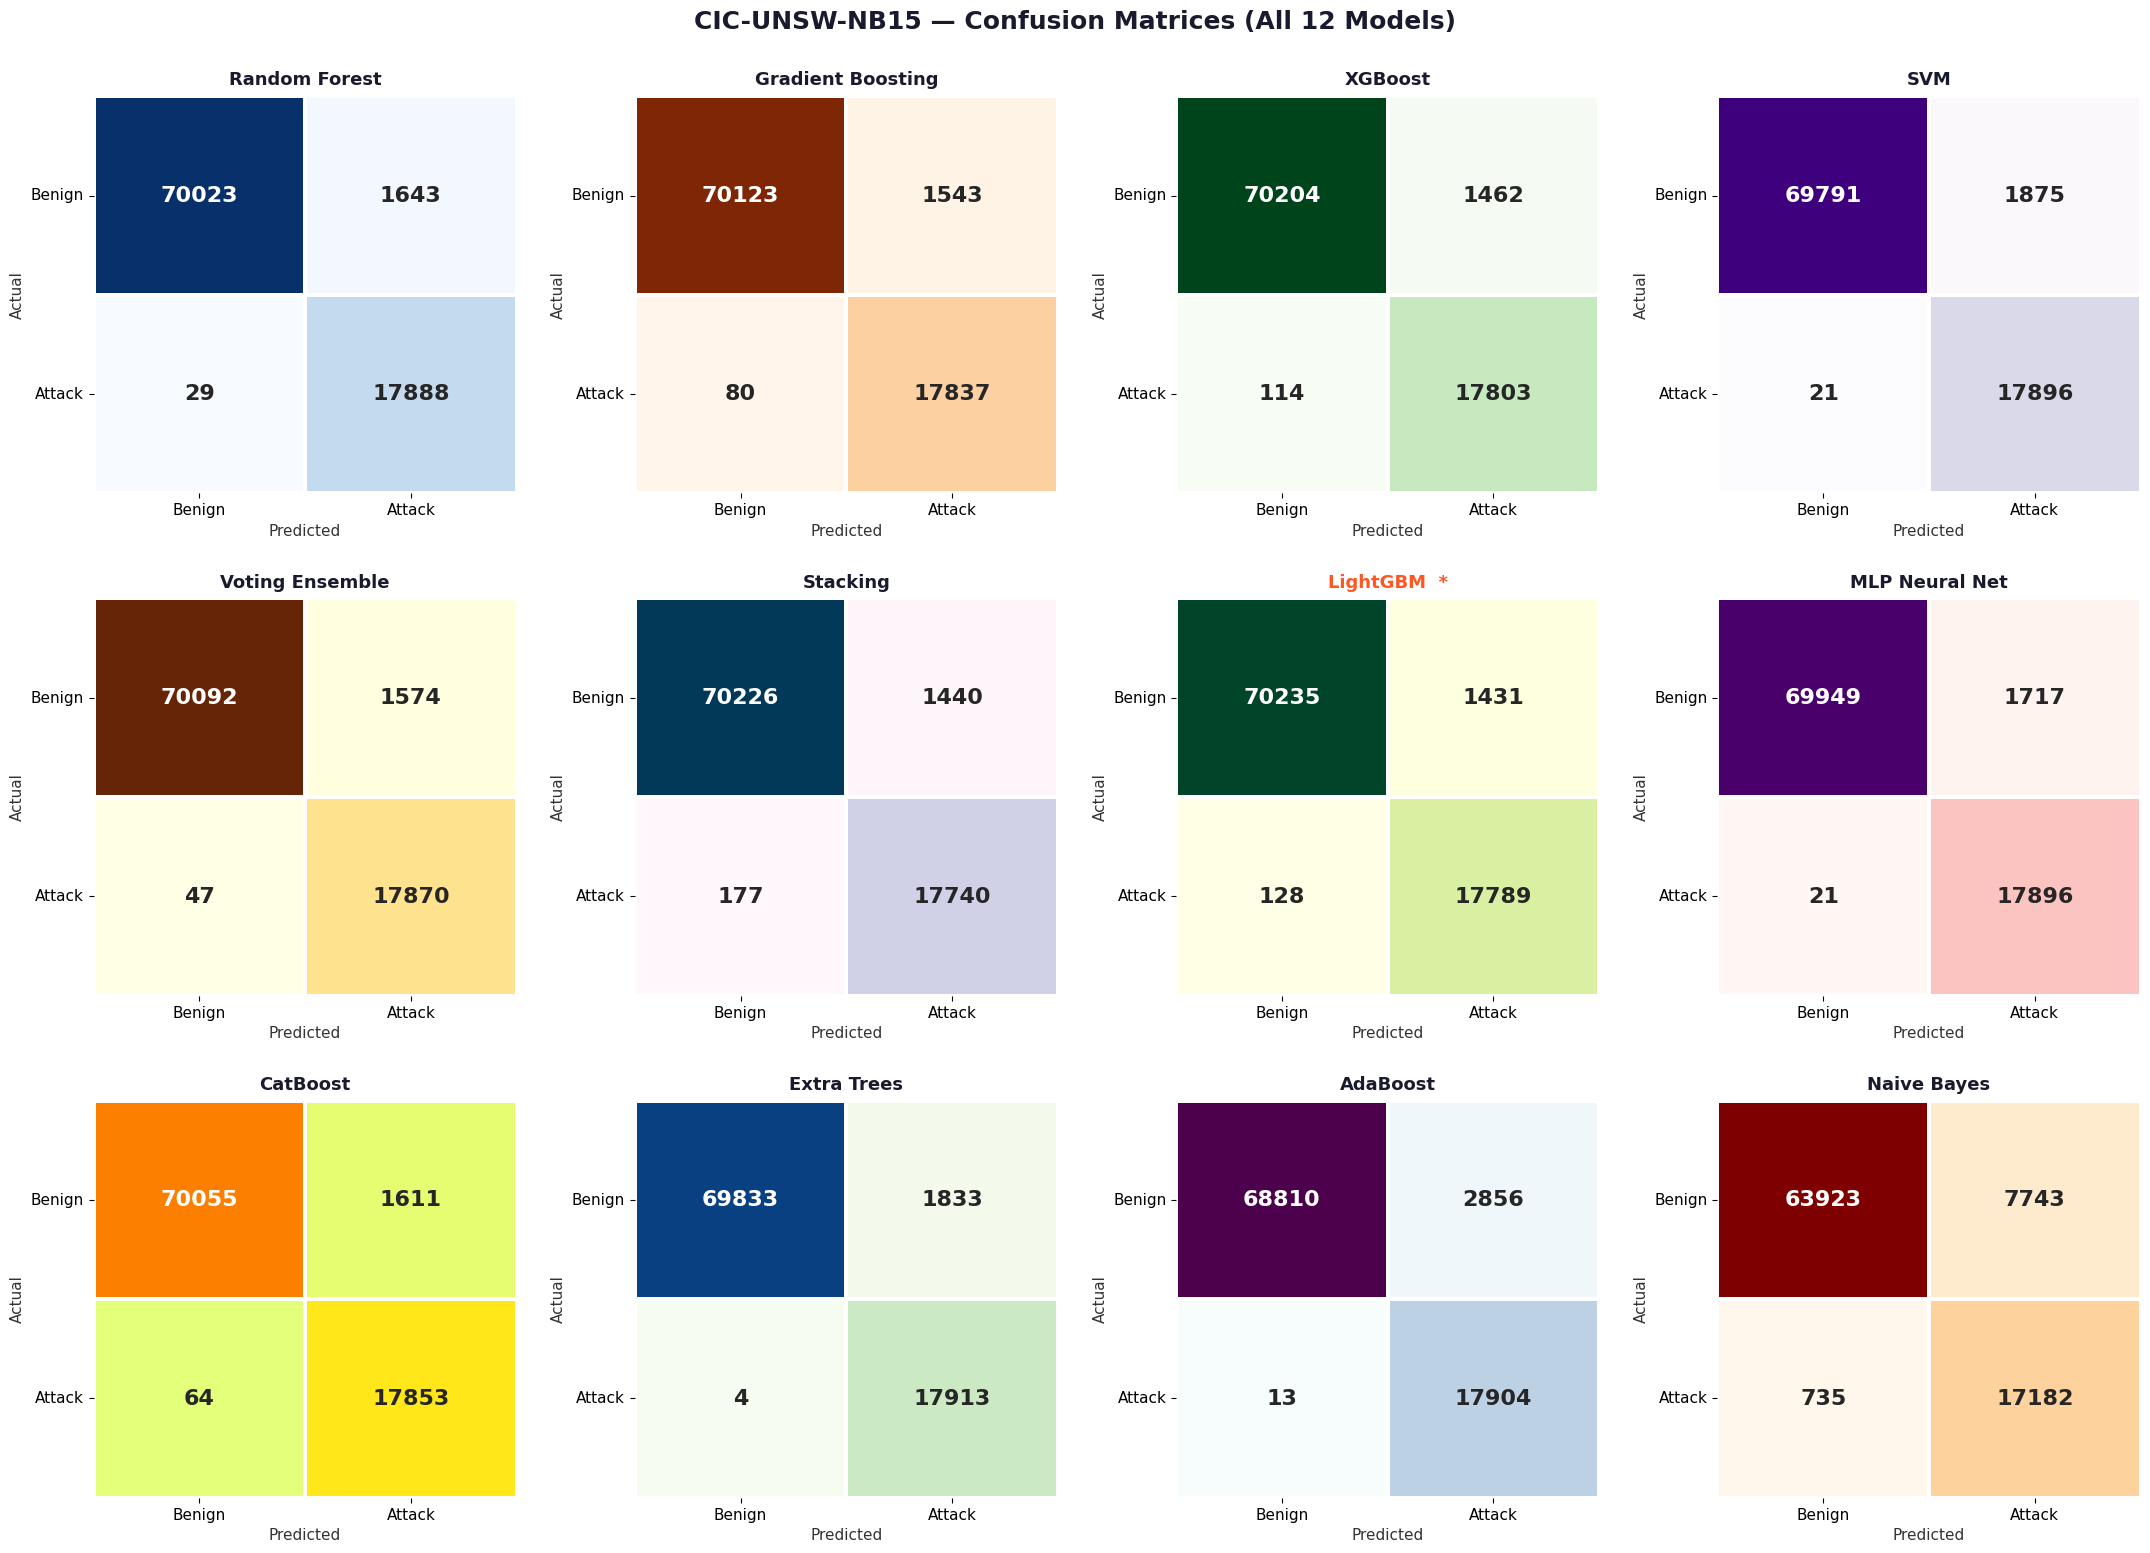

Saved: cicunsw_confusion_matrices.png


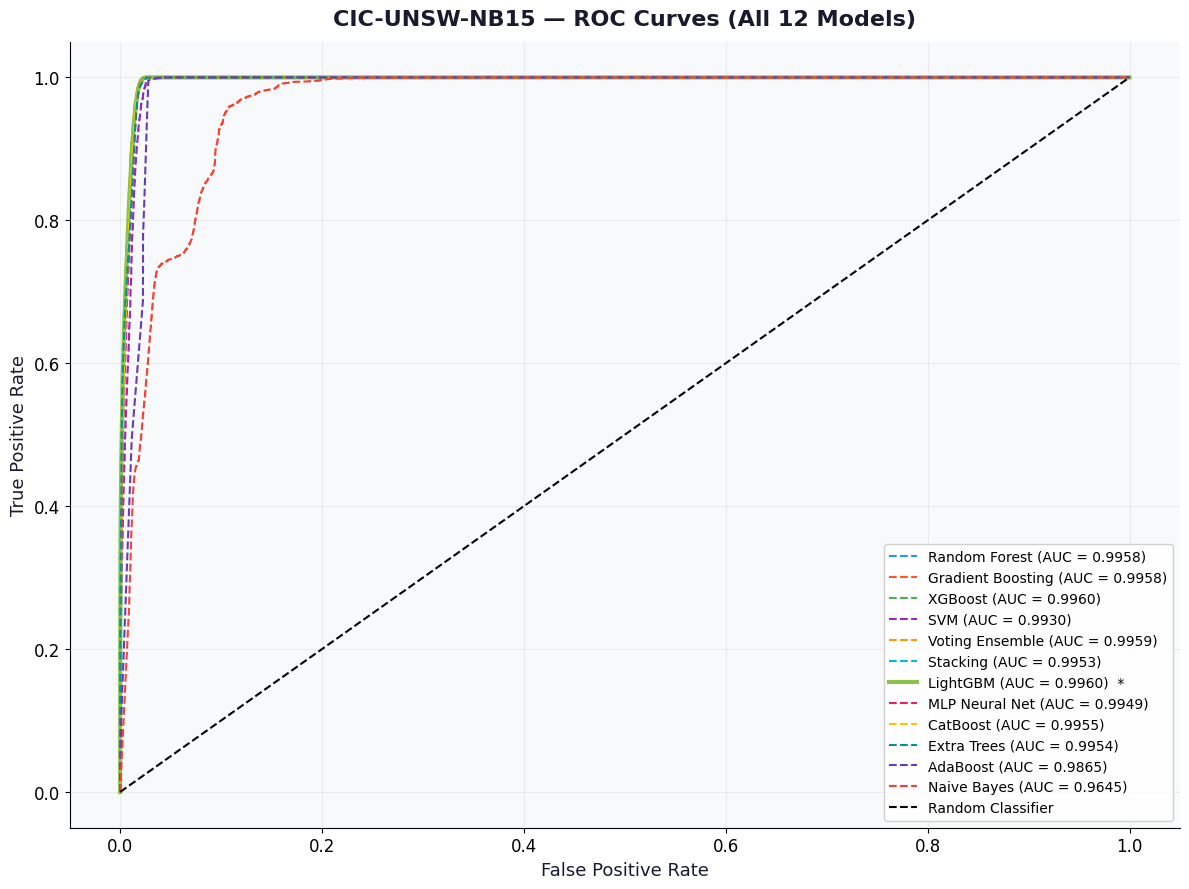

Saved: cicunsw_roc_curves.png


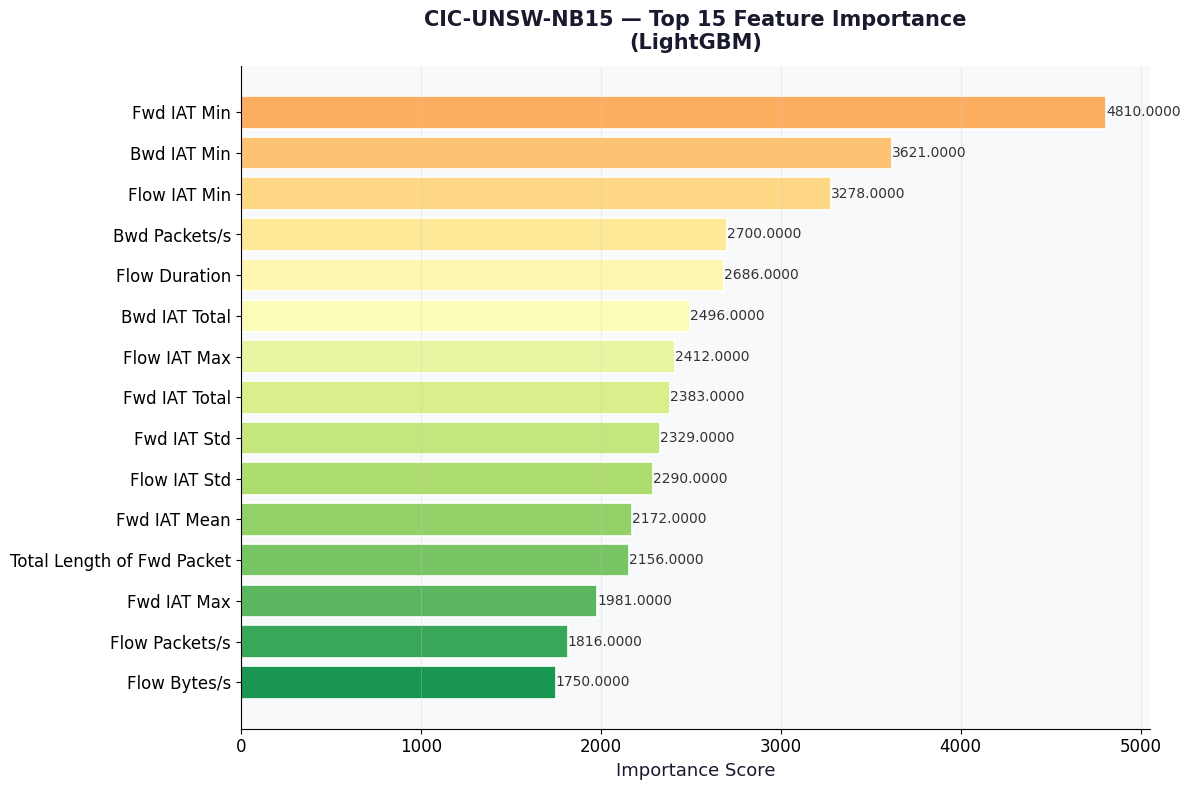

Saved: cicunsw_feature_importance.png

All visualizations saved:
  cicunsw_model_comparison.png
  cicunsw_confusion_matrices.png
  cicunsw_roc_curves.png
  cicunsw_feature_importance.png


In [ ]:
#  CELL 25 — CIC-UNSW-NB15: Results Visualizations

from sklearn.metrics import roc_curve, auc as sk_auc
from matplotlib.patches import Patch

model_names = list(results_cic.keys())
f1_scores   = [results_cic[m]["f1"]       for m in model_names]
acc_scores  = [results_cic[m]["accuracy"] for m in model_names]
auc_scores  = [results_cic[m]["auc"]      for m in model_names]
best_idx    = model_names.index(best_name_cic)

model_colors = {
    "Random Forest"    : "#2196F3",
    "Gradient Boosting": "#FF5722",
    "XGBoost"          : "#4CAF50",
    "SVM"              : "#9C27B0",
    "Voting Ensemble"  : "#FF9800",
    "Stacking"         : "#00BCD4",
    "LightGBM"         : "#8BC34A",
    "MLP Neural Net"   : "#E91E63",
    "CatBoost"         : "#FFC107",
    "Extra Trees"      : "#009688",
    "AdaBoost"         : "#673AB7",
    "Naive Bayes"      : "#F44336",
}
bar_colors = [model_colors[m] for m in model_names]

short_names = [
    "RF", "GB", "XGB", "SVM",
    "Voting", "Stack", "LGBM", "MLP",
    "CatB", "ET", "Ada", "NB"
]

# ── Figure 1: F1 + Accuracy + AUC Vertical Bar Charts ─────
fig, axes = plt.subplots(3, 1, figsize=(16, 22), facecolor='white')
fig.suptitle('CIC-UNSW-NB15 — Model Performance Comparison',
             fontsize=22, fontweight='bold', color='#1a1a2e', y=1.01)

metrics = [
    (f1_scores,  'F1-Score',  (0.20, 1.02)),
    (acc_scores, 'Accuracy',  (0.75, 1.02)),
    (auc_scores, 'AUC-ROC',   (0.90, 1.02)),
]

for ax, (scores, label, ylim) in zip(axes, metrics):
    ax.set_facecolor('#F8F9FA')
    bars = ax.bar(short_names, scores,
                  color=bar_colors, edgecolor='white',
                  linewidth=1.5, width=0.6)
    bars[best_idx].set_edgecolor('#FF5722')
    bars[best_idx].set_linewidth(3)
    ax.set_title(f'{label}', fontsize=18, fontweight='bold',
                 color='#1a1a2e', pad=15)
    ax.set_ylabel(label, fontsize=15, color='#1a1a2e')
    ax.set_ylim(ylim)
    ax.tick_params(axis='x', labelsize=14, colors='#1a1a2e')
    ax.tick_params(axis='y', labelsize=13, colors='#1a1a2e')
    ax.grid(axis='y', alpha=0.3, color='#cccccc')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    for bar, val, name in zip(bars, scores, model_names):
        ax.text(bar.get_x() + bar.get_width()/2, val + 0.001,
                f'{val:.4f}', ha='center', va='bottom', fontsize=12,
                color='#FF5722' if name == best_name_cic else '#333333',
                fontweight='bold' if name == best_name_cic else 'normal')

legend = [Patch(facecolor=model_colors[m], label=m) for m in model_names]
fig.legend(handles=legend, loc='lower center', ncol=4,
           fontsize=12, framealpha=0.9,
           bbox_to_anchor=(0.5, -0.03))

plt.tight_layout(pad=3.0)
plt.savefig('cicunsw_model_comparison.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_model_comparison.png")

# ── Figure 2: Confusion Matrices ──────────────────────────
cmaps = [
    'Blues', 'Oranges', 'Greens', 'Purples',
    'YlOrBr', 'PuBu', 'YlGn', 'RdPu',
    'Wistia', 'GnBu', 'BuPu', 'OrRd'
]

fig, axes = plt.subplots(3, 4, figsize=(22, 16), facecolor='white')
fig.suptitle('CIC-UNSW-NB15 — Confusion Matrices (All 12 Models)',
             fontsize=18, fontweight='bold', color='#1a1a2e')

for idx, (name, res) in enumerate(results_cic.items()):
    ax = axes.flatten()[idx]
    cm = confusion_matrix(y_test_cic, res["y_pred"])
    sns.heatmap(cm, annot=True, fmt='d', ax=ax,
                cmap=cmaps[idx],
                annot_kws={"size": 16, "weight": "bold"},
                linewidths=1.5, linecolor='white',
                cbar=False)
    title_color = '#FF5722' if name == best_name_cic else '#1a1a2e'
    ax.set_title(f'{name}{"  *" if name == best_name_cic else ""}',
                 fontsize=13, fontweight='bold',
                 color=title_color, pad=8)
    ax.set_xlabel('Predicted', fontsize=11, color='#333333')
    ax.set_ylabel('Actual', fontsize=11, color='#333333')
    ax.set_xticklabels(['Benign', 'Attack'], fontsize=11)
    ax.set_yticklabels(['Benign', 'Attack'], fontsize=11, rotation=0)

plt.tight_layout(pad=2.5)
plt.savefig('cicunsw_confusion_matrices.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_confusion_matrices.png")

# ── Figure 3: ROC Curves ──────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 9), facecolor='white')
ax.set_facecolor('#F8F9FA')

for name, res in results_cic.items():
    fpr, tpr, _ = roc_curve(y_test_cic, res["y_prob"])
    roc_auc     = sk_auc(fpr, tpr)
    lw          = 3.0 if name == best_name_cic else 1.5
    ls          = '-'  if name == best_name_cic else '--'
    ax.plot(fpr, tpr, color=model_colors[name],
            lw=lw, linestyle=ls,
            label=f'{name} (AUC = {roc_auc:.4f})'
                  f'{"  *" if name == best_name_cic else ""}')

ax.plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Classifier')
ax.set_xlabel('False Positive Rate', fontsize=13, color='#1a1a2e')
ax.set_ylabel('True Positive Rate', fontsize=13, color='#1a1a2e')
ax.set_title('CIC-UNSW-NB15 — ROC Curves (All 12 Models)',
             fontsize=16, fontweight='bold', color='#1a1a2e', pad=12)
ax.legend(loc='lower right', fontsize=10,
          framealpha=0.9, edgecolor='#cccccc')
ax.tick_params(labelsize=12)
ax.grid(alpha=0.3, color='#cccccc')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('cicunsw_roc_curves.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_roc_curves.png")

# ── Figure 4: Feature Importance (Top 15) ─────────────────
feat_names  = list(X_cic.columns)
importances = best_res_cic["model"].feature_importances_
indices     = np.argsort(importances)[::-1][:15]
colors_fi   = plt.cm.RdYlGn(np.linspace(0.3, 0.9, 15))[::-1]

fig, ax = plt.subplots(figsize=(12, 8), facecolor='white')
ax.set_facecolor('#F8F9FA')
bars = ax.barh([feat_names[i] for i in indices[::-1]],
               importances[indices[::-1]],
               color=colors_fi, edgecolor='white', linewidth=1.2)
ax.set_title(f'CIC-UNSW-NB15 — Top 15 Feature Importance\n({best_name_cic})',
             fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Importance Score', fontsize=13, color='#1a1a2e')
ax.tick_params(labelsize=12)
ax.grid(axis='x', alpha=0.3, color='#cccccc')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, val in zip(bars, importances[indices[::-1]]):
    ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', fontsize=10, color='#333333')

plt.tight_layout()
plt.savefig('cicunsw_feature_importance.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_feature_importance.png")

print("\nAll visualizations saved:")
print("  cicunsw_model_comparison.png")
print("  cicunsw_confusion_matrices.png")
print("  cicunsw_roc_curves.png")
print("  cicunsw_feature_importance.png")

Adaptive Risk Engine — CIC-UNSW-NB15
--------------------------------------------------
Total flows    : 89,583
LOW  Risk      : 70,200  (78.4%)  -> AES-256
MEDIUM Risk    : 112  (0.1%)  -> AES-256 + Monitor
HIGH Risk      : 19,271  (21.5%)  -> BB84 QKD
Overhead Saved : 78.5% vs naive full-QKD

BB84 QKD Simulation — CIC-UNSW-NB15
--------------------------------------------------
Clean Channel        | Eve: 0.00 | QBER: 0.0000 ± 0.0000 | Secure: 100.0%
Low Eavesdrop        | Eve: 0.10 | QBER: 0.0227 ± 0.0130 | Secure: 100.0%
High Eavesdrop       | Eve: 0.75 | QBER: 0.1916 ± 0.0394 | Secure: 2.0%


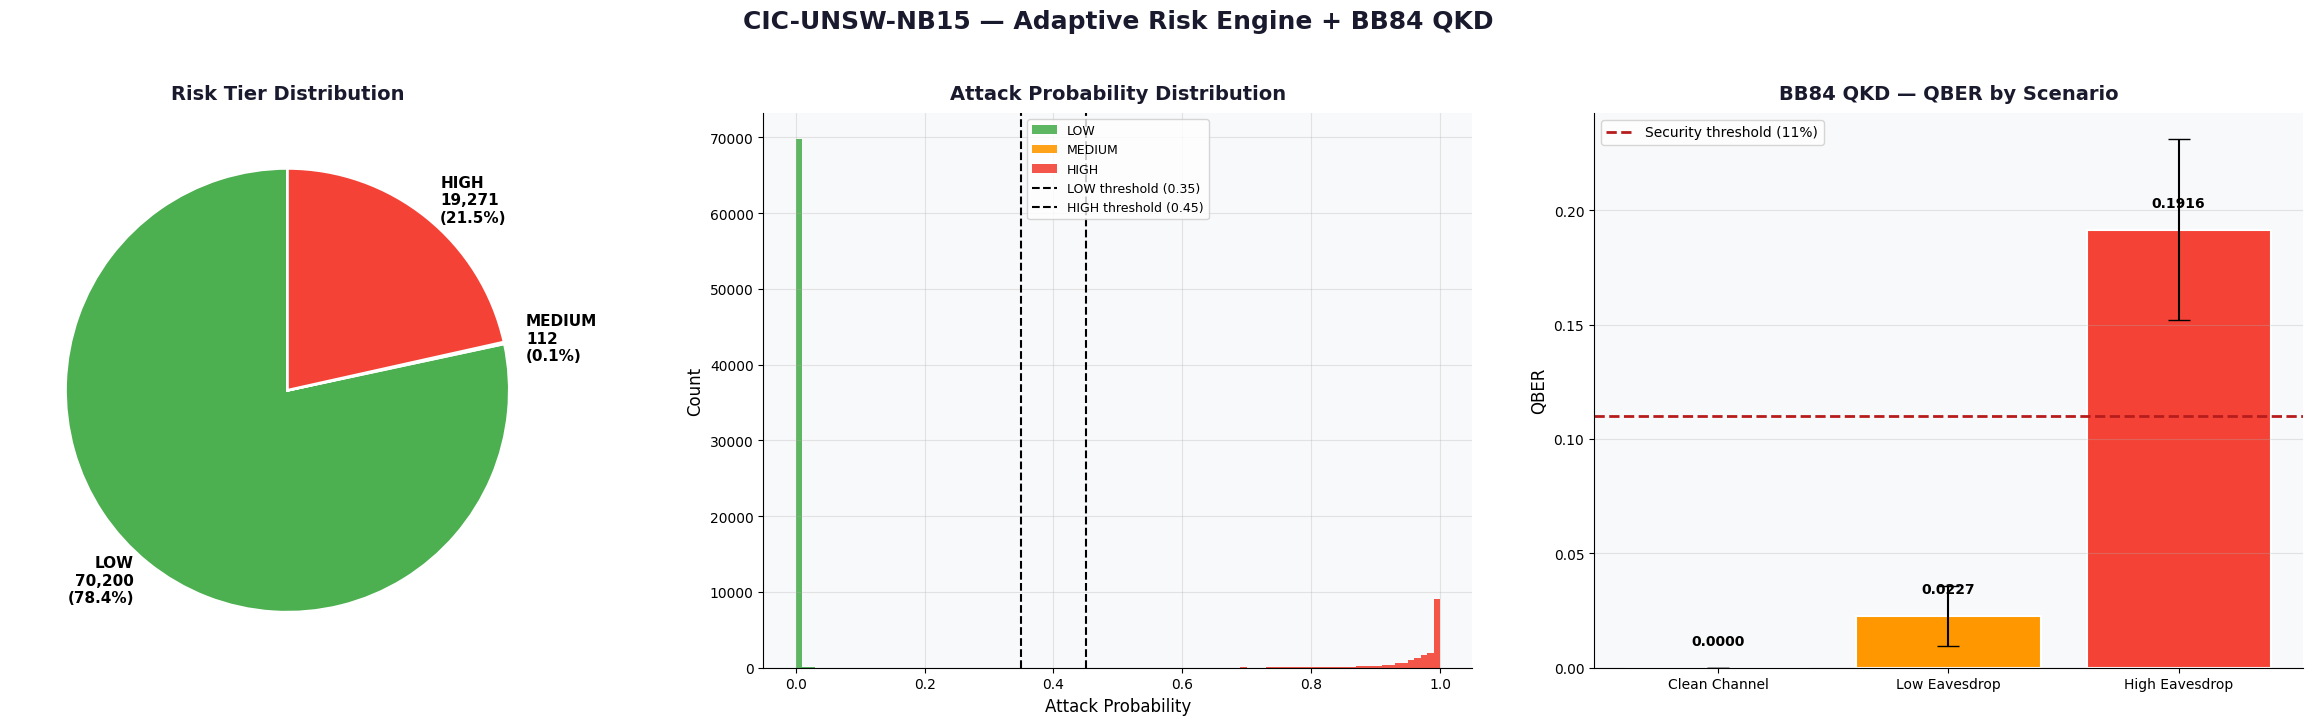

Saved: cicunsw_risk_bb84.png


In [ ]:
#  CELL 26 (FIXED) — CIC-UNSW-NB15: Adaptive Risk Engine + BB84 QKD (3-panel viz)

print(f"Adaptive Risk Engine — {CURRENT_DATASET}")
print("-" * 50)

risk_probs = best_res_cic["y_prob"]

LOW_THRESHOLD  = 0.35
HIGH_THRESHOLD = best_t_cic

risk_tiers = []
for p in risk_probs:
    if p < LOW_THRESHOLD:
        risk_tiers.append("LOW")
    elif p < HIGH_THRESHOLD:
        risk_tiers.append("MEDIUM")
    else:
        risk_tiers.append("HIGH")

risk_df = pd.DataFrame({
    "attack_prob": risk_probs,
    "risk_tier"  : risk_tiers,
    "true_label" : y_test_cic
})

n_total  = len(risk_df)
n_low    = (risk_df["risk_tier"] == "LOW").sum()
n_medium = (risk_df["risk_tier"] == "MEDIUM").sum()
n_high   = (risk_df["risk_tier"] == "HIGH").sum()
qkd_pct  = n_high / n_total * 100

print(f"Total flows    : {n_total:,}")
print(f"LOW  Risk      : {n_low:,}  ({n_low/n_total*100:.1f}%)  -> AES-256")
print(f"MEDIUM Risk    : {n_medium:,}  ({n_medium/n_total*100:.1f}%)  -> AES-256 + Monitor")
print(f"HIGH Risk      : {n_high:,}  ({n_high/n_total*100:.1f}%)  -> BB84 QKD")
print(f"Overhead Saved : {100 - qkd_pct:.1f}% vs naive full-QKD")

# ── BB84 QKD Simulation ───────────────────────────────────
print(f"\nBB84 QKD Simulation — {CURRENT_DATASET}")
print("-" * 50)

qkd_scenarios = [
    ("Clean Channel",  0.00),
    ("Low Eavesdrop",  0.10),
    ("High Eavesdrop", 0.75),
]

qkd_results_cic = {}
for scenario, eve_prob in qkd_scenarios:
    sessions = [BB84Simulation(256, eve_prob).run() for _ in range(100)]
    qkd_results_cic[scenario] = {
        "eve_prob"  : eve_prob,
        "qber_mean" : float(np.mean([s["qber"]   for s in sessions])),
        "qber_std"  : float(np.std([s["qber"]    for s in sessions])),
        "pct_secure": float(np.mean([s["secure"] for s in sessions]) * 100),
    }
    r = qkd_results_cic[scenario]
    print(f"{scenario:<20} | Eve: {eve_prob:.2f} | "
          f"QBER: {r['qber_mean']:.4f} ± {r['qber_std']:.4f} | "
          f"Secure: {r['pct_secure']:.1f}%")

# ── Visualization: 3-panel (Pie + Probability Histogram + QBER bar) ──
fig, axes = plt.subplots(1, 3, figsize=(24, 7), facecolor='white')
fig.suptitle('CIC-UNSW-NB15 — Adaptive Risk Engine + BB84 QKD',
             fontsize=18, fontweight='bold', color='#1a1a2e', y=1.03)

# Panel 1 — Risk tier pie
ax1 = axes[0]
tier_counts = [n_low, n_medium, n_high]
tier_labels = [f'LOW\n{n_low:,}\n({n_low/n_total*100:.1f}%)',
               f'MEDIUM\n{n_medium:,}\n({n_medium/n_total*100:.1f}%)',
               f'HIGH\n{n_high:,}\n({n_high/n_total*100:.1f}%)']
colors_tier = ['#4CAF50', '#FF9800', '#F44336']
ax1.pie(tier_counts, labels=tier_labels, colors=colors_tier,
        autopct='', startangle=90,
        wedgeprops={'edgecolor': 'white', 'linewidth': 2},
        textprops={'fontsize': 11, 'fontweight': 'bold'})
ax1.set_title('Risk Tier Distribution', fontsize=14, fontweight='bold',
              color='#1a1a2e', pad=10)

# Panel 2 — Attack Probability Distribution histogram
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
low_probs    = risk_df[risk_df["risk_tier"] == "LOW"]["attack_prob"]
medium_probs = risk_df[risk_df["risk_tier"] == "MEDIUM"]["attack_prob"]
high_probs   = risk_df[risk_df["risk_tier"] == "HIGH"]["attack_prob"]

bins = np.linspace(0, 1, 101)
ax2.hist(low_probs,    bins=bins, color='#4CAF50', label='LOW',    alpha=0.9)
ax2.hist(medium_probs, bins=bins, color='#FF9800', label='MEDIUM', alpha=0.9)
ax2.hist(high_probs,   bins=bins, color='#F44336', label='HIGH',   alpha=0.9)
ax2.axvline(LOW_THRESHOLD,  color='black', linestyle='--', linewidth=1.5,
            label=f'LOW threshold ({LOW_THRESHOLD:.2f})')
ax2.axvline(HIGH_THRESHOLD, color='black', linestyle='--', linewidth=1.5,
            label=f'HIGH threshold ({HIGH_THRESHOLD:.2f})')
ax2.set_title('Attack Probability Distribution', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)
ax2.set_xlabel('Attack Probability', fontsize=12)
ax2.set_ylabel('Count', fontsize=12)
ax2.legend(fontsize=9, loc='upper center')
ax2.grid(alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

# Panel 3 — QBER bar
ax3 = axes[2]
ax3.set_facecolor('#F8F9FA')
scenario_names = list(qkd_results_cic.keys())
qber_means = [qkd_results_cic[s]["qber_mean"] for s in scenario_names]
qber_stds  = [qkd_results_cic[s]["qber_std"]  for s in scenario_names]
colors_qber = ['#4CAF50', '#FF9800', '#F44336']
bars = ax3.bar(scenario_names, qber_means, yerr=qber_stds,
               color=colors_qber, edgecolor='white', linewidth=1.5,
               capsize=8)
ax3.axhline(y=0.11, color='#B71C1C', linestyle='--', linewidth=2,
            label='Security threshold (11%)')
ax3.set_title('BB84 QKD — QBER by Scenario', fontsize=14,
              fontweight='bold', color='#1a1a2e', pad=10)
ax3.set_ylabel('QBER', fontsize=12)
ax3.legend(fontsize=10)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)
for bar, val in zip(bars, qber_means):
    ax3.text(bar.get_x()+bar.get_width()/2, val+0.01, f'{val:.4f}',
              ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('cicunsw_risk_bb84.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_risk_bb84.png")

SHAP Analysis — CIC-UNSW-NB15 — LightGBM
--------------------------------------------------
Top 10 Features by SHAP value:
   1. Fwd Seg Size Min                    6.5337
   2. Bwd Packets/s                       2.3466
   3. Bwd Packet Length Min               0.8649
   4. Fwd IAT Min                         0.2798
   5. FWD Init Win Bytes                  0.2456
   6. Total Length of Bwd Packet          0.2360
   7. Packet Length Max                   0.1474
   8. Bwd IAT Min                         0.1421
   9. Bwd Init Win Bytes                  0.1279
  10. Flow Duration                       0.1215


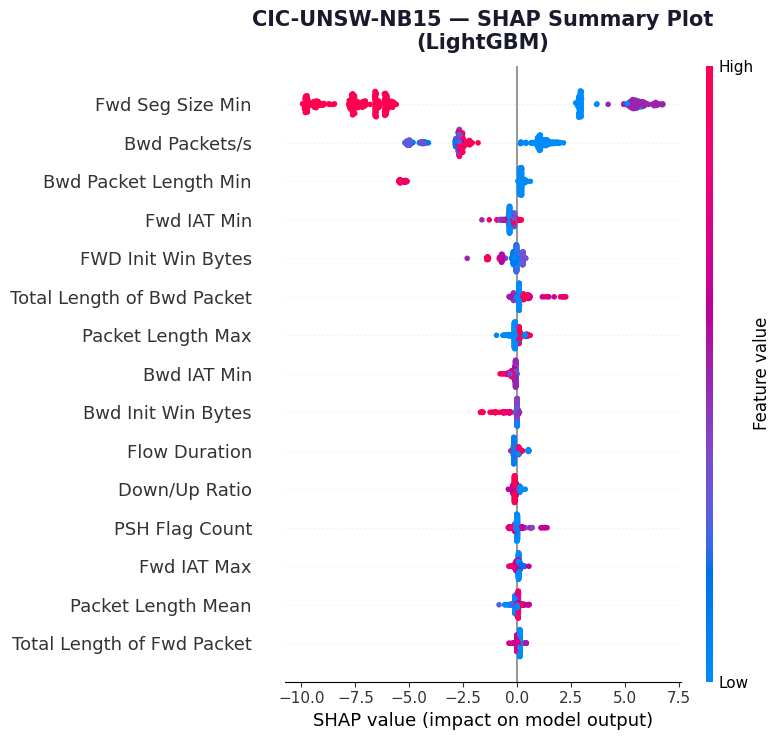

Saved: cicunsw_shap_dot.png


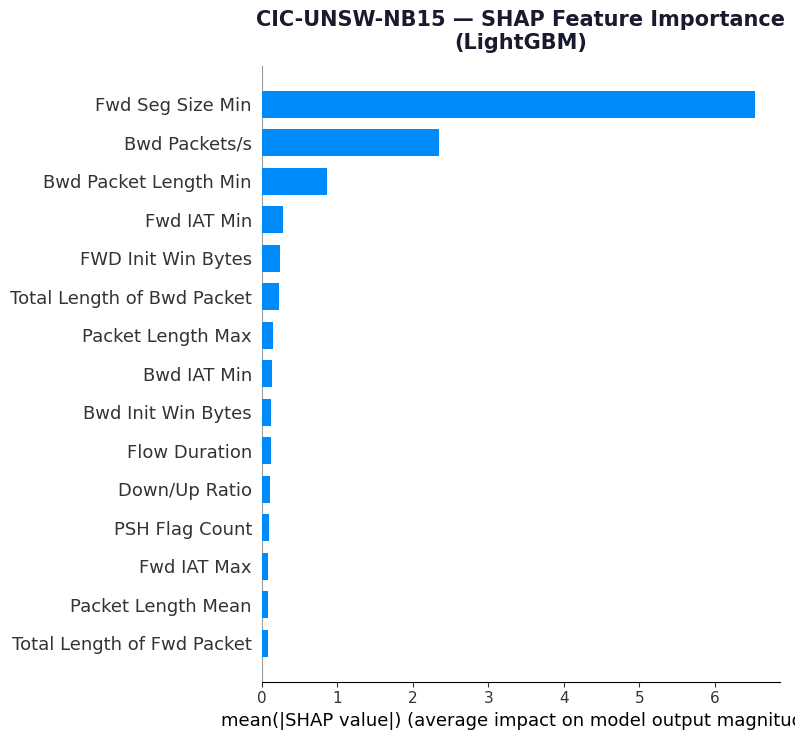

Saved: cicunsw_shap_bar.png


In [ ]:
#  CELL 27 — CIC-UNSW-NB15: SHAP XAI

import shap
print(f"SHAP Analysis — {CURRENT_DATASET} — {best_name_cic}")
print("-" * 50)

# SHAP Explainer
explainer_cic  = shap.TreeExplainer(best_res_cic["model"])
X_shap_cic     = pd.DataFrame(X_test_cic, columns=X_cic.columns)
shap_sample    = X_shap_cic.sample(500, random_state=42)
shap_vals_cic  = explainer_cic.shap_values(shap_sample)

# Handle shape
if isinstance(shap_vals_cic, list):
    sv = shap_vals_cic[1]
else:
    sv = shap_vals_cic

# Top 10 features
mean_shap       = np.abs(sv).mean(axis=0)
feature_imp_cic = pd.Series(mean_shap,
                             index=X_cic.columns).sort_values(ascending=False)

print("Top 10 Features by SHAP value:")
for i, (feat, val) in enumerate(feature_imp_cic.head(10).items()):
    print(f"  {i+1:2}. {feat:<35} {val:.4f}")

# ── Plot 1: SHAP Summary Dot Plot ─────────────────────────
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(sv, shap_sample,
                  max_display=15,
                  show=False,
                  plot_type="dot")
plt.title(f'CIC-UNSW-NB15 — SHAP Summary Plot\n({best_name_cic})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('cicunsw_shap_dot.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_shap_dot.png")

# ── Plot 2: SHAP Bar Plot ──────────────────────────────────
plt.figure(figsize=(12, 8), facecolor='white')
shap.summary_plot(sv, shap_sample,
                  max_display=15,
                  show=False,
                  plot_type="bar")
plt.title(f'CIC-UNSW-NB15 — SHAP Feature Importance\n({best_name_cic})',
          fontsize=15, fontweight='bold', color='#1a1a2e', pad=12)
plt.tight_layout()
plt.savefig('cicunsw_shap_bar.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_shap_bar.png")

In [ ]:
#  CELL 27B — CIC-UNSW-NB15: Multiclass Attack-Category Model

print(f"Multiclass Attack-Category Classification — {CURRENT_DATASET}")
print("-" * 50)

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from collections import Counter
from sklearn.metrics import classification_report, accuracy_score as acc_score, f1_score as f1_sc

label_names_cic = {
    0: "Benign", 1: "Analysis", 2: "Backdoor", 3: "DoS", 4: "Exploits",
    5: "Fuzzers", 6: "Generic", 7: "Reconnaissance", 8: "Shellcode", 9: "Worms"
}

# Native multiclass label, aligned to X_cic's index (df_cic still has the
# raw numeric label column before it was dropped during binary preprocessing)
y_mc_full_cic = df_cic.loc[X_cic.index, cfg["label_col"]].map(label_names_cic)

print("No rare-class merge needed (smallest class Worms=246 > 100)")

X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    X_cic, y_mc_full_cic, test_size=0.20, stratify=y_mc_full_cic, random_state=42
)
print(f"Train: {X_train_mc.shape} | Test: {X_test_mc.shape} (kept ORIGINAL distribution)")

UNDER_CAP, OVER_FLOOR, MAX_MULT = 15000, 3000, 10
train_counts = Counter(y_train_mc)
print(f"\nTrain class counts BEFORE resampling:")
for k, v in sorted(train_counts.items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")

under_strategy = {c: UNDER_CAP for c, n in train_counts.items() if n > UNDER_CAP}
over_strategy  = {c: min(OVER_FLOOR, n * MAX_MULT) for c, n in train_counts.items() if n < OVER_FLOOR}

resample_pipe = ImbPipeline(steps=[
    ('under', RandomUnderSampler(sampling_strategy=under_strategy, random_state=42)
              if under_strategy else 'passthrough'),
    ('over',  SMOTE(sampling_strategy=over_strategy, random_state=42, k_neighbors=5)
              if over_strategy else 'passthrough'),
])
X_train_mc_bal, y_train_mc_bal = resample_pipe.fit_resample(X_train_mc, y_train_mc)

print(f"\nTrain class counts AFTER hybrid resampling:")
for k, v in sorted(Counter(y_train_mc_bal).items(), key=lambda x: -x[1]):
    print(f"  {k}: {v}")
print(f"\nBalanced train shape: {X_train_mc_bal.shape}")

mc_model_cic = RandomForestClassifier(n_estimators=300, max_depth=20,
                                       random_state=42, n_jobs=-1)
mc_model_cic.fit(X_train_mc_bal, y_train_mc_bal)
y_pred_mc = mc_model_cic.predict(X_test_mc)

print(f"\nAccuracy      : {acc_score(y_test_mc, y_pred_mc):.4f}")
print(f"Macro F1      : {f1_sc(y_test_mc, y_pred_mc, average='macro'):.4f}")
print(f"Weighted F1   : {f1_sc(y_test_mc, y_pred_mc, average='weighted'):.4f}")
print(f"\nPer-class report:")
print(classification_report(y_test_mc, y_pred_mc))

Multiclass Attack-Category Classification — CIC-UNSW-NB15
--------------------------------------------------
No rare-class merge needed (smallest class Worms=246 > 100)
Train: (358332, 66) | Test: (89583, 66) (kept ORIGINAL distribution)

Train class counts BEFORE resampling:
  Benign: 286666
  Exploits: 24761
  Fuzzers: 23690
  Reconnaissance: 13388
  Generic: 3705
  DoS: 3573
  Shellcode: 1682
  Backdoor: 362
  Analysis: 308
  Worms: 197

Train class counts AFTER hybrid resampling:
  Benign: 15000
  Exploits: 15000
  Fuzzers: 15000
  Reconnaissance: 13388
  Generic: 3705
  DoS: 3573
  Analysis: 3000
  Backdoor: 3000
  Shellcode: 3000
  Worms: 1970

Balanced train shape: (76636, 66)

Accuracy      : 0.9323
Macro F1      : 0.6402
Weighted F1   : 0.9350

Per-class report:
                precision    recall  f1-score   support

      Analysis       0.28      0.84      0.42        77
      Backdoor       0.64      0.58      0.61        90
        Benign       1.00      0.97      0.99    

Attack-Type-Aware Response Engine — CIC-UNSW-NB15
--------------------------------------------------
HIGH-risk flows analyzed: 19,271

Predicted attack-type breakdown (HIGH-risk flows only):
  Fuzzers             :   8,698 (45.1%)
  Exploits            :   5,386 (27.9%)
  Reconnaissance      :   2,920 (15.2%)
  Generic             :     860 (4.5%)
  DoS                 :     638 (3.3%)
  Shellcode           :     425 (2.2%)
  Analysis            :     207 (1.1%)
  Backdoor            :      78 (0.4%)
  Worms               :      49 (0.3%)
  Benign              :      10 (0.1%)

Recommended action breakdown:
  Log + monitor                                :  11,825 (61.4%)
  Isolate host + BB84 key refresh + forensics  :   5,386 (27.9%)
  Rate-limit / traffic shaping                 :   1,498 (7.8%)
  Immediate isolate + forensics                :     425 (2.2%)
  Immediate isolate + BB84 key refresh         :     127 (0.7%)
  No action                                    :      10 (0.1%)

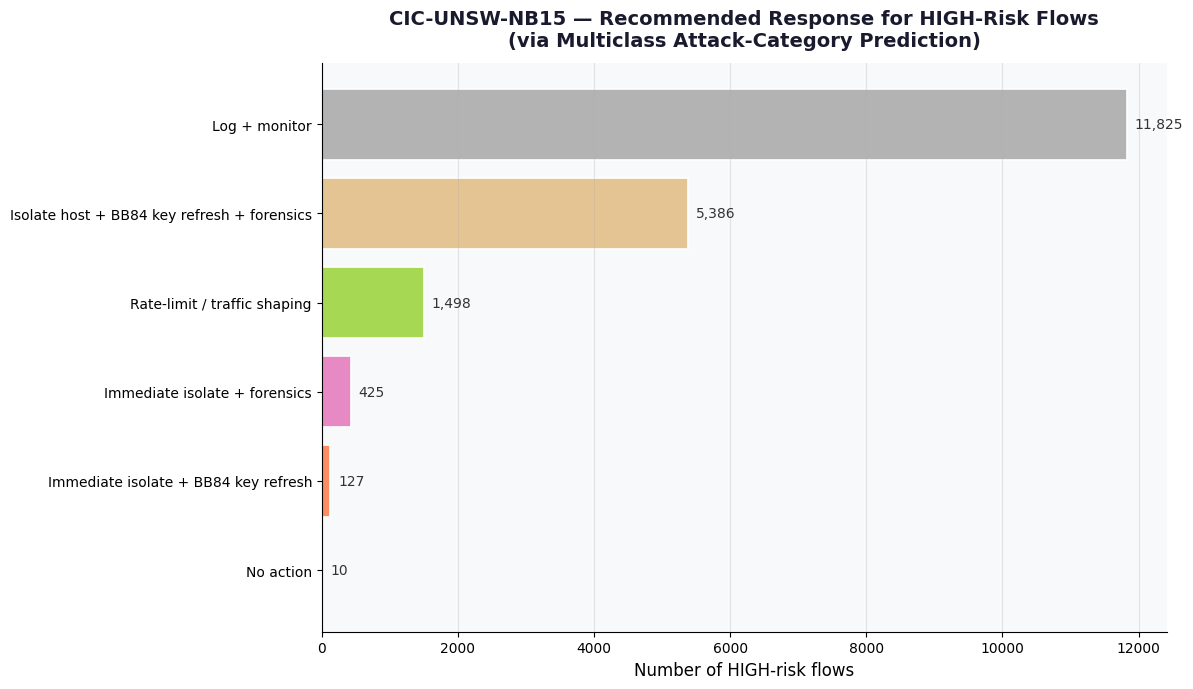

Saved: cicunsw_response_recommendation.png


In [ ]:
#  CELL 27C — CIC-UNSW-NB15: Attack-Type-Aware Response Recommendation

print(f"Attack-Type-Aware Response Engine — {CURRENT_DATASET}")
print("-" * 50)

response_map = {
    "Benign"        : "No action",
    "Analysis"      : "Log + monitor",
    "Backdoor"      : "Immediate isolate + BB84 key refresh",
    "DoS"           : "Rate-limit / traffic shaping",
    "Exploits"      : "Isolate host + BB84 key refresh + forensics",
    "Fuzzers"       : "Log + monitor",
    "Generic"       : "Rate-limit / traffic shaping",
    "Reconnaissance": "Log + monitor",
    "Shellcode"     : "Immediate isolate + forensics",
    "Worms"         : "Immediate isolate + BB84 key refresh",
}

high_mask  = (risk_df["risk_tier"] == "HIGH").values
X_high     = X_test_cic[high_mask]
pred_types = mc_model_cic.predict(X_high)

response_df = pd.DataFrame({
    "attack_type"       : pred_types,
    "recommended_action": [response_map.get(t, "Isolate host + manual review") for t in pred_types],
})

action_counts = response_df["recommended_action"].value_counts()
type_counts   = response_df["attack_type"].value_counts()

print(f"HIGH-risk flows analyzed: {len(response_df):,}\n")
print("Predicted attack-type breakdown (HIGH-risk flows only):")
for t, c in type_counts.items():
    print(f"  {t:<20}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

print(f"\nRecommended action breakdown:")
for a, c in action_counts.items():
    print(f"  {a:<45}: {c:>7,} ({c/len(response_df)*100:.1f}%)")

fig, ax = plt.subplots(figsize=(12, 7), facecolor='white')
ax.set_facecolor('#F8F9FA')
colors_resp = plt.cm.Set2(np.linspace(0, 1, len(action_counts)))
bars = ax.barh(action_counts.index[::-1], action_counts.values[::-1],
               color=colors_resp, edgecolor='white', linewidth=1.2)
ax.set_title('CIC-UNSW-NB15 — Recommended Response for HIGH-Risk Flows\n(via Multiclass Attack-Category Prediction)',
             fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax.set_xlabel('Number of HIGH-risk flows', fontsize=12)
ax.grid(axis='x', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
for bar, val in zip(bars, action_counts.values[::-1]):
    ax.text(bar.get_width() + max(action_counts.values)*0.01, bar.get_y()+bar.get_height()/2,
            f'{val:,}', va='center', fontsize=10, color='#333333')

plt.tight_layout()
plt.savefig('cicunsw_response_recommendation.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_response_recommendation.png")

# For Dashboard

In [ ]:
export_app_artifacts(
    dataset_key = "CICUNSW",
    country     = cfg["country"],
    X_test_raw  = X_test_cic,
    y_test      = y_test_cic,
    results     = results_cic,
    best_name   = best_name_cic,
    models_dict = models_cic,
    mc_model    = mc_model_cic,
    X_test_mc   = X_test_mc,
    y_test_mc   = y_test_mc,
    response_map= response_map,
)

Saved: app_artifacts_CICUNSW.pkl (383.4 MB)  |  sample=2000 rows, best_model=LightGBM, needs_scale=False


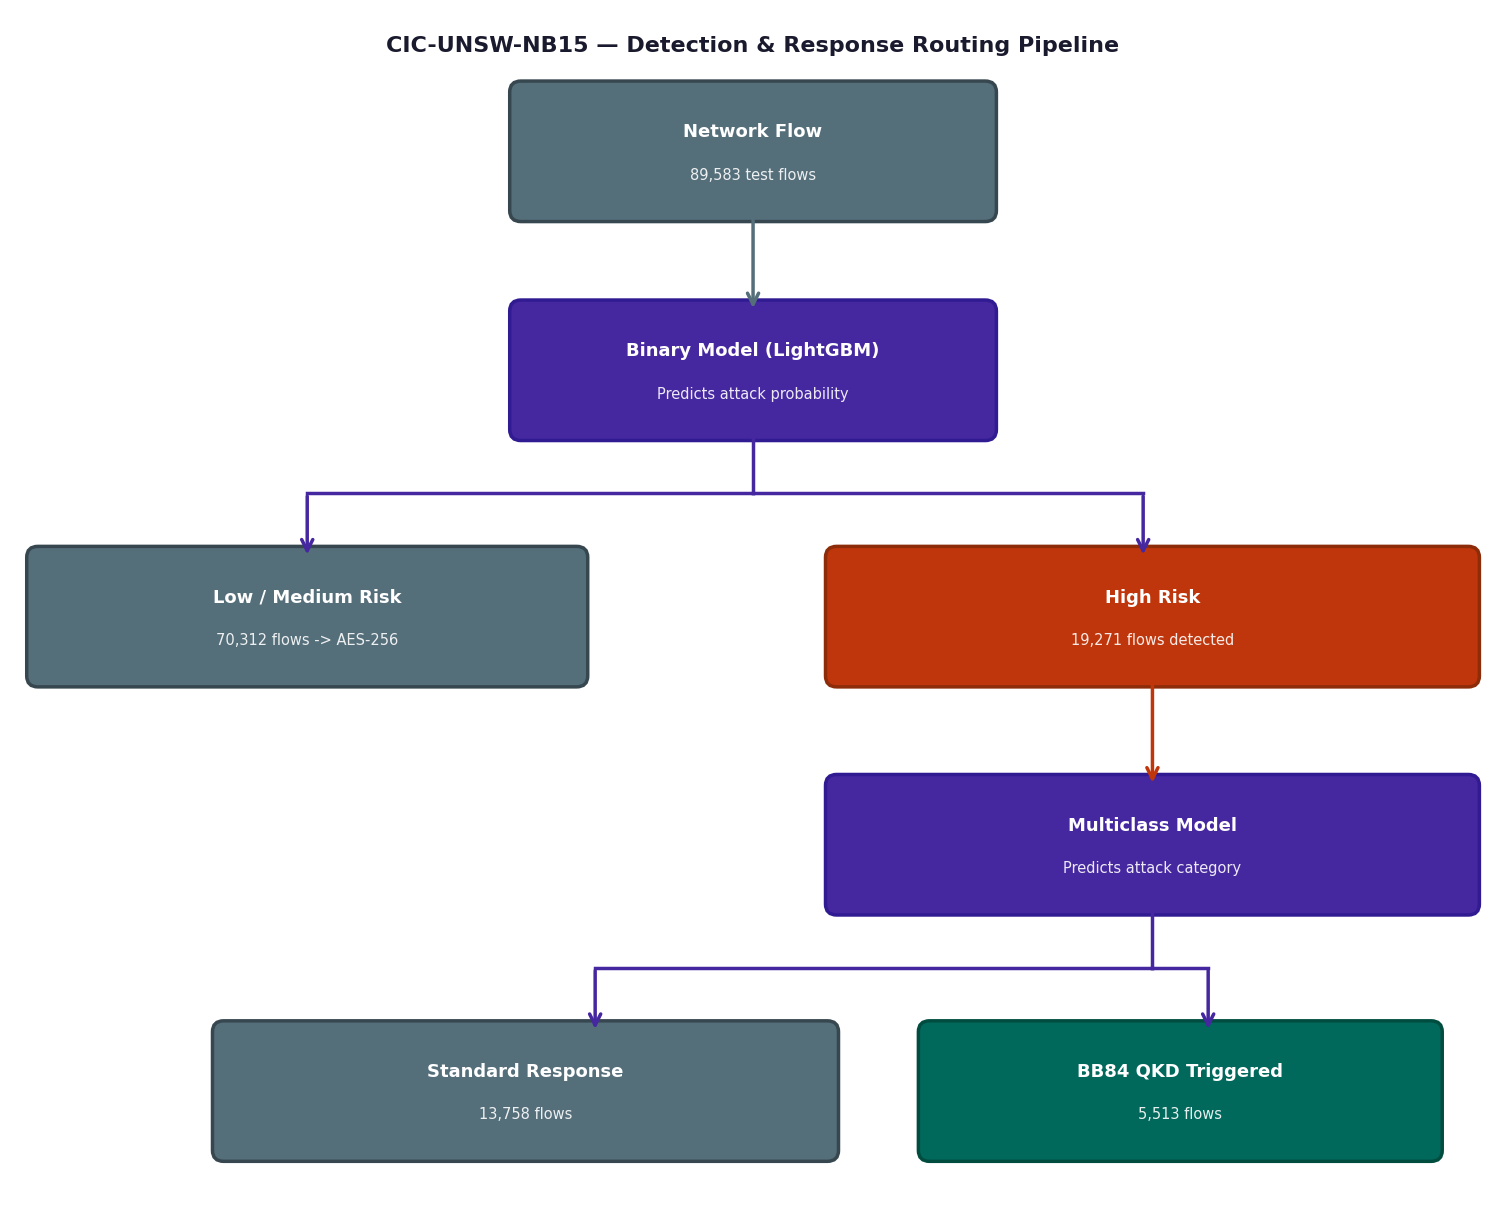

Saved: cicunsw_detection_routing_pipeline.png


In [ ]:
#  CELL 27D — CIC-UNSW-NB15: Detection & Response Routing Pipeline Diagram

from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(15, 12), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(2.4, 15.4)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.66, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.30, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3, alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

ax.text(8, 15.0, 'CIC-UNSW-NB15 — Detection & Response Routing Pipeline',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

draw_box(5.5, 13.2, 5.0, 1.3, 'Network Flow', f'{n_total:,} test flows',
         '#546E7A', '#37474F')
draw_arrow(8.0, 13.2, 8.0, 12.1, '#546E7A')

draw_box(5.5, 10.8, 5.0, 1.3, f'Binary Model ({best_name_cic})', 'Predicts attack probability',
         '#4527A0', '#311B92')

ax.plot([8.0, 8.0], [10.8, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 3.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
ax.plot([8.0, 12.2], [10.1, 10.1], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(3.2, 10.1, 3.2, 9.4, '#4527A0')
draw_arrow(12.2, 10.1, 12.2, 9.4, '#4527A0')

draw_box(0.3, 8.1, 5.8, 1.3, 'Low / Medium Risk', f'{n_low+n_medium:,} flows -> AES-256',
         '#546E7A', '#37474F')
draw_box(8.9, 8.1, 6.8, 1.3, 'High Risk', f'{n_high:,} flows detected',
         '#BF360C', '#8D2C09')
draw_arrow(12.3, 8.1, 12.3, 6.9, '#BF360C')

draw_box(8.9, 5.6, 6.8, 1.3, 'Multiclass Model', 'Predicts attack category',
         '#4527A0', '#311B92')

ax.plot([12.3, 12.3], [5.6, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 6.3], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
ax.plot([12.3, 12.9], [4.9, 4.9], color='#4527A0', lw=2.5, zorder=4)
draw_arrow(6.3, 4.9, 6.3, 4.2, '#4527A0')
draw_arrow(12.9, 4.9, 12.9, 4.2, '#4527A0')

other_count = len(response_df) - (response_df['recommended_action'].str.contains('BB84').sum())
bb84_count  = response_df['recommended_action'].str.contains('BB84').sum()
draw_box(2.3, 2.9, 6.5, 1.3, 'Standard Response', f'{other_count:,} flows',
         '#546E7A', '#37474F')
draw_box(9.9, 2.9, 5.4, 1.3, 'BB84 QKD Triggered', f'{bb84_count:,} flows',
         '#00695C', '#004D40')

plt.tight_layout(pad=0.5)
plt.savefig('cicunsw_detection_routing_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print('Saved: cicunsw_detection_routing_pipeline.png')

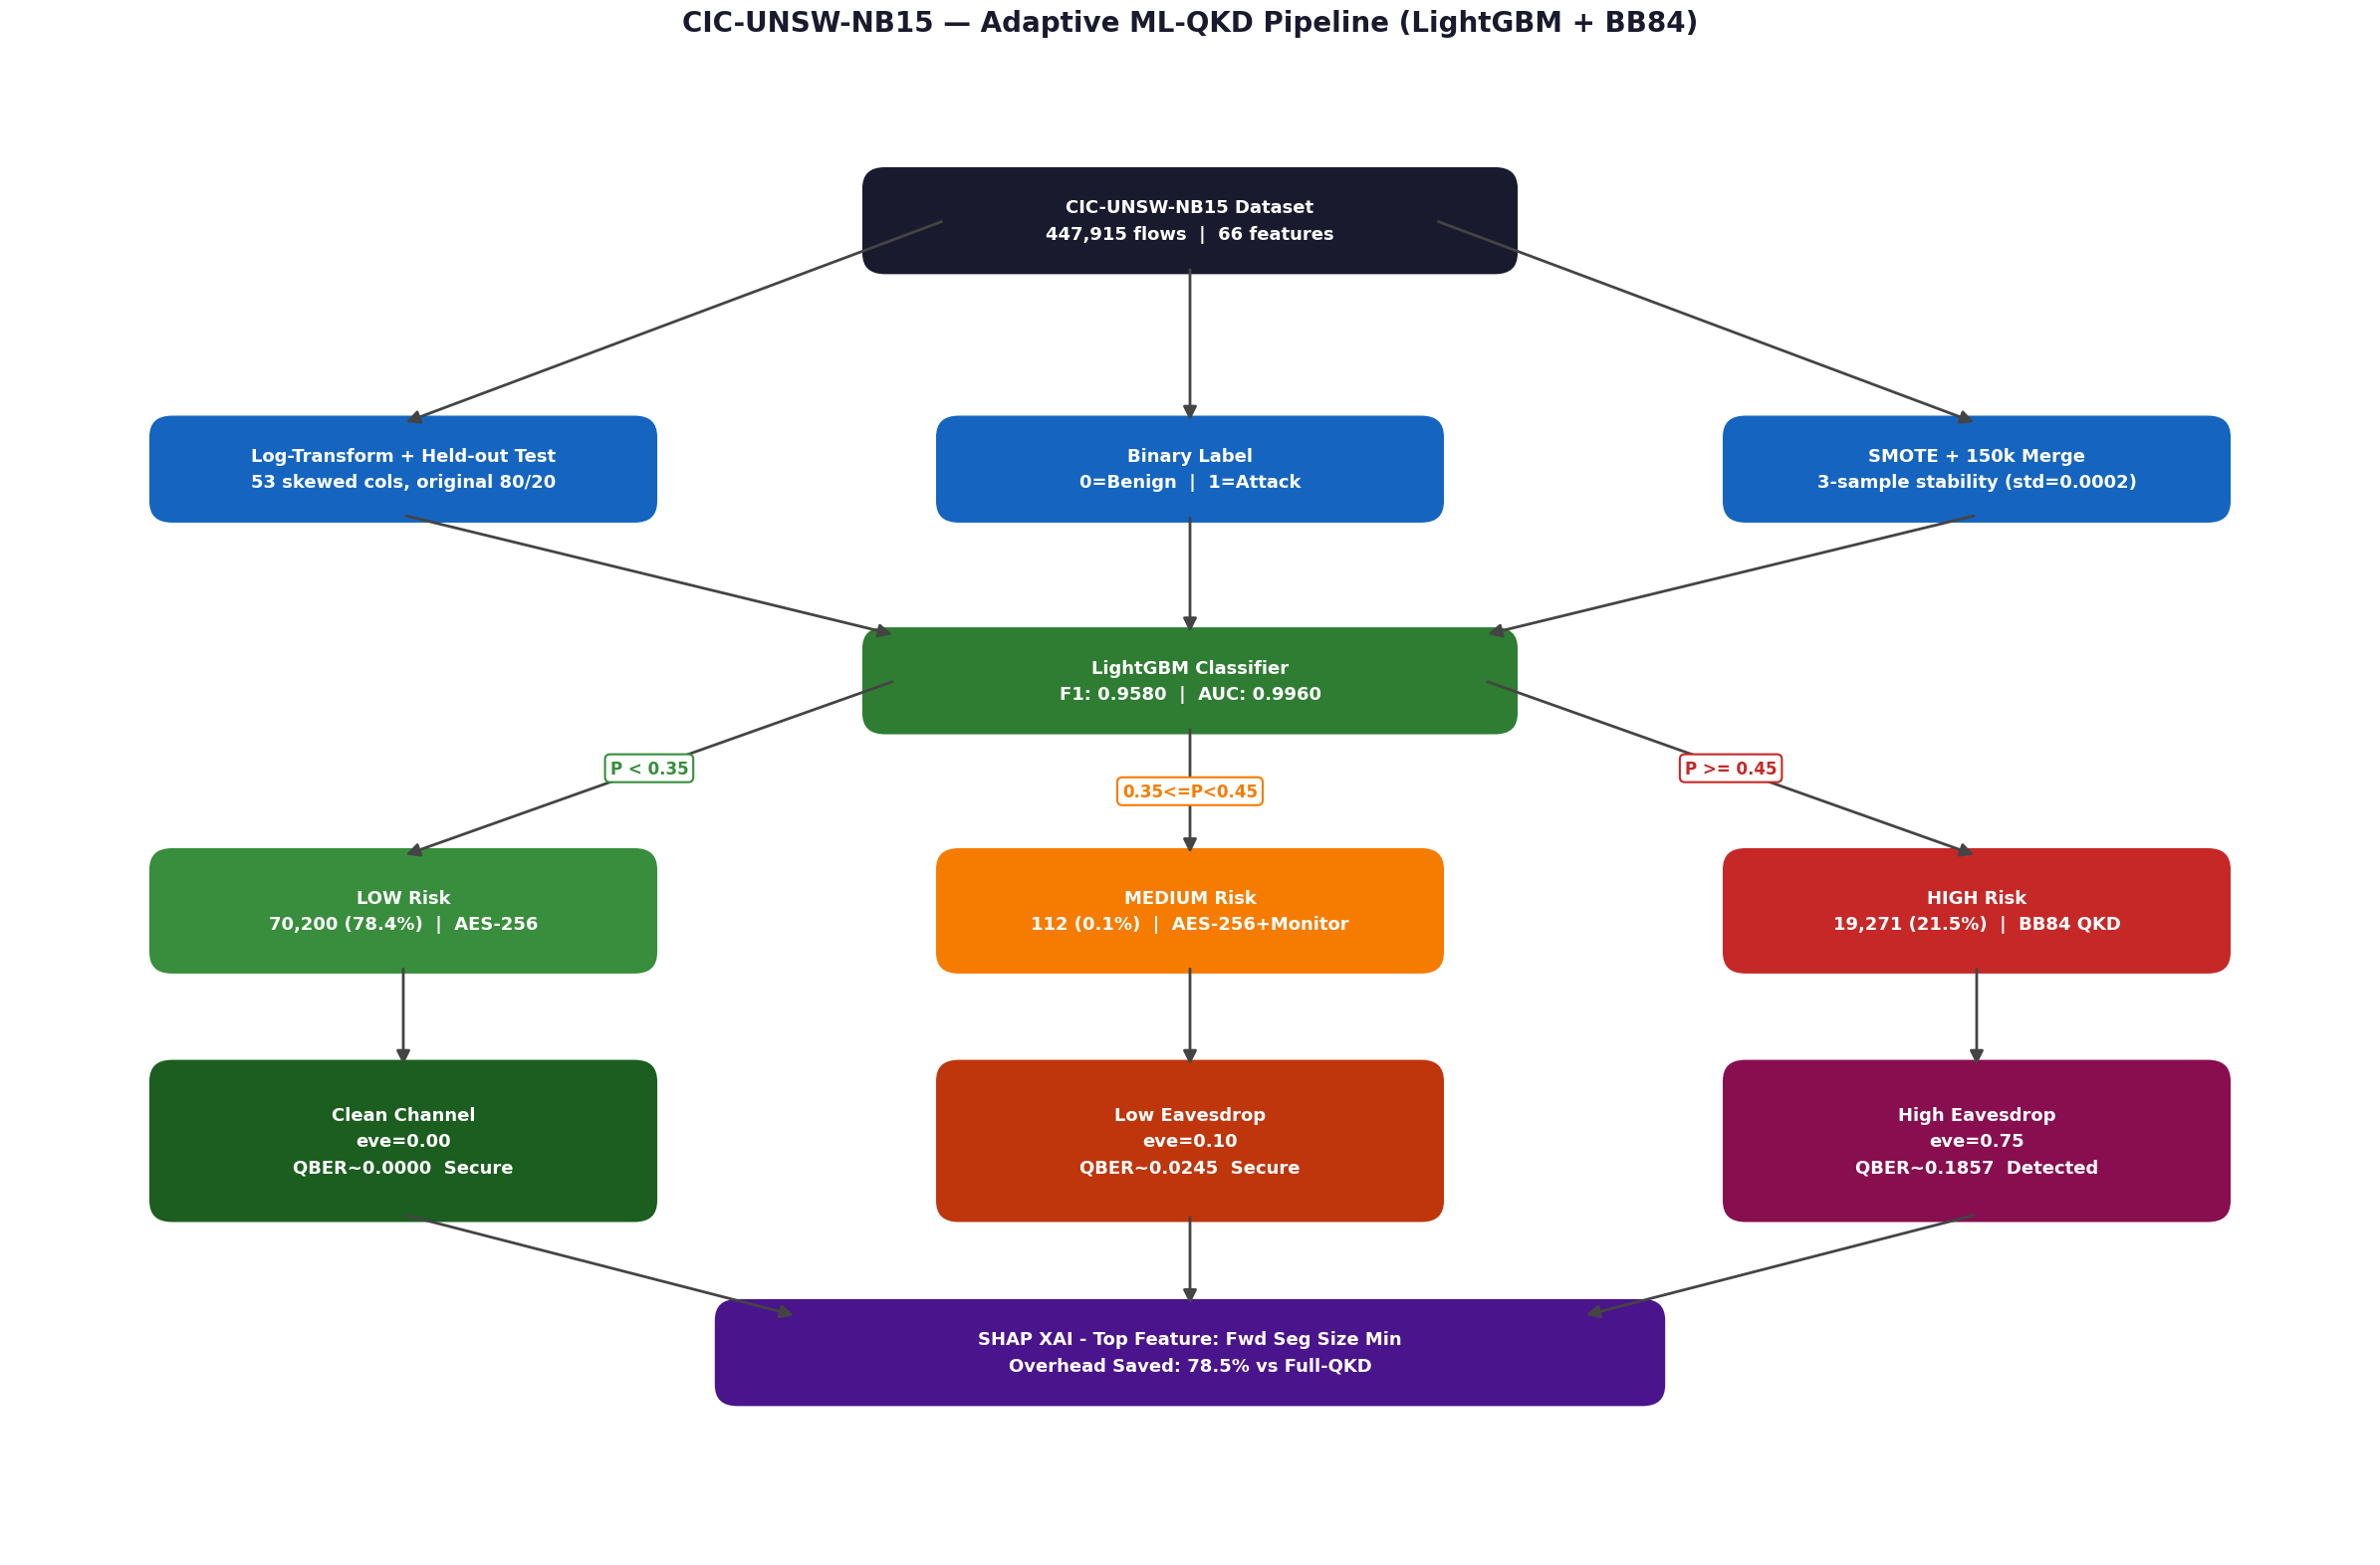

Saved: cicunsw_bb84_pipeline.png


In [ ]:
#  CELL 28 — CIC-UNSW-NB15: BB84 Pipeline Diagram

import matplotlib.patches as mpatches
from matplotlib.patches import FancyBboxPatch

NL = chr(10)  # newline, paste-safe (avoids \n breaking mid-string on paste)

fig, ax = plt.subplots(figsize=(24, 16), facecolor='white')
ax.set_xlim(0, 24)
ax.set_ylim(0, 16)
ax.axis('off')
ax.set_facecolor('white')

fig.suptitle('CIC-UNSW-NB15 — Adaptive ML-QKD Pipeline (LightGBM + BB84)',
             fontsize=20, fontweight='bold', color='#1a1a2e', y=0.98)

def draw_box(ax, x, y, w, h, text, color, fontsize=13, radius=0.25):
    box = FancyBboxPatch((x - w/2, y - h/2), w, h,
                         boxstyle=f"round,pad=0.1,rounding_size={radius}",
                         facecolor=color, edgecolor='white',
                         linewidth=2.5, zorder=3)
    ax.add_patch(box)
    ax.text(x, y, text, ha='center', va='center',
            fontsize=fontsize, fontweight='bold',
            color='white', zorder=4,
            multialignment='center',
            linespacing=1.6)

def draw_arrow(ax, x1, y1, x2, y2, label=None, label_color='#333333'):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="-|>", color='#444444',
                                lw=2.0, mutation_scale=20))
    if label:
        mx = (x1 + x2) / 2
        my = (y1 + y2) / 2
        ax.text(mx, my, label, ha='center', va='center',
                fontsize=12, fontweight='bold', color=label_color,
                bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                          edgecolor=label_color, linewidth=1.5, alpha=1.0),
                zorder=5)

# ── Row 1: Input (y=14.5) ─────────────────────────────────
draw_box(ax, 12, 14.5, 6.5, 1.0,
         "CIC-UNSW-NB15 Dataset" + NL + "447,915 flows  |  66 features",
         '#1a1a2e', fontsize=13)

# ── Row 2: Preprocessing (y=11.8) ─────────────────────────
draw_box(ax,  4, 11.8, 5.0, 1.0,
         "Log-Transform + Held-out Test" + NL + "53 skewed cols, original 80/20",
         '#1565C0', fontsize=13)
draw_box(ax, 12, 11.8, 5.0, 1.0,
         "Binary Label" + NL + "0=Benign  |  1=Attack",
         '#1565C0', fontsize=13)
draw_box(ax, 20, 11.8, 5.0, 1.0,
         "SMOTE + 150k Merge" + NL + "3-sample stability (std=0.0002)",
         '#1565C0', fontsize=13)

draw_arrow(ax,  9.5, 14.5,  4.0, 12.3)
draw_arrow(ax, 12.0, 14.0,  12.0, 12.3)
draw_arrow(ax, 14.5, 14.5,  20.0, 12.3)

# ── Row 3: ML Model (y=9.5) ───────────────────────────────
draw_box(ax, 12, 9.5, 6.5, 1.0,
         "LightGBM Classifier" + NL + "F1: 0.9580  |  AUC: 0.9960",
         '#2E7D32', fontsize=13)

draw_arrow(ax,  4.0, 11.3,  9.0, 10.0)
draw_arrow(ax, 12.0, 11.3,  12.0, 10.0)
draw_arrow(ax, 20.0, 11.3,  15.0, 10.0)

# ── Row 4: Risk Tiers (y=7.0) ─────────────────────────────
draw_box(ax,  4, 7.0, 5.0, 1.2,
         "LOW Risk" + NL + "70,200 (78.4%)  |  AES-256",
         '#388E3C', fontsize=13)
draw_box(ax, 12, 7.0, 5.0, 1.2,
         "MEDIUM Risk" + NL + "112 (0.1%)  |  AES-256+Monitor",
         '#F57C00', fontsize=13)
draw_box(ax, 20, 7.0, 5.0, 1.2,
         "HIGH Risk" + NL + "19,271 (21.5%)  |  BB84 QKD",
         '#C62828', fontsize=13)

draw_arrow(ax,  9.0, 9.5,   4.0, 7.6,
           label='P < 0.35', label_color='#388E3C')
draw_arrow(ax, 12.0, 9.0,  12.0, 7.6,
           label='0.35<=P<0.45', label_color='#F57C00')
draw_arrow(ax, 15.0, 9.5,  20.0, 7.6,
           label='P >= 0.45', label_color='#C62828')

# ── Row 5: BB84 Scenarios (y=4.5) ─────────────────────────
draw_box(ax,  4, 4.5, 5.0, 1.6,
         "Clean Channel" + NL + "eve=0.00" + NL + "QBER~0.0000  Secure",
         '#1B5E20', fontsize=13)
draw_box(ax, 12, 4.5, 5.0, 1.6,
         "Low Eavesdrop" + NL + "eve=0.10" + NL + "QBER~0.0245  Secure",
         '#BF360C', fontsize=13)
draw_box(ax, 20, 4.5, 5.0, 1.6,
         "High Eavesdrop" + NL + "eve=0.75" + NL + "QBER~0.1857  Detected",
         '#880E4F', fontsize=13)

draw_arrow(ax,  4.0, 6.4,   4.0, 5.3)
draw_arrow(ax, 12.0, 6.4,  12.0, 5.3)
draw_arrow(ax, 20.0, 6.4,  20.0, 5.3)

# ── Row 6: SHAP Summary (y=2.2) ───────────────────────────
draw_box(ax, 12, 2.2, 9.5, 1.0,
         "SHAP XAI - Top Feature: Fwd Seg Size Min" + NL + "Overhead Saved: 78.5% vs Full-QKD",
         '#4A148C', fontsize=13)

draw_arrow(ax,  4.0, 3.7,   8.0, 2.6)
draw_arrow(ax, 12.0, 3.7,  12.0, 2.7)
draw_arrow(ax, 20.0, 3.7,  16.0, 2.6)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('cicunsw_bb84_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_bb84_pipeline.png")

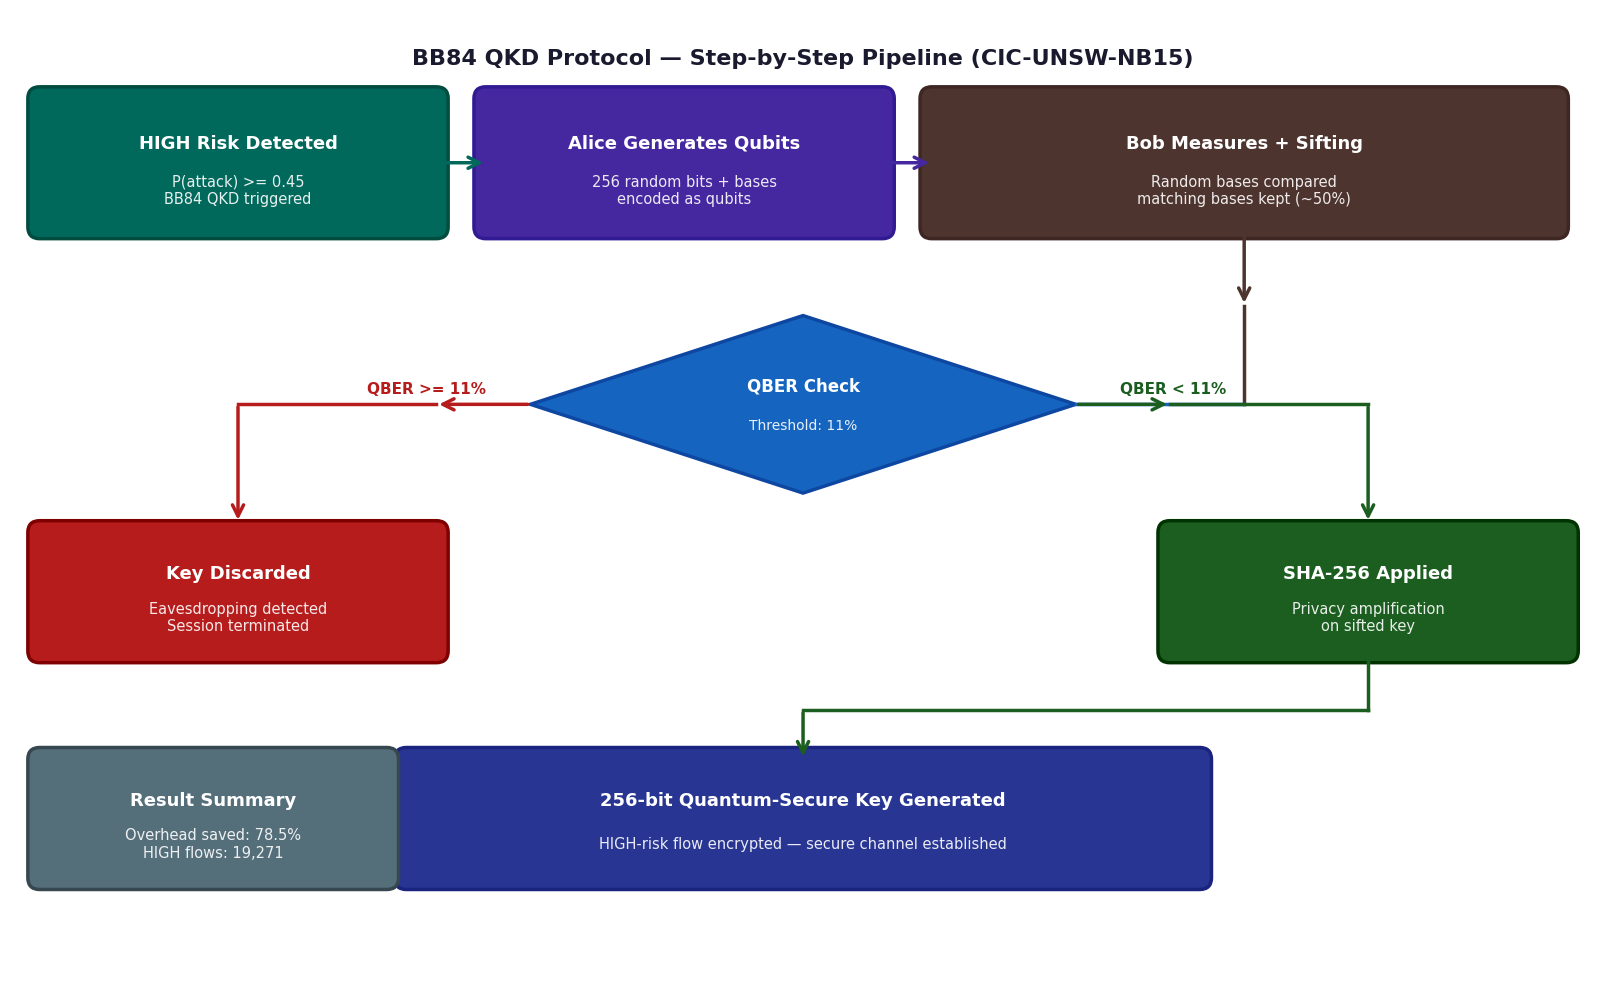

Saved: cicunsw_bb84_protocol_pipeline.png


In [ ]:
#  CELL 28B — CIC-UNSW-NB15: BB84 QKD Protocol — Step-by-Step Pipeline

from matplotlib.patches import FancyBboxPatch

NL = chr(10)

fig, ax = plt.subplots(figsize=(16, 10), facecolor='white')
ax.set_xlim(0, 16)
ax.set_ylim(0, 10)
ax.axis('off')

def draw_box(x, y, w, h, title, subtitle, fc, ec):
    box = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.12',
                         facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2)
    ax.add_patch(box)
    ax.text(x+w/2, y+h*0.65, title, ha='center', va='center',
            fontsize=13, fontweight='bold', color='white', zorder=3)
    ax.text(x+w/2, y+h*0.28, subtitle, ha='center', va='center',
            fontsize=10.5, color='white', zorder=3,
            multialignment='center', alpha=0.9)

def draw_arrow(x1, y1, x2, y2, color):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=color,
                                lw=2.5, mutation_scale=20), zorder=5)

def draw_diamond(cx, cy, w, h, title, subtitle, fc, ec):
    dx = [cx, cx+w/2, cx, cx-w/2]
    dy = [cy+h/2, cy, cy-h/2, cy]
    ax.add_patch(plt.Polygon(list(zip(dx, dy)),
                 facecolor=fc, edgecolor=ec, linewidth=2.5, zorder=2))
    ax.text(cx, cy+0.18, title, ha='center', va='center',
            fontsize=12, fontweight='bold', color='white', zorder=3)
    ax.text(cx, cy-0.22, subtitle, ha='center', va='center',
            fontsize=10, color='white', zorder=3, alpha=0.9)

ax.text(8, 9.5, 'BB84 QKD Protocol — Step-by-Step Pipeline (CIC-UNSW-NB15)',
        ha='center', va='center', fontsize=16,
        fontweight='bold', color='#1a1a2e')

# Step 1 — Teal
draw_box(0.3, 7.8, 4.0, 1.3,
         'HIGH Risk Detected',
         f'P(attack) >= {best_t_cic:.2f}' + NL + 'BB84 QKD triggered',
         '#00695C', '#004D40')
draw_arrow(4.3, 8.45, 4.8, 8.45, '#00695C')

# Step 2 — Deep Purple
draw_box(4.8, 7.8, 4.0, 1.3,
         'Alice Generates Qubits',
         '256 random bits + bases' + NL + 'encoded as qubits',
         '#4527A0', '#311B92')
draw_arrow(8.8, 8.45, 9.3, 8.45, '#4527A0')

# Step 3 — Brown
draw_box(9.3, 7.8, 6.3, 1.3,
         'Bob Measures + Sifting',
         'Random bases compared' + NL + 'matching bases kept (~50%)',
         '#4E342E', '#3E2723')
draw_arrow(12.45, 7.8, 12.45, 7.0, '#4E342E')

# QBER Diamond — Dark Blue
draw_diamond(8.0, 6.0, 5.5, 1.8,
             'QBER Check',
             'Threshold: 11%',
             '#1565C0', '#0D47A1')

ax.plot([12.45, 12.45], [7.0, 6.0], color='#4E342E', lw=2.5, zorder=4)
ax.plot([12.45, 10.75], [6.0, 6.0], color='#1565C0', lw=2.5, zorder=4)

ax.text(4.8, 6.15, 'QBER >= 11%', ha='right', va='center',
        fontsize=11, fontweight='bold', color='#B71C1C')
ax.text(11.2, 6.15, 'QBER < 11%', ha='left', va='center',
        fontsize=11, fontweight='bold', color='#1B5E20')

# Left — Key Discard (Dark Red)
draw_arrow(5.25, 6.0, 4.3, 6.0, '#B71C1C')
ax.plot([4.3, 2.3], [6.0, 6.0], color='#B71C1C', lw=2.5, zorder=4)
draw_arrow(2.3, 6.0, 2.3, 4.8, '#B71C1C')
draw_box(0.3, 3.5, 4.0, 1.2,
         'Key Discarded',
         'Eavesdropping detected' + NL + 'Session terminated',
         '#B71C1C', '#7F0000')

# Right — SHA-256 (Dark Green)
draw_arrow(10.75, 6.0, 11.7, 6.0, '#1B5E20')
ax.plot([11.7, 13.7], [6.0, 6.0], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(13.7, 6.0, 13.7, 4.8, '#1B5E20')
draw_box(11.7, 3.5, 4.0, 1.2,
         'SHA-256 Applied',
         'Privacy amplification' + NL + 'on sifted key',
         '#1B5E20', '#003300')

# Final Key — Indigo
ax.plot([13.7, 13.7], [3.5, 2.9], color='#1B5E20', lw=2.5, zorder=4)
ax.plot([13.7, 8.0],  [2.9, 2.9], color='#1B5E20', lw=2.5, zorder=4)
draw_arrow(8.0, 2.9, 8.0, 2.4, '#1B5E20')
draw_box(4.0, 1.2, 8.0, 1.2,
         '256-bit Quantum-Secure Key Generated',
         'HIGH-risk flow encrypted — secure channel established',
         '#283593', '#1A237E')

# Result Summary — Blue Grey
draw_box(0.3, 1.2, 3.5, 1.2,
         'Result Summary',
         f'Overhead saved: {100-qkd_pct:.1f}%' + NL + f'HIGH flows: {n_high:,}',
         '#546E7A', '#37474F')

plt.tight_layout(pad=0.5)
plt.savefig('cicunsw_bb84_protocol_pipeline.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cicunsw_bb84_protocol_pipeline.png")

In [ ]:
#  CELL 29 — CIC-UNSW-NB15: Save Results (defensive — auto-detects variable names)

from sklearn.metrics import f1_score as f1_sc, accuracy_score as acc_score

print(f"Saving results — {CURRENT_DATASET}")
print("-" * 50)

def _first_defined(*names):
    for n in names:
        if n in globals():
            return globals()[n]
    return None

y_train_mc_found = _first_defined("y_train_mc")
y_test_mc_found  = _first_defined("y_test_mc")
y_pred_mc_found  = _first_defined("y_pred_mc")

multiclass_block = None
if y_test_mc_found is not None and y_pred_mc_found is not None:
    classes_list = sorted(pd.Series(y_test_mc_found).unique().tolist())
    if y_train_mc_found is not None:
        classes_list = sorted(pd.concat([pd.Series(y_train_mc_found), pd.Series(y_test_mc_found)]).unique().tolist())
    multiclass_block = {
        "classes"    : classes_list,
        "macro_f1"   : f1_sc(y_test_mc_found, y_pred_mc_found, average="macro"),
        "weighted_f1": f1_sc(y_test_mc_found, y_pred_mc_found, average="weighted"),
        "accuracy"   : acc_score(y_test_mc_found, y_pred_mc_found),
    }
    print("Multiclass block: FOUND — included in save")
else:
    print("Multiclass variables not found — 'multiclass' key will be None.")

type_counts_found   = _first_defined("type_counts")
action_counts_found = _first_defined("action_counts")
response_block = None
if type_counts_found is not None and action_counts_found is not None:
    response_block = {
        "attack_type_breakdown": type_counts_found.to_dict(),
        "action_breakdown"     : action_counts_found.to_dict(),
    }
    print("Response engine block: FOUND — included in save")
else:
    print("Response-engine variables not found — 'response_engine' key will be None.")

cic_master = {
    "dataset"      : CURRENT_DATASET,
    "country"      : cfg["country"],
    "ml_results"   : {
        name: {
            "category" : res["category"],
            "accuracy" : res["accuracy"],
            "f1"       : res["f1"],
            "precision": res["precision"],
            "recall"   : res["recall"],
            "auc"      : res["auc"],
            "time"     : res["time"],
            "y_pred"   : res["y_pred"],
            "y_prob"   : res["y_prob"],
        }
        for name, res in results_cic.items()
    },
    "best_model"       : best_name_cic,
    "best_f1"          : best_res_cic["f1"],
    "best_auc"         : best_res_cic["auc"],
    "optimal_threshold": best_t_cic,
    "risk_engine"      : {
        "n_total"       : n_total,
        "n_low"         : n_low,
        "n_medium"      : n_medium,
        "n_high"        : n_high,
        "overhead_saved": round(100 - qkd_pct, 2),
    },
    "qkd_results"  : qkd_results_cic,
    "shap_top10"   : feature_imp_cic.head(10).to_dict(),
    "y_test"       : y_test_cic,
    "multiclass"     : multiclass_block,
    "response_engine": response_block,
}

save_path = "/content/drive/MyDrive/datasets/results_CICUNSW.pkl"
with open(save_path, "wb") as f:
    pickle.dump(cic_master, f)

size = os.path.getsize(save_path) / 1024
print(f"\nSaved: results_CICUNSW.pkl ({size:.1f} KB)")
print(f"\nSummary:")
print(f"  Best Model (binary)   : {best_name_cic}")
print(f"  F1-Score              : {best_res_cic['f1']:.4f}")
print(f"  AUC-ROC               : {best_res_cic['auc']:.4f}")
print(f"  Optimal Threshold     : {best_t_cic:.2f}")
print(f"  Overhead Saved        : {100 - qkd_pct:.1f}%")
print(f"  HIGH Risk Flows       : {n_high:,}")
if multiclass_block:
    print(f"  Multiclass Macro F1   : {multiclass_block['macro_f1']:.4f}")
else:
    print(f"  Multiclass Macro F1   : NOT SAVED (variable not found)")

Saving results — CIC-UNSW-NB15
--------------------------------------------------
Multiclass block: FOUND — included in save
Response engine block: FOUND — included in save

Saved: results_CICUNSW.pkl (18551.8 KB)

Summary:
  Best Model (binary)   : LightGBM
  F1-Score              : 0.9580
  AUC-ROC               : 0.9960
  Optimal Threshold     : 0.45
  Overhead Saved        : 78.5%
  HIGH Risk Flows       : 19,271
  Multiclass Macro F1   : 0.6402


In [ ]:
#  CELL 30 — Cross-Dataset: Load All Results

import pickle
import os

print("Loading all dataset results...")
print("-" * 50)

with open("/content/drive/MyDrive/datasets/results_XIIoTID.pkl", "rb") as f:
    xiiot = pickle.load(f)

with open("/content/drive/MyDrive/datasets/results_HQC2026.pkl", "rb") as f:
    hqc = pickle.load(f)

with open("/content/drive/MyDrive/datasets/results_CICUNSW.pkl", "rb") as f:
    cic = pickle.load(f)

all_results = {
    "X-IIoTID"      : xiiot,
    "HQC-2026"      : hqc,
    "CIC-UNSW-NB15" : cic,
}

print("All results loaded successfully!\n")

model_names = list(xiiot["ml_results"].keys())

print(f"{'Dataset':<20} {'Country':<12} {'Best Model':<20} {'F1':>7} {'AUC':>7} {'Overhead':>10}")
print("-" * 80)
for ds_name, ds in all_results.items():
    print(f"{ds_name:<20} {ds['country']:<12} {ds['best_model']:<20} "
          f"{ds['best_f1']:>7.4f} {ds['best_auc']:>7.4f} "
          f"{ds['risk_engine']['overhead_saved']:>9.1f}%")

Loading all dataset results...
--------------------------------------------------
All results loaded successfully!

Dataset              Country      Best Model                F1     AUC   Overhead
--------------------------------------------------------------------------------
X-IIoTID             Australia    LightGBM              0.9972  0.9999      51.5%
HQC-2026             Bangladesh   LightGBM              0.8082  0.9506      81.5%
CIC-UNSW-NB15        Canada       LightGBM              0.9580  0.9960      78.5%


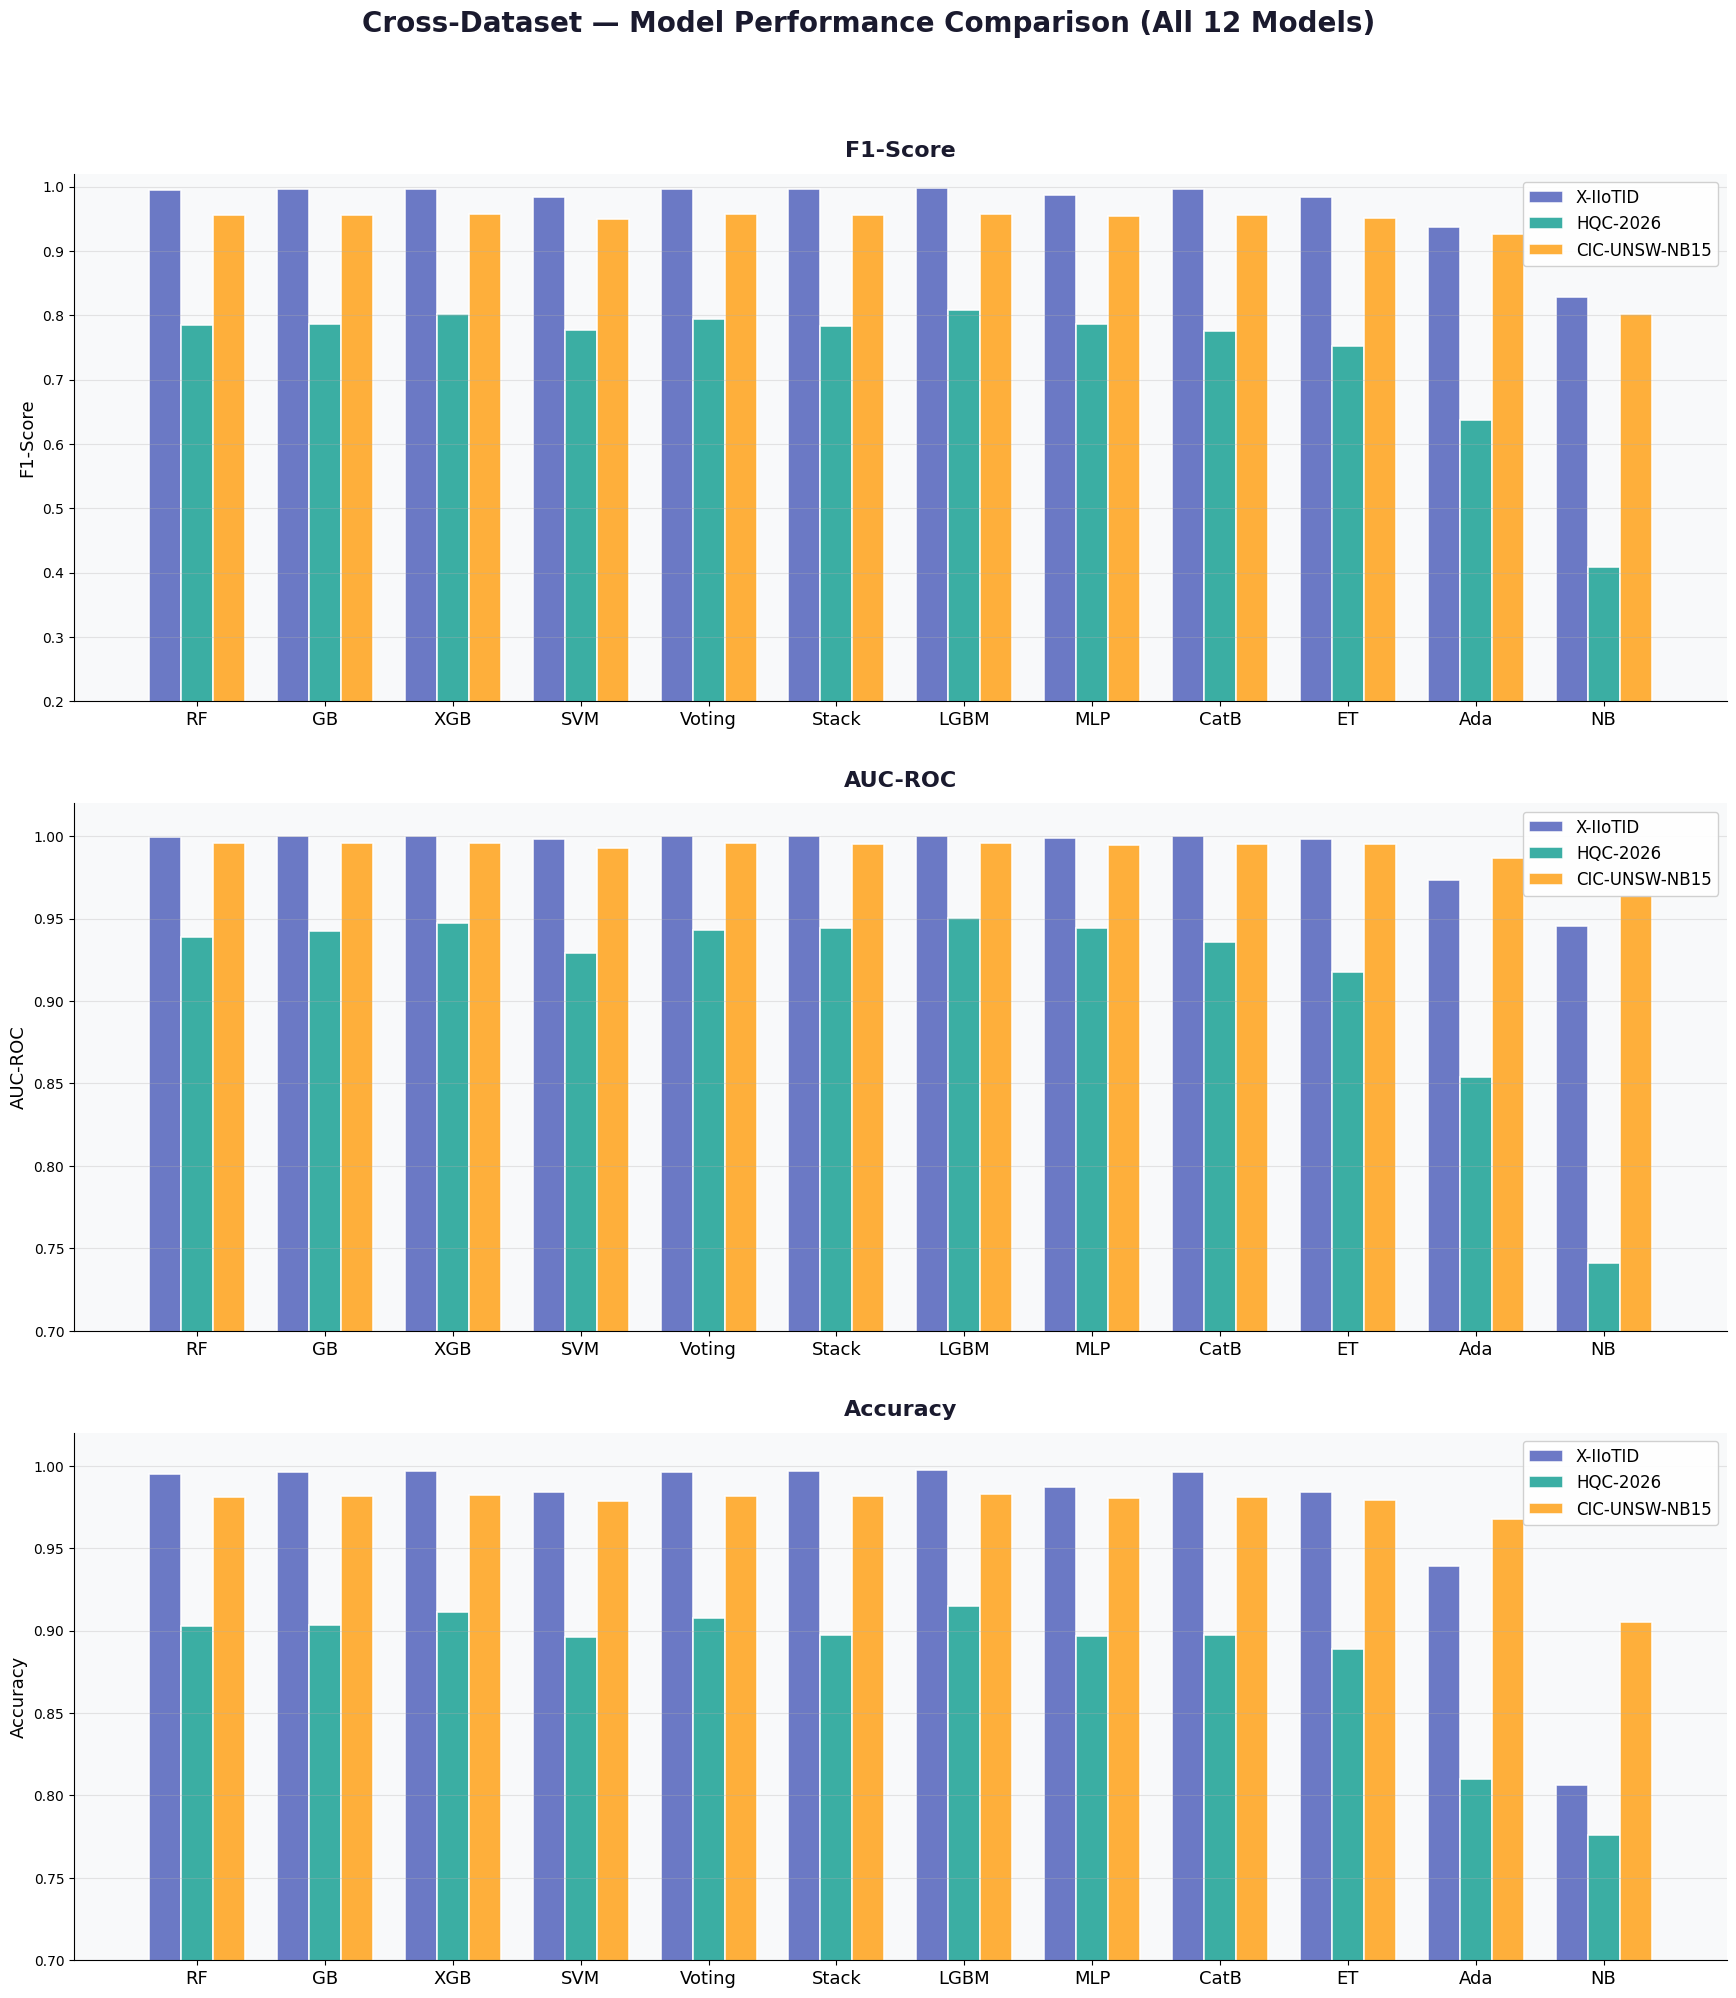

Saved: cross_model_comparison.png


In [ ]:
#  CELL 31 — Cross-Dataset: Model Performance Comparison

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

model_names = list(xiiot["ml_results"].keys())
datasets    = list(all_results.keys())
ds_colors   = {
    "X-IIoTID"      : "#5C6BC0",  # Indigo
    "HQC-2026"      : "#26A69A",  # Teal
    "CIC-UNSW-NB15" : "#FFA726",  # Amber
}

f1_data  = {ds: [all_results[ds]["ml_results"][m]["f1"]       for m in model_names] for ds in datasets}
auc_data = {ds: [all_results[ds]["ml_results"][m]["auc"]      for m in model_names] for ds in datasets}
acc_data = {ds: [all_results[ds]["ml_results"][m]["accuracy"] for m in model_names] for ds in datasets}

short_names = ["RF", "GB", "XGB", "SVM", "Voting", "Stack",
               "LGBM", "MLP", "CatB", "ET", "Ada", "NB"]

x     = np.arange(len(model_names))
width = 0.25

fig, axes = plt.subplots(3, 1, figsize=(18, 20), facecolor='white')
fig.suptitle('Cross-Dataset — Model Performance Comparison (All 12 Models)',
             fontsize=20, fontweight='bold', color='#1a1a2e', y=1.01)

metrics = [
    (f1_data,  'F1-Score',  (0.20, 1.02)),
    (auc_data, 'AUC-ROC',   (0.70, 1.02)),
    (acc_data, 'Accuracy',  (0.70, 1.02)),
]

for ax, (data, label, ylim) in zip(axes, metrics):
    ax.set_facecolor('#F8F9FA')
    for i, (ds, color) in enumerate(ds_colors.items()):
        bars = ax.bar(x + i * width, data[ds],
                      width=width, label=ds,
                      color=color, edgecolor='white',
                      linewidth=1.2, alpha=0.9)
    ax.set_title(label, fontsize=16, fontweight='bold',
                 color='#1a1a2e', pad=12)
    ax.set_ylabel(label, fontsize=13)
    ax.set_xticks(x + width)
    ax.set_xticklabels(short_names, fontsize=13)
    ax.set_ylim(ylim)
    ax.legend(fontsize=12, framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout(pad=3.0)
plt.savefig('cross_model_comparison.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_model_comparison.png")

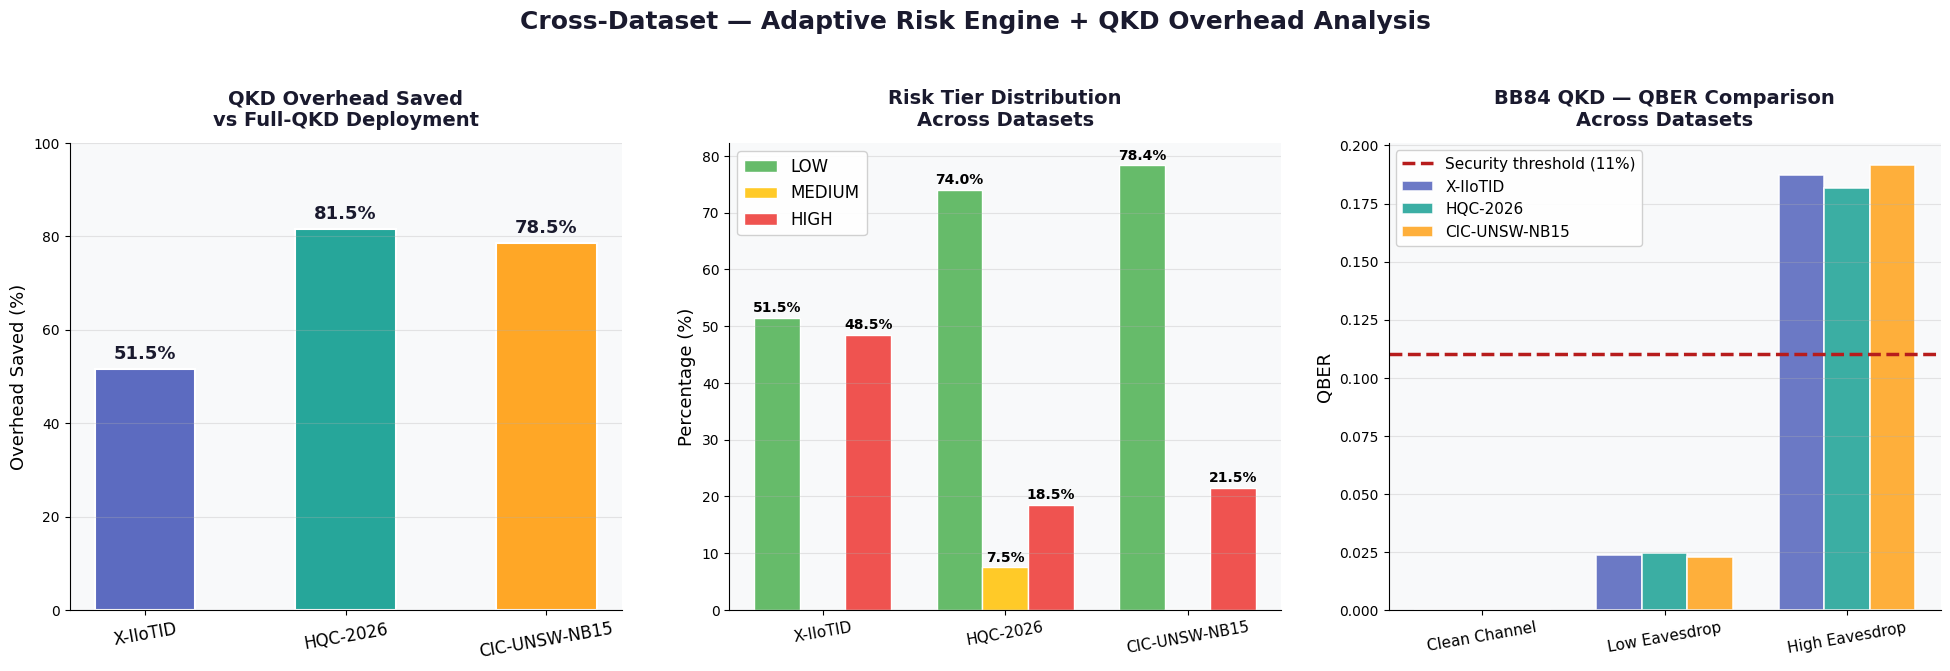

Saved: cross_qkd_overhead.png


In [ ]:
#  CELL 32 — Cross-Dataset: QKD Overhead + Risk Engine Comparison

fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
fig.suptitle('Cross-Dataset — Adaptive Risk Engine + QKD Overhead Analysis',
             fontsize=18, fontweight='bold', color='#1a1a2e')

ds_colors = {
    "X-IIoTID"      : "#5C6BC0",
    "HQC-2026"      : "#26A69A",
    "CIC-UNSW-NB15" : "#FFA726",
}
datasets = list(all_results.keys())

# ── Plot 1: Overhead Saved ────────────────────────────────
ax1 = axes[0]
ax1.set_facecolor('#F8F9FA')
overhead = [all_results[ds]["risk_engine"]["overhead_saved"] for ds in datasets]
bars = ax1.bar(datasets, overhead,
               color=[ds_colors[ds] for ds in datasets],
               edgecolor='white', linewidth=1.5, width=0.5)
ax1.set_title('QKD Overhead Saved\nvs Full-QKD Deployment',
              fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax1.set_ylabel('Overhead Saved (%)', fontsize=13)
ax1.set_ylim(0, 100)
ax1.tick_params(axis='x', labelsize=12, rotation=10)
ax1.grid(axis='y', alpha=0.3)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
for bar, val in zip(bars, overhead):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 1.5,
             f'{val:.1f}%', ha='center', va='bottom',
             fontsize=13, fontweight='bold', color='#1a1a2e')

# ── Plot 2: Risk Tier Distribution ────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#F8F9FA')
x      = np.arange(len(datasets))
width  = 0.25
low_p  = [all_results[ds]["risk_engine"]["n_low"]    /
          all_results[ds]["risk_engine"]["n_total"] * 100 for ds in datasets]
med_p  = [all_results[ds]["risk_engine"]["n_medium"] /
          all_results[ds]["risk_engine"]["n_total"] * 100 for ds in datasets]
high_p = [all_results[ds]["risk_engine"]["n_high"]   /
          all_results[ds]["risk_engine"]["n_total"] * 100 for ds in datasets]

b1 = ax2.bar(x - width, low_p,  width, label='LOW',    color='#66BB6A', edgecolor='white')
b2 = ax2.bar(x,         med_p,  width, label='MEDIUM', color='#FFCA28', edgecolor='white')
b3 = ax2.bar(x + width, high_p, width, label='HIGH',   color='#EF5350', edgecolor='white')

ax2.set_title('Risk Tier Distribution\nAcross Datasets',
              fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax2.set_ylabel('Percentage (%)', fontsize=13)
ax2.set_xticks(x)
ax2.set_xticklabels(datasets, fontsize=11, rotation=10)
ax2.legend(fontsize=12, framealpha=0.9)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
for bars_group, vals in [(b1, low_p), (b2, med_p), (b3, high_p)]:
    for bar, val in zip(bars_group, vals):
        if val > 1:
            ax2.text(bar.get_x() + bar.get_width()/2, val + 0.5,
                     f'{val:.1f}%', ha='center', va='bottom',
                     fontsize=10, fontweight='bold')

# ── Plot 3: BB84 QBER Comparison ─────────────────────────
ax3 = axes[2]
ax3.set_facecolor('#F8F9FA')
scenarios = ["Clean Channel", "Low Eavesdrop", "High Eavesdrop"]
x2    = np.arange(len(scenarios))
width = 0.25

for i, (ds, color) in enumerate(ds_colors.items()):
    qber_vals = [all_results[ds]["qkd_results"][s]["qber_mean"] for s in scenarios]
    ax3.bar(x2 + i * width, qber_vals, width,
            label=ds, color=color,
            edgecolor='white', linewidth=1.2, alpha=0.9)

ax3.axhline(0.11, color='#B71C1C', linestyle='--',
            lw=2.5, label='Security threshold (11%)')
ax3.set_title('BB84 QKD — QBER Comparison\nAcross Datasets',
              fontsize=14, fontweight='bold', color='#1a1a2e', pad=12)
ax3.set_ylabel('QBER', fontsize=13)
ax3.set_xticks(x2 + width)
ax3.set_xticklabels(scenarios, fontsize=11, rotation=10)
ax3.legend(fontsize=11, framealpha=0.9)
ax3.grid(axis='y', alpha=0.3)
ax3.spines['top'].set_visible(False)
ax3.spines['right'].set_visible(False)

plt.tight_layout(pad=2.5)
plt.savefig('cross_qkd_overhead.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_qkd_overhead.png")

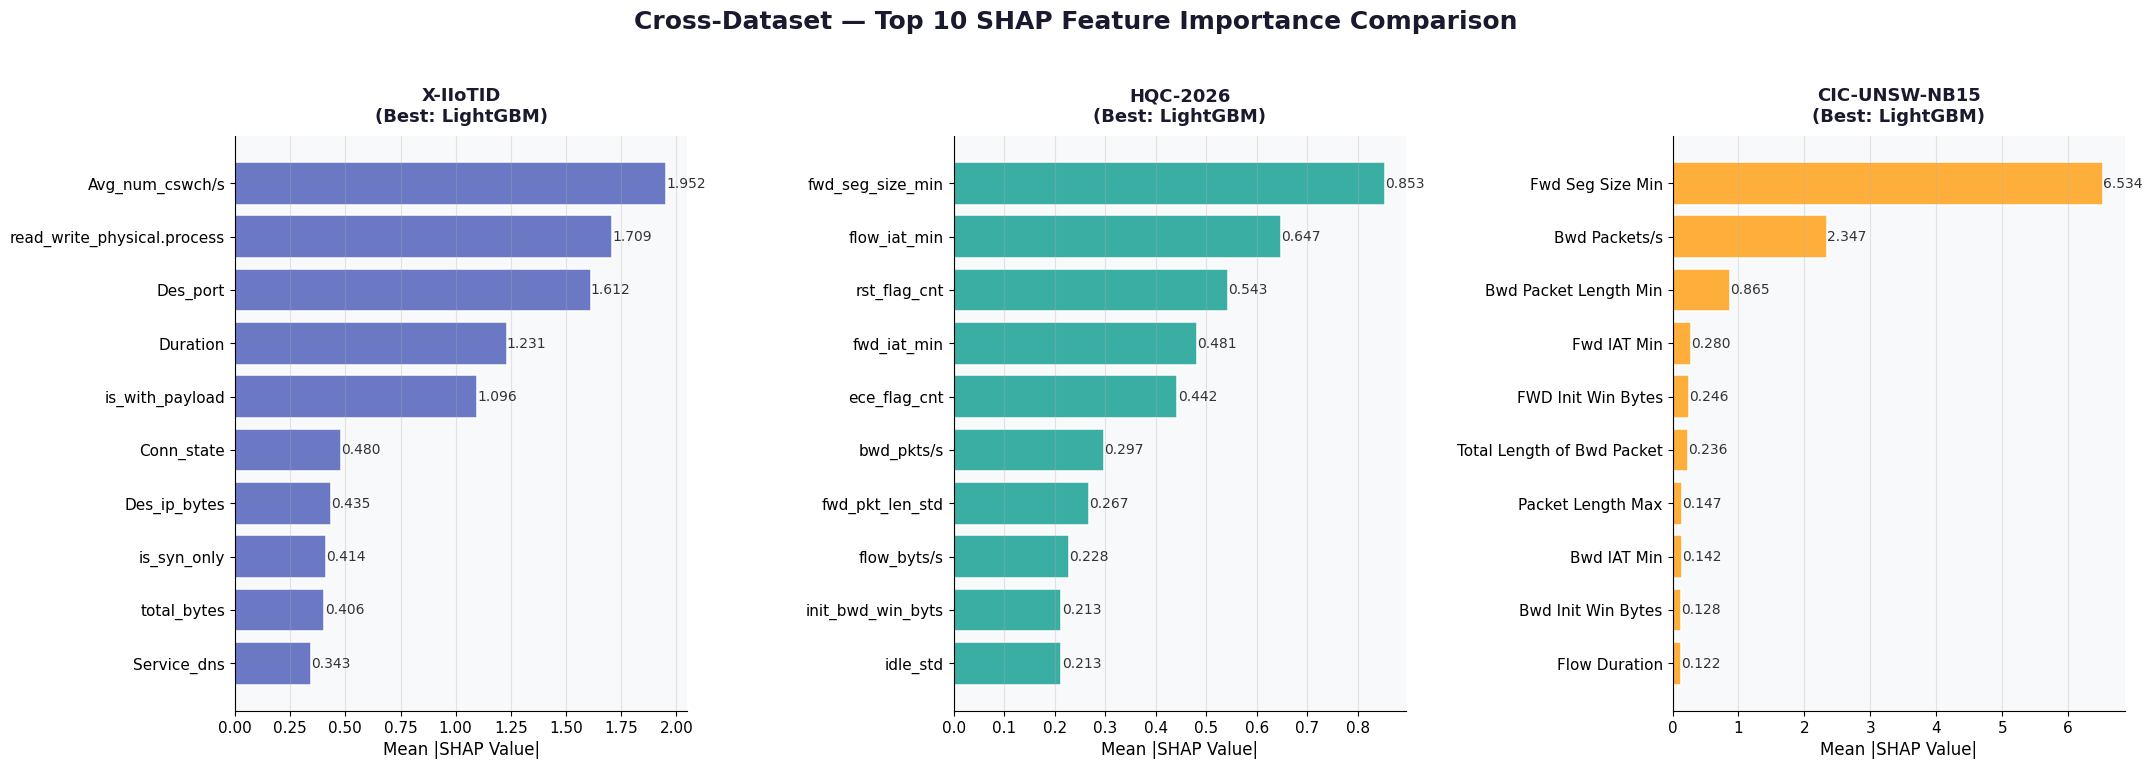

Saved: cross_shap_comparison.png


In [ ]:
#  CELL 33 — Cross-Dataset: SHAP Feature Importance Comparison

fig, axes = plt.subplots(1, 3, figsize=(22, 8), facecolor='white')
fig.suptitle('Cross-Dataset — Top 10 SHAP Feature Importance Comparison',
             fontsize=18, fontweight='bold', color='#1a1a2e')

ds_colors = {
    "X-IIoTID"      : "#5C6BC0",
    "HQC-2026"      : "#26A69A",
    "CIC-UNSW-NB15" : "#FFA726",
}

for ax, (ds_name, color) in zip(axes, ds_colors.items()):
    ax.set_facecolor('#F8F9FA')
    shap_raw = all_results[ds_name]["shap_top10"]

    # Handle different formats
    if "Feature" in shap_raw:
        # Nested DataFrame.to_dict() format (if ever used)
        feat_dict  = shap_raw["Feature"]
        val_dict   = shap_raw["SHAP_Value"]
        items = [(feat_dict[k], float(val_dict[k]))
                 for k in feat_dict.keys()]
    else:
        # Series.to_dict() format — used by all 3 datasets currently
        items = [(k, float(v)) for k, v in shap_raw.items()]

    # Sort descending, top 10
    items    = sorted(items, key=lambda x: x[1], reverse=True)[:10]
    features = [i[0] for i in items]
    values   = [i[1] for i in items]

    bars = ax.barh(features[::-1], values[::-1],
                   color=color, edgecolor='white',
                   linewidth=1.2, alpha=0.9)

    ax.set_title(f'{ds_name}\n(Best: {all_results[ds_name]["best_model"]})',
                 fontsize=13, fontweight='bold', color='#1a1a2e', pad=10)
    ax.set_xlabel('Mean |SHAP Value|', fontsize=12)
    ax.tick_params(labelsize=11)
    ax.grid(axis='x', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    for bar, val in zip(bars, values[::-1]):
        ax.text(val + 0.001, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=10, color='#333333')

plt.tight_layout(pad=2.5)
plt.savefig('cross_shap_comparison.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_shap_comparison.png")

In [ ]:
#  CELL 34 — Cross-Dataset: Final Summary Table

print("=" * 80)
print("FINAL SUMMARY — Adaptive Hybrid Network Security Framework (ML-QKD)")
print("=" * 80)

print(f"\n{'Dataset':<20} {'Country':<12} {'Year':<6} {'Best Model':<20} "
      f"{'F1':>7} {'AUC':>7} {'Acc':>7} {'Overhead':>10}")
print("-" * 95)

years = {"X-IIoTID": "2021", "HQC-2026": "2026", "CIC-UNSW-NB15": "2024"}
for ds_name, ds in all_results.items():
    best_m   = ds["best_model"]
    best_acc = ds["ml_results"][best_m]["accuracy"]
    print(f"{ds_name:<20} {ds['country']:<12} {years[ds_name]:<6} "
          f"{best_m:<20} {ds['best_f1']:>7.4f} {ds['best_auc']:>7.4f} "
          f"{best_acc:>7.4f} {ds['risk_engine']['overhead_saved']:>9.1f}%")

print("\n" + "=" * 80)
print("QKD SIMULATION RESULTS (BB84)")
print("=" * 80)
print(f"\n{'Dataset':<20} {'Clean QBER':>12} {'Low Eve QBER':>14} "
      f"{'High Eve QBER':>15} {'Secure?':>10}")
print("-" * 75)
for ds_name, ds in all_results.items():
    qkd = ds["qkd_results"]
    print(f"{ds_name:<20} "
          f"{qkd['Clean Channel']['qber_mean']:>12.4f} "
          f"{qkd['Low Eavesdrop']['qber_mean']:>14.4f} "
          f"{qkd['High Eavesdrop']['qber_mean']:>15.4f} "
          f"{'✓ Detected':>10}")

print("\n" + "=" * 80)
print("RISK ENGINE SUMMARY")
print("=" * 80)
print(f"\n{'Dataset':<20} {'Total Flows':>12} {'LOW %':>8} "
      f"{'MEDIUM %':>10} {'HIGH %':>8} {'Overhead Saved':>15}")
print("-" * 80)
for ds_name, ds in all_results.items():
    re     = ds["risk_engine"]
    total  = re["n_total"]
    low_p  = re["n_low"]    / total * 100
    med_p  = re["n_medium"] / total * 100
    high_p = re["n_high"]   / total * 100
    print(f"{ds_name:<20} {total:>12,} {low_p:>8.1f}% "
          f"{med_p:>9.1f}% {high_p:>7.1f}% "
          f"{re['overhead_saved']:>14.1f}%")

print("\n" + "=" * 80)
print("All Cross-Dataset Analysis Complete!")
print("Saved files: cross_model_comparison.png, cross_qkd_overhead.png,")
print("             cross_shap_comparison.png")
print("=" * 80)

FINAL SUMMARY — Adaptive Hybrid Network Security Framework (ML-QKD)

Dataset              Country      Year   Best Model                F1     AUC     Acc   Overhead
-----------------------------------------------------------------------------------------------
X-IIoTID             Australia    2021   LightGBM              0.9972  0.9999  0.9973      51.5%
HQC-2026             Bangladesh   2026   LightGBM              0.8082  0.9506  0.9147      81.5%
CIC-UNSW-NB15        Canada       2024   LightGBM              0.9580  0.9960  0.9826      78.5%

QKD SIMULATION RESULTS (BB84)

Dataset                Clean QBER   Low Eve QBER   High Eve QBER    Secure?
---------------------------------------------------------------------------
X-IIoTID                   0.0000         0.0236          0.1872 ✓ Detected
HQC-2026                   0.0000         0.0246          0.1818 ✓ Detected
CIC-UNSW-NB15              0.0000         0.0227          0.1916 ✓ Detected

RISK ENGINE SUMMARY

Dataset      

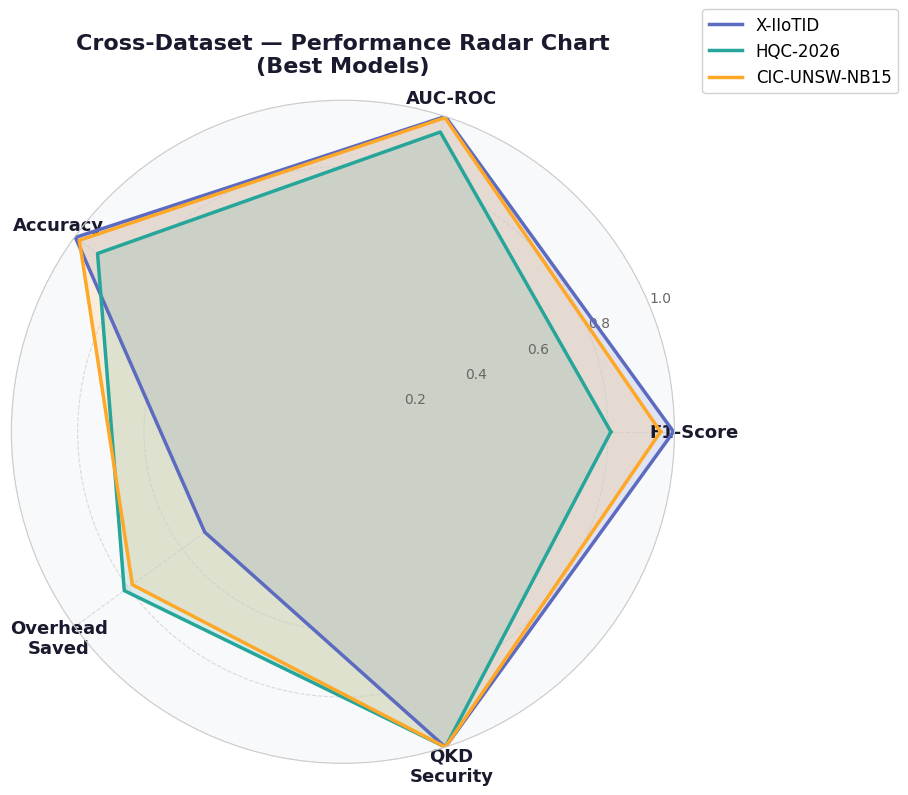

Saved: cross_radar_chart.png


In [ ]:
#  CELL 35 — Cross-Dataset: Radar Chart (Best Models)

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

# Metrics for each dataset (best model)
metrics     = ['F1-Score', 'AUC-ROC', 'Accuracy', 'Overhead\nSaved', 'QKD\nSecurity']
n_metrics   = len(metrics)

ds_colors = {
    "X-IIoTID"      : "#5C6BC0",
    "HQC-2026"      : "#26A69A",
    "CIC-UNSW-NB15" : "#FFA726",
}

# Dynamically pull actual values from all_results (no hardcoding)
values = {}
for ds_name, ds in all_results.items():
    best_m       = ds["best_model"]
    f1_val       = ds["best_f1"]
    auc_val      = ds["best_auc"]
    acc_val      = ds["ml_results"][best_m]["accuracy"]
    overhead_val = ds["risk_engine"]["overhead_saved"] / 100  # normalize to 0-1
    # QKD security: 1.0 if high-eavesdrop QBER correctly exceeds the 11% threshold
    # (i.e. eavesdropping was successfully detected in every dataset's simulation)
    qkd_secure = 1.0 if ds["qkd_results"]["High Eavesdrop"]["qber_mean"] > 0.11 else 0.0
    values[ds_name] = [f1_val, auc_val, acc_val, overhead_val, qkd_secure]

angles = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 8),
                        subplot_kw=dict(polar=True),
                        facecolor='white')
ax.set_facecolor('#F8F9FA')

for ds_name, color in ds_colors.items():
    vals = values[ds_name] + values[ds_name][:1]
    ax.plot(angles, vals, color=color, linewidth=2.5,
            linestyle='solid', label=ds_name)
    ax.fill(angles, vals, color=color, alpha=0.15)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metrics, fontsize=13, fontweight='bold', color='#1a1a2e')
ax.set_ylim(0, 1)
ax.set_yticks([0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_yticklabels(['0.2', '0.4', '0.6', '0.8', '1.0'],
                    fontsize=10, color='#666666')
ax.grid(color='#cccccc', linestyle='--', linewidth=0.8, alpha=0.7)
ax.spines['polar'].set_color('#cccccc')

ax.set_title('Cross-Dataset — Performance Radar Chart\n(Best Models)',
             fontsize=16, fontweight='bold', color='#1a1a2e',
             pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15),
          fontsize=12, framealpha=0.9)

plt.tight_layout()
plt.savefig('cross_radar_chart.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_radar_chart.png")

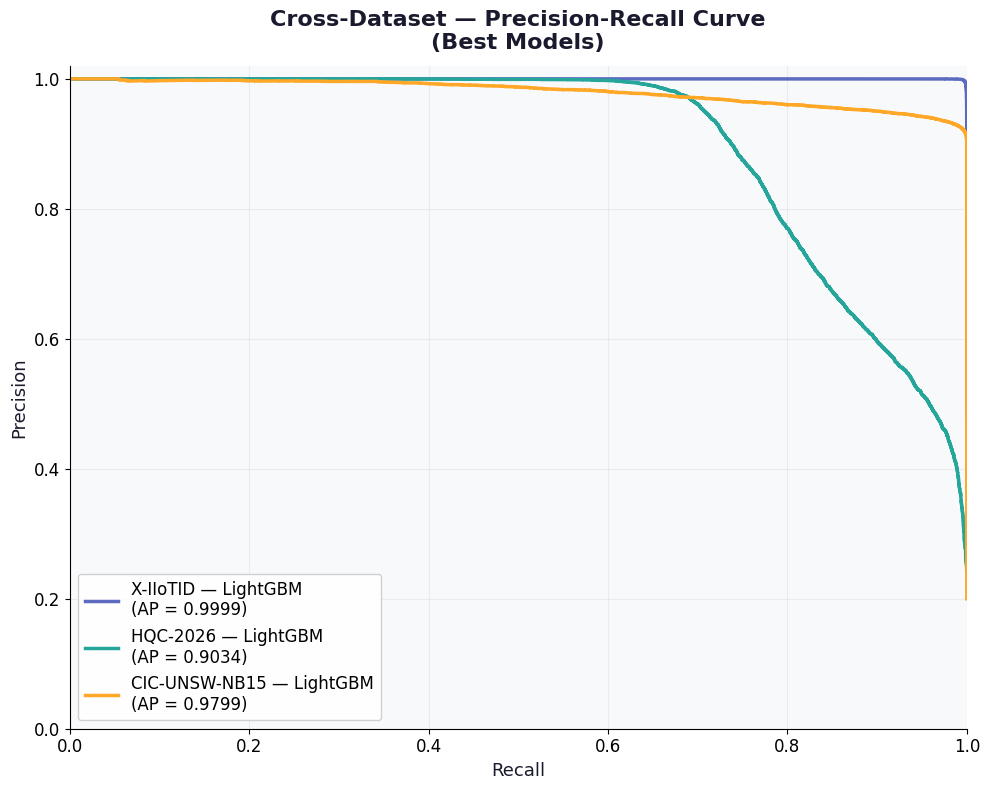

Saved: cross_precision_recall.png


In [ ]:
#  CELL 36 — Cross-Dataset: Precision-Recall Curve (Best Models)

from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(10, 8), facecolor='white')
ax.set_facecolor('#F8F9FA')

ds_colors = {
    "X-IIoTID"      : "#5C6BC0",
    "HQC-2026"      : "#26A69A",
    "CIC-UNSW-NB15" : "#FFA726",
}

for ds_name, color in ds_colors.items():
    best_m   = all_results[ds_name]["best_model"]
    y_test   = all_results[ds_name]["y_test"]
    y_prob   = all_results[ds_name]["ml_results"][best_m]["y_prob"]

    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)

    ax.plot(recall, precision, color=color, linewidth=2.5,
            label=f'{ds_name} — {best_m}\n(AP = {ap:.4f})')

ax.set_xlabel('Recall', fontsize=13, color='#1a1a2e')
ax.set_ylabel('Precision', fontsize=13, color='#1a1a2e')
ax.set_title('Cross-Dataset — Precision-Recall Curve\n(Best Models)',
             fontsize=16, fontweight='bold', color='#1a1a2e', pad=12)
ax.legend(loc='lower left', fontsize=12, framealpha=0.9)
ax.tick_params(labelsize=12)
ax.grid(alpha=0.3, color='#cccccc')
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('cross_precision_recall.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_precision_recall.png")

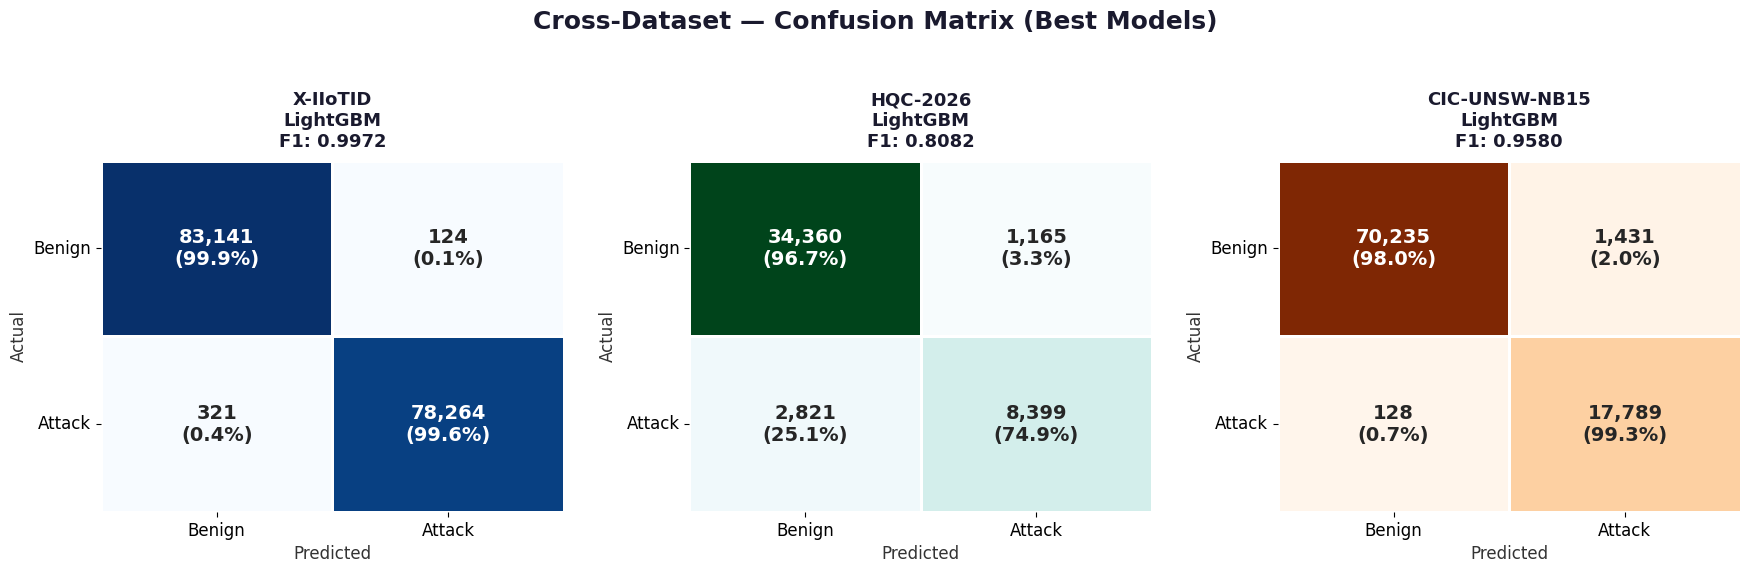

Saved: cross_confusion_matrix.png


In [ ]:
#  CELL 37 — Cross-Dataset: Best Models Confusion Matrix

from sklearn.metrics import confusion_matrix
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor='white')
fig.suptitle('Cross-Dataset — Confusion Matrix (Best Models)',
             fontsize=18, fontweight='bold', color='#1a1a2e')

ds_cmaps = {
    "X-IIoTID"      : "Blues",
    "HQC-2026"      : "BuGn",
    "CIC-UNSW-NB15" : "Oranges",
}

for ax, (ds_name, cmap) in zip(axes, ds_cmaps.items()):
    best_m = all_results[ds_name]["best_model"]
    y_test = all_results[ds_name]["y_test"]
    y_pred = all_results[ds_name]["ml_results"][best_m]["y_pred"]

    cm = confusion_matrix(y_test, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1)[:, np.newaxis] * 100

    # Annotate with count + percentage
    annot = np.array([[f"{cm[i,j]:,}\n({cm_pct[i,j]:.1f}%)"
                       for j in range(2)] for i in range(2)])

    sns.heatmap(cm, annot=annot, fmt='', ax=ax,
                cmap=cmap, cbar=False,
                linewidths=2, linecolor='white',
                annot_kws={"size": 14, "weight": "bold"})

    ax.set_title(f'{ds_name}\n{best_m}\nF1: {all_results[ds_name]["best_f1"]:.4f}',
                 fontsize=13, fontweight='bold', color='#1a1a2e', pad=10)
    ax.set_xlabel('Predicted', fontsize=12, color='#333333')
    ax.set_ylabel('Actual', fontsize=12, color='#333333')
    ax.set_xticklabels(['Benign', 'Attack'], fontsize=12)
    ax.set_yticklabels(['Benign', 'Attack'], fontsize=12, rotation=0)

plt.tight_layout(pad=2.5)
plt.savefig('cross_confusion_matrix.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_confusion_matrix.png")

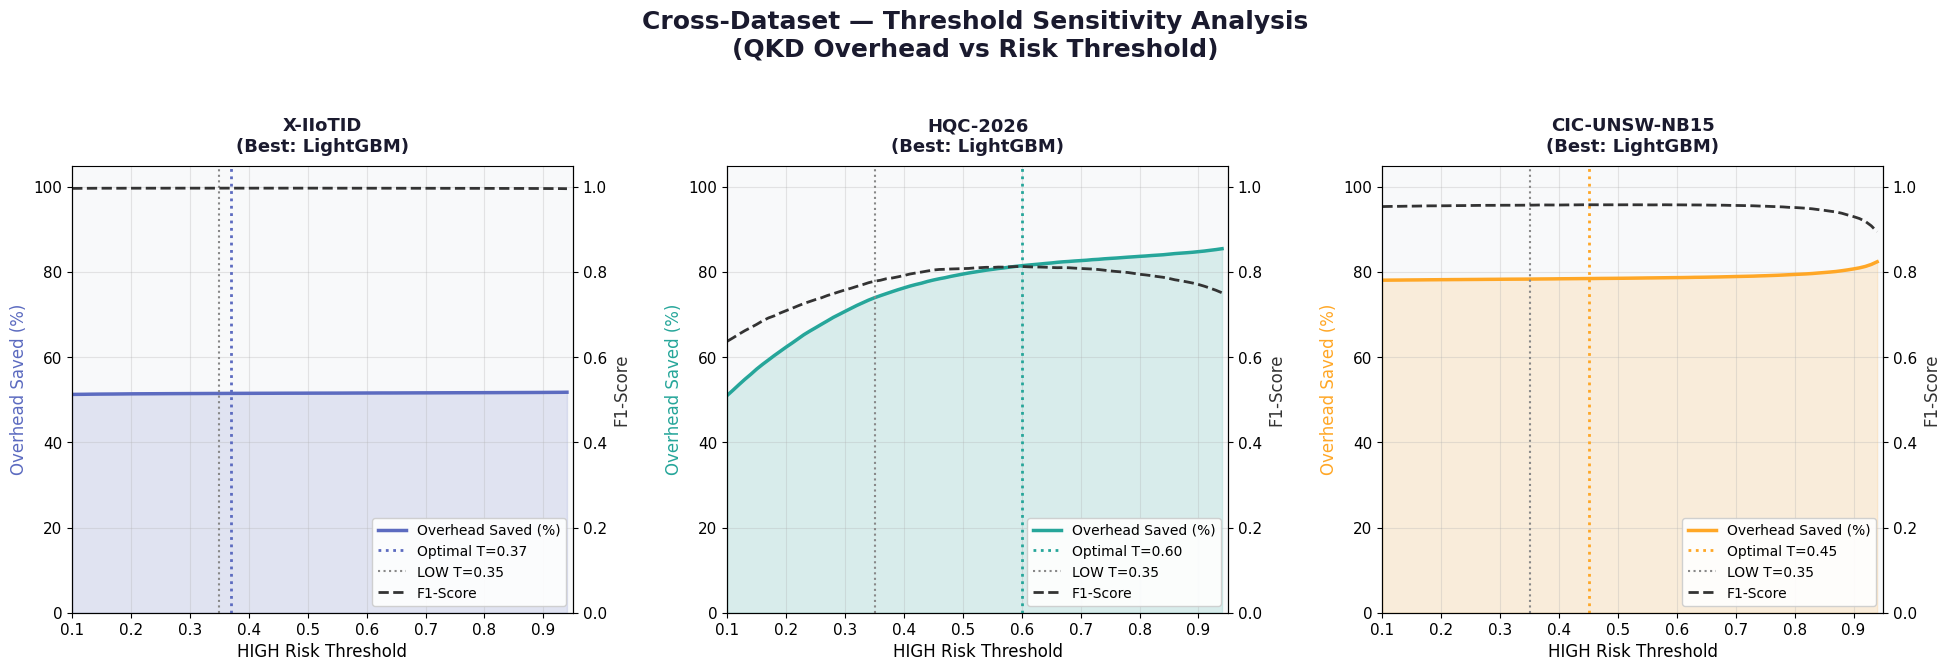

Saved: cross_threshold_sensitivity.png


In [ ]:
#  CELL 38 — Cross-Dataset: Threshold Sensitivity Analysis

fig, axes = plt.subplots(1, 3, figsize=(20, 7), facecolor='white')
fig.suptitle('Cross-Dataset — Threshold Sensitivity Analysis\n(QKD Overhead vs Risk Threshold)',
             fontsize=18, fontweight='bold', color='#1a1a2e')

ds_colors = {
    "X-IIoTID"      : "#5C6BC0",
    "HQC-2026"      : "#26A69A",
    "CIC-UNSW-NB15" : "#FFA726",
}

thresholds = np.arange(0.10, 0.95, 0.01)

for ax, (ds_name, color) in zip(axes, ds_colors.items()):
    ax.set_facecolor('#F8F9FA')

    best_m = all_results[ds_name]["best_model"]
    y_prob = all_results[ds_name]["ml_results"][best_m]["y_prob"]
    y_test = all_results[ds_name]["y_test"]
    total  = len(y_prob)

    overhead_saved = []
    f1_scores      = []
    high_pct       = []

    for t in thresholds:
        n_high = (y_prob >= t).sum()
        overhead_saved.append((1 - n_high / total) * 100)
        high_pct.append(n_high / total * 100)
        y_pred_t = (y_prob >= t).astype(int)
        from sklearn.metrics import f1_score as f1s
        f1_scores.append(f1s(y_test, y_pred_t))

    # Plot overhead saved
    ax2 = ax.twinx()
    ax.plot(thresholds, overhead_saved, color=color,
            linewidth=2.5, label='Overhead Saved (%)')
    ax.fill_between(thresholds, overhead_saved,
                    alpha=0.15, color=color)
    ax2.plot(thresholds, f1_scores, color='#333333',
             linewidth=2.0, linestyle='--', label='F1-Score')

    # Mark optimal threshold
    opt_t = all_results[ds_name]["optimal_threshold"]
    ax.axvline(opt_t, color=color, linestyle=':',
               linewidth=2.0, label=f'Optimal T={opt_t:.2f}')
    ax.axvline(0.35, color='#888888', linestyle=':',
               linewidth=1.5, label='LOW T=0.35')

    ax.set_title(f'{ds_name}\n(Best: {best_m})',
                 fontsize=13, fontweight='bold', color='#1a1a2e', pad=10)
    ax.set_xlabel('HIGH Risk Threshold', fontsize=12)
    ax.set_ylabel('Overhead Saved (%)', fontsize=12, color=color)
    ax2.set_ylabel('F1-Score', fontsize=12, color='#333333')
    ax.set_xlim(0.10, 0.95)
    ax.set_ylim(0, 105)
    ax2.set_ylim(0, 1.05)
    ax.tick_params(labelsize=11)
    ax2.tick_params(labelsize=11)
    ax.grid(alpha=0.3)
    ax.spines['top'].set_visible(False)

    # Combined legend
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2,
              fontsize=10, framealpha=0.9, loc='lower right')

plt.tight_layout(pad=2.5)
plt.savefig('cross_threshold_sensitivity.png', dpi=180,
            bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: cross_threshold_sensitivity.png")

# Dashboard

In [ ]:
########################################################################
# RUN THIS RIGHT NOW, IN THE SAME COLAB SESSION (before it disconnects)
# Paste as a NEW cell anywhere at the end of the notebook and run it.
# It zips up every chart PNG your notebook already saved locally
# (in /content/) and copies the zip to Google Drive so you can download
# it — these files exist only in the temporary Colab runtime and will
# be LOST if the runtime disconnects before you run this.
########################################################################

import zipfile, os, glob

chart_files = [
    # X-IIoTID
    "xiiot_eda.png", "xiiot_model_comparison.png", "xiiot_confusion_matrices.png",
    "xiiot_roc_curves.png", "xiiot_feature_importance.png", "xiiot_risk_qkd.png",
    "xiiot_shap_dot.png", "xiiot_shap_bar.png", "xiiot_response_recommendation.png",
    "xiiot_detection_routing_pipeline.png", "xiiot_bb84_pipeline.png",
    # HQC-2026
    "hqc2026_eda.png", "hqc2026_model_comparison.png", "hqc2026_confusion_matrices.png",
    "hqc2026_roc_curves.png", "hqc2026_feature_importance.png", "hqc2026_risk_qkd.png",
    "hqc2026_shap_summary.png", "hqc2026_shap_importance.png", "hqc2026_response_recommendation.png",
    "hqc2026_detection_routing_pipeline.png", "hqc2026_bb84_pipeline.png",
    # CIC-UNSW-NB15
    "cicunsw_eda.png", "cicunsw_model_comparison.png", "cicunsw_confusion_matrices.png",
    "cicunsw_roc_curves.png", "cicunsw_feature_importance.png", "cicunsw_risk_bb84.png",
    "cicunsw_shap_dot.png", "cicunsw_shap_bar.png", "cicunsw_response_recommendation.png",
    "cicunsw_detection_routing_pipeline.png", "cicunsw_bb84_pipeline.png",
    "cicunsw_bb84_protocol_pipeline.png",
    # Cross-Dataset Comparison (cells 68-76 — dataset-independent, run once at the end)
    "cross_model_comparison.png", "cross_qkd_overhead.png", "cross_shap_comparison.png",
    "cross_radar_chart.png", "cross_precision_recall.png", "cross_confusion_matrix.png",
    "cross_threshold_sensitivity.png",
]

zip_path = "/content/drive/MyDrive/datasets/capstoneC_charts.zip"
found, missing = [], []

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for fname in chart_files:
        if os.path.exists(fname):
            zf.write(fname)
            found.append(fname)
        else:
            missing.append(fname)

print(f"Zipped {len(found)} / {len(chart_files)} chart files -> {zip_path}")
if missing:
    print("\nMissing (not found in /content/, likely because that dataset's")
    print("visualization cell wasn't run in THIS session):")
    for m in missing:
        print(" -", m)
print(f"\nZip size: {os.path.getsize(zip_path) / 1024:.1f} KB")

Zipped 41 / 41 chart files -> /content/drive/MyDrive/datasets/capstoneC_charts.zip

Zip size: 7577.0 KB
